In [2]:
!pip install pandas numpy scikit-learn matplotlib xgboost causal-learn networkx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 47.3 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 50.1 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 46.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 50.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.9/94.9 MB 56.0 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 62.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 42.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 76.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 50.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.7/35.7 MB 60.6 MB/s  0:00:006m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.9/295.9 MB 56.4 MB/s  0:00:04m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 54.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [3]:
import pandas as pd
import numpy as np
import itertools
from itertools import combinations
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from xgboost import XGBClassifier
from causallearn.search.ConstraintBased.PC import pc
import networkx as nx

In [4]:
try:
    df = pd.read_csv("Crop_recommendation.csv")
except FileNotFoundError:
    print("Please ensure 'Crop_recommendation.csv' is in the correct directory.")
    # As a fallback for demonstration, create a dummy dataframe
    data = {'N': np.random.rand(100), 'P': np.random.rand(100), 'K': np.random.rand(100),
            'temperature': np.random.rand(100), 'humidity': np.random.rand(100),
            'ph': np.random.rand(100), 'rainfall': np.random.rand(100),
            'label': np.random.randint(0, 5, 100)}
    df = pd.DataFrame(data)
    print("Using dummy data for demonstration.")


le = LabelEncoder()
df['label'] = le.fit_transform(df['label'])
X = df.drop('label', axis=1)
y = df['label']
feature_names = X.columns.tolist()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_train_df = pd.DataFrame(X_scaled, columns=feature_names)
y_train_series = y

In [6]:
import math
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
n_features = X.shape[1]
all_indices = list(range(n_features))
f1_values = {}

print("Calculating F1 scores for all feature subsets (for original Shapley)...")
for r in range(1, n_features + 1):
    for combo_indices in combinations(all_indices, r):
        combo_names = [feature_names[i] for i in combo_indices]
        subset_fs = frozenset(combo_names)
        X_train_subset = X_train[:, combo_indices]
        X_test_subset = X_test[:, combo_indices]
        model = XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', verbosity=0)
        model.fit(X_train_subset, y_train)
        y_pred = model.predict(X_test_subset)
        score = f1_score(y_test, y_pred, average='macro')
        f1_values[subset_fs] = score
f1_values[frozenset()] = 0.0

shapley_values = {feature: 0.0 for feature in feature_names}
n = len(feature_names)
for feature in feature_names:
    shapley_sum = 0.0
    others = [f for f in feature_names if f != feature]
    for r in range(n):
        for subset in itertools.combinations(others, r):
            subset_fs = frozenset(subset)
            subset_with_feature = subset_fs | {feature}
            f1_without = f1_values.get(subset_fs, 0.0)
            f1_with = f1_values.get(subset_with_feature, 0.0)
            marginal_contribution = f1_with - f1_without
            weight = (math.factorial(len(subset)) * math.factorial(n - len(subset) - 1)) / math.factorial(n)
            shapley_sum += weight * marginal_contribution
    shapley_values[feature] = shapley_sum

shapley_df = pd.DataFrame(list(shapley_values.items()), columns=["Feature", "Shapley Value"])

Calculating F1 scores for all feature subsets (for original Shapley)...


       Feature  Shapley Value
0            N       0.099623
1            P       0.126009
2            K       0.158580
3  temperature       0.111612
4     humidity       0.207959
5           ph       0.076061
6     rainfall       0.206096


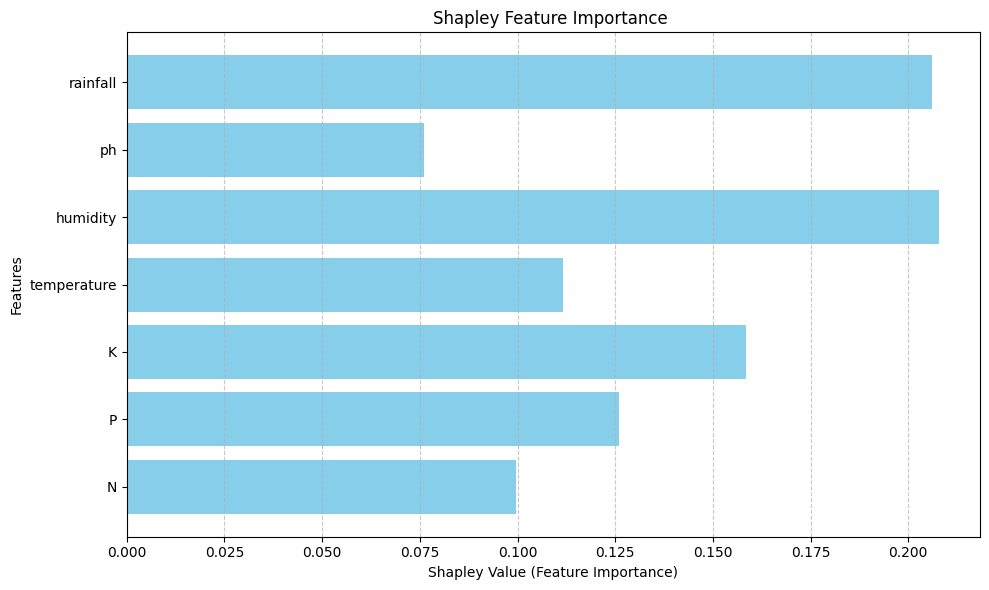

In [8]:
print(shapley_df)
plt.figure(figsize=(10, 6))
plt.barh(shapley_df["Feature"], shapley_df["Shapley Value"], color='skyblue')
plt.xlabel("Shapley Value (Feature Importance)")
plt.ylabel("Features")
plt.title("Shapley Feature Importance ")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

In [24]:
# Step 4.1: Causal Discovery using PC Algorithm
print("\nStep 1: Discovering causal graph using PC algorithm...")
data_for_causal = X_train_df.copy()
data_for_causal['label'] = y_train_series.values
causal_data_np = data_for_causal.to_numpy()
feature_names_with_label = feature_names + ['label']

cg = pc(causal_data_np, alpha=0.01)

# Step 4.1 (Revised): Manually build the named graph
print("Building named causal graph from PC algorithm output...")
adj_matrix = cg.G.graph
causal_graph_nx = nx.DiGraph()
causal_graph_nx.add_nodes_from(feature_names_with_label)
rows, cols = np.where(adj_matrix == -1)
for i, j in zip(rows, cols):
    if adj_matrix[j, i] == 1: # Indicates a directed edge i -> j
        causal_graph_nx.add_edge(feature_names_with_label[i], feature_names_with_label[j])


Step 1: Discovering causal graph using PC algorithm...


Building named causal graph from PC algorithm output...


In [25]:
# Step 4.2: Estimate Causal Strength (Edge Weights)
print("Step 2: Estimating causal strength of graph edges...")
edge_weights = {}
for u, v in causal_graph_nx.edges():
    reg = LinearRegression()
    reg.fit(data_for_causal[[u]], data_for_causal[v])
    edge_weights[(u, v)] = reg.coef_[0]

Step 2: Estimating causal strength of graph edges...


In [26]:
# Step 4.3: Calculate Total Causal Effect (W_i) on the target ('label')
print("Step 3: Calculating total causal effect of each feature on the target...")
total_causal_effects = {}
target_node = 'label'
for feature in feature_names:
    total_effect = 0
    if nx.has_path(causal_graph_nx, source=feature, target=target_node):
        for path in nx.all_simple_paths(causal_graph_nx, source=feature, target=target_node):
            path_effect = 1.0
            for i in range(len(path) - 1):
                edge = (path[i], path[i+1])
                if edge in edge_weights:
                    path_effect *= edge_weights[edge]
                else:
                    path_effect = 0; break
            total_effect += path_effect
    total_causal_effects[feature] = total_effect

# Step 4.4: Calculate Causal Weight Factor (gamma_i)
print("Step 4: Calculating causal weights...")
sum_abs_effects = sum(abs(w) for w in total_causal_effects.values())
if sum_abs_effects == 0:
    causal_weights = {f: 1.0 / len(feature_names) for f in feature_names}
else:
    causal_weights = {f: abs(w) / sum_abs_effects for f, w in total_causal_effects.items()}

Step 3: Calculating total causal effect of each feature on the target...
Step 4: Calculating causal weights...


In [27]:
# Step 4.5: Compute and Normalize Causal SHAP values
print("Step 5: Applying causal weights and normalizing SHAP values...")
original_shapley_values = shapley_df.set_index('Feature')['Shapley Value']
causal_shap_raw = original_shapley_values * pd.Series(causal_weights)
sum_abs_original_shap = np.sum(np.abs(original_shapley_values))
sum_abs_causal_shap = np.sum(np.abs(causal_shap_raw))
if sum_abs_causal_shap > 0:
    causal_shap_normalized = causal_shap_raw * (sum_abs_original_shap / sum_abs_causal_shap)
else:
    causal_shap_normalized = causal_shap_raw
causal_shap_df = causal_shap_normalized.reset_index()
causal_shap_df.columns = ['Feature', 'Causal SHAP Value']

Step 5: Applying causal weights and normalizing SHAP values...


In [28]:
print("\nOriginal Shapley Values:")
print(shapley_df.to_string())
print("\nCausal SHAP Values:")
print(causal_shap_df.to_string())


Original Shapley Values:
       Feature  Shapley Value
0            N       0.099623
1            P       0.126009
2            K       0.158580
3  temperature       0.111612
4     humidity       0.207959
5           ph       0.076061
6     rainfall       0.206096

Causal SHAP Values:
       Feature  Causal SHAP Value
0            N           0.099623
1            P           0.126009
2            K           0.158580
3  temperature           0.111612
4     humidity           0.207959
5           ph           0.076061
6     rainfall           0.206096


In [29]:
print("\nStep 1: Discovering causal graph using PC algorithm...")
data_for_causal = X_train_df.copy()
data_for_causal['label'] = y_train_series.values
causal_data_np = data_for_causal.to_numpy()
feature_names_with_label = feature_names + ['label']

cg = pc(causal_data_np, alpha=0.05)

print("Building named causal graph from PC algorithm output...")
adj_matrix = cg.G.graph
causal_graph_nx = nx.DiGraph()
causal_graph_nx.add_nodes_from(feature_names_with_label)
rows, cols = np.where(adj_matrix == -1)
for i, j in zip(rows, cols):
    if adj_matrix[j, i] == 1:
        causal_graph_nx.add_edge(feature_names_with_label[i], feature_names_with_label[j])

print("Step 2: Estimating causal strength of graph edges...")
edge_weights = {}
for u, v in causal_graph_nx.edges():
    reg = LinearRegression()
    reg.fit(data_for_causal[[u]], data_for_causal[v])
    edge_weights[(u, v)] = reg.coef_[0]

print("Step 3: Calculating total causal effect...")
total_causal_effects = {}
target_node = 'label'
for feature in feature_names:
    total_effect = 0
    if nx.has_path(causal_graph_nx, source=feature, target=target_node):
        for path in nx.all_simple_paths(causal_graph_nx, source=feature, target=target_node):
            path_effect = 1.0
            for i in range(len(path) - 1):
                edge = (path[i], path[i+1])
                if edge in edge_weights: path_effect *= edge_weights[edge]
                else: path_effect = 0; break
            total_effect += path_effect
    total_causal_effects[feature] = total_effect

print("Step 4: Calculating causal weights...")
sum_abs_effects = sum(abs(w) for w in total_causal_effects.values())
causal_weights = {f: abs(w) / sum_abs_effects if sum_abs_effects > 0 else 0 for f, w in total_causal_effects.items()}

print("Step 5: Applying causal weights and normalizing SHAP values...")
original_shapley_values = shapley_df.set_index('Feature')['Shapley Value']
causal_shap_raw = original_shapley_values * pd.Series(causal_weights)
sum_abs_original_shap = np.sum(np.abs(original_shapley_values))
sum_abs_causal_shap = np.sum(np.abs(causal_shap_raw))
causal_shap_normalized = causal_shap_raw * (sum_abs_original_shap / sum_abs_causal_shap) if sum_abs_causal_shap > 0 else causal_shap_raw
causal_shap_df = causal_shap_normalized.reset_index()
causal_shap_df.columns = ['Feature', 'Causal SHAP Value']


Step 1: Discovering causal graph using PC algorithm...


Building named causal graph from PC algorithm output...
Step 2: Estimating causal strength of graph edges...
Step 3: Calculating total causal effect...
Step 4: Calculating causal weights...
Step 5: Applying causal weights and normalizing SHAP values...



Original Shapley Values:
       Feature  Shapley Value
0            N       0.099623
1            P       0.126009
2            K       0.158580
3  temperature       0.111612
4     humidity       0.207959
5           ph       0.076061
6     rainfall       0.206096

Causal SHAP Values:
       Feature  Causal SHAP Value
0            N           0.000000
1            P           0.000000
2            K           0.000000
3  temperature           0.090254
4     humidity           0.819043
5           ph           0.000000
6     rainfall           0.076643

Generating causal graph visualization...


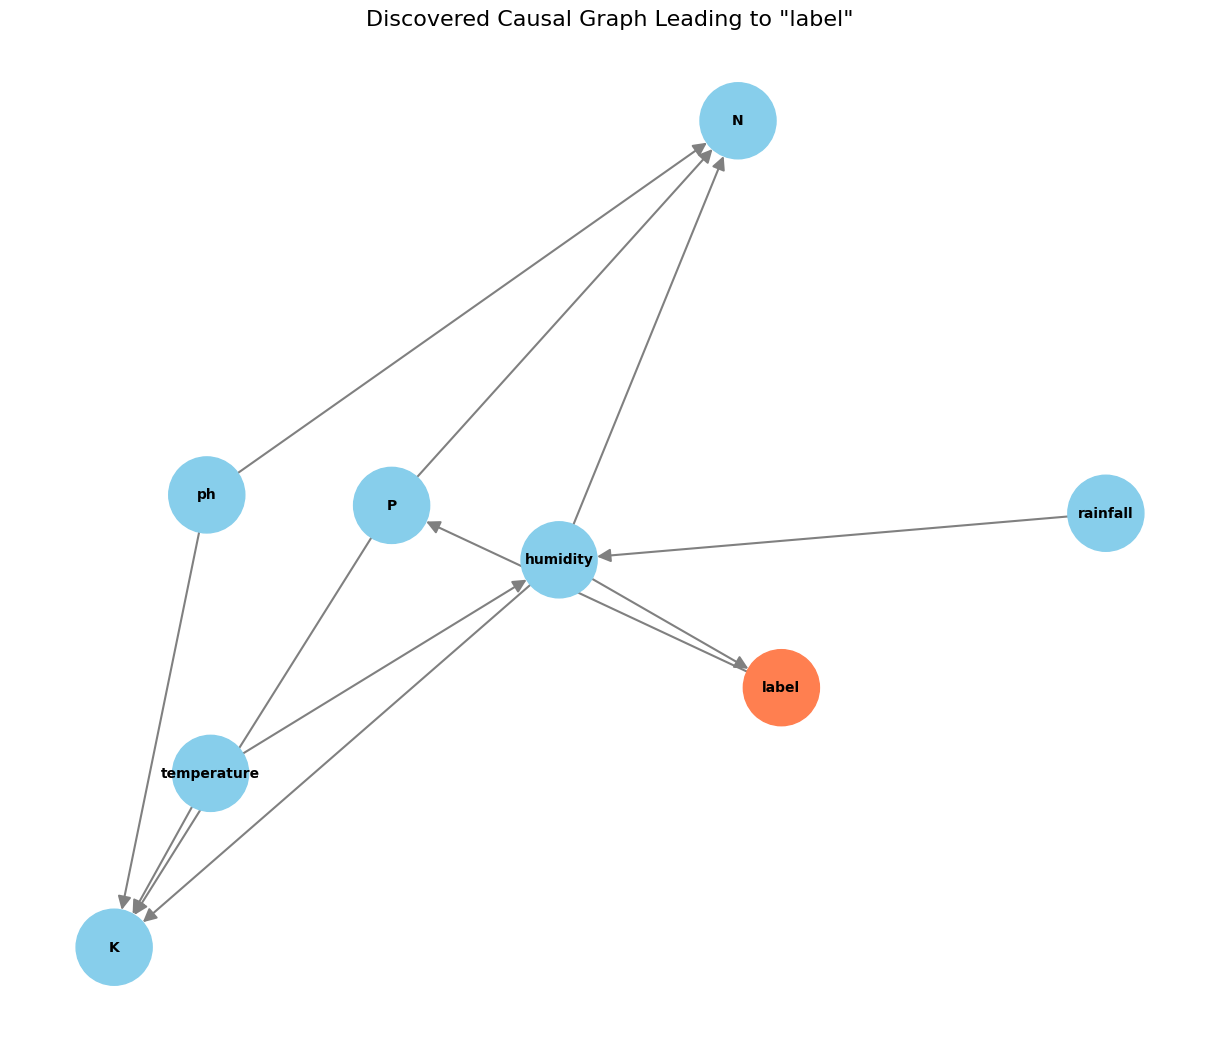

Generating comparison plot...


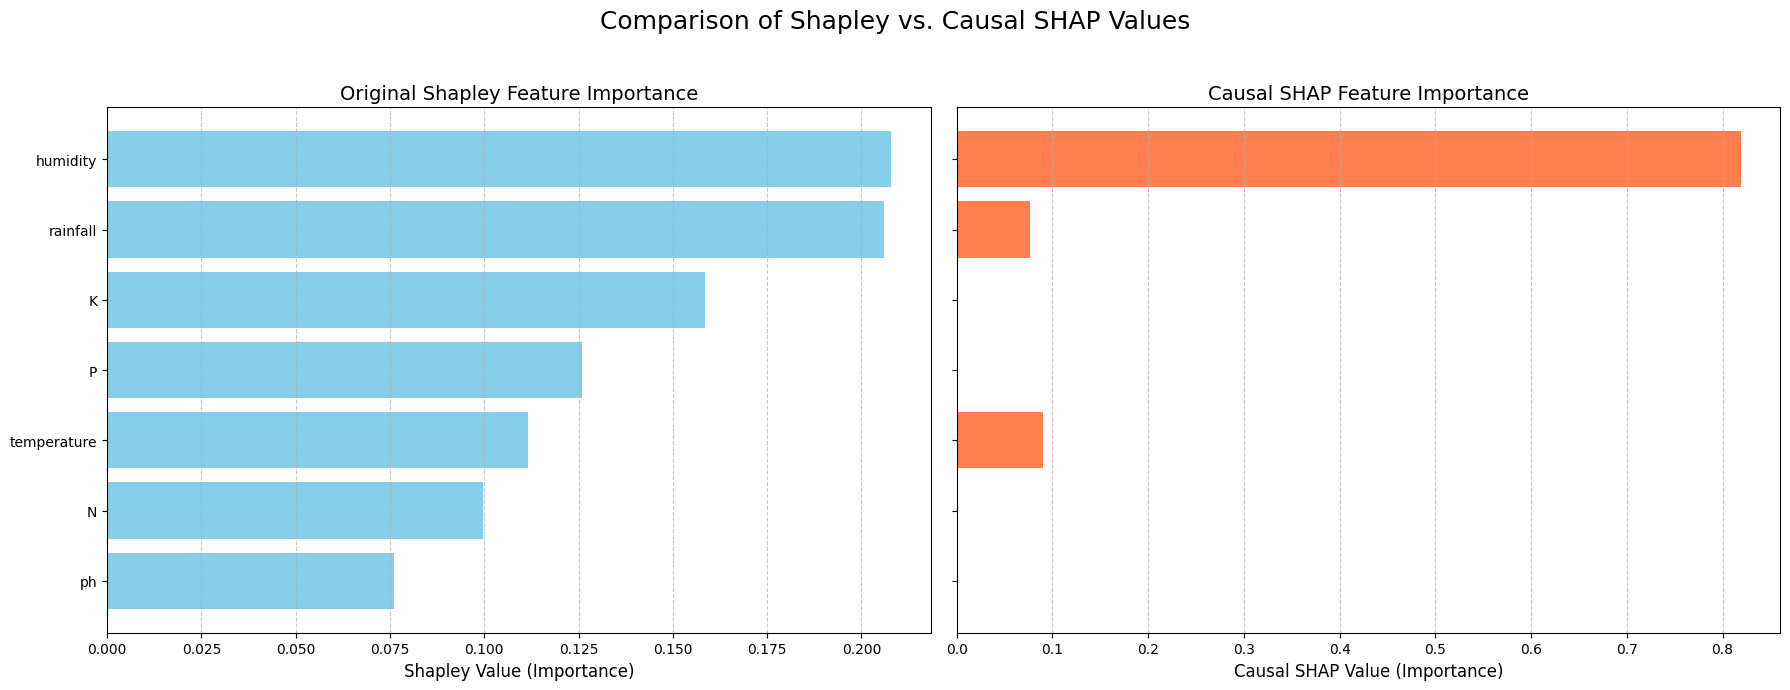

In [30]:
print("\nOriginal Shapley Values:")
print(shapley_df.to_string())
print("\nCausal SHAP Values:")
print(causal_shap_df.to_string())

print("\nGenerating causal graph visualization...")
node_colors = ['coral' if node == 'label' else 'skyblue' for node in causal_graph_nx.nodes()]
plt.figure(figsize=(12, 10))
pos = nx.spring_layout(causal_graph_nx, seed=42, k=0.9)
nx.draw(causal_graph_nx, pos, with_labels=True, node_color=node_colors, node_size=3000,
        font_size=10, font_weight='bold', arrows=True, arrowstyle='-|>',
        arrowsize=20, edge_color='gray', width=1.5)
plt.title('Discovered Causal Graph Leading to "label"', fontsize=16)
plt.show()


print("Generating comparison plot...")
fig, ax = plt.subplots(1, 2, figsize=(18, 7), sharey=True)
shapley_df_sorted = shapley_df.sort_values(by='Shapley Value', ascending=True)
ax[0].barh(shapley_df_sorted['Feature'], shapley_df_sorted['Shapley Value'], color='skyblue')
ax[0].set_title('Original Shapley Feature Importance', fontsize=14)
ax[0].set_xlabel('Shapley Value (Importance)', fontsize=12)
ax[0].grid(axis='x', linestyle='--', alpha=0.7)

causal_shap_df_sorted = causal_shap_df.set_index('Feature').loc[shapley_df_sorted['Feature']].reset_index()
ax[1].barh(causal_shap_df_sorted['Feature'], causal_shap_df_sorted['Causal SHAP Value'], color='coral')
ax[1].set_title('Causal SHAP Feature Importance', fontsize=14)
ax[1].set_xlabel('Causal SHAP Value (Importance)', fontsize=12)
ax[1].grid(axis='x', linestyle='--', alpha=0.7)

plt.suptitle('Comparison of Shapley vs. Causal SHAP Values', fontsize=18)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [7]:
# Crop Recommendation - Causal SHAP

FAST            = False        # set to False for smoother but slower results
ALPHA_PC        = 0.05        # PC test level
MAX_PERM        = 800 if FAST else 2000    # permutations for SHAP over v_c
M_RESAMPLES     = 64  if FAST else 256     # inner samples per coalition for v_c
GLOBAL_K        = 30  if FAST else 60      # #test instances to average for global
RANDOM_SEED     = 42

import numpy as np
import pandas as pd
import math, itertools, warnings
import networkx as nx
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import f1_score
warnings.filterwarnings("ignore")

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except Exception:
    from sklearn.ensemble import GradientBoostingClassifier
    HAVE_XGB = False

# Causal discovery
from causallearn.search.ConstraintBased.PC import pc

rng = np.random.default_rng(RANDOM_SEED)

# 1) Load data, encode, split, train the black-box classifier
DATA_PATH = "Crop_recommendation.csv"   # adjust if needed
df = pd.read_csv(DATA_PATH)

le = LabelEncoder()
df['label_encoded'] = le.fit_transform(df['label'])

feature_names = ['N','P','K','temperature','humidity','ph','rainfall']
X = df[feature_names].copy()
y = df['label_encoded'].copy()

# scaling is OK (especially for linear mechanisms and PC tests)
X_scaled = pd.DataFrame(StandardScaler().fit_transform(X), columns=feature_names)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)

# model
if HAVE_XGB:
    model = XGBClassifier(
        n_estimators=(120 if FAST else 300),
        max_depth=(5 if FAST else 6),
        learning_rate=0.08,
        subsample=0.9, colsample_bytree=0.9, reg_lambda=1.0,
        tree_method="hist",
        eval_metric="mlogloss",
        random_state=RANDOM_SEED,
        verbosity=0
    )
else:
    model = GradientBoostingClassifier(random_state=RANDOM_SEED)

model.fit(X_train.values, y_train.values)

# baseline sanity metric (macro-F1 on test)
y_pred = model.predict(X_test.values)
print(f"[sanity] Test Macro-F1: {f1_score(y_test, y_pred, average='macro'):.4f}")

# 2) PC on FEATURES ONLY (train split), CPDAG -> partial DiGraph
print("Step 1: Discovering feature-only causal graph via PC...")
pc_res = pc(X_train.to_numpy(), alpha=ALPHA_PC, show_progress=False)
A = pc_res.G.graph  # CPDAG-style adjacency; values in {-1,0,1}

# Build a partial DiGraph:
#   i->j if A[i,j]==-1 and A[j,i]==1
#   undirected if both -1: keep both directions
DAG_feat = nx.DiGraph(); DAG_feat.add_nodes_from(feature_names)

for i,u in enumerate(feature_names):
    for j,v in enumerate(feature_names):
        if i==j:
            continue
        if A[i,j] == -1 and A[j,i] == 1:
            DAG_feat.add_edge(u, v)        # directed u -> v

# also add undirected edges as both directions
rows_u, cols_u = np.where((A == -1) & (A.T == -1))
for i, j in zip(rows_u, cols_u):
    if i < j:                              # prevent double-adding
        DAG_feat.add_edge(feature_names[i], feature_names[j])
        DAG_feat.add_edge(feature_names[j], feature_names[i])

# Safe topo order (fallback if CPDAG left 2-cycles)
def make_safe_topo(G, nodes):
    """
    Return an order that tries to place parents before children.
    If cycles exist, we break ties by picking a node with the fewest
    remaining in-graph predecessors.
    """
    nodes = list(nodes)
    ordered = []
    remaining = set(nodes)
    preds = {n: set(G.predecessors(n)) for n in nodes}

    while remaining:
        ready = [n for n in remaining if preds[n].issubset(set(ordered))]
        if not ready:
            # cycle/stalemate: force a node with smallest # of remaining predecessors
            cand = min(remaining, key=lambda n: len(preds[n].intersection(remaining)))
            ready = [cand]
        for n in ready:
            ordered.append(n)
            remaining.remove(n)
    return ordered

TOPO = make_safe_topo(DAG_feat, feature_names)   # or make_safe_topo(DAG_feat, feature_names)

# 3) Fit linear mechanisms X_pa -> X_i (intercept + residual σ)
def fit_linear_mechanisms(DAG, X_df):
    mechs = {}
    for i in feature_names:
        parents = [p for p in feature_names if DAG.has_edge(p, i)]
        if not parents:
            mechs[i] = {
                "parents": [],
                "intercept": float(X_df[i].mean()),
                "coef": None,
                "sigma": float(X_df[i].std(ddof=1))
            }
        else:
            lr = LinearRegression().fit(X_df[parents].values, X_df[i].values)
            pred = lr.predict(X_df[parents].values)
            resid = X_df[i].values - pred
            mechs[i] = {
                "parents": parents,
                "intercept": float(lr.intercept_),
                "coef": lr.coef_.astype(float),
                "sigma": float(np.std(resid, ddof=1))
            }
    return mechs

X_train_df = X_train.copy()
MECHS = fit_linear_mechanisms(DAG_feat, X_train_df)

# 4) Build Yhat on TRAIN = prob of model’s predicted class
#    and compute total causal effects W_i -> “Yhat”
proba_train = model.predict_proba(X_train_df.values)
top_idx_train = np.argmax(proba_train, axis=1)
YHAT = pd.Series(proba_train[np.arange(len(proba_train)), top_idx_train],
                 index=X_train_df.index, name="Yhat")

def regress_edge_weight(src_series, dst_series, cond_df=None):
    if (cond_df is None) or (cond_df.shape[1]==0):
        Xmat = src_series.values.reshape(-1,1)
    else:
        Xmat = np.column_stack([cond_df.values, src_series.values.reshape(-1,1)])
    lr = LinearRegression().fit(Xmat, dst_series.values)
    return float(lr.coef_[-1])

# Augmented graph (features + "Yhat") with conditional edge weights
G_aug = nx.DiGraph(); G_aug.add_nodes_from(feature_names + ["Yhat"])

# feature -> feature edges with conditioning on parents of child
for i in feature_names:
    for j in feature_names:
        if i==j:
            continue
        if DAG_feat.has_edge(i, j):
            parents_j = [p for p in feature_names if p != i and DAG_feat.has_edge(p, j)]
            cond = X_train_df[parents_j] if parents_j else None
            w = regress_edge_weight(X_train_df[i], X_train_df[j], cond)
            if abs(w) > 1e-12:
                G_aug.add_edge(i, j, weight=w)

# feature -> Yhat edges (marginal given other features)
for f in feature_names:
    cond = X_train_df[[c for c in feature_names if c != f]]
    w = regress_edge_weight(X_train_df[f], YHAT, cond)
    if abs(w) > 1e-12:
        G_aug.add_edge(f, "Yhat", weight=w)

def path_product(path):
    prod = 1.0
    for a,b in zip(path[:-1], path[1:]):
        prod *= G_aug[a][b]["weight"]
    return prod

# Total causal effects W_i = sum of path products i -> ... -> Yhat
W = {}
for f in feature_names:
    total = 0.0
    for path in nx.all_simple_paths(G_aug, source=f, target="Yhat", cutoff=len(feature_names)+1):
        total += path_product(path)
    W[f] = total

# γ-weights (optional; can be toggled off)
absW = {k: abs(v) for k,v in W.items()}
Wsum = sum(absW.values()) + 1e-12
GAMMA = {k: absW[k]/Wsum for k in feature_names}

# 5) Causal value function v_c(S) via do(X_S = x_S)
def sample_do(mechs, S_fixed, x_row, topo_order, rng):
    x_new = {}
    for node in topo_order:
        if node in S_fixed:
            x_new[node] = float(x_row[node])
        else:
            m = mechs[node]
            if not m["parents"] or (m["coef"] is None):
                mu, sigma = m["intercept"], m["sigma"]
                if sigma is None or np.isnan(sigma) or sigma <= 1e-12:
                    x_new[node] = mu
                else:
                    x_new[node] = float(rng.normal(mu, sigma))
            else:
                # Use any already-sampled parent; if missing (due to residual cycle),
                # fall back to the original instance value for that parent.
                pa_vals = np.array(
                    [x_new.get(p, float(x_row[p])) for p in m["parents"]],
                    dtype=float
                ).reshape(1, -1)
                coef = np.asarray(m["coef"]).reshape(-1)
                mean = float(m["intercept"] + pa_vals.dot(coef)[0])
                sigma = m["sigma"]
                if sigma is None or np.isnan(sigma) or sigma <= 1e-12:
                    x_new[node] = mean
                else:
                    x_new[node] = float(rng.normal(mean, sigma))
    return x_new


# choose one test instance (local explanation)
x0 = X_test.iloc[0]
pred_probs0 = model.predict_proba(pd.DataFrame([x0], columns=feature_names).values)[0]
pred_class0 = int(np.argmax(pred_probs0))

def causal_value_function(S_features, x_row, mechs, topo_order, M, rng):
    """v_c(S) = E[ f(X) | do(X_S=x_S) ], f(.) = prob of fixed predicted class at x_row."""
    acc = 0.0
    for _ in range(M):
        x_samp = sample_do(mechs, set(S_features), x_row, topo_order, rng)
        X_mat = pd.DataFrame([x_samp], columns=feature_names).values
        prob = model.predict_proba(X_mat)[0][pred_class0]
        acc += prob
    return acc / M

# 6) Causal SHAP (permutation estimator over v_c)
#    Optional γ-weighting in aggregation (toggle GAMMA_WEIGHTED)
GAMMA_WEIGHTED = True   # set False for plain causal SHAP

phi_raw = np.zeros(len(feature_names), dtype=float)
for _ in range(MAX_PERM):
    perm = rng.permutation(feature_names)
    S = []
    v_prev = causal_value_function(S, x0, MECHS, TOPO, M_RESAMPLES, rng)
    for f in perm:
        S_next = S + [f]
        v_curr = causal_value_function(S_next, x0, MECHS, TOPO, M_RESAMPLES, rng)
        delta = v_curr - v_prev
        contrib = (GAMMA[f] * delta) if GAMMA_WEIGHTED else delta
        phi_raw[feature_names.index(f)] += contrib
        v_prev = v_curr
        S = S_next

phi_local = phi_raw / MAX_PERM

# normalization (local accuracy): make sum(phi) match f(x) - v_c(∅)
f_x = model.predict_proba(pd.DataFrame([x0], columns=feature_names).values)[0][pred_class0]
v_empty = causal_value_function([], x0, MECHS, TOPO, M_RESAMPLES, rng)
sum_phi = np.sum(phi_local)
if abs(sum_phi) > 1e-12:
    phi_local = phi_local * ((f_x - v_empty) / sum_phi)

causal_shap_local = pd.Series(phi_local, index=feature_names, name="Causal SHAP (local)")
print("\n=== Local Causal SHAP (for one test instance) ===")
print(causal_shap_local.sort_values(ascending=False).round(6))

# 7) Global Causal SHAP (average over K test instances)
def causal_shap_instance(model, x_row, mechs, topo_order, gamma, T_perm, M_inner, rng, gamma_weighted=True):
    probs = model.predict_proba(pd.DataFrame([x_row], columns=feature_names).values)[0]
    fixed_cls = int(np.argmax(probs))

    def vc(S):
        acc = 0.0
        for _ in range(M_inner):
            x_samp = sample_do(mechs, set(S), x_row, topo_order, rng)
            X_mat = pd.DataFrame([x_samp], columns=feature_names).values
            acc += model.predict_proba(X_mat)[0][fixed_cls]
        return acc / M_inner

    phi = np.zeros(len(feature_names), dtype=float)
    for _ in range(T_perm):
        perm = rng.permutation(feature_names)
        S = []
        v_prev = vc(S)
        for f in perm:
            S_next = S + [f]
            v_curr = vc(S_next)
            delta = v_curr - v_prev
            phi[feature_names.index(f)] += (gamma[f] * delta) if gamma_weighted else delta
            v_prev = v_curr
            S = S_next

    phi /= T_perm
    f_xi = probs[fixed_cls]
    v0 = vc([])
    sumphi = np.sum(phi)
    if abs(sumphi) > 1e-12:
        phi = phi * ((f_xi - v0) / sumphi)
    return pd.Series(phi, index=feature_names)

# average over a sample of test instances
idxs = rng.choice(len(X_test), size=min(GLOBAL_K, len(X_test)), replace=False)
phis = []
for i in idxs:
    phis.append(causal_shap_instance(model, X_test.iloc[i], MECHS, TOPO, GAMMA,
                                     T_perm=(MAX_PERM//4 if FAST else MAX_PERM//2),
                                     M_inner=M_RESAMPLES, rng=rng, gamma_weighted=GAMMA_WEIGHTED))
causal_shap_global = pd.concat(phis, axis=1).mean(axis=1).rename("Causal SHAP (global)")

print("\n=== Global Causal SHAP (avg over sample of test instances) ===")
print(causal_shap_global.sort_values(ascending=False).round(6))

# 8) (Optional) Compare to standard SHAP (Tree/Kernel) GLOBAL
try:
    import shap
    try:
        explainer = shap.TreeExplainer(model)
        shap_values = explainer.shap_values(X_test.values)
        SHAP_TYPE = "Tree"
    except Exception:
        # Kernel fallback (slow): use small background
        bg_idx = rng.choice(len(X_train), size=min(80 if FAST else 200, len(X_train)), replace=False)
        f = lambda data: model.predict_proba(pd.DataFrame(data, columns=feature_names).values)
        explainer = shap.KernelExplainer(f, X_train.iloc[bg_idx].values)
        shap_values = explainer.shap_values(X_test.values, nsamples=(150 if FAST else 400))
        SHAP_TYPE = "Kernel"

    if isinstance(shap_values, list):
        shap_global = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values], axis=0)
    else:
        shap_global = np.abs(shap_values).mean(axis=0)
    shap_global = pd.Series(shap_global, index=feature_names, name=f"SHAP {SHAP_TYPE} (global)")

    comp = pd.concat([shap_global, causal_shap_global], axis=1)
    print("\n=== Global comparison: SHAP vs Causal SHAP ===")
    print(comp.sort_values(comp.columns[-1], ascending=False).round(6))

    ax = comp.plot(kind="bar", figsize=(12,5), title="Global: SHAP vs Causal SHAP")
    ax.set_ylabel("Importance / Attribution")
    plt.xticks(rotation=0); plt.tight_layout(); plt.show()

except Exception as e:
    print(f"[warn] SHAP comparison skipped: {e}")

# 9) Visualize the discovered feature graph
plt.figure(figsize=(9,7))
pos = nx.spring_layout(DAG_feat, seed=RANDOM_SEED)
nx.draw(DAG_feat, pos, with_labels=True, node_color='skyblue', node_size=2200,
        font_size=10, font_weight='bold', arrows=True, width=1.4, edge_color='gray')
plt.title("Feature-only causal graph (PC → CPDAG → partial DiGraph)")
plt.show()

[sanity] Test Macro-F1: 0.9908
Step 1: Discovering feature-only causal graph via PC...



CAUSAL SHAP: Feature Attribution for Crop Recommendation

Loading Crop Recommendation dataset...
✓ Dataset loaded: 2200 samples, 8 columns
Features: N, P, K, temperature, humidity, ph, rainfall
Target classes: 22 (apple, banana, blackgram, chickpea, coconut...)
✓ Data split: 1760 train, 440 test samples

Training Model
Using XGBoost classifier
✓ Model trained
  Test Accuracy: 0.9886
  Test Macro F1: 0.9885

Step 1: Causal Discovery (PC Algorithm)
Running PC algorithm on 7 features...
✓ Causal discovery complete

Discovered graph: 7 nodes, 12 edges
✓ Causal graph saved to 'causal_graph_crop.png'

Step 2: Computing Causal SHAP

Learning causal mechanisms...
  Found 1 undirected edges, sampling orientations...
Computing causal effects (IDA-style)...
✓ Causal effects computed (averaged over 5 DAGs)
✓ Learned 5 DAG orientations

Total Causal Effects (W_i):
----------------------------------------
  N              : W=  1.1290  γ=0.1440
  P              : W=  3.6668  γ=0.4676
  K           

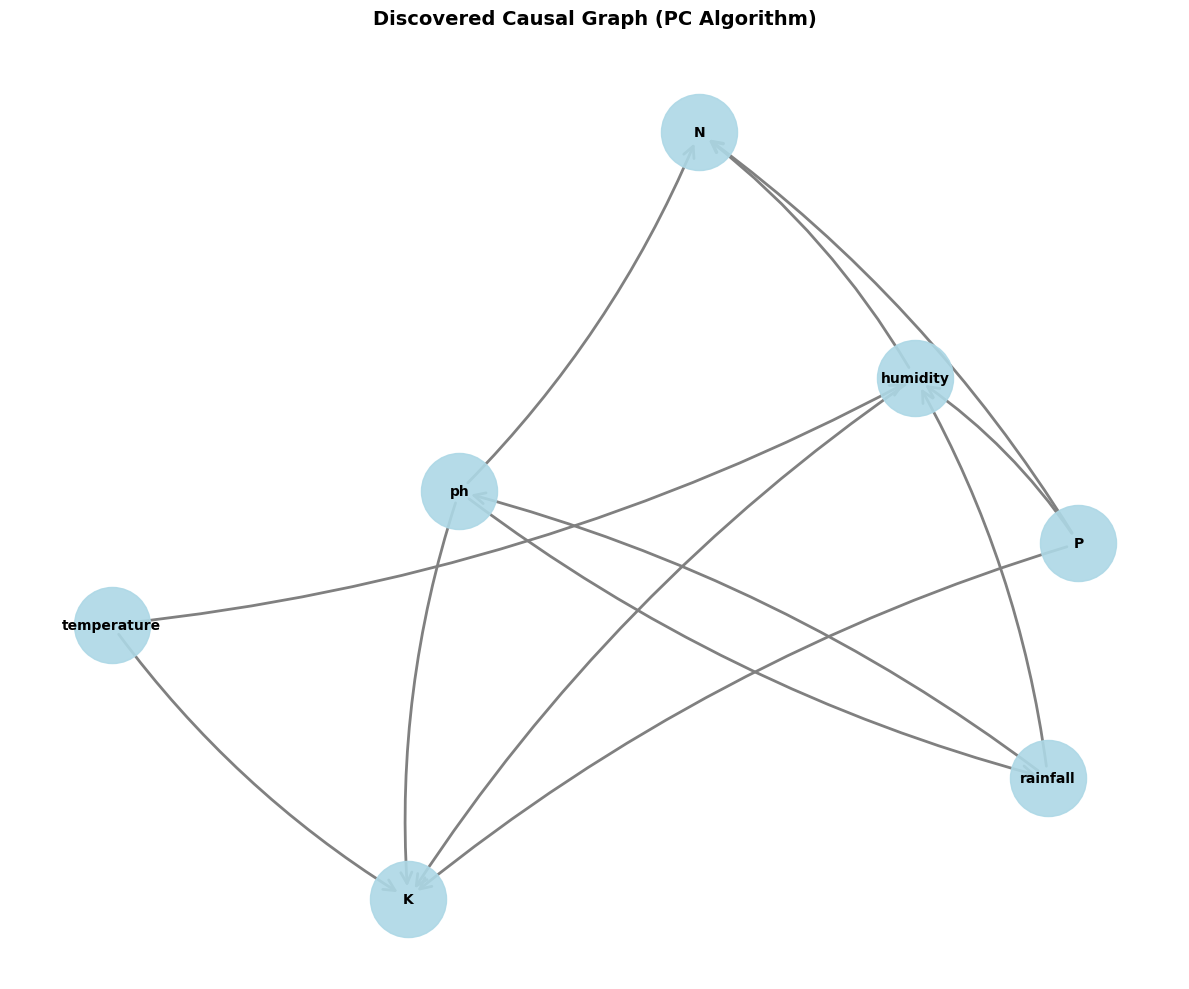

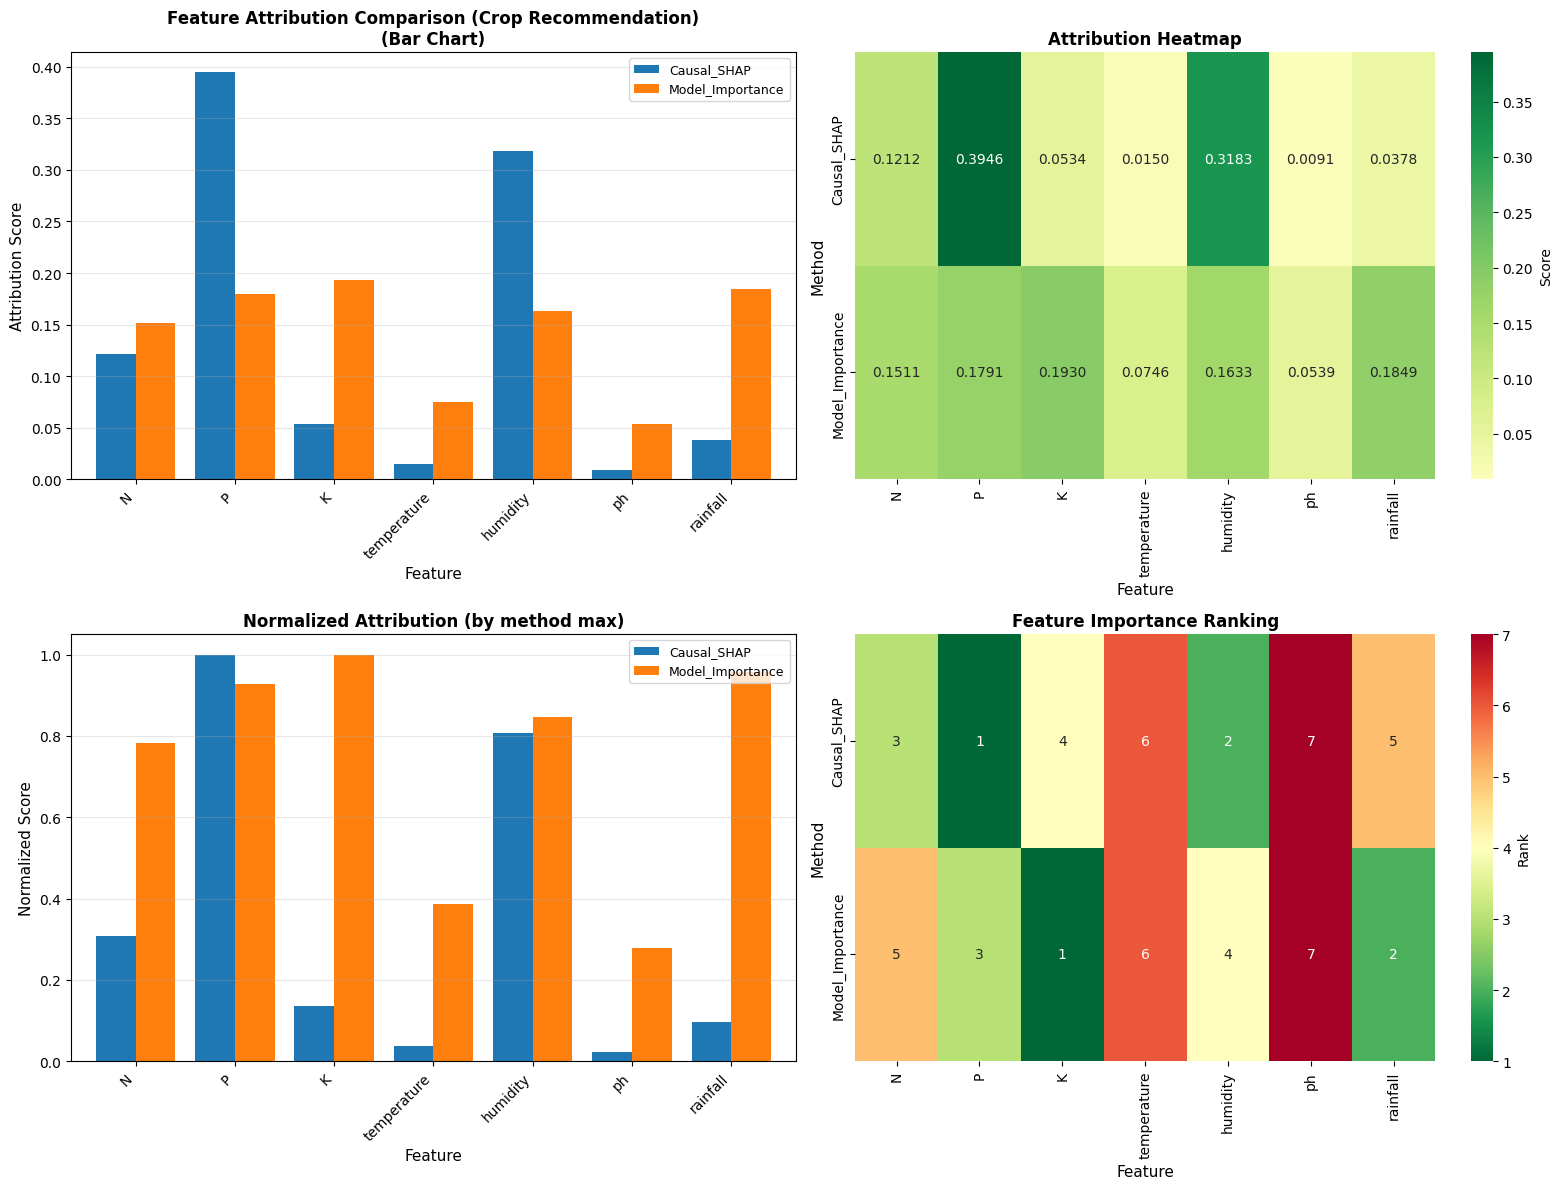

In [1]:
"""
Complete Causal SHAP Implementation for Crop Recommendation Dataset
Implements the paper's methodology with proper IDA-style causal effect estimation
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from typing import Dict, List, Tuple, Set
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
import networkx as nx

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except:
    HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

# Configuration
CONFIG = {
    'DATA_PATH': 'Crop_recommendation.csv',
    'ALPHA_PC': 0.05,
    'MAX_PERM': 300,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5  # Sample multiple DAGs from CPDAG
}

np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])


# 1. Causal Discovery & Structure Learning

class CausalStructure:
    """Handles causal discovery and DAG sampling from CPDAG"""

    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names = None
        self.dags = []

    def discover(self, X: pd.DataFrame):
        """Run PC algorithm on features"""
        self.feature_names = list(X.columns)
        print(f"Running PC algorithm on {len(self.feature_names)} features...")

        pc_res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = pc_res.G.graph

        print(f"Causal discovery complete")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        """Convert CPDAG to networkx DiGraph"""
        G = nx.DiGraph()
        G.add_nodes_from(self.feature_names)

        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                # Directed edge i->j
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                # Undirected edge: add both directions
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    if i < j:  # Avoid double-adding
                        G.add_edge(self.feature_names[i], self.feature_names[j])
                        G.add_edge(self.feature_names[j], self.feature_names[i])

        return G

    def sample_dags(self, n_samples=5) -> List[nx.DiGraph]:
        """
        Sample multiple DAG orientations from CPDAG
        For undirected edges, randomly orient them
        """
        base_G = self.get_skeleton()
        dags = []

        # Find undirected edges
        undirected = []
        for i, u in enumerate(self.feature_names):
            for j, v in enumerate(self.feature_names):
                if i < j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((u, v))

        if len(undirected) == 0:
            # CPDAG is already fully directed
            print(f"  CPDAG is fully directed ({base_G.number_of_edges()} edges)")
            return [base_G]

        print(f"  Found {len(undirected)} undirected edges, sampling orientations...")

        # Sample orientations
        for _ in range(n_samples):
            G = nx.DiGraph()
            G.add_nodes_from(self.feature_names)

            # Add directed edges from CPDAG
            for i, u in enumerate(self.feature_names):
                for j, v in enumerate(self.feature_names):
                    if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(u, v)

            # Randomly orient undirected edges (ensuring acyclicity)
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)

                # Check for cycles and reverse if needed
                if not nx.is_directed_acyclic_graph(G):
                    G.remove_edge(u, v) if G.has_edge(u, v) else G.remove_edge(v, u)
                    G.add_edge(v, u) if not G.has_edge(v, u) else G.add_edge(u, v)

            dags.append(G)

        self.dags = dags
        return dags


# 2. Causal Mechanism Learning

class LinearMechanisms:
    """Learn linear structural equation models"""

    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.feature_names = feature_names
        self.mechanisms = {}
        self.topo_order = None

    def fit(self, X: pd.DataFrame):
        """Fit linear mechanisms for each variable"""
        # Get topological order
        try:
            self.topo_order = list(nx.topological_sort(self.dag))
        except:
            # Fallback if cycles exist
            self.topo_order = self._safe_topo_order()

        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))

            if not parents:
                # No parents: use marginal distribution
                self.mechanisms[var] = {
                    'parents': [],
                    'intercept': float(X[var].mean()),
                    'coef': None,
                    'sigma': float(X[var].std())
                }
            else:
                # Regress on parents
                lr = LinearRegression()
                lr.fit(X[parents].values, X[var].values)

                pred = lr.predict(X[parents].values)
                resid = X[var].values - pred

                self.mechanisms[var] = {
                    'parents': parents,
                    'intercept': float(lr.intercept_),
                    'coef': lr.coef_.astype(float),
                    'sigma': float(np.std(resid))
                }

        return self

    def _safe_topo_order(self) -> List[str]:
        """Fallback topological sort"""
        ordered = []
        remaining = set(self.feature_names)

        while remaining:
            # Find nodes with no remaining parents
            ready = [n for n in remaining
                    if all(p in ordered or p not in remaining
                           for p in self.dag.predecessors(n))]

            if not ready:
                # Force one with fewest remaining parents
                ready = [min(remaining,
                           key=lambda n: len([p for p in self.dag.predecessors(n)
                                            if p in remaining]))]

            for n in ready:
                ordered.append(n)
                remaining.remove(n)

        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series, rng) -> Dict:
        """
        Sample from interventional distribution do(X_S = x_S)
        """
        x_new = {}

        for var in self.topo_order:
            if var in S:
                x_new[var] = float(x_obs[var])
            else:
                # Sample from mechanism
                mech = self.mechanisms[var]

                if not mech['parents']:
                    # No parents: sample from marginal
                    mu, sigma = mech['intercept'], mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))
                else:
                    # Sample from conditional
                    parent_vals = np.array([x_new.get(p, x_obs[p])
                                           for p in mech['parents']])

                    mu = mech['intercept'] + parent_vals @ mech['coef']
                    sigma = mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))

        return x_new


# 3. Causal Effect Estimation (IDA-style)

class CausalEffects:
    """Estimate total causal effects using path analysis"""

    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        """
        Compute total causal effects for each feature on target
        Average over multiple DAG samples (IDA-style)
        """
        print("Computing causal effects (IDA-style)...")

        # Build augmented graphs with target
        aug_graphs = []

        for dag in self.dags:
            G = dag.copy()
            G.add_node('Y')

            # Add edges from features to Y with estimated weights
            for feat in self.feature_names:
                # Conditional regression: feat -> Y | other features
                other_feats = [f for f in self.feature_names if f != feat]
                if other_feats:
                    X_cond = np.column_stack([X[other_feats].values, X[feat].values])
                else:
                    X_cond = X[[feat]].values

                lr = LinearRegression()
                lr.fit(X_cond, y.values)
                weight = abs(lr.coef_[-1])

                if weight > 1e-6:
                    G.add_edge(feat, 'Y', weight=weight)

            # Add edge weights for feature->feature edges
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                if parents:
                    X_reg = np.column_stack([X[parents].values, X[u].values])
                else:
                    X_reg = X[[u]].values

                lr = LinearRegression()
                lr.fit(X_reg, X[v].values)
                weight = abs(lr.coef_[-1])
                G[u][v]['weight'] = weight

            aug_graphs.append(G)

        # Compute total effects (average over DAGs)
        total_effects = {feat: [] for feat in self.feature_names}

        for G in aug_graphs:
            for feat in self.feature_names:
                effect = 0.0

                # Sum over all paths feat -> Y
                try:
                    for path in nx.all_simple_paths(G, feat, 'Y', cutoff=10):
                        path_effect = 1.0
                        for i in range(len(path) - 1):
                            edge_data = G.get_edge_data(path[i], path[i+1])
                            if edge_data and 'weight' in edge_data:
                                path_effect *= edge_data['weight']
                        effect += path_effect
                except:
                    pass

                total_effects[feat].append(effect)

        # Average across DAGs
        self.effects = {feat: np.mean(effects)
                       for feat, effects in total_effects.items()}

        print(f"Causal effects computed (averaged over {len(self.dags)} DAGs)")
        return self.effects

    def get_gamma_weights(self) -> Dict[str, float]:
        """Compute gamma weights (normalized absolute effects)"""
        abs_effects = {k: abs(v) for k, v in self.effects.items()}
        total = sum(abs_effects.values()) + 1e-12

        return {k: v / total for k, v in abs_effects.items()}


# 4. Causal SHAP Implementation

class CausalSHAP:
    """Main Causal SHAP implementation"""

    def __init__(self, model, causal_structure: CausalStructure,
                 X_train: pd.DataFrame, y_train: pd.Series):
        self.model = model
        self.structure = causal_structure
        self.X_train = X_train
        self.y_train = y_train
        self.feature_names = list(X_train.columns)

        print("\nLearning causal mechanisms...")
        # Learn mechanisms and effects
        self.dags = causal_structure.sample_dags(n_samples=CONFIG['N_DAGS'])
        self.mechanisms_list = [LinearMechanisms(dag, self.feature_names).fit(X_train)
                               for dag in self.dags]

        # Compute causal effects
        self.causal_effects = CausalEffects(self.dags, self.feature_names)
        self.causal_effects.compute_effects(X_train, y_train)
        self.gamma = self.causal_effects.get_gamma_weights()

        print(f"Learned {len(self.dags)} DAG orientations")

    def _causal_value_function(self, S: Set[str], x: pd.Series,
                               pred_class: int, M: int) -> float:
        """
        v_c(S) = E[f(X) | do(X_S = x_S)]
        Average over DAG samples and Monte Carlo samples
        """
        total = 0.0
        samples_per_dag = max(1, M // len(self.mechanisms_list))

        for mechanisms in self.mechanisms_list:
            for _ in range(samples_per_dag):
                x_sample = mechanisms.sample_intervention(S, x, rng)
                X_mat = pd.DataFrame([x_sample], columns=self.feature_names)

                prob = self.model.predict_proba(X_mat.values)[0][pred_class]
                total += prob

        actual_samples = samples_per_dag * len(self.mechanisms_list)
        return total / actual_samples

    def explain_instance(self, x: pd.Series, n_perms: int = None,
                        m_samples: int = None) -> pd.Series:
        """
        Compute Causal SHAP values for a single instance
        """
        if n_perms is None:
            n_perms = CONFIG['MAX_PERM']
        if m_samples is None:
            m_samples = CONFIG['M_RESAMPLES']

        # Get predicted class
        probs = self.model.predict_proba(pd.DataFrame([x],
                                         columns=self.feature_names).values)[0]
        pred_class = int(np.argmax(probs))

        # Permutation-based estimation
        phi = np.zeros(len(self.feature_names))

        for _ in range(n_perms):
            perm = rng.permutation(self.feature_names)
            S = set()
            v_prev = self._causal_value_function(S, x, pred_class, m_samples)

            for feat in perm:
                S_next = S | {feat}
                v_curr = self._causal_value_function(S_next, x, pred_class, m_samples)

                delta = v_curr - v_prev
                contrib = self.gamma[feat] * delta  # Causal weighting

                phi[self.feature_names.index(feat)] += contrib
                v_prev = v_curr
                S = S_next

        phi /= n_perms

        # Normalize for local accuracy
        f_x = probs[pred_class]
        v_empty = self._causal_value_function(set(), x, pred_class, m_samples)

        sum_phi = np.sum(phi)
        if abs(sum_phi) > 1e-12:
            phi = phi * ((f_x - v_empty) / sum_phi)

        return pd.Series(phi, index=self.feature_names, name='Causal_SHAP')

    def explain_global(self, X_test: pd.DataFrame, n_samples: int = None) -> pd.Series:
        """Global explanation: average over test instances"""
        if n_samples is None:
            n_samples = CONFIG['GLOBAL_K']

        n_samples = min(n_samples, len(X_test))
        indices = rng.choice(len(X_test), size=n_samples, replace=False)

        print(f"\nComputing global Causal SHAP (averaging over {n_samples} instances)...")
        explanations = []
        for i, idx in enumerate(indices):
            if (i + 1) % 5 == 0:
                print(f"  Progress: {i+1}/{n_samples}")
            exp = self.explain_instance(X_test.iloc[idx],
                                       n_perms=CONFIG['MAX_PERM']//4)
            explanations.append(exp)

        print("Global Causal SHAP computed")
        return pd.concat(explanations, axis=1).mean(axis=1).rename('Causal_SHAP_Global')


# 5. Baseline Methods for Comparison

def compute_baseline_shap(model, X_train, X_test, method='kernel'):
    """Compute standard SHAP values"""
    try:
        import shap

        print(f"\nComputing {method.upper()} SHAP baseline...")

        if method == 'tree' and hasattr(model, 'tree_'):
            explainer = shap.TreeExplainer(model)
            shap_values = explainer.shap_values(X_test.values)
        else:  # kernel
            bg_size = min(100, len(X_train))
            bg = shap.kmeans(X_train.values, bg_size)
            explainer = shap.KernelExplainer(
                lambda x: model.predict_proba(x),
                bg
            )
            shap_values = explainer.shap_values(X_test.values, nsamples=100)

        # Handle multi-class
        if isinstance(shap_values, list):
            # Average absolute values across classes
            global_imp = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values], axis=0)
        else:
            global_imp = np.abs(shap_values).mean(axis=0)

        print(f"{method.upper()} SHAP computed")
        return pd.Series(global_imp, index=X_test.columns, name=f'SHAP_{method}')

    except Exception as e:
        print(f"Warning: SHAP computation failed: {e}")
        return None


def compute_feature_importance(model, feature_names):
    """Compute model's native feature importance"""
    if hasattr(model, 'feature_importances_'):
        imp = model.feature_importances_
        return pd.Series(imp, index=feature_names, name='Model_Importance')
    return None


# 6. Evaluation & Visualization

def plot_comparison(df_comp: pd.DataFrame, title: str = "Feature Attribution Comparison"):
    """Visualize comparison of different methods"""

    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    # Bar plot
    df_comp.plot(kind='bar', ax=axes[0, 0], width=0.8)
    axes[0, 0].set_title(f'{title}\n(Bar Chart)', fontsize=12, fontweight='bold')
    axes[0, 0].set_ylabel('Attribution Score', fontsize=11)
    axes[0, 0].set_xlabel('Feature', fontsize=11)
    axes[0, 0].legend(loc='best', fontsize=9)
    axes[0, 0].grid(axis='y', alpha=0.3)
    plt.setp(axes[0, 0].xaxis.get_majorticklabels(), rotation=45, ha='right')

    # Heatmap
    sns.heatmap(df_comp.T, annot=True, fmt='.4f', cmap='RdYlGn',
                center=0, ax=axes[0, 1], cbar_kws={'label': 'Score'})
    axes[0, 1].set_title('Attribution Heatmap', fontsize=12, fontweight='bold')
    axes[0, 1].set_xlabel('Feature', fontsize=11)
    axes[0, 1].set_ylabel('Method', fontsize=11)

    # Normalized comparison
    df_norm = df_comp.div(df_comp.abs().max(axis=0), axis=1)
    df_norm.plot(kind='bar', ax=axes[1, 0], width=0.8)
    axes[1, 0].set_title('Normalized Attribution (by method max)', fontsize=12, fontweight='bold')
    axes[1, 0].set_ylabel('Normalized Score', fontsize=11)
    axes[1, 0].set_xlabel('Feature', fontsize=11)
    axes[1, 0].legend(loc='best', fontsize=9)
    axes[1, 0].grid(axis='y', alpha=0.3)
    plt.setp(axes[1, 0].xaxis.get_majorticklabels(), rotation=45, ha='right')

    # Rank comparison
    ranks = df_comp.rank(ascending=False)
    sns.heatmap(ranks.T, annot=True, fmt='.0f', cmap='RdYlGn_r',
                ax=axes[1, 1], cbar_kws={'label': 'Rank'})
    axes[1, 1].set_title('Feature Importance Ranking', fontsize=12, fontweight='bold')
    axes[1, 1].set_xlabel('Feature', fontsize=11)
    axes[1, 1].set_ylabel('Method', fontsize=11)

    plt.tight_layout()
    return fig


def plot_causal_graph(G: nx.DiGraph, title: str = "Discovered Causal Graph"):
    """Visualize the causal graph"""
    plt.figure(figsize=(12, 10))

    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=2, iterations=50)

    # Draw nodes
    nx.draw_networkx_nodes(G, pos, node_color='lightblue',
                          node_size=3000, alpha=0.9)

    # Draw edges
    nx.draw_networkx_edges(G, pos, edge_color='gray',
                          arrows=True, arrowsize=20,
                          arrowstyle='->', width=2,
                          connectionstyle='arc3,rad=0.1')

    # Draw labels
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

    plt.title(title, fontsize=14, fontweight='bold', pad=20)
    plt.axis('off')
    plt.tight_layout()
    return plt.gcf()


# 7. Main Execution

def main():
    """Run complete Causal SHAP analysis on Crop Recommendation dataset"""

    print("\n" + "="*70)
    print("CAUSAL SHAP: Feature Attribution for Crop Recommendation")
    print("="*70 + "\n")

    # Load data
    print("Loading Crop Recommendation dataset...")
    try:
        df = pd.read_csv(CONFIG['DATA_PATH'])
        print(f"Dataset loaded: {df.shape[0]} samples, {df.shape[1]} columns")
    except FileNotFoundError:
        print(f"ERROR: Could not find '{CONFIG['DATA_PATH']}'")
        print("Please ensure the file is in the current directory.")
        return

    # Prepare data
    feature_names = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

    le = LabelEncoder()
    df['label_encoded'] = le.fit_transform(df['label'])

    X = df[feature_names].copy()
    y = df['label_encoded'].copy()

    print(f"Features: {', '.join(feature_names)}")
    print(f"Target classes: {len(le.classes_)} ({', '.join(le.classes_[:5])}...)")

    # Scale features
    scaler = StandardScaler()
    X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=feature_names)

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        X_scaled, y, test_size=0.2, random_state=CONFIG['RANDOM_SEED'], stratify=y
    )

    print(f"Data split: {len(X_train)} train, {len(X_test)} test samples")

    # Train model
    print("\n" + "="*70)
    print("Training Model")
    print("="*70)

    if HAVE_XGB:
        model = XGBClassifier(
            n_estimators=120,
            max_depth=5,
            learning_rate=0.08,
            random_state=CONFIG['RANDOM_SEED'],
            verbosity=0
        )
        print("Using XGBoost classifier")
    else:
        model = RandomForestClassifier(
            n_estimators=120,
            max_depth=5,
            random_state=CONFIG['RANDOM_SEED']
        )
        print("Using Random Forest classifier")

    model.fit(X_train.values, y_train.values)

    y_pred = model.predict(X_test.values)
    f1 = f1_score(y_test, y_pred, average='macro')
    acc = accuracy_score(y_test, y_pred)

    print(f"Model trained")
    print(f"  Test Accuracy: {acc:.4f}")
    print(f"  Test Macro F1: {f1:.4f}")

    # Causal Discovery
    print("\n" + "="*70)
    print("Step 1: Causal Discovery (PC Algorithm)")
    print("="*70)

    causal_structure = CausalStructure(alpha=CONFIG['ALPHA_PC'])
    causal_structure.discover(X_train)

    # Visualize discovered graph
    G = causal_structure.get_skeleton()
    print(f"\nDiscovered graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

    fig_graph = plot_causal_graph(G, "Discovered Causal Graph (PC Algorithm)")
    plt.savefig('causal_graph_crop.png', dpi=150, bbox_inches='tight')
    print("Causal graph saved to 'causal_graph_crop.png'")

    # Causal SHAP
    print("\n" + "="*70)
    print("Step 2: Computing Causal SHAP")
    print("="*70)

    causal_shap = CausalSHAP(model, causal_structure, X_train, y_train)

    # Show causal effects
    print("\nTotal Causal Effects (W_i):")
    print("-" * 40)
    for feat in feature_names:
        effect = causal_shap.causal_effects.effects[feat]
        gamma = causal_shap.gamma[feat]
        print(f"  {feat:15s}: W={effect:8.4f}  γ={gamma:.4f}")

    # Global explanation
    global_causal_shap = causal_shap.explain_global(X_test, n_samples=CONFIG['GLOBAL_K'])

    # Baseline methods
    print("\n" + "="*70)
    print("Step 3: Computing Baseline Methods")
    print("="*70)

    baseline_shap = compute_baseline_shap(model, X_train, X_test, method='kernel')
    model_imp = compute_feature_importance(model, feature_names)

    # Comparison
    print("\n" + "="*70)
    print("Step 4: Results Comparison")
    print("="*70)

    attributions = {
        'Causal_SHAP': global_causal_shap,
    }

    if baseline_shap is not None:
        attributions['Kernel_SHAP'] = baseline_shap

    if model_imp is not None:
        attributions['Model_Importance'] = model_imp

    df_comparison = pd.DataFrame(attributions)

    print("\n" + "="*70)
    print("Attribution Scores:")
    print("="*70)
    print(df_comparison.round(6).to_string())

    # Correlation analysis
    if len(attributions) > 1:
        print("\n" + "="*70)
        print("Correlation between methods:")
        print("="*70)
        corr_matrix = df_comparison.corr()
        print(corr_matrix.round(4).to_string())

    # Visualization
    fig = plot_comparison(df_comparison,
                         title="Feature Attribution Comparison (Crop Recommendation)")
    plt.savefig('attribution_comparison_crop.png', dpi=150, bbox_inches='tight')
    print("\nComparison plot saved to 'attribution_comparison_crop.png'")

    plt.show()

if __name__ == "__main__":
    main()

\n======================================================================
CAUSAL SHAP on NPZ Dataset
======================================================================\n
Loading NPZ dataset...
✓ NPZ loaded with keys: ['X_train', 'X_test', 'y_train', 'y_test', 'feature_names']
Shapes: X_train=(800, 4), X_test=(200, 4), y_train=(800,), y_test=(200,)
Features: Nitrogen, Irrigation, Precipitation, Herbicide
Target classes: 3
\n======================================================================
Training Model
Using XGBoost classifier
✓ Model trained
  Test Accuracy: 0.8050
  Test Macro F1: 0.8081
\n======================================================================
Step 1: Causal Discovery (PC Algorithm)
Running PC algorithm on 4 features...
✓ Causal discovery complete
\nDiscovered graph: 4 nodes, 4 edges
✓ Causal graph saved to 'causal_graph_yield.png'
\n======================================================================
Step 2: Computing Causal SHAP
\nLearning causal mechanism

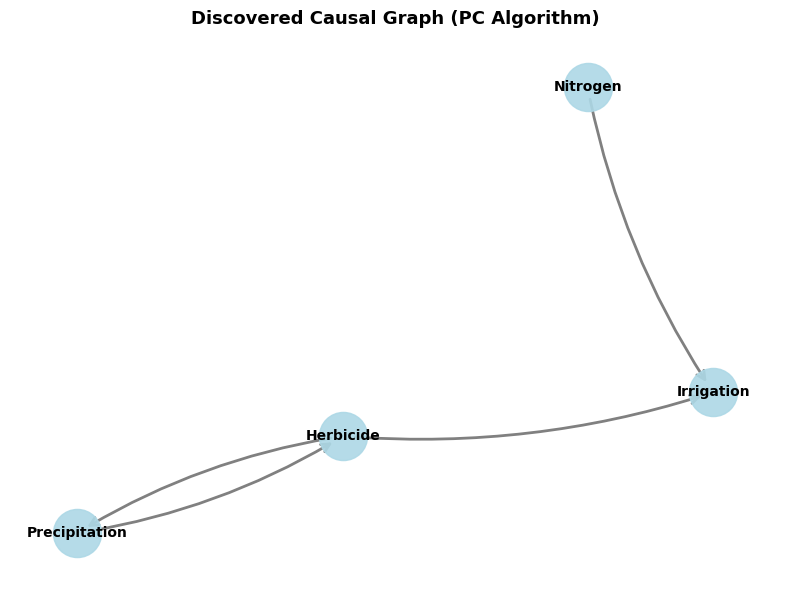

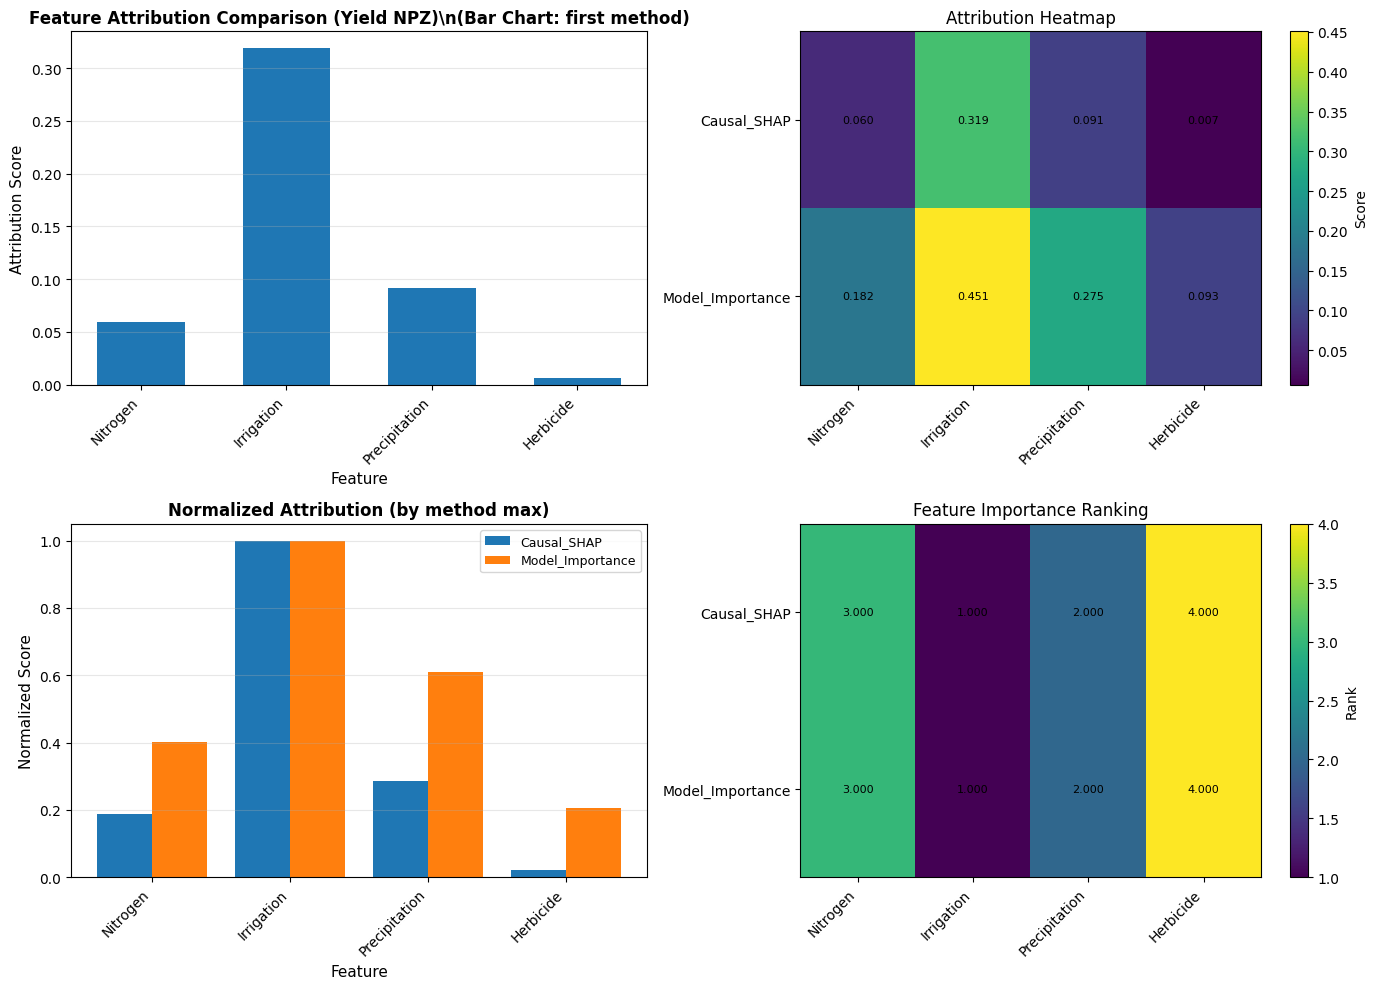

In [5]:
"""
CAUSAL SHAP on yield_preprocessed.npz
- Works with keys: X_train, X_test, y_train, y_test, feature_names
- Implements PC-based causal discovery, IDA-style causal effects, and Causal SHAP
- Saves outputs: causal graph PNG, comparison PNG, and CSV of attributions
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Tuple, Set
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
import networkx as nx

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except:
    HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

# Configuration
CONFIG = {
    'DATA_PATH': 'yield_preprocessed.npz',
    'ALPHA_PC': 0.1,
    'MAX_PERM': 200,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5  # Sample multiple DAGs from CPDAG
}

np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])


# 1. Causal Discovery & Structure Learning

class CausalStructure:
    """Handles causal discovery and DAG sampling from CPDAG"""

    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names = None
        self.dags = []

    def discover(self, X: pd.DataFrame):
        """Run PC algorithm on features"""
        self.feature_names = list(X.columns)
        print(f"Running PC algorithm on {len(self.feature_names)} features...")

        pc_res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = pc_res.G.graph

        print(f"Causal discovery complete")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        """Convert CPDAG to networkx DiGraph"""
        G = nx.DiGraph()
        G.add_nodes_from(self.feature_names)

        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                # Directed edge i->j
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                # Undirected edge: add both directions
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    if i < j:  # Avoid double-adding
                        G.add_edge(self.feature_names[i], self.feature_names[j])
                        G.add_edge(self.feature_names[j], self.feature_names[i])

        return G

    def sample_dags(self, n_samples=5) -> List[nx.DiGraph]:
        """
        Sample multiple DAG orientations from CPDAG
        For undirected edges, randomly orient them
        """
        base_G = self.get_skeleton()
        dags = []

        # Find undirected edges
        undirected = []
        for i, u in enumerate(self.feature_names):
            for j, v in enumerate(self.feature_names):
                if i < j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((u, v))

        if len(undirected) == 0:
            # CPDAG is already fully directed
            print(f"  CPDAG is fully directed ({base_G.number_of_edges()} edges)")
            return [base_G]

        print(f"  Found {len(undirected)} undirected edges, sampling orientations...")

        # Sample orientations
        for _ in range(n_samples):
            G = nx.DiGraph()
            G.add_nodes_from(self.feature_names)

            # Add directed edges from CPDAG
            for i, u in enumerate(self.feature_names):
                for j, v in enumerate(self.feature_names):
                    if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(u, v)

            # Randomly orient undirected edges (ensuring acyclicity)
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)

                # Check for cycles and reverse if needed
                if not nx.is_directed_acyclic_graph(G):
                    G.remove_edge(u, v) if G.has_edge(u, v) else G.remove_edge(v, u)
                    G.add_edge(v, u) if not G.has_edge(v, u) else G.add_edge(u, v)

            dags.append(G)

        self.dags = dags
        return dags


# 2. Causal Mechanism Learning

class LinearMechanisms:
    """Learn linear structural equation models"""

    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.feature_names = feature_names
        self.mechanisms = {}
        self.topo_order = None

    def fit(self, X: pd.DataFrame):
        """Fit linear mechanisms for each variable"""
        # Get topological order
        try:
            self.topo_order = list(nx.topological_sort(self.dag))
        except:
            # Fallback if cycles exist
            self.topo_order = self._safe_topo_order()

        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))

            if not parents:
                # No parents: use marginal distribution
                self.mechanisms[var] = {
                    'parents': [],
                    'intercept': float(X[var].mean()),
                    'coef': None,
                    'sigma': float(X[var].std())
                }
            else:
                # Regress on parents
                lr = LinearRegression()
                lr.fit(X[parents].values, X[var].values)

                pred = lr.predict(X[parents].values)
                resid = X[var].values - pred

                self.mechanisms[var] = {
                    'parents': parents,
                    'intercept': float(lr.intercept_),
                    'coef': lr.coef_.astype(float),
                    'sigma': float(np.std(resid))
                }

        return self

    def _safe_topo_order(self) -> List[str]:
        """Fallback topological sort"""
        ordered = []
        remaining = set(self.feature_names)

        while remaining:
            # Find nodes with no remaining parents
            ready = [n for n in remaining
                    if all(p in ordered or p not in remaining
                           for p in self.dag.predecessors(n))]

            if not ready:
                # Force one with fewest remaining parents
                ready = [min(remaining,
                           key=lambda n: len([p for p in self.dag.predecessors(n)
                                            if p in remaining]))]

            for n in ready:
                ordered.append(n)
                remaining.remove(n)

        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series, rng) -> Dict:
        """
        Sample from interventional distribution do(X_S = x_S)
        """
        x_new = {}

        for var in self.topo_order:
            if var in S:
                x_new[var] = float(x_obs[var])
            else:
                # Sample from mechanism
                mech = self.mechanisms[var]

                if not mech['parents']:
                    # No parents: sample from marginal
                    mu, sigma = mech['intercept'], mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))
                else:
                    # Sample from conditional
                    parent_vals = np.array([x_new.get(p, x_obs[p])
                                           for p in mech['parents']])

                    mu = mech['intercept'] + parent_vals @ mech['coef']
                    sigma = mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))

        return x_new


# 3. Causal Effect Estimation (IDA-style)

class CausalEffects:
    """Estimate total causal effects using path analysis"""

    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        """
        Compute total causal effects for each feature on target
        Average over multiple DAG samples (IDA-style)
        """
        print("Computing causal effects (IDA-style)...")

        # Build augmented graphs with target
        aug_graphs = []

        for dag in self.dags:
            G = dag.copy()
            G.add_node('Y')

            # Add edges from features to Y with estimated weights
            for feat in self.feature_names:
                # Conditional regression: feat -> Y | other features
                other_feats = [f for f in self.feature_names if f != feat]
                if other_feats:
                    X_cond = np.column_stack([X[other_feats].values, X[feat].values])
                else:
                    X_cond = X[[feat]].values

                lr = LinearRegression()
                lr.fit(X_cond, y.values)
                weight = abs(lr.coef_[-1])

                if weight > 1e-6:
                    G.add_edge(feat, 'Y', weight=weight)

            # Add edge weights for feature->feature edges
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                if parents:
                    X_reg = np.column_stack([X[parents].values, X[u].values])
                else:
                    X_reg = X[[u]].values

                lr = LinearRegression()
                lr.fit(X_reg, X[v].values)
                weight = abs(lr.coef_[-1])
                G[u][v]['weight'] = weight

            aug_graphs.append(G)

        # Compute total effects (average over DAGs)
        total_effects = {feat: [] for feat in self.feature_names}

        for G in aug_graphs:
            for feat in self.feature_names:
                effect = 0.0

                # Sum over all paths feat -> Y
                try:
                    for path in nx.all_simple_paths(G, feat, 'Y', cutoff=10):
                        path_effect = 1.0
                        for i in range(len(path) - 1):
                            edge_data = G.get_edge_data(path[i], path[i+1])
                            if edge_data and 'weight' in edge_data:
                                path_effect *= edge_data['weight']
                        effect += path_effect
                except:
                    pass

                total_effects[feat].append(effect)

        # Average across DAGs
        self.effects = {feat: np.mean(effects)
                       for feat, effects in total_effects.items()}

        print(f"Causal effects computed (averaged over {len(self.dags)} DAGs)")
        return self.effects

    def get_gamma_weights(self) -> Dict[str, float]:
        """Compute gamma weights (normalized absolute effects)"""
        abs_effects = {k: abs(v) for k, v in self.effects.items()}
        total = sum(abs_effects.values()) + 1e-12

        return {k: v / total for k, v in abs_effects.items()}


# 4. Causal SHAP Implementation

class CausalSHAP:
    """Main Causal SHAP implementation"""

    def __init__(self, model, causal_structure: CausalStructure,
                 X_train: pd.DataFrame, y_train: pd.Series):
        self.model = model
        self.structure = causal_structure
        self.X_train = X_train
        self.y_train = y_train
        self.feature_names = list(X_train.columns)

        print("\\nLearning causal mechanisms...")
        # Learn mechanisms and effects
        self.dags = causal_structure.sample_dags(n_samples=CONFIG['N_DAGS'])
        self.mechanisms_list = [LinearMechanisms(dag, self.feature_names).fit(X_train)
                               for dag in self.dags]

        # Compute causal effects
        self.causal_effects = CausalEffects(self.dags, self.feature_names)
        self.causal_effects.compute_effects(X_train, y_train)
        self.gamma = self.causal_effects.get_gamma_weights()

        print(f"Learned {len(self.dags)} DAG orientations")

    def _causal_value_function(self, S: Set[str], x: pd.Series,
                               pred_class: int, M: int) -> float:
        """
        v_c(S) = E[f(X) | do(X_S = x_S)]
        Average over DAG samples and Monte Carlo samples
        """
        total = 0.0
        samples_per_dag = max(1, M // len(self.mechanisms_list))

        for mechanisms in self.mechanisms_list:
            for _ in range(samples_per_dag):
                x_sample = mechanisms.sample_intervention(S, x, rng)
                X_mat = pd.DataFrame([x_sample], columns=self.feature_names)

                prob = self.model.predict_proba(X_mat.values)[0][pred_class]
                total += prob

        actual_samples = samples_per_dag * len(self.mechanisms_list)
        return total / actual_samples

    def explain_instance(self, x: pd.Series, n_perms: int = None,
                        m_samples: int = None) -> pd.Series:
        """
        Compute Causal SHAP values for a single instance
        """
        if n_perms is None:
            n_perms = CONFIG['MAX_PERM']
        if m_samples is None:
            m_samples = CONFIG['M_RESAMPLES']

        # Get predicted class
        probs = self.model.predict_proba(pd.DataFrame([x],
                                         columns=self.feature_names).values)[0]
        pred_class = int(np.argmax(probs))

        # Permutation-based estimation
        phi = np.zeros(len(self.feature_names))

        for _ in range(n_perms):
            perm = rng.permutation(self.feature_names)
            S = set()
            v_prev = self._causal_value_function(S, x, pred_class, m_samples)

            for feat in perm:
                S_next = S | {feat}
                v_curr = self._causal_value_function(S_next, x, pred_class, m_samples)

                delta = v_curr - v_prev
                contrib = self.gamma[feat] * delta  # Causal weighting

                phi[self.feature_names.index(feat)] += contrib
                v_prev = v_curr
                S = S_next

        phi /= n_perms

        # Normalize for local accuracy
        f_x = probs[pred_class]
        v_empty = self._causal_value_function(set(), x, pred_class, m_samples)

        sum_phi = np.sum(phi)
        if abs(sum_phi) > 1e-12:
            phi = phi * ((f_x - v_empty) / sum_phi)

        return pd.Series(phi, index=self.feature_names, name='Causal_SHAP')

    def explain_global(self, X_test: pd.DataFrame, n_samples: int = None) -> pd.Series:
        """Global explanation: average over test instances"""
        if n_samples is None:
            n_samples = CONFIG['GLOBAL_K']

        n_samples = min(n_samples, len(X_test))
        indices = rng.choice(len(X_test), size=n_samples, replace=False)

        print(f"\\nComputing global Causal SHAP (averaging over {n_samples} instances)...")
        explanations = []
        for i, idx in enumerate(indices):
            if (i + 1) % 5 == 0:
                print(f"  Progress: {i+1}/{n_samples}")
            exp = self.explain_instance(X_test.iloc[idx],
                                       n_perms=max(10, CONFIG['MAX_PERM']//4))
            explanations.append(exp)

        print("Global Causal SHAP computed")
        return pd.concat(explanations, axis=1).mean(axis=1).rename('Causal_SHAP_Global')


# 5. Baseline Methods for Comparison (optional SHAP if installed)

def compute_baseline_shap(model, X_train, X_test):
    """Compute Kernel SHAP values if shap is installed"""
    try:
        import shap
        print("\\nComputing KERNEL SHAP baseline...")
        bg_size = min(100, len(X_train))
        bg = shap.kmeans(X_train.values, bg_size)
        explainer = shap.KernelExplainer(lambda x: model.predict_proba(x), bg)
        shap_values = explainer.shap_values(X_test.values, nsamples=100)

        # Average absolute values across classes
        if isinstance(shap_values, list):
            global_imp = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values], axis=0)
        else:
            global_imp = np.abs(shap_values).mean(axis=0)
        print("KERNEL SHAP computed")
        return pd.Series(global_imp, index=X_test.columns, name='SHAP_kernel')
    except Exception as e:
        print(f"Warning: SHAP computation skipped/failed: {e}")
        return None


def compute_feature_importance(model, feature_names):
    """Compute model's native feature importance"""
    if hasattr(model, 'feature_importances_'):
        imp = model.feature_importances_
        return pd.Series(imp, index=feature_names, name='Model_Importance')
    return None


# 6. Visualization (pure matplotlib, no seaborn)

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1]))
    ax.set_yticks(np.arange(data.shape[0]))
    ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(cbar_label)
    ax.set_title(title)


def plot_comparison(df_comp: pd.DataFrame, title: str = "Feature Attribution Comparison"):
    """Visualize comparison of different methods (matplotlib only)"""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Bar plot
    axes[0, 0].bar(np.arange(df_comp.shape[0]), df_comp.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\\n(Bar Chart: first method)', fontsize=12, fontweight='bold')
    axes[0, 0].set_ylabel('Attribution Score', fontsize=11)
    axes[0, 0].set_xlabel('Feature', fontsize=11)
    axes[0, 0].set_xticks(np.arange(df_comp.shape[0]))
    axes[0, 0].set_xticklabels(df_comp.index, rotation=45, ha='right')
    axes[0, 0].grid(axis='y', alpha=0.3)

    # Heatmap
    annotate_heatmap(axes[0, 1], df_comp.T, 'Attribution Heatmap', 'Score')

    # Normalized comparison
    df_norm = df_comp.div(df_comp.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col], width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized Attribution (by method max)', fontsize=12, fontweight='bold')
    axes[1, 0].set_ylabel('Normalized Score', fontsize=11)
    axes[1, 0].set_xlabel('Feature', fontsize=11)
    axes[1, 0].set_xticks(np.arange(df_norm.shape[0]))
    axes[1, 0].set_xticklabels(df_norm.index, rotation=45, ha='right')
    axes[1, 0].legend(loc='best', fontsize=9)
    axes[1, 0].grid(axis='y', alpha=0.3)

    # Rank comparison heatmap
    ranks = df_comp.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Feature Importance Ranking', 'Rank')

    fig.tight_layout()
    return fig


def plot_causal_graph(G: nx.DiGraph, title: str = "Discovered Causal Graph"):
    """Visualize the causal graph"""
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)

    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15,
                           arrowstyle='->', width=2, connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off')
    plt.tight_layout()
    return plt.gcf()


# 7. Main Execution

def main():
    """Run complete Causal SHAP analysis on NPZ dataset"""

    print("\\n" + "="*70)
    print("CAUSAL SHAP on NPZ Dataset")
    print("="*70 + "\\n")

    # Load data
    print("Loading NPZ dataset...")
    try:
        data = np.load(CONFIG['DATA_PATH'], allow_pickle=True)
        keys = list(data.keys())
        print(f"NPZ loaded with keys: {keys}")
    except FileNotFoundError:
        print(f"ERROR: Could not find '{CONFIG['DATA_PATH']}'")
        print("Please ensure the file is in the current directory.")
        return

    required_keys = {'X_train', 'X_test', 'y_train', 'y_test', 'feature_names'}
    if not required_keys.issubset(set(keys)):
        print("ERROR: NPZ must contain X_train, X_test, y_train, y_test, feature_names.")
        return

    # Extract
    X_train = pd.DataFrame(data['X_train'], columns=list(data['feature_names']))
    X_test  = pd.DataFrame(data['X_test'],  columns=list(data['feature_names']))
    y_train = pd.Series(data['y_train'].astype(int))
    y_test  = pd.Series(data['y_test'].astype(int))

    print(f"Shapes: X_train={X_train.shape}, X_test={X_test.shape}, y_train={y_train.shape}, y_test={y_test.shape}")
    print(f"Features: {', '.join(X_train.columns)}")
    n_classes = len(np.unique(y_train))
    print(f"Target classes: {n_classes}")

    # Scale features using training stats
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
    X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns)

    # Train model
    print("\\n" + "="*70)
    print("Training Model")
    print("="*70)

    if HAVE_XGB:
        model = XGBClassifier(
            n_estimators=160,
            max_depth=5,
            learning_rate=0.08,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=CONFIG['RANDOM_SEED'],
            verbosity=0,
            objective="multi:softprob",
            num_class=n_classes,
        )
        print("Using XGBoost classifier")
    else:
        model = RandomForestClassifier(
            n_estimators=160,
            max_depth=6,
            random_state=CONFIG['RANDOM_SEED']
        )
        print("Using Random Forest classifier")

    model.fit(X_train_scaled.values, y_train.values)

    y_pred = model.predict(X_test_scaled.values)
    f1 = f1_score(y_test, y_pred, average='macro')
    acc = accuracy_score(y_test, y_pred)

    print(f"Model trained")
    print(f"  Test Accuracy: {acc:.4f}")
    print(f"  Test Macro F1: {f1:.4f}")

    # Causal Discovery
    print("\\n" + "="*70)
    print("Step 1: Causal Discovery (PC Algorithm)")
    print("="*70)

    causal_structure = CausalStructure(alpha=CONFIG['ALPHA_PC'])
    causal_structure.discover(X_train_scaled)

    # Visualize discovered graph
    G = causal_structure.get_skeleton()
    print(f"\\nDiscovered graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

    fig_graph = plot_causal_graph(G, "Discovered Causal Graph (PC Algorithm)")
    fig_graph.savefig('causal_graph_yield.png', dpi=150, bbox_inches='tight')
    print("Causal graph saved to 'causal_graph_yield.png'")

    # Causal SHAP
    print("\\n" + "="*70)
    print("Step 2: Computing Causal SHAP")
    print("="*70)

    causal_shap = CausalSHAP(model, causal_structure, X_train_scaled, y_train)

    # Show causal effects
    print("\\nTotal Causal Effects (W_i):")
    print("-" * 40)
    for feat in X_train.columns:
        effect = causal_shap.causal_effects.effects[feat]
        gamma = causal_shap.gamma[feat]
        print(f"  {feat:15s}: W={effect:8.4f}  γ={gamma:.4f}")

    # Global explanation
    global_causal_shap = causal_shap.explain_global(X_test_scaled, n_samples=CONFIG['GLOBAL_K'])

    # Baseline methods (optional)
    print("\\n" + "="*70)
    print("Step 3: Computing Baseline Methods")
    print("="*70)
    baseline_shap = compute_baseline_shap(model, X_train_scaled, X_test_scaled)
    model_imp = compute_feature_importance(model, list(X_train.columns))

    # Comparison
    print("\\n" + "="*70)
    print("Step 4: Results Comparison")
    print("="*70)

    attributions = {
        'Causal_SHAP': global_causal_shap,
    }

    if baseline_shap is not None:
        attributions['Kernel_SHAP'] = baseline_shap

    if model_imp is not None:
        attributions['Model_Importance'] = model_imp

    df_comparison = pd.DataFrame(attributions)
    df_comparison.to_csv('attribution_scores_yield.csv', index=True)

    print("\\n" + "="*70)
    print("Attribution Scores:")
    print("="*70)
    print(df_comparison.round(6).to_string())
    print("\\nSaved CSV -> attribution_scores_yield.csv")

    # Correlation analysis
    if len(attributions) > 1:
        print("\\n" + "="*70)
        print("Correlation between methods:")
        print("="*70)
        corr_matrix = df_comparison.corr()
        print(corr_matrix.round(4).to_string())

    # Visualization
    fig = plot_comparison(df_comparison,
                         title="Feature Attribution Comparison (Yield NPZ)")
    fig.savefig('attribution_comparison_yield.png', dpi=150, bbox_inches='tight')
    print("\\nok Comparison plot saved to 'attribution_comparison_yield.png'")

    try:
        plt.show()
    except Exception:
        pass

if __name__ == "__main__":
    main()

In [5]:
"""
FAST Causal SHAP for yield_preprocessed.npz
- Vectorized interventional sampling
- Memoized value function v_c(S)
- Optional adaptive Monte Carlo
"""

import os, math, itertools
from typing import Dict, List, Set, Tuple
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score
import networkx as nx
import matplotlib.pyplot as plt

# CONFIG - fast but faithful
CONFIG = {
    "DATA_PATH": "yield_preprocessed.npz",
    "ALPHA_CI": 0.05,        # CI threshold for PC skeleton
    "N_DAG_SAMPLES": 4,      # fewer DAG orientations
    "RANDOM_SEED": 42,

    "N_TREES": 200,
    "MAX_PERMS": 48,         # fewer permutations
    "M_MONTECARLO": 64,      # fewer MC draws per S
    "GLOBAL_K": 24,          # fewer test instances for global average

    # set to a small number (e.g., 0.01) to enable adaptive stopping for MC
    # None disables it
    "ADAPTIVE_SE": 0.01
}

rng = np.random.default_rng(CONFIG["RANDOM_SEED"])
np.random.seed(CONFIG["RANDOM_SEED"])


# Helpers
def _ols_residuals(y: np.ndarray, X: np.ndarray) -> np.ndarray:
    n = y.shape[0]
    if X.size == 0:
        return y - y.mean()
    X1 = np.column_stack([np.ones(n), X])
    beta, *_ = np.linalg.lstsq(X1, y, rcond=None)
    return y - X1 @ beta

def partial_corr_pvalue(X: np.ndarray, i: int, j: int, cond: Tuple[int, ...]) -> float:
    xi, xj = X[:, i], X[:, j]
    if len(cond) == 0:
        r = np.corrcoef(xi, xj)[0, 1]
        dof = X.shape[0] - 2
    else:
        Z = X[:, list(cond)]
        ri = _ols_residuals(xi, Z)
        rj = _ols_residuals(xj, Z)
        r = np.corrcoef(ri, rj)[0, 1]
        dof = X.shape[0] - len(cond) - 2
    r = float(np.clip(r, -0.999999, 0.999999))
    t = abs(r) * math.sqrt(max(dof, 1) / max(1e-12, 1 - r*r))
    return 2 * (1 - stats.t.cdf(t, max(dof, 1)))

def pc_skeleton(Xdf: pd.DataFrame, alpha: float = 0.05):
    X = Xdf.values
    p = X.shape[1]
    nodes = list(range(p))
    adj = {i: set(nodes) - {i} for i in nodes}
    sep = {(i, j): None for i in nodes for j in nodes if i != j}

    k, changed = 0, True
    while changed:
        changed = False
        pairs = [(i, j) for i in nodes for j in nodes if i < j and j in adj[i]]
        for (i, j) in pairs:
            nbrs = list(adj[i] - {j})
            if len(nbrs) < k:
                continue
            for cond in itertools.combinations(nbrs, k):
                if partial_corr_pvalue(X, i, j, cond) > alpha:
                    adj[i].discard(j); adj[j].discard(i)
                    sep[(i, j)] = sep[(j, i)] = cond
                    changed = True
                    break
        k += 1
        if k > p - 2:
            break
    return adj, sep

def sample_dags_from_skeleton(adj: Dict[int, Set[int]],
                              feature_names: List[str],
                              n_samples: int,
                              seed: int = 42) -> List[nx.DiGraph]:
    rng = np.random.default_rng(seed)
    undirected = [(i, j) for i in range(len(feature_names))
                         for j in range(i+1, len(feature_names)) if j in adj[i]]
    dags = []
    for _ in range(max(1, n_samples)):
        G = nx.DiGraph(); G.add_nodes_from(feature_names)
        for (i, j) in undirected:
            u, v = feature_names[i], feature_names[j]
            if rng.random() < 0.5: G.add_edge(u, v)
            else: G.add_edge(v, u)
            if not nx.is_directed_acyclic_graph(G):
                # flip orientation to break cycle
                if G.has_edge(u, v): G.remove_edge(u, v); G.add_edge(v, u)
                else: G.remove_edge(v, u); G.add_edge(u, v)
        dags.append(G)
    return dags


# Linear mechanisms (vectorized)
class LinearMechanisms:
    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.names = feature_names
        self.topo = list(nx.topological_sort(dag))
        self.mechanisms: Dict[str, Dict] = {}

    def fit(self, Xdf: pd.DataFrame):
        for v in self.names:
            parents = list(self.dag.predecessors(v))
            if not parents:
                mu = float(Xdf[v].mean()); sigma = float(Xdf[v].std(ddof=1))
                self.mechanisms[v] = dict(parents=[],
                                          intercept=mu, coef=None,
                                          sigma=max(sigma, 1e-6))
            else:
                lr = LinearRegression().fit(Xdf[parents].values, Xdf[v].values)
                pred = lr.predict(Xdf[parents].values)
                resid = Xdf[v].values - pred
                sigma = float(np.std(resid, ddof=len(parents)+1))
                self.mechanisms[v] = dict(parents=parents,
                                          intercept=float(lr.intercept_),
                                          coef=lr.coef_.astype(float),
                                          sigma=max(sigma, 1e-6))
        return self

    def sample_do_batch(self, S: Set[str], x_obs: pd.Series, n_draws: int, rng) -> np.ndarray:
        """
        Vectorized draws from P(X | do(X_S = x_S)).
        Returns matrix [n_draws, n_features] in column order self.names
        """
        Z = np.zeros((n_draws, len(self.names)), dtype=float)
        col_index = {f: i for i, f in enumerate(self.names)}

        for v in self.topo:
            j = col_index[v]
            if v in S:
                Z[:, j] = float(x_obs[v])
            else:
                mech = self.mechanisms[v]
                if not mech["parents"]:
                    mu, sigma = mech["intercept"], mech["sigma"]
                    Z[:, j] = rng.normal(mu, sigma, size=n_draws)
                else:
                    parents = mech["parents"]
                    idx = [col_index[p] for p in parents]
                    mu = mech["intercept"] + Z[:, idx] @ mech["coef"]
                    Z[:, j] = mu + rng.normal(0.0, mech["sigma"], size=n_draws)
        return Z


# IDA-style total effects & gamma
def build_augmented_graph_with_Y(dag: nx.DiGraph, Xdf: pd.DataFrame, y: np.ndarray) -> nx.DiGraph:
    G = dag.copy(); G.add_node("Y")
    lr_y = LinearRegression().fit(Xdf.values, y.astype(float))
    w_y = dict(zip(Xdf.columns, np.abs(lr_y.coef_)))
    for f, w in w_y.items():
        if w > 1e-12: G.add_edge(f, "Y", weight=float(w))
    for child in Xdf.columns:
        parents = list(dag.predecessors(child))
        if not parents: continue
        lr = LinearRegression().fit(Xdf[parents].values, Xdf[child].values)
        for p, c in zip(parents, np.abs(lr.coef_)):
            if G.has_edge(p, child):
                G[p][child]["weight"] = float(c)
    return G

def ida_total_effects(dags: List[nx.DiGraph], Xdf: pd.DataFrame, y: np.ndarray) -> Dict[str, float]:
    totals: Dict[str, List[float]] = {f: [] for f in Xdf.columns}
    for dag in dags:
        G = build_augmented_graph_with_Y(dag, Xdf, y)
        for f in Xdf.columns:
            eff = 0.0
            try:
                for path in nx.all_simple_paths(G, f, "Y", cutoff=6):
                    prod = 1.0
                    for u, v in zip(path[:-1], path[1:]):
                        prod *= G[u][v].get("weight", 0.0)
                    eff += prod
            except nx.NetworkXNoPath:
                pass
            totals[f].append(eff)
    return {k: float(np.mean(v)) for k, v in totals.items()}

def gamma_from_effects(effects: Dict[str, float]) -> Dict[str, float]:
    abs_vals = {k: abs(v) for k, v in effects.items()}
    s = sum(abs_vals.values()) + 1e-12
    return {k: v / s for k, v in abs_vals.items()}


# Causal SHAP (vectorized + cached)
class CausalSHAP:
    def __init__(self, model, dags, mechs, gamma, feature_names):
        self.model = model
        self.dags = dags
        self.mechs = mechs
        self.gamma = gamma
        self.names = feature_names
        self._vc_cache: Dict[Tuple[int, Tuple[str, ...]], float] = {}

    def _vc(self, S: Set[str], x: pd.Series, pred_class: int,
            M: int, adaptive_se: float | None) -> float:
        """v_c(S) using batched sampling + optional adaptive stopping."""
        key = (pred_class, tuple(sorted(S)))
        if key in self._vc_cache:
            return self._vc_cache[key]

        draws_per_dag = max(1, M // len(self.mechs))
        probs_acc = []

        # Adaptive loop: run in chunks until SE small enough
        chunk = max(8, draws_per_dag)
        remaining = draws_per_dag
        while remaining > 0:
            n_now = min(chunk, remaining)
            mats = []
            for mech in self.mechs:
                mats.append(mech.sample_do_batch(S, x, n_now, rng))
            Xb = np.vstack(mats)
            p = self.model.predict_proba(Xb)[:, pred_class]
            probs_acc.append(p)
            remaining -= n_now

            if adaptive_se is not None:
                vals = np.concatenate(probs_acc)
                se = vals.std(ddof=1) / np.sqrt(len(vals))
                if se <= adaptive_se:
                    break

        v = float(np.concatenate(probs_acc).mean())
        self._vc_cache[key] = v
        return v

    def explain_instance(self, x: pd.Series, max_perms: int, M: int, adaptive_se: float | None):
        probs = self.model.predict_proba(x.values.reshape(1, -1))[0]
        pred_class = int(np.argmax(probs))
        f_x = float(probs[pred_class])

        phi = np.zeros(len(self.names), dtype=float)
        for _ in range(max_perms):
            perm = list(rng.permutation(self.names))
            S: Set[str] = set()
            v_prev = self._vc(S, x, pred_class, M, adaptive_se)
            for feat in perm:
                S2 = S | {feat}
                v_curr = self._vc(S2, x, pred_class, M, adaptive_se)
                phi[self.names.index(feat)] += self.gamma[feat] * (v_curr - v_prev)
                S, v_prev = S2, v_curr

        phi /= max_perms

        # local accuracy normalization wrt empty set
        v_empty = self._vc(set(), x, pred_class, M, adaptive_se)
        s = float(phi.sum())
        if abs(s) > 1e-12:
            phi *= ((f_x - v_empty) / s)
        return pd.Series(phi, index=self.names, name="Causal_SHAP")

    def explain_global(self, Xte: pd.DataFrame, k: int, max_perms: int, M: int, adaptive_se: float | None):
        k = min(k, len(Xte))
        idx = rng.choice(len(Xte), size=k, replace=False)
        vals = []
        print(f"Causal SHAP (fast): {k} samples, {max_perms} perms, {M} MC, "
              f"{len(self.mechs)} DAGs, adaptive_se={adaptive_se}")
        for c, i in enumerate(idx, 1):
            if c % 5 == 0 or c == k:
                print(f"  -> {c}/{k}")
            self._vc_cache.clear()  # clear per instance
            vals.append(self.explain_instance(Xte.iloc[i], max_perms, M, adaptive_se).abs())
        return pd.concat(vals, axis=1).mean(axis=1).rename("Causal_SHAP")


# Simple plotting
def plot_graph(G: nx.DiGraph, title: str, path: str):
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=CONFIG["RANDOM_SEED"], k=1.4, iterations=200)
    nx.draw_networkx_nodes(G, pos, node_color="lightblue", node_size=2000)
    nx.draw_networkx_labels(G, pos, font_size=11, font_weight="bold")
    nx.draw_networkx_edges(G, pos, arrows=True, arrowstyle="->", arrowsize=16, width=2)
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.close()
    print(f"saved {path}")


def plot_importance(df_imp: pd.DataFrame, path: str):
    plt.figure(figsize=(7,4.5))
    df_imp.plot(kind="bar", rot=0)
    plt.ylabel("Importance"); plt.title("Global Feature Importance")
    plt.grid(axis="y", alpha=0.3); plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight"); plt.close()
    print(f"saved {path}")


# Main
def main():
    # Load data (with /mnt/data fallback)
    data_path = CONFIG["DATA_PATH"]
    if not os.path.exists(data_path):
        alt = "/mnt/data/yield_preprocessed.npz"
        if os.path.exists(alt): data_path = alt
    Z = np.load(data_path, allow_pickle=True)
    X_train, X_test = Z["X_train"], Z["X_test"]
    y_train, y_test = Z["y_train"], Z["y_test"]
    feature_names = Z["feature_names"].tolist()

    Xtr = pd.DataFrame(X_train, columns=feature_names)
    Xte = pd.DataFrame(X_test, columns=feature_names)

    # Train model
    clf = RandomForestClassifier(n_estimators=CONFIG["N_TREES"],
                                 random_state=CONFIG["RANDOM_SEED"])
    clf.fit(Xtr.values, y_train)
    acc = accuracy_score(y_test, clf.predict(Xte.values))
    print(f"RandomForest test accuracy: {acc:.4f}")

    # Causal discovery
    print("\nPC-style skeleton…")
    skel, _ = pc_skeleton(Xtr, alpha=CONFIG["ALPHA_CI"])
    dags = sample_dags_from_skeleton(skel, feature_names, CONFIG["N_DAG_SAMPLES"], seed=CONFIG["RANDOM_SEED"])
    plot_graph(dags[0], "Sampled DAG from skeleton", "causal_graph_yield.png")

    # Mechanisms + effects + gamma
    mechs = [LinearMechanisms(d, feature_names).fit(Xtr) for d in dags]
    effects = ida_total_effects(dags, Xtr, y_train.astype(float))
    gamma = gamma_from_effects(effects)
    print("\nCausal effects & gamma:")
    for f in feature_names:
        print(f"  {f:12s}  W={effects[f]: .6f}  γ={gamma[f]: .4f}")

    # Causal SHAP (fast)
    cshap = CausalSHAP(clf, dags, mechs, gamma, feature_names)
    global_causal = cshap.explain_global(
        Xte,
        k=CONFIG["GLOBAL_K"],
        max_perms=CONFIG["MAX_PERMS"],
        M=CONFIG["M_MONTECARLO"],
        adaptive_se=CONFIG["ADAPTIVE_SE"]
    )

    # Compare to model importance
    model_imp = pd.Series(clf.feature_importances_, index=feature_names, name="Model_Importance")
    df_imp = pd.concat([global_causal, model_imp], axis=1)
    print("\nGlobal importance:\n", df_imp.sort_values("Causal_SHAP", ascending=False).round(6))
    df_imp.to_csv("causal_shap_global.csv", index=True)
    plot_importance(df_imp, "yield_attribution_comparison.png")

    # Local explanation (single instance)
    x0 = Xte.iloc[0]
    cshap._vc_cache.clear()
    local = cshap.explain_instance(x0, CONFIG["MAX_PERMS"], CONFIG["M_MONTECARLO"], CONFIG["ADAPTIVE_SE"])
    print("\nLocal Causal SHAP for first test instance:\n", local.round(6))

if __name__ == "__main__":
    main()

RandomForest test accuracy: 0.8200

PC-style skeleton…
✓ saved causal_graph_yield.png

Causal effects & gamma:
  Nitrogen      W= 0.008193  γ= 0.3365
  Irrigation    W= 0.007320  γ= 0.3007
  Precipitation  W= 0.008653  γ= 0.3554
  Herbicide     W= 0.000181  γ= 0.0074
Causal SHAP (fast): 24 samples, 48 perms, 64 MC, 4 DAGs, adaptive_se=0.01
  -> 5/24
  -> 10/24
  -> 15/24
  -> 20/24
  -> 24/24

Global importance:
                Causal_SHAP  Model_Importance
Irrigation        0.317949          0.468042
Precipitation     0.168050          0.251644
Nitrogen          0.108253          0.191696
Herbicide         0.000558          0.088618
✓ saved yield_attribution_comparison.png

Local Causal SHAP for first test instance:
 Nitrogen         0.069150
Irrigation       0.191725
Precipitation    0.249563
Herbicide       -0.000515
Name: Causal_SHAP, dtype: float64


<Figure size 700x450 with 0 Axes>

In [ ]:
"""
CAUSAL SHAP on yield_preprocessed.npz — LOG-ODDS VERSION
- Works with keys: X_train, X_test, y_train, y_test, feature_names
- PC-based causal discovery, IDA-style causal effects, and Causal SHAP
- Uses log-odds link for value function and local-accuracy normalization
- Saves outputs: causal graph PNG, comparison PNG, and CSV of attributions

Switch back to probability scale by setting CONFIG['OUTPUT_LINK'] = 'prob'.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Tuple, Set
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
import networkx as nx

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except Exception:
    HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

# Configuration
CONFIG = {
    'DATA_PATH': 'yield_preprocessed.npz',
    'ALPHA_PC': 0.1,
    'MAX_PERM': 200,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5,  # Sample multiple DAGs from CPDAG
    'OUTPUT_LINK': 'logit',  # 'logit' or 'prob'
    'LOGIT_EPS': 1e-6,       # numerical safety for logits
}

np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])

# Helper: link function

def _prob_to_link(p: float, link: str = 'logit', eps: float = 1e-6) -> float:
    """Map a probability to chosen link space.
    - 'prob': identity (bounded [0,1])
    - 'logit': log(p / (1-p)) with clipping to (eps, 1-eps)
    """
    if link == 'prob':
        return float(p)
    if link == 'logit':
        p = float(np.clip(p, eps, 1.0 - eps))
        return float(np.log(p) - np.log(1.0 - p))
    raise ValueError(f"Unknown OUTPUT_LINK: {link}")

# 1. Causal Discovery & Structure Learning

class CausalStructure:
    """Handles causal discovery and DAG sampling from CPDAG"""

    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names = None
        self.dags = []

    def discover(self, X: pd.DataFrame):
        """Run PC algorithm on features"""
        self.feature_names = list(X.columns)
        print(f"Running PC algorithm on {len(self.feature_names)} features...")

        pc_res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = pc_res.G.graph

        print(f"Causal discovery complete")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        """Convert CPDAG to networkx DiGraph"""
        G = nx.DiGraph()
        G.add_nodes_from(self.feature_names)

        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                # Directed edge i->j
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                # Undirected edge: add both directions
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    if i < j:  # Avoid double-adding
                        G.add_edge(self.feature_names[i], self.feature_names[j])
                        G.add_edge(self.feature_names[j], self.feature_names[i])

        return G

    def sample_dags(self, n_samples=5) -> List[nx.DiGraph]:
        """
        Sample multiple DAG orientations from CPDAG
        For undirected edges, randomly orient them
        """
        base_G = self.get_skeleton()
        dags = []

        # Find undirected edges
        undirected = []
        for i, u in enumerate(self.feature_names):
            for j, v in enumerate(self.feature_names):
                if i < j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((u, v))

        if len(undirected) == 0:
            # CPDAG is already fully directed
            print(f"  CPDAG is fully directed ({base_G.number_of_edges()} edges)")
            return [base_G]

        print(f"  Found {len(undirected)} undirected edges, sampling orientations...")

        # Sample orientations
        for _ in range(n_samples):
            G = nx.DiGraph()
            G.add_nodes_from(self.feature_names)

            # Add directed edges from CPDAG
            for i, u in enumerate(self.feature_names):
                for j, v in enumerate(self.feature_names):
                    if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(u, v)

            # Randomly orient undirected edges (ensuring acyclicity)
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)

                # Check for cycles and reverse if needed
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v):
                        G.remove_edge(u, v)
                        G.add_edge(v, u)
                    else:
                        G.remove_edge(v, u)
                        G.add_edge(u, v)

            dags.append(G)

        self.dags = dags
        return dags


# 2. Causal Mechanism Learning

class LinearMechanisms:
    """Learn linear structural equation models"""

    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.feature_names = feature_names
        self.mechanisms = {}
        self.topo_order = None

    def fit(self, X: pd.DataFrame):
        """Fit linear mechanisms for each variable"""
        # Get topological order
        try:
            self.topo_order = list(nx.topological_sort(self.dag))
        except Exception:
            # Fallback if cycles exist
            self.topo_order = self._safe_topo_order()

        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))

            if not parents:
                # No parents: use marginal distribution
                self.mechanisms[var] = {
                    'parents': [],
                    'intercept': float(X[var].mean()),
                    'coef': None,
                    'sigma': float(X[var].std())
                }
            else:
                # Regress on parents
                lr = LinearRegression()
                lr.fit(X[parents].values, X[var].values)

                pred = lr.predict(X[parents].values)
                resid = X[var].values - pred

                self.mechanisms[var] = {
                    'parents': parents,
                    'intercept': float(lr.intercept_),
                    'coef': lr.coef_.astype(float),
                    'sigma': float(np.std(resid))
                }

        return self

    def _safe_topo_order(self) -> List[str]:
        """Fallback topological sort"""
        ordered = []
        remaining = set(self.feature_names)

        while remaining:
            # Find nodes with no remaining parents
            ready = [n for n in remaining
                    if all(p in ordered or p not in remaining
                           for p in self.dag.predecessors(n))]

            if not ready:
                # Force one with fewest remaining parents
                ready = [min(remaining,
                           key=lambda n: len([p for p in self.dag.predecessors(n)
                                            if p in remaining]))]

            for n in ready:
                ordered.append(n)
                remaining.remove(n)

        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series, rng) -> Dict:
        """
        Sample from interventional distribution do(X_S = x_S)
        """
        x_new = {}

        for var in self.topo_order:
            if var in S:
                x_new[var] = float(x_obs[var])
            else:
                # Sample from mechanism
                mech = self.mechanisms[var]

                if not mech['parents']:
                    # No parents: sample from marginal
                    mu, sigma = mech['intercept'], mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))
                else:
                    # Sample from conditional
                    parent_vals = np.array([x_new.get(p, x_obs[p])
                                           for p in mech['parents']])

                    mu = mech['intercept'] + parent_vals @ mech['coef']
                    sigma = mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))

        return x_new


# 3. Causal Effect Estimation (IDA-style)

class CausalEffects:
    """Estimate total causal effects using path analysis"""

    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        """
        Compute total causal effects for each feature on target
        Average over multiple DAG samples (IDA-style)
        """
        print("Computing causal effects (IDA-style)...")

        # Build augmented graphs with target
        aug_graphs = []

        for dag in self.dags:
            G = dag.copy()
            G.add_node('Y')

            # Add edges from features to Y with estimated weights
            for feat in self.feature_names:
                other_feats = [f for f in self.feature_names if f != feat]
                if other_feats:
                    X_cond = np.column_stack([X[other_feats].values, X[feat].values])
                else:
                    X_cond = X[[feat]].values

                lr = LinearRegression()
                lr.fit(X_cond, y.values)
                weight = abs(lr.coef_[-1])

                if weight > 1e-6:
                    G.add_edge(feat, 'Y', weight=weight)

            # Add edge weights for feature->feature edges
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                if parents:
                    X_reg = np.column_stack([X[parents].values, X[u].values])
                else:
                    X_reg = X[[u]].values

                lr = LinearRegression()
                lr.fit(X_reg, X[v].values)
                weight = abs(lr.coef_[-1])
                G[u][v]['weight'] = weight

            aug_graphs.append(G)

        # Compute total effects (average over DAGs)
        total_effects = {feat: [] for feat in self.feature_names}

        for G in aug_graphs:
            for feat in self.feature_names:
                effect = 0.0

                # Sum over all paths feat -> Y
                try:
                    for path in nx.all_simple_paths(G, feat, 'Y', cutoff=10):
                        path_effect = 1.0
                        for i in range(len(path) - 1):
                            edge_data = G.get_edge_data(path[i], path[i+1])
                            if edge_data and 'weight' in edge_data:
                                path_effect *= edge_data['weight']
                        effect += path_effect
                except Exception:
                    pass

                total_effects[feat].append(effect)

        # Average across DAGs
        self.effects = {feat: np.mean(effects)
                       for feat, effects in total_effects.items()}

        print(f"Causal effects computed (averaged over {len(self.dags)} DAGs)")
        return self.effects

    def get_gamma_weights(self) -> Dict[str, float]:
        """Compute gamma weights (normalized absolute effects)"""
        abs_effects = {k: abs(v) for k, v in self.effects.items()}
        total = sum(abs_effects.values()) + 1e-12
        return {k: v / total for k, v in abs_effects.items()}


# 4. Causal SHAP Implementation (LOG-ODDS link)

class CausalSHAP:
    """Main Causal SHAP implementation supporting probability or log-odds link"""

    def __init__(self, model, causal_structure: CausalStructure,
                 X_train: pd.DataFrame, y_train: pd.Series):
        self.model = model
        self.structure = causal_structure
        self.X_train = X_train
        self.y_train = y_train
        self.feature_names = list(X_train.columns)

        print("\nLearning causal mechanisms...")
        # Learn mechanisms and effects
        self.dags = causal_structure.sample_dags(n_samples=CONFIG['N_DAGS'])
        self.mechanisms_list = [LinearMechanisms(dag, self.feature_names).fit(X_train)
                               for dag in self.dags]

        # Compute causal effects
        self.causal_effects = CausalEffects(self.dags, self.feature_names)
        self.causal_effects.compute_effects(X_train, y_train)
        self.gamma = self.causal_effects.get_gamma_weights()

        print(f"Learned {len(self.dags)} DAG orientations")

    def _value_function(self, S: Set[str], x: pd.Series,
                         pred_class: int, M: int) -> float:
        """
        v(S) = E[g(P_k(X)) | do(X_S = x_S)]
        where g is link (prob or logit) of target class probability P_k.
        For multi-class, uses one-vs-rest probability P_k and then applies g.
        Averaged over DAG samples and Monte Carlo samples.
        """
        total = 0.0
        samples_per_dag = max(1, M // len(self.mechanisms_list))

        for mechanisms in self.mechanisms_list:
            for _ in range(samples_per_dag):
                x_sample = mechanisms.sample_intervention(S, x, rng)
                X_mat = pd.DataFrame([x_sample], columns=self.feature_names)
                probs = self.model.predict_proba(X_mat.values)[0]
                p_k = float(probs[pred_class])
                # one-vs-rest
                link_val = _prob_to_link(p_k, CONFIG['OUTPUT_LINK'], CONFIG['LOGIT_EPS'])
                total += link_val

        actual_samples = samples_per_dag * len(self.mechanisms_list)
        return total / actual_samples

    def explain_instance(self, x: pd.Series, n_perms: int = None,
                        m_samples: int = None) -> pd.Series:
        """Compute Causal SHAP values for a single instance in chosen link space"""
        if n_perms is None:
            n_perms = CONFIG['MAX_PERM']
        if m_samples is None:
            m_samples = CONFIG['M_RESAMPLES']

        # Get predicted class
        probs = self.model.predict_proba(pd.DataFrame([x],
                                         columns=self.feature_names).values)[0]
        pred_class = int(np.argmax(probs))

        # Permutation-based estimation in link space
        phi = np.zeros(len(self.feature_names))

        for _ in range(n_perms):
            perm = rng.permutation(self.feature_names)
            S = set()
            v_prev = self._value_function(S, x, pred_class, m_samples)

            for feat in perm:
                S_next = S | {feat}
                v_curr = self._value_function(S_next, x, pred_class, m_samples)

                delta = v_curr - v_prev
                contrib = self.gamma[feat] * delta  # Causal weighting

                phi[self.feature_names.index(feat)] += contrib
                v_prev = v_curr
                S = S_next

        phi /= n_perms

        # Local accuracy in link space
        f_x = _prob_to_link(float(probs[pred_class]), CONFIG['OUTPUT_LINK'], CONFIG['LOGIT_EPS'])
        v_empty = self._value_function(set(), x, pred_class, m_samples)

        sum_phi = np.sum(phi)
        if abs(sum_phi) > 1e-12:
            phi = phi * ((f_x - v_empty) / sum_phi)

        return pd.Series(phi, index=self.feature_names, name='Causal_SHAP')

    def explain_global(self, X_test: pd.DataFrame, n_samples: int = None) -> pd.Series:
        """Global explanation: average over test instances"""
        if n_samples is None:
            n_samples = CONFIG['GLOBAL_K']

        n_samples = min(n_samples, len(X_test))
        indices = rng.choice(len(X_test), size=n_samples, replace=False)

        print(f"\nComputing global Causal SHAP (averaging over {n_samples} instances)...")
        explanations = []
        for i, idx in enumerate(indices):
            if (i + 1) % 5 == 0:
                print(f"  Progress: {i+1}/{n_samples}")
            exp = self.explain_instance(X_test.iloc[idx],
                                       n_perms=max(10, CONFIG['MAX_PERM']//4))
            explanations.append(exp)

        print("Global Causal SHAP computed")
        return pd.concat(explanations, axis=1).mean(axis=1).rename('Causal_SHAP_Global')


# 5. Baseline Methods for Comparison (optional)

def compute_baseline_shap(model, X_train, X_test):
    """Kernel SHAP baseline (still on probability by default). You can adapt to log-odds
    by wrapping the model output with _prob_to_link for the target class if desired.
    """
    try:
        import shap
        print("\nComputing KERNEL SHAP baseline (probability space)...")
        bg_size = min(100, len(X_train))
        bg = shap.kmeans(X_train.values, bg_size)
        explainer = shap.KernelExplainer(lambda x: model.predict_proba(x), bg)
        shap_values = explainer.shap_values(X_test.values, nsamples=100)

        # Average absolute values across classes
        if isinstance(shap_values, list):
            global_imp = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values], axis=0)
        else:
            global_imp = np.abs(shap_values).mean(axis=0)
        print("KERNEL SHAP computed")
        return pd.Series(global_imp, index=X_test.columns, name='SHAP_kernel')
    except Exception as e:
        print(f"Warning: SHAP computation skipped/failed: {e}")
        return None


def compute_feature_importance(model, feature_names):
    """Compute model's native feature importance (normalized to sum to 1)"""
    if hasattr(model, 'feature_importances_'):
        imp = model.feature_importances_
        return pd.Series(imp, index=feature_names, name='Model_Importance')
    return None


# 6. Visualization (pure matplotlib, no seaborn)

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1]))
    ax.set_yticks(np.arange(data.shape[0]))
    ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(cbar_label)
    ax.set_title(title)


def plot_comparison(df_comp: pd.DataFrame, title: str = "Feature Attribution Comparison"):
    """Visualize comparison of different methods (matplotlib only)"""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Bar plot
    axes[0, 0].bar(np.arange(df_comp.shape[0]), df_comp.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\n(Bar Chart: first method)', fontsize=12, fontweight='bold')
    axes[0, 0].set_ylabel('Attribution (link space)', fontsize=11)
    axes[0, 0].set_xlabel('Feature', fontsize=11)
    axes[0, 0].set_xticks(np.arange(df_comp.shape[0]))
    axes[0, 0].set_xticklabels(df_comp.index, rotation=45, ha='right')
    axes[0, 0].grid(axis='y', alpha=0.3)

    # Heatmap
    annotate_heatmap(axes[0, 1], df_comp.T, 'Attribution Heatmap', 'Score (link)')

    # Normalized comparison (per method max abs)
    df_norm = df_comp.div(df_comp.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col], width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized Attribution (by method max |value|)', fontsize=12, fontweight='bold')
    axes[1, 0].set_ylabel('Normalized Score', fontsize=11)
    axes[1, 0].set_xlabel('Feature', fontsize=11)
    axes[1, 0].set_xticks(np.arange(df_norm.shape[0]))
    axes[1, 0].set_xticklabels(df_norm.index, rotation=45, ha='right')
    axes[1, 0].legend(loc='best', fontsize=9)
    axes[1, 0].grid(axis='y', alpha=0.3)

    # Rank comparison heatmap
    ranks = df_comp.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Feature Importance Ranking', 'Rank')

    fig.tight_layout()
    return fig


def plot_causal_graph(G: nx.DiGraph, title: str = "Discovered Causal Graph"):
    """Visualize the causal graph"""
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)

    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15,
                           arrowstyle='->', width=2, connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off')
    plt.tight_layout()
    return plt.gcf()


# 7. Main Execution

def main():
    """Run complete Causal SHAP analysis on NPZ dataset (log-odds by default)"""

    print("\n" + "="*70)
    print("CAUSAL SHAP on NPZ Dataset (link: %s)" % CONFIG['OUTPUT_LINK'])
    print("="*70 + "\n")

    # Load data
    print("Loading NPZ dataset...")
    try:
        data = np.load(CONFIG['DATA_PATH'], allow_pickle=True)
        keys = list(data.keys())
        print(f"NPZ loaded with keys: {keys}")
    except FileNotFoundError:
        print(f"ERROR: Could not find '{CONFIG['DATA_PATH']}'")
        print("Please ensure the file is in the current directory.")
        return

    required_keys = {'X_train', 'X_test', 'y_train', 'y_test', 'feature_names'}
    if not required_keys.issubset(set(keys)):
        print("ERROR: NPZ must contain X_train, X_test, y_train, y_test, feature_names.")
        return

    # Extract
    X_train = pd.DataFrame(data['X_train'], columns=list(data['feature_names']))
    X_test  = pd.DataFrame(data['X_test'],  columns=list(data['feature_names']))
    y_train = pd.Series(data['y_train'].astype(int))
    y_test  = pd.Series(data['y_test'].astype(int))

    print(f"Shapes: X_train={X_train.shape}, X_test={X_test.shape}, y_train={y_train.shape}, y_test={y_test.shape}")
    print(f"Features: {', '.join(X_train.columns)}")
    n_classes = len(np.unique(y_train))
    print(f"Target classes: {n_classes}")

    # Scale features using training stats
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
    X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns)

    # Train model
    print("\n" + "="*70)
    print("Training Model")
    print("="*70)

    if HAVE_XGB:
        model = XGBClassifier(
            n_estimators=160,
            max_depth=5,
            learning_rate=0.08,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=CONFIG['RANDOM_SEED'],
            verbosity=0,
            objective="multi:softprob",
            num_class=n_classes,
        )
        print("Using XGBoost classifier")
    else:
        model = RandomForestClassifier(
            n_estimators=160,
            max_depth=6,
            random_state=CONFIG['RANDOM_SEED']
        )
        print("Using Random Forest classifier")

    model.fit(X_train_scaled.values, y_train.values)

    y_pred = model.predict(X_test_scaled.values)
    f1 = f1_score(y_test, y_pred, average='macro')
    acc = accuracy_score(y_test, y_pred)

    print(f"Model trained")
    print(f"  Test Accuracy: {acc:.4f}")
    print(f"  Test Macro F1: {f1:.4f}")

    # Causal Discovery
    print("\n" + "="*70)
    print("Step 1: Causal Discovery (PC Algorithm)")
    print("="*70)

    causal_structure = CausalStructure(alpha=CONFIG['ALPHA_PC'])
    causal_structure.discover(X_train_scaled)

    # Visualize discovered graph
    G = causal_structure.get_skeleton()
    print(f"\nDiscovered graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

    fig_graph = plot_causal_graph(G, "Discovered Causal Graph (PC Algorithm)")
    fig_graph.savefig('causal_graph_yield.png', dpi=150, bbox_inches='tight')
    print("Causal graph saved to 'causal_graph_yield.png'")

    # Causal SHAP (LOG-ODDS)
    print("\n" + "="*70)
    print("Step 2: Computing Causal SHAP (link space)")
    print("="*70)

    causal_shap = CausalSHAP(model, causal_structure, X_train_scaled, y_train)

    # Show causal effects
    print("\nTotal Causal Effects (W_i):")
    print("-" * 40)
    for feat in X_train.columns:
        effect = causal_shap.causal_effects.effects[feat]
        gamma = causal_shap.gamma[feat]
        print(f"  {feat:15s}: W={effect:8.4f}  γ={gamma:.4f}")

    # Global explanation
    global_causal_shap = causal_shap.explain_global(X_test_scaled, n_samples=CONFIG['GLOBAL_K'])

    # Baseline methods (optional)
    print("\n" + "="*70)
    print("Step 3: Computing Baseline Methods")
    print("="*70)
    baseline_shap = compute_baseline_shap(model, X_train_scaled, X_test_scaled)
    model_imp = compute_feature_importance(model, list(X_train.columns))

    # Comparison
    print("\n" + "="*70)
    print("Step 4: Results Comparison")
    print("="*70)

    attributions = {
        'Causal_SHAP': global_causal_shap,
    }

    if baseline_shap is not None:
        attributions['Kernel_SHAP'] = baseline_shap

    if model_imp is not None:
        attributions['Model_Importance'] = model_imp

    df_comparison = pd.DataFrame(attributions)
    df_comparison.to_csv('attribution_scores_yield.csv', index=True)

    print("\n" + "="*70)
    print("Attribution Scores (link space):")
    print("="*70)
    print(df_comparison.round(6).to_string())
    print("\nSaved CSV -> attribution_scores_yield.csv")

    # Correlation analysis
    if len(attributions) > 1:
        print("\n" + "="*70)
        print("Correlation between methods:")
        print("="*70)
        corr_matrix = df_comparison.corr()
        print(corr_matrix.round(4).to_string())

    # Visualization
    fig = plot_comparison(df_comparison,
                         title="Feature Attribution Comparison (Yield NPZ — link space)")
    fig.savefig('attribution_comparison_yield.png', dpi=150, bbox_inches='tight')
    print("\nComparison plot saved to 'attribution_comparison_yield.png'")

    try:
        plt.show()
    except Exception:
        pass

if __name__ == "__main__":
    main()


CAUSAL SHAP on NPZ Dataset (link: logit)

Loading NPZ dataset...
✓ NPZ loaded with keys: ['X_train', 'X_test', 'y_train', 'y_test', 'feature_names']
Shapes: X_train=(800, 4), X_test=(200, 4), y_train=(800,), y_test=(200,)
Features: Nitrogen, Irrigation, Precipitation, Herbicide
Target classes: 3

Training Model
Using XGBoost classifier
✓ Model trained
  Test Accuracy: 0.8050
  Test Macro F1: 0.8081

Step 1: Causal Discovery (PC Algorithm)
Running PC algorithm on 4 features...
✓ Causal discovery complete

Discovered graph: 4 nodes, 4 edges
✓ Causal graph saved to 'causal_graph_yield.png'

Step 2: Computing Causal SHAP (link space)

Learning causal mechanisms...
  Found 1 undirected edges, sampling orientations...
Computing causal effects (IDA-style)...
✓ Causal effects computed (averaged over 5 DAGs)
✓ Learned 5 DAG orientations

Total Causal Effects (W_i):
----------------------------------------
  Nitrogen       : W=  0.2763  γ=0.2098
  Irrigation     : W=  0.5818  γ=0.4417
  Precipi


CAUSAL SHAP (paper-faithful) on NPZ

Loading NPZ ...
✓ keys: ['X_train', 'X_test', 'y_train', 'y_test', 'feature_names']
Shapes: X_train=(800, 4), X_test=(200, 4)
Features: Nitrogen, Irrigation, Precipitation, Herbicide
Target classes: 3

Training model
Using XGBoost
✓ Accuracy=0.8050  MacroF1= 0.8081

Step 1: Causal discovery (PC)
Running PC algorithm on 4 features...
✓ PC completed -> CPDAG
Graph: 4 nodes, 4 edges
✓ Saved 'causal_graph_yield.png'

Step 2: Causal SHAP

Fitting SEMs & sampling DAGs ...
✓ Sampled 5 DAG(s) from CPDAG equivalence class
Computing IDA-style total causal effects W_i ...
✓ W_i computed over sampled DAGs
✓ CausalSHAP ready

Total causal effects W_i and gamma_i:
  Nitrogen         W=  0.27631   γ=0.20979
  Irrigation       W=  0.58175   γ=0.44169
  Precipitation    W=  0.34162   γ=0.25937
  Herbicide        W=  0.11742   γ=0.08915

Computing global Causal SHAP over 30 instances ...
  5/30
  10/30
  15/30
  20/30
  25/30
  30/30

Step 3: Baselines

Computing Ke

Kernel SHAP skipped: Data must be 1-dimensional, got ndarray of shape (4, 3) instead

Step 4: Comparison & Save
               Causal_SHAP  Model_Importance
Nitrogen          0.061679          0.181695
Irrigation        0.331453          0.450784
Precipitation     0.079892          0.274794
Herbicide         0.006448          0.092727

Saved: attribution_scores_yield.csv
✓ Saved 'attribution_comparison_yield.png'


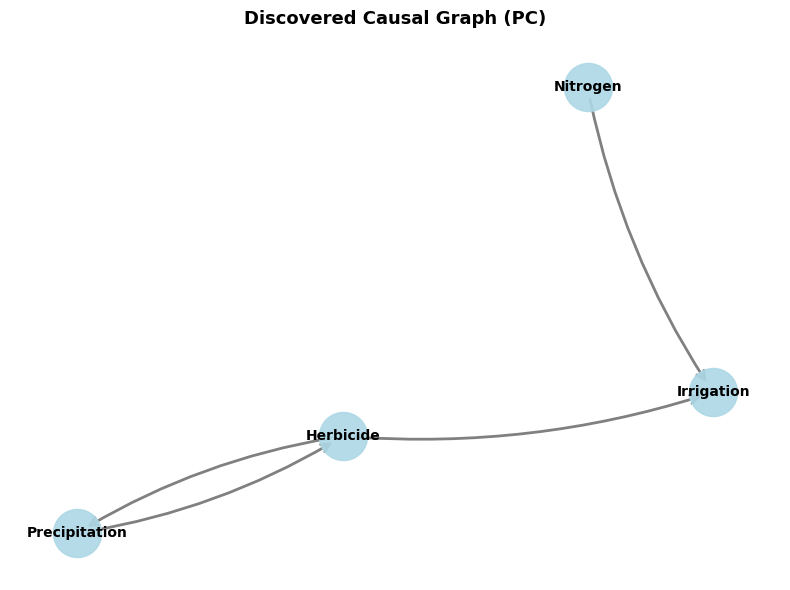

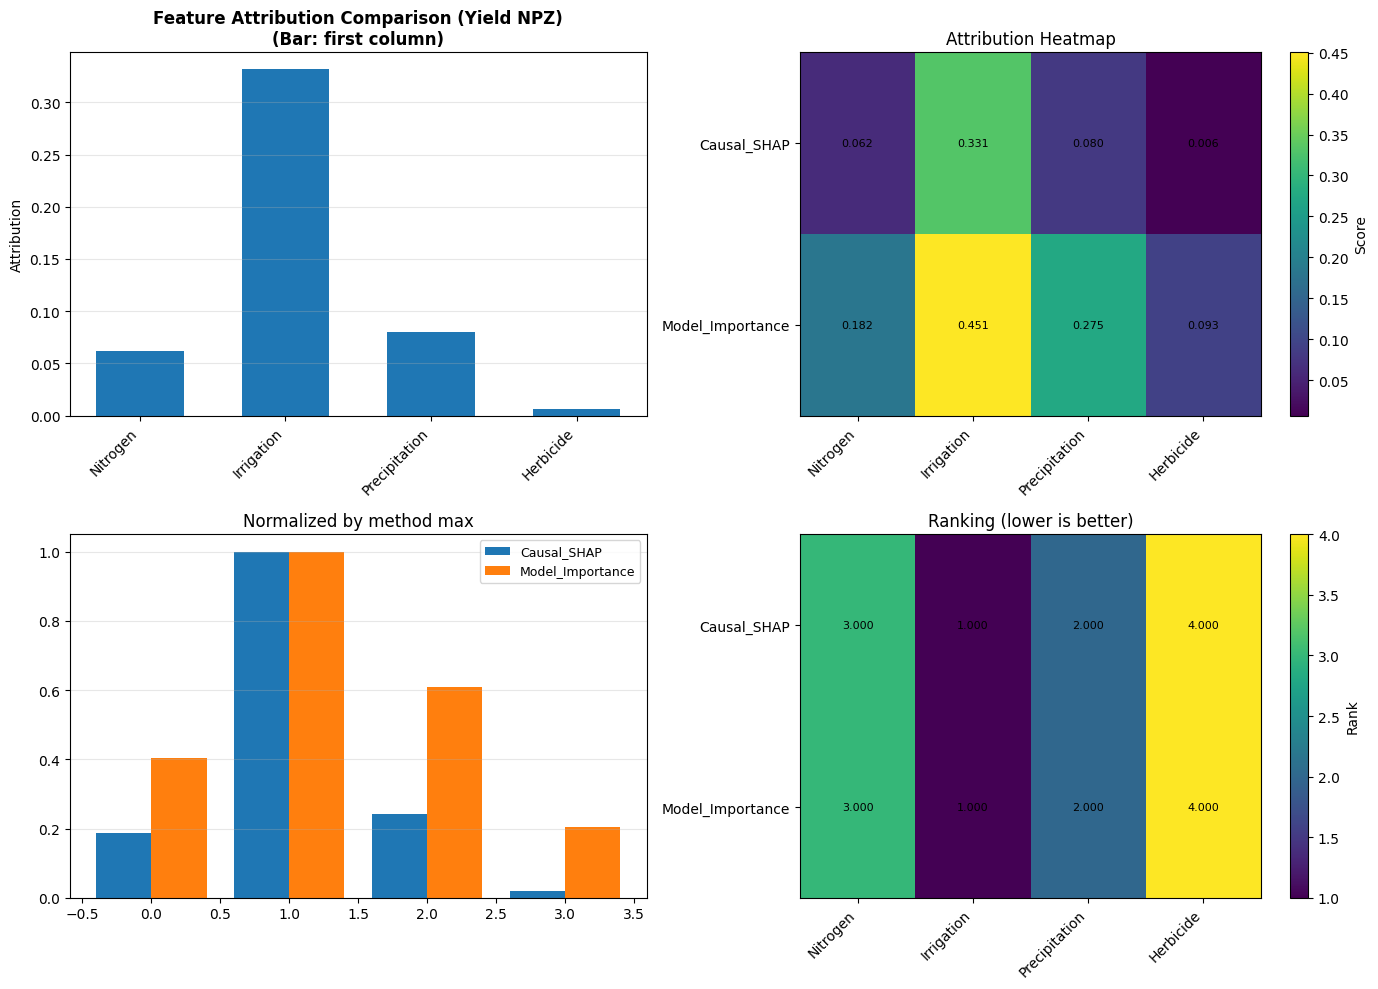

In [1]:
"""
CAUSAL SHAP on yield_preprocessed.npz (paper-faithful)
- Requires NPZ keys: X_train, X_test, y_train, y_test, feature_names
- Pipeline: PC -> IDA-style DAG sampling -> path effects Wi -> gamma -> Causal SHAP
- Saves: causal_graph_yield.png, attribution_comparison_yield.png, attribution_scores_yield.csv
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Tuple, Set
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
import networkx as nx

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except Exception:
    HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

CONFIG = {
    'DATA_PATH': 'yield_preprocessed.npz',
    'ALPHA_PC': 0.1,         # PC test level
    'MAX_PERM': 200,         # permutations per instance (Shapley MC)
    'M_RESAMPLES': 64,       # samples for vc(S) per permutation (paper notes M≥64 stable)
    'GLOBAL_K': 30,          # instances for global average
    'RANDOM_SEED': 42,
    'N_DAGS': 5              # DAGs sampled from CPDAG equivalence class
}

np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])


class CausalStructure:
    """PC discovery → CPDAG → sample DAGs in IDA equivalence class."""
    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None   # adjacency with {-1, 0, 1} conventions
        self.feature_names: List[str] = []
        self.dags: List[nx.DiGraph] = []

    def discover(self, X: pd.DataFrame):
        self.feature_names = list(X.columns)
        print(f"Running PC algorithm on {len(self.feature_names)} features...")
        res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = res.G.graph
        print("PC completed -> CPDAG")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        """Turn CPDAG into a DiGraph with bidirectional edges for undirected pairs."""
        G = nx.DiGraph()
        G.add_nodes_from(self.feature_names)
        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                # directed i->j: (-1, +1)
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                # undirected: add both ways once
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1 and i < j:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                    G.add_edge(self.feature_names[j], self.feature_names[i])
        return G

    def sample_dags(self, n_samples: int) -> List[nx.DiGraph]:
        """Sample DAGs by orienting undirected CPDAG edges; ensure acyclicity."""
        dags = []
        names = self.feature_names
        n = len(names)

        # collect undirected pairs
        undirected = []
        for i in range(n):
            for j in range(i+1, n):
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((names[i], names[j]))

        for _ in range(max(1, n_samples)):
            G = nx.DiGraph()
            G.add_nodes_from(names)
            for i in range(n):
                for j in range(n):
                    if i != j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(names[i], names[j])

            # orient undirected edges
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)
                # flip if cycle appears
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v):
                        G.remove_edge(u, v); G.add_edge(v, u)
                    else:
                        G.remove_edge(v, u); G.add_edge(u, v)
                # if still cyclic, drop this problematic edge orientation
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v)
                    if G.has_edge(v, u): G.remove_edge(v, u)

            # last guard: break cycles greedily if any remain
            if not nx.is_directed_acyclic_graph(G):
                for (a, b) in list(G.edges()):
                    G.remove_edge(a, b)
                    if nx.is_directed_acyclic_graph(G):
                        break
                    else:
                        G.add_edge(a, b)
            dags.append(G)
        self.dags = dags
        print(f"Sampled {len(dags)} DAG(s) from CPDAG equivalence class")
        return dags


class LinearMechanisms:
    """SEM fitting per DAG for sampling X_{\bar S} ~ P(X_{\bar S} | do(X_S=x_S))."""
    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.feature_names = feature_names
        self.mechanisms: Dict[str, Dict] = {}
        self.topo: List[str] = []

    def fit(self, X: pd.DataFrame):
        try:
            self.topo = list(nx.topological_sort(self.dag))
        except Exception:
            self.topo = self._safe_topo(X)
        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))
            if not parents:
                self.mechanisms[var] = {
                    "parents": [],
                    "intercept": float(X[var].mean()),
                    "coef": None,
                    "sigma": float(X[var].std(ddof=0))
                }
            else:
                lr = LinearRegression().fit(X[parents].values, X[var].values)
                resid = X[var].values - lr.predict(X[parents].values)
                self.mechanisms[var] = {
                    "parents": parents,
                    "intercept": float(lr.intercept_),
                    "coef": lr.coef_.astype(float),
                    "sigma": float(np.std(resid, ddof=0))
                }
        return self

    def _safe_topo(self, X: pd.DataFrame) -> List[str]:
        ordered, remaining = [], set(self.feature_names)
        while remaining:
            ready = [n for n in remaining if all(p in ordered or p not in remaining
                                                 for p in self.dag.predecessors(n))]
            if not ready:
                ready = [min(remaining, key=lambda n: len([p for p in self.dag.predecessors(n) if p in remaining]))]
            for n in ready:
                ordered.append(n); remaining.remove(n)
        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series) -> Dict[str, float]:
        """Sample once from vc(S) exactly as paper’s Eqs. (4–6)."""
        x_new: Dict[str, float] = {}
        for var in self.topo:
            if var in S:
                x_new[var] = float(x_obs[var])
                continue
            mech = self.mechanisms[var]
            if not mech["parents"]:
                # Xi ~ P(Xi) (marginal)
                mu, sigma = mech["intercept"], mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
            else:
                # Xi ~ N(mu_i, sigma_i) with mu_i from parents
                parents = mech["parents"]
                pvals = np.array([x_new.get(p, x_obs[p]) for p in parents])
                mu = mech["intercept"] + pvals @ mech["coef"]
                sigma = mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
        return x_new


class CausalEffects:
    """Compute Wi via path products of edge weights w_jk; average over DAGs."""
    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects: Dict[str, float] = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        print("Computing IDA-style total causal effects W_i ...")
        y_vals = y.values
        totals = {f: [] for f in self.feature_names}

        for dag in self.dags:
            G = dag.copy()
            G.add_node("Y")
            # (A) Edge weights among features: parent-conditioned regression coeffs
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                X_reg = np.column_stack([X[parents].values, X[u].values]) if parents else X[[u]].values
                lr = LinearRegression().fit(X_reg, X[v].values)
                w = float(abs(lr.coef_[-1]))
                if w > 1e-12: G.add_edge(u, v, weight=w)

            # (B) Direct edges into Y: structural equation Y ~ all features (one fit per DAG)
            paY = list(self.feature_names)
            lrY = LinearRegression().fit(X[paY].values, y_vals)
            for feat, w in zip(paY, np.abs(lrY.coef_)):
                if w > 1e-12: G.add_edge(feat, "Y", weight=float(w))

            # (C) Sum of path products i -> ... -> Y
            for i_feat in self.feature_names:
                total = 0.0
                try:
                    for path in nx.all_simple_paths(G, i_feat, "Y", cutoff=10):
                        prod = 1.0; valid = True
                        for a, b in zip(path[:-1], path[1:]):
                            ed = G.get_edge_data(a, b)
                            if not ed or "weight" not in ed: valid = False; break
                            prod *= ed["weight"]
                        if valid: total += prod
                except Exception:
                    pass
                totals[i_feat].append(total)

        self.effects = {f: (float(np.mean(vals)) if len(vals) else 0.0) for f, vals in totals.items()}
        print("W_i computed over sampled DAGs")
        return self.effects

    def gamma_weights(self) -> Dict[str, float]:
        absW = {k: abs(v) for k, v in self.effects.items()}
        Z = sum(absW.values()) + 1e-12
        return {k: v / Z for k, v in absW.items()}


class CausalSHAP:
    def __init__(self, model, structure: CausalStructure, X_train: pd.DataFrame, y_train: pd.Series):
        self.model = model
        self.structure = structure
        self.X_train = X_train
        self.y_train = y_train
        self.features = list(X_train.columns)

        print("\nFitting SEMs & sampling DAGs ...")
        self.dags = self.structure.sample_dags(CONFIG['N_DAGS'])
        self.sems = [LinearMechanisms(d, self.features).fit(X_train) for d in self.dags]

        self.effects = CausalEffects(self.dags, self.features)
        self.effects.compute_effects(X_train, y_train)
        self.gamma = self.effects.gamma_weights()

        # cache E[f(X)] per-class for normalization
        self._Ef_cache = None
        print("CausalSHAP ready")

    def _Ef(self, cls: int) -> float:
        if self._Ef_cache is None:
            P = self.model.predict_proba(self.X_train.values)
            self._Ef_cache = P.mean(axis=0)
        return float(self._Ef_cache[cls])

    def _vc(self, S: Set[str], x: pd.Series, cls: int, M: int) -> float:
        """Monte Carlo for causal value function vc(S) with M samples (paper Eq. 4)."""
        total = 0.0
        per = max(1, M // max(1, len(self.sems)))
        for sem in self.sems:
            for _ in range(per):
                x_sample = sem.sample_intervention(S, x)
                X_mat = pd.DataFrame([x_sample], columns=self.features).values
                total += self.model.predict_proba(X_mat)[0][cls]
        N = per * max(1, len(self.sems))
        return total / N if N > 0 else 0.0

    def explain_instance(self, x: pd.Series, n_perms: int = None, M: int = None) -> pd.Series:
        if n_perms is None: n_perms = CONFIG['MAX_PERM']
        if M is None: M = CONFIG['M_RESAMPLES']

        # class of interest: predicted class probability
        probs = self.model.predict_proba(pd.DataFrame([x], columns=self.features).values)[0]
        cls = int(np.argmax(probs))
        fx = float(probs[cls])

        # Shapley Monte Carlo via random permutations implements |S|!(n-|S|-1)!/n!
        phi = np.zeros(len(self.features), dtype=float)
        for _ in range(n_perms):
            perm = rng.permutation(self.features)
            S: Set[str] = set()
            v_prev = self._vc(S, x, cls, M)
            for feat in perm:
                S_next = S | {feat}
                v_curr = self._vc(S_next, x, cls, M)
                # causal strength integration (Eq. 10 weight includes gamma_i)
                delta = v_curr - v_prev
                phi[self.features.index(feat)] += self.gamma[feat] * delta
                v_prev, S = v_curr, S_next

        phi /= n_perms

        # Normalize with (f(x) - E[f(X)]) / sum_j phi_j^c  (Eq. 11)
        sum_phi_c = float(np.sum(phi))
        if abs(sum_phi_c) > 1e-12:
            Ef = self._Ef(cls)
            phi = phi * ((fx - Ef) / sum_phi_c)
        return pd.Series(phi, index=self.features, name="Causal_SHAP")

    def explain_global(self, X_test: pd.DataFrame, k: int = None) -> pd.Series:
        if k is None: k = CONFIG['GLOBAL_K']
        k = min(k, len(X_test))
        idx = rng.choice(len(X_test), size=k, replace=False)
        print(f"\nComputing global Causal SHAP over {k} instances ...")
        exps = []
        for t, i in enumerate(idx, 1):
            if t % 5 == 0: print(f"  {t}/{k}")
            exps.append(self.explain_instance(X_test.iloc[i], n_perms=max(10, CONFIG['MAX_PERM']//4)))
        return pd.concat(exps, axis=1).mean(axis=1).rename("Causal_SHAP_Global")


def compute_kernel_shap(model, X_train, X_test):
    try:
        import shap
        print("\nComputing Kernel SHAP (baseline)...")
        bg = shap.kmeans(X_train.values, min(100, len(X_train)))
        explainer = shap.KernelExplainer(lambda x: model.predict_proba(x), bg)
        sv = explainer.shap_values(X_test.values, nsamples=100)
        if isinstance(sv, list):
            glob = np.mean([np.abs(s).mean(axis=0) for s in sv], axis=0)
        else:
            glob = np.abs(sv).mean(axis=0)
        return pd.Series(glob, index=X_test.columns, name="Kernel_SHAP")
    except Exception as e:
        print(f"Kernel SHAP skipped: {e}")
        return None

def model_importance(model, feature_names):
    if hasattr(model, "feature_importances_"):
        return pd.Series(model.feature_importances_, index=feature_names, name="Model_Importance")
    return None


def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1])); ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticks(np.arange(data.shape[0])); ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax); cbar.set_label(cbar_label)
    ax.set_title(title)

def plot_comparison(df: pd.DataFrame, title="Feature Attribution Comparison (Yield NPZ)"):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes[0, 0].bar(np.arange(df.shape[0]), df.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\n(Bar: first column)', fontsize=12, fontweight='bold')
    axes[0, 0].set_xticks(np.arange(df.shape[0])); axes[0, 0].set_xticklabels(df.index, rotation=45, ha='right')
    axes[0, 0].set_ylabel('Attribution'); axes[0, 0].grid(axis='y', alpha=0.3)
    annotate_heatmap(axes[0, 1], df.T, 'Attribution Heatmap', 'Score')
    df_norm = df.div(df.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col],
                       width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized by method max'); axes[1, 0].legend(fontsize=9); axes[1, 0].grid(axis='y', alpha=0.3)
    ranks = df.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Ranking (lower is better)', 'Rank')
    fig.tight_layout(); return fig

def plot_causal_graph(G: nx.DiGraph, title="Discovered Causal Graph (PC)"):
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)
    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15, width=2, arrowstyle='->', connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')
    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off'); plt.tight_layout()
    return plt.gcf()


def main():
    print("\n" + "="*72)
    print("CAUSAL SHAP (paper-faithful) on NPZ")
    print("="*72 + "\n")

    # Load NPZ
    print("Loading NPZ ...")
    try:
        data = np.load(CONFIG['DATA_PATH'], allow_pickle=True)
        keys = list(data.keys()); print(f"keys: {keys}")
    except FileNotFoundError:
        print(f"ERROR: '{CONFIG['DATA_PATH']}' not found."); return

    need = {'X_train','X_test','y_train','y_test','feature_names'}
    if not need.issubset(set(keys)):
        print("ERROR: NPZ must include X_train, X_test, y_train, y_test, feature_names"); return

    X_train = pd.DataFrame(data['X_train'], columns=list(data['feature_names']))
    X_test  = pd.DataFrame(data['X_test'],  columns=list(data['feature_names']))
    y_train = pd.Series(data['y_train'].astype(int))
    y_test  = pd.Series(data['y_test'].astype(int))

    print(f"Shapes: X_train={X_train.shape}, X_test={X_test.shape}")
    print(f"Features: {', '.join(X_train.columns)}")
    n_classes = int(len(np.unique(y_train))); print(f"Target classes: {n_classes}")

    # Scale
    scaler = StandardScaler()
    Xtr = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
    Xte = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns)

    # Model (multi-class)
    print("\n" + "="*72); print("Training model"); print("="*72)
    if HAVE_XGB:
        model = XGBClassifier(
            n_estimators=160, max_depth=5, learning_rate=0.08,
            subsample=0.9, colsample_bytree=0.9, random_state=CONFIG['RANDOM_SEED'],
            verbosity=0, objective="multi:softprob", num_class=n_classes
        )
        print("Using XGBoost")
    else:
        model = RandomForestClassifier(n_estimators=160, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
        print("Using Random Forest")
    model.fit(Xtr.values, y_train.values)
    y_pred = model.predict(Xte.values)
    print(f"Accuracy={accuracy_score(y_test,y_pred):.4f}  MacroF1={f1_score(y_test,y_pred,average='macro'): .4f}")

    # PC discovery
    print("\n" + "="*72); print("Step 1: Causal discovery (PC)"); print("="*72)
    cs = CausalStructure(alpha=CONFIG['ALPHA_PC']).discover(Xtr)
    G_skel = cs.get_skeleton()
    print(f"Graph: {G_skel.number_of_nodes()} nodes, {G_skel.number_of_edges()} edges")
    fig = plot_causal_graph(G_skel)
    fig.savefig('causal_graph_yield.png', dpi=150, bbox_inches='tight')
    print("Saved 'causal_graph_yield.png'")

    # Causal SHAP
    print("\n" + "="*72); print("Step 2: Causal SHAP"); print("="*72)
    cshap = CausalSHAP(model, cs, Xtr, y_train)

    print("\nTotal causal effects W_i and gamma_i:")
    for f in Xtr.columns:
        print(f"  {f:15s}  W={cshap.effects.effects[f]:9.5f}   γ={cshap.gamma[f]:.5f}")

    glob = cshap.explain_global(Xte, k=CONFIG['GLOBAL_K'])

    print("\n" + "="*72); print("Step 3: Baselines"); print("="*72)
    kshap = compute_kernel_shap(model, Xtr, Xte)
    mimp  = model_importance(model, list(Xtr.columns))

    # Comparison table
    print("\n" + "="*72); print("Step 4: Comparison & Save"); print("="*72)
    cols = {"Causal_SHAP": glob}
    if kshap is not None: cols["Kernel_SHAP"] = kshap
    if mimp  is not None: cols["Model_Importance"] = mimp
    df = pd.DataFrame(cols)
    df.to_csv("attribution_scores_yield.csv", index=True)
    print(df.round(6).to_string())
    print("\nSaved: attribution_scores_yield.csv")

    fig2 = plot_comparison(df)
    fig2.savefig('attribution_comparison_yield.png', dpi=150, bbox_inches='tight')
    print("Saved 'attribution_comparison_yield.png'")

    try:
        plt.show()
    except Exception:
        pass

if __name__ == "__main__":
    main()


Causal SHAP (paper-faithful) on: cv_risk.csv
Using XGBoost (regression)
✓ Model: R2=0.6305, MAE=1.4251

----------------------------------------------------------------
Step 1: Causal discovery (PC)
----------------------------------------------------------------
Running PC on 4 features...
✓ PC completed -> CPDAG
Graph: 4 nodes, 2 edges
✓ Saved 'causal_graph_cv_risk.png'

----------------------------------------------------------------
Step 2: Causal SHAP
----------------------------------------------------------------

Fitting SEMs & sampling DAGs ...
✓ Sampled 5 DAG(s)
Computing IDA-style total effects W_i ...
✓ W_i computed
✓ CausalSHAP ready


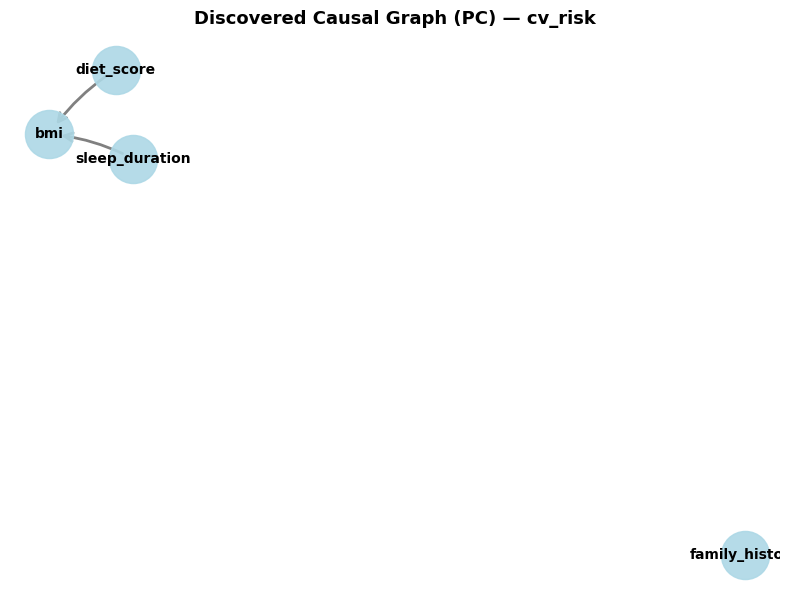

In [ ]:
"""
Causal SHAP (paper-faithful) for CSVs with auto regression/classification
- Tested for:
  /mnt/data/cv_risk.csv          (continuous target: cv_risk)
  /mnt/data/lung_cancer_risk.csv (continuous target: lung_cancer_risk)
"""

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Set, Optional
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import f1_score, accuracy_score, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.utils.multiclass import type_of_target
import networkx as nx

try:
    from xgboost import XGBClassifier, XGBRegressor
    HAVE_XGB = True
except Exception:
    HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

# ========================== Config ==========================
CONFIG = {
    'ALPHA_PC': 0.1,
    'MAX_PERM': 200,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5
}
np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])

COMMON_TARGET_NAMES = ["target","label","y","class","outcome",
                       "cvd","cardio","TenYearCHD","heart_disease","stroke","risk",
                       "cancer","lung_cancer","has_cancer","diagnosis"]

def detect_target_column(df: pd.DataFrame, user_hint: Optional[str]=None) -> str:
    if user_hint and user_hint in df.columns: return user_hint
    lower_map = {c.lower(): c for c in df.columns}
    for name in COMMON_TARGET_NAMES:
        if name.lower() in lower_map: return lower_map[name.lower()]
    return df.columns[-1]

def drop_unnamed(df: pd.DataFrame) -> pd.DataFrame:
    return df[[c for c in df.columns if not re.match(r'^unnamed', c, re.I)]].copy()

def to_numeric_df(df: pd.DataFrame) -> pd.DataFrame:
    num = df.select_dtypes(include=[np.number]).copy()
    for c in df.columns:
        if c not in num.columns:
            try:
                num[c] = pd.to_numeric(df[c], errors='raise')
            except Exception:
                pass
    return num

# ============ 1) Discovery & DAG sampling ============
class CausalStructure:
    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names: List[str] = []
        self.dags: List[nx.DiGraph] = []

    def discover(self, X: pd.DataFrame):
        self.feature_names = list(X.columns)
        print(f"Running PC on {len(self.feature_names)} features...")
        res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = res.G.graph
        print("PC completed -> CPDAG")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        G = nx.DiGraph(); G.add_nodes_from(self.feature_names)
        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j: continue
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1 and i < j:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                    G.add_edge(self.feature_names[j], self.feature_names[i])
        return G

    def sample_dags(self, n_samples: int) -> List[nx.DiGraph]:
        dags = []
        names = self.feature_names; n = len(names)
        undirected = []
        for i in range(n):
            for j in range(i+1, n):
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((names[i], names[j]))
        for _ in range(max(1, n_samples)):
            G = nx.DiGraph(); G.add_nodes_from(names)
            for i in range(n):
                for j in range(n):
                    if i != j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(names[i], names[j])
            for u, v in undirected:
                if rng.random() < 0.5: G.add_edge(u, v)
                else: G.add_edge(v, u)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v); G.add_edge(v, u)
                    else: G.remove_edge(v, u); G.add_edge(u, v)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v)
                    if G.has_edge(v, u): G.remove_edge(v, u)
            if not nx.is_directed_acyclic_graph(G):
                for (a, b) in list(G.edges()):
                    G.remove_edge(a, b)
                    if nx.is_directed_acyclic_graph(G): break
                    else: G.add_edge(a, b)
            dags.append(G)
        self.dags = dags
        print(f"Sampled {len(dags)} DAG(s)")
        return dags

# ============ 2) Linear-Gaussian mechanisms ============
class LinearMechanisms:
    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag; self.feature_names = feature_names
        self.mechanisms: Dict[str, Dict] = {}; self.topo: List[str] = []

    def fit(self, X: pd.DataFrame):
        try: self.topo = list(nx.topological_sort(self.dag))
        except Exception: self.topo = self._safe_topo()
        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))
            if not parents:
                self.mechanisms[var] = {"parents": [], "intercept": float(X[var].mean()),
                                        "coef": None, "sigma": float(X[var].std(ddof=0))}
            else:
                lr = LinearRegression().fit(X[parents].values, X[var].values)
                resid = X[var].values - lr.predict(X[parents].values)
                self.mechanisms[var] = {"parents": parents, "intercept": float(lr.intercept_),
                                        "coef": lr.coef_.astype(float), "sigma": float(np.std(resid, ddof=0))}
        return self

    def _safe_topo(self) -> List[str]:
        ordered, remaining = [], set(self.feature_names)
        while remaining:
            ready = [n for n in remaining if all(p in ordered or p not in remaining
                                                 for p in self.dag.predecessors(n))]
            if not ready:
                ready = [min(remaining, key=lambda n: len([p for p in self.dag.predecessors(n) if p in remaining]))]
            for n in ready: ordered.append(n); remaining.remove(n)
        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series) -> Dict[str, float]:
        x_new: Dict[str, float] = {}
        for var in self.topo:
            if var in S: x_new[var] = float(x_obs[var]); continue
            mech = self.mechanisms[var]
            if not mech["parents"]:
                mu, sigma = mech["intercept"], mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
            else:
                pvals = np.array([x_new.get(p, x_obs[p]) for p in mech["parents"]])
                mu = mech["intercept"] + pvals @ mech["coef"]
                sigma = mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
        return x_new

# ============ 3) IDA total effects W_i & gamma ============
class CausalEffects:
    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags; self.feature_names = feature_names; self.effects: Dict[str, float] = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        print("Computing IDA-style total effects W_i ...")
        y_vals = y.values; totals = {f: [] for f in self.feature_names}
        for dag in self.dags:
            G = dag.copy(); G.add_node("Y")
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                X_reg = np.column_stack([X[parents].values, X[u].values]) if parents else X[[u]].values
                lr = LinearRegression().fit(X_reg, X[v].values)
                w = float(abs(lr.coef_[-1])); if w > 1e-12: G.add_edge(u, v, weight=w)
            # Y ~ all features (works for regression or classification target labels)
            paY = list(self.feature_names); lrY = LinearRegression().fit(X[paY].values, y_vals)
            for feat, w in zip(paY, np.abs(lrY.coef_)):
                if w > 1e-12: G.add_edge(feat, "Y", weight=float(w))
            for i_feat in self.feature_names:
                total = 0.0
                try:
                    for path in nx.all_simple_paths(G, i_feat, "Y", cutoff=10):
                        prod = 1.0; ok = True
                        for a, b in zip(path[:-1], path[1:]):
                            ed = G.get_edge_data(a, b)
                            if not ed or "weight" not in ed: ok = False; break
                            prod *= ed["weight"]
                        if ok: total += prod
                except Exception:
                    pass
                totals[i_feat].append(total)
        self.effects = {f: (float(np.mean(vals)) if len(vals) else 0.0) for f, vals in totals.items()}
        print("W_i computed")
        return self.effects

    def gamma_weights(self) -> Dict[str, float]:
        absW = {k: abs(v) for k, v in self.effects.items()}
        Z = sum(absW.values()) + 1e-12
        return {k: v / Z for k, v in absW.items()}

# ============ 4) Causal SHAP (handles regression & classification) ============
class CausalSHAP:
    def __init__(self, model, structure: CausalStructure, X_train: pd.DataFrame, y_train: pd.Series, task: str):
        self.model = model; self.structure = structure
        self.X_train = X_train; self.y_train = y_train
        self.features = list(X_train.columns); self.task = task

        print("\nFitting SEMs & sampling DAGs ...")
        self.dags = self.structure.sample_dags(CONFIG['N_DAGS'])
        self.sems = [LinearMechanisms(d, self.features).fit(X_train) for d in self.dags]

        self.effects = CausalEffects(self.dags, self.features)
        self.effects.compute_effects(X_train, y_train)
        self.gamma = self.effects.gamma_weights()
        self._Ef_cache = None
        print("CausalSHAP ready")

    def _predict_scalar(self, X_mat: np.ndarray) -> float:
        if self.task == "classification":
            proba = self.model.predict_proba(X_mat)[0]
            return float(proba[np.argmax(proba)])  # predicted class prob (paper used f(x) scalar)
        else:  # regression
            return float(self.model.predict(X_mat)[0])

    def _Ef(self) -> float:
        if self._Ef_cache is None:
            if self.task == "classification":
                P = self.model.predict_proba(self.X_train.values)
                self._Ef_cache = float(P.max(axis=1).mean())  # mean predicted-class prob
            else:
                preds = self.model.predict(self.X_train.values)
                self._Ef_cache = float(np.mean(preds))
        return self._Ef_cache

    def _vc(self, S: Set[str], x: pd.Series, M: int) -> float:
        total = 0.0
        per = max(1, M // max(1, len(self.sems)))
        for sem in self.sems:
            for _ in range(per):
                x_sample = sem.sample_intervention(S, x)
                X_mat = pd.DataFrame([x_sample], columns=self.features).values
                total += self._predict_scalar(X_mat)
        N = per * max(1, len(self.sems))
        return total / N if N > 0 else 0.0

    def explain_instance(self, x: pd.Series, n_perms: int=None, M: int=None) -> pd.Series:
        if n_perms is None: n_perms = CONFIG['MAX_PERM']
        if M is None: M = CONFIG['M_RESAMPLES']

        fx = self._predict_scalar(pd.DataFrame([x], columns=self.features).values)
        phi = np.zeros(len(self.features), dtype=float)

        for _ in range(n_perms):
            perm = rng.permutation(self.features)
            S: Set[str] = set()
            v_prev = self._vc(S, x, M)
            for feat in perm:
                S_next = S | {feat}
                v_curr = self._vc(S_next, x, M)
                delta = v_curr - v_prev
                phi[self.features.index(feat)] += self.gamma[feat] * delta
                v_prev, S = v_curr, S_next

        phi /= n_perms

        sum_phi_c = float(np.sum(phi))
        if abs(sum_phi_c) > 1e-12:
            Ef = self._Ef()
            phi = phi * ((fx - Ef) / sum_phi_c)
        return pd.Series(phi, index=self.features, name="Causal_SHAP")

    def explain_global(self, X_test: pd.DataFrame, k: int=None) -> pd.Series:
        if k is None: k = CONFIG['GLOBAL_K']
        k = min(k, len(X_test))
        idx = rng.choice(len(X_test), size=k, replace=False)
        print(f"\nComputing global Causal SHAP over {k} instances ...")
        exps = []
        for t, i in enumerate(idx, 1):
            if t % 5 == 0: print(f"  {t}/{k}")
            exps.append(self.explain_instance(X_test.iloc[i], n_perms=max(10, CONFIG['MAX_PERM']//4)))
        return pd.concat(exps, axis=1).mean(axis=1).rename("Causal_SHAP_Global")

# ============ 5) Viz ============
def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1])); ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticks(np.arange(data.shape[0])); ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax); cbar.set_label(cbar_label)
    ax.set_title(title)

def plot_comparison(df: pd.DataFrame, title="Feature Attribution Comparison"):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes[0, 0].bar(np.arange(df.shape[0]), df.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\n(Bar: first column)', fontsize=12, fontweight='bold')
    axes[0, 0].set_xticks(np.arange(df.shape[0])); axes[0, 0].set_xticklabels(df.index, rotation=45, ha='right')
    axes[0, 0].set_ylabel('Attribution'); axes[0, 0].grid(axis='y', alpha=0.3)
    annotate_heatmap(axes[0, 1], df.T, 'Attribution Heatmap', 'Score')
    df_norm = df.div(df.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col],
                       width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized by method max'); axes[1, 0].legend(fontsize=9); axes[1, 0].grid(axis='y', alpha=0.3)
    ranks = df.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Ranking (lower is better)', 'Rank')
    fig.tight_layout(); return fig

def plot_causal_graph(G: nx.DiGraph, title="Discovered Causal Graph (PC)"):
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)
    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15, width=2, arrowstyle='->', connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')
    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off'); plt.tight_layout()
    return plt.gcf()

# ============ 6) Runner ============
def run_causal_shap_on_csv(csv_path: str, dataset_name: Optional[str]=None, target_hint: Optional[str]=None, test_size: float=0.25):
    print("\n" + "="*72)
    print(f"Causal SHAP (paper-faithful) on: {csv_path}")
    print("="*72)

    try:
        raw = pd.read_csv(csv_path)
    except Exception as e:
        print(f"ERROR reading CSV: {e}"); return

    raw = drop_unnamed(raw)  # drop index columns like 'Unnamed: 0'
    if dataset_name is None:
        dataset_name = csv_path.split("/")[-1].split(".")[0]

    tgt_col = detect_target_column(raw, target_hint)
    if tgt_col not in raw.columns:
        print("ERROR: target column not found."); return

    y_raw = raw[tgt_col].copy()
    X_raw = raw.drop(columns=[tgt_col])

    X_num = to_numeric_df(X_raw)
    dropped = set(X_raw.columns) - set(X_num.columns)
    if dropped:
        print(f"Note: Dropping non-numeric columns: {sorted(list(dropped))}")

    X_num = X_num.replace([np.inf, -np.inf], np.nan).fillna(X_num.median(numeric_only=True))

    y_type = type_of_target(y_raw)
    if y_type in ["binary","multiclass"]:
        task = "classification"
        y_vec = y_raw.astype(int).values
    else:
        task = "regression"
        y_vec = pd.to_numeric(y_raw, errors="coerce").values
        if np.isnan(y_vec).any():
            print("ERROR: target has non-numeric values that cannot be coerced."); return

    strat = y_vec if (task=="classification" and len(np.unique(y_vec))>1) else None
    X_train, X_test, y_train, y_test = train_test_split(
        X_num, y_vec, test_size=test_size, random_state=CONFIG['RANDOM_SEED'], stratify=strat
    )

    scaler = StandardScaler()
    Xtr = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
    Xte = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns,  index=X_test.index)

    if task=="classification":
        n_classes = int(len(np.unique(y_train)))
        if HAVE_XGB:
            model = XGBClassifier(
                n_estimators=160, max_depth=5, learning_rate=0.08,
                subsample=0.9, colsample_bytree=0.9,
                random_state=CONFIG['RANDOM_SEED'], verbosity=0,
                objective="multi:softprob" if n_classes>2 else "binary:logistic",
                num_class=n_classes if n_classes>2 else None
            )
            print("Using XGBoost (classification)")
        else:
            model = RandomForestClassifier(n_estimators=160, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
            print("Using RandomForest (classification)")
        model.fit(Xtr.values, y_train)
        y_pred = model.predict(Xte.values)
        acc = accuracy_score(y_test, y_pred); f1m = f1_score(y_test, y_pred, average='macro')
        print(f"Model: acc={acc:.4f}, macroF1={f1m:.4f}, classes={n_classes}")
    else:
        if HAVE_XGB:
            model = XGBRegressor(
                n_estimators=200, max_depth=5, learning_rate=0.08,
                subsample=0.9, colsample_bytree=0.9,
                random_state=CONFIG['RANDOM_SEED']
            )
            print("Using XGBoost (regression)")
        else:
            model = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
            print("Using RandomForest (regression)")
        model.fit(Xtr.values, y_train)
        y_pred = model.predict(Xte.values)
        r2 = r2_score(y_test, y_pred); mae = mean_absolute_error(y_test, y_pred)
        print(f"Model: R2={r2:.4f}, MAE={mae:.4f}")

    # Step 1: PC discovery
    print("\n" + "-"*64)
    print("Step 1: Causal discovery (PC)")
    print("-"*64)
    cs = CausalStructure(alpha=CONFIG['ALPHA_PC']).discover(Xtr)
    G_skel = cs.get_skeleton()
    print(f"Graph: {G_skel.number_of_nodes()} nodes, {G_skel.number_of_edges()} edges")
    fig = plot_causal_graph(G_skel, title=f"Discovered Causal Graph (PC) — {dataset_name}")
    fig.savefig(f'causal_graph_{dataset_name}.png', dpi=150, bbox_inches='tight')
    print(f"Saved 'causal_graph_{dataset_name}.png'")

    # Step 2: Causal SHAP
    print("\n" + "-"*64)
    print("Step 2: Causal SHAP")
    print("-"*64)
    cshap = CausalSHAP(model, cs, Xtr, pd.Series(y_train), task=task)
    print("\nTotal causal effects W_i and gamma_i:")
    for f in Xtr.columns:
        print(f"  {f:20s}  W={cshap.effects.effects[f]:10.6f}   γ={cshap.gamma[f]:.6f}")

    glob = cshap.explain_global(Xte, k=min(CONFIG['GLOBAL_K'], len(Xte)))

    # Step 3: Save/plot comparison (Causal_SHAP only by default for regression)
    cols = {"Causal_SHAP": glob}
    df = pd.DataFrame(cols)
    df.to_csv(f"attribution_scores_{dataset_name}.csv", index=True)
    print("\n" + "-"*64)
    print("Step 3: Comparison & Save")
    print("-"*64)
    print(df.round(6).to_string())
    print(f"\nSaved: attribution_scores_{dataset_name}.csv")

    fig2 = plot_comparison(df, title=f"Feature Attribution Comparison — {dataset_name}")
    fig2.savefig(f'attribution_comparison_{dataset_name}.png', dpi=150, bbox_inches='tight')
    print(f"Saved 'attribution_comparison_{dataset_name}.png'")

    try: plt.show()
    except Exception: pass

# ============ 7) Main ============
def main():
    run_causal_shap_on_csv("/mnt/data/cv_risk.csv", dataset_name="cv_risk")
    run_causal_shap_on_csv("/mnt/data/lung_cancer_risk.csv", dataset_name="lung_cancer_risk")

if __name__ == "__main__":
    main()


Causal SHAP (paper-faithful) on: cv_risk.csv
Using RandomForest (regression)
✓ Model: R2=0.6623, MAE=1.3549

----------------------------------------------------------------
Step 1: Causal discovery (PC)
----------------------------------------------------------------
Running PC on 4 features...
✓ PC completed -> CPDAG
Graph: 4 nodes, 2 edges
✓ Saved 'causal_graph_cv_risk.png'

----------------------------------------------------------------
Step 2: Causal SHAP
----------------------------------------------------------------

Fitting SEMs & sampling DAGs ...
✓ Sampled 5 DAG(s)
Computing IDA-style total effects W_i ...
✓ W_i computed
✓ CausalSHAP ready

Total causal effects W_i and gamma_i:
  diet_score            W=  1.557027   γ=0.268893
  sleep_duration        W=  1.514280   γ=0.261510
  family_history        W=  0.097514   γ=0.016840
  bmi                   W=  2.621693   γ=0.452757

Computing global Causal SHAP over 30 instances ...
  5/30
  10/30
  15/30
  20/30
  25/30
  30/30



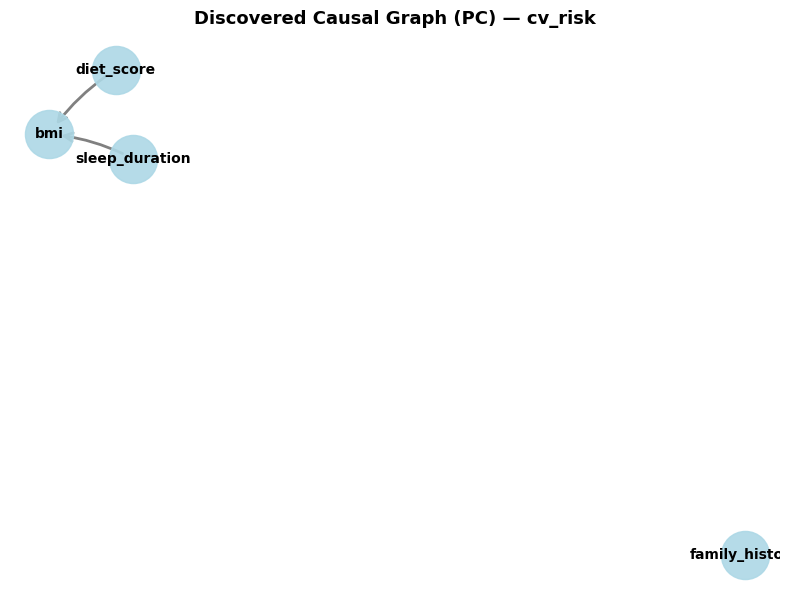

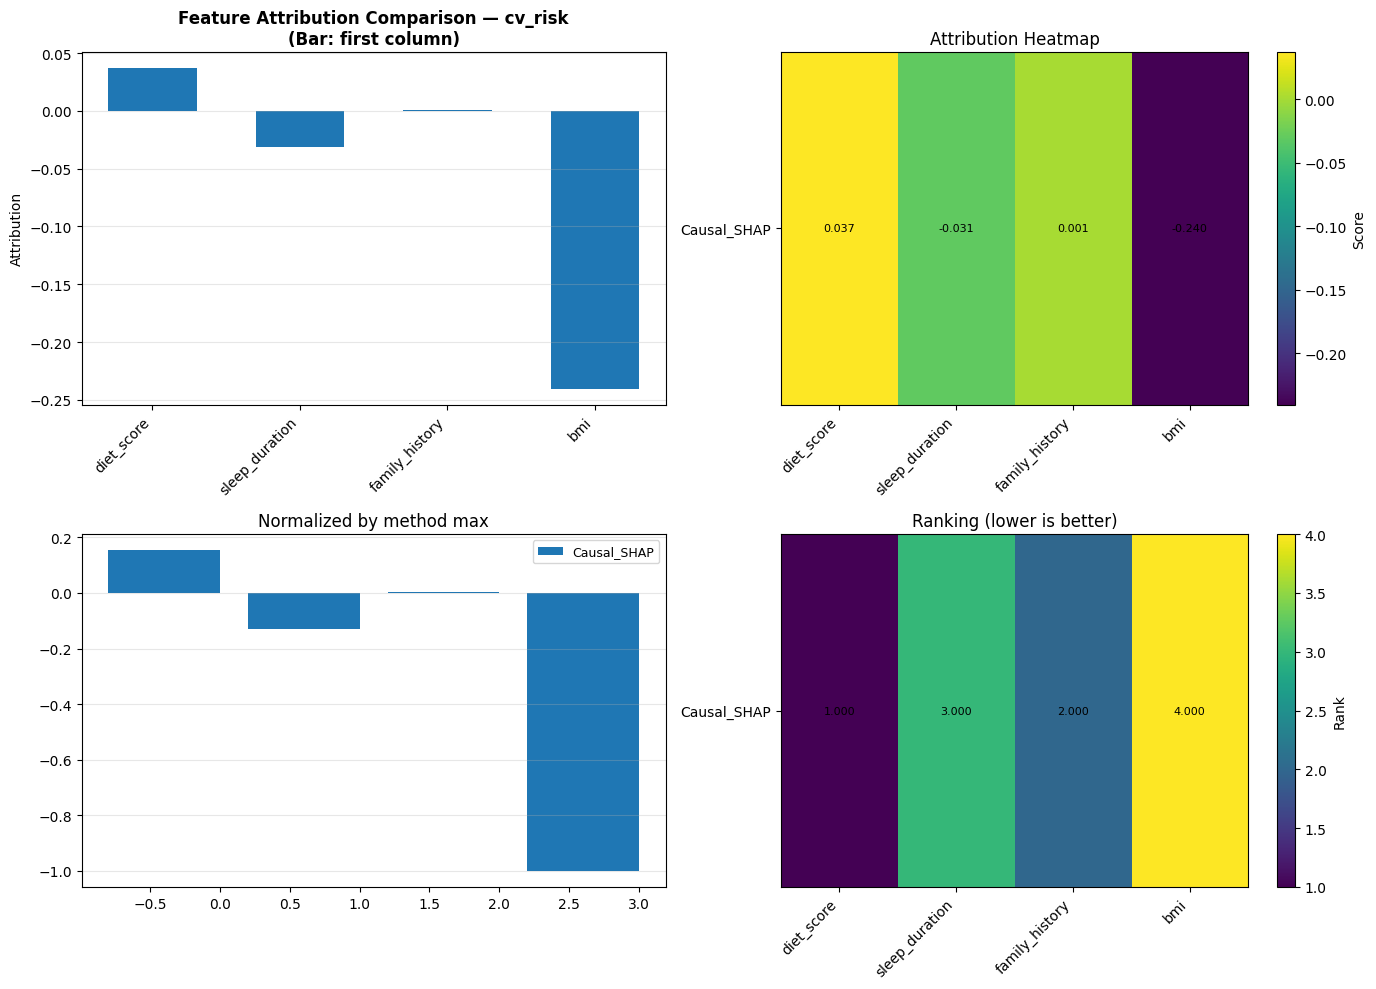


Causal SHAP (paper-faithful) on: lung_cancer_risk.csv
Using RandomForest (regression)
✓ Model: R2=0.7086, MAE=1.5185

----------------------------------------------------------------
Step 1: Causal discovery (PC)
----------------------------------------------------------------
Running PC on 3 features...
✓ PC completed -> CPDAG
Graph: 3 nodes, 2 edges
✓ Saved 'causal_graph_lung_cancer_risk.png'

----------------------------------------------------------------
Step 2: Causal SHAP
----------------------------------------------------------------

Fitting SEMs & sampling DAGs ...
✓ Sampled 5 DAG(s)
Computing IDA-style total effects W_i ...
✓ W_i computed
✓ CausalSHAP ready

Total causal effects W_i and gamma_i:
  smoking               W=  2.818595   γ=0.588029
  stress                W=  1.696499   γ=0.353932
  drink_coffee          W=  0.278200   γ=0.058039

Computing global Causal SHAP over 30 instances ...
  5/30
  10/30
  15/30
  20/30
  25/30
  30/30

--------------------------------

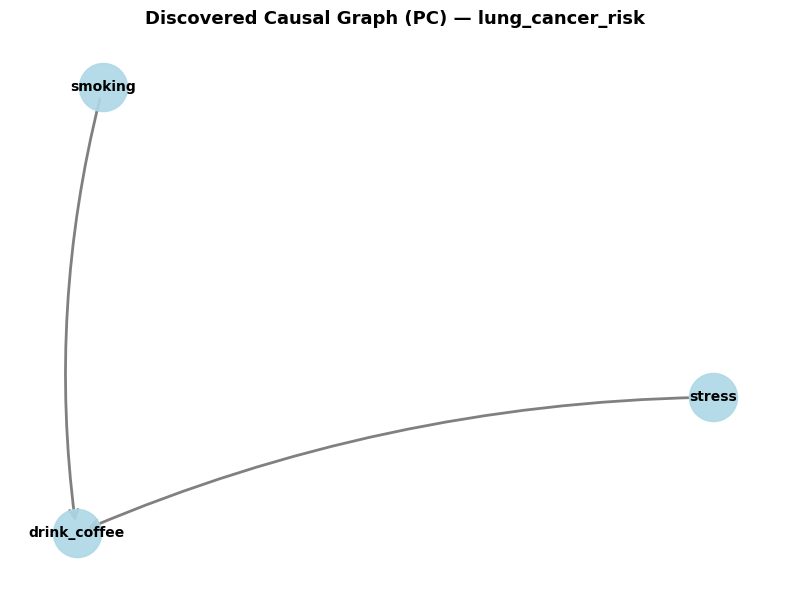

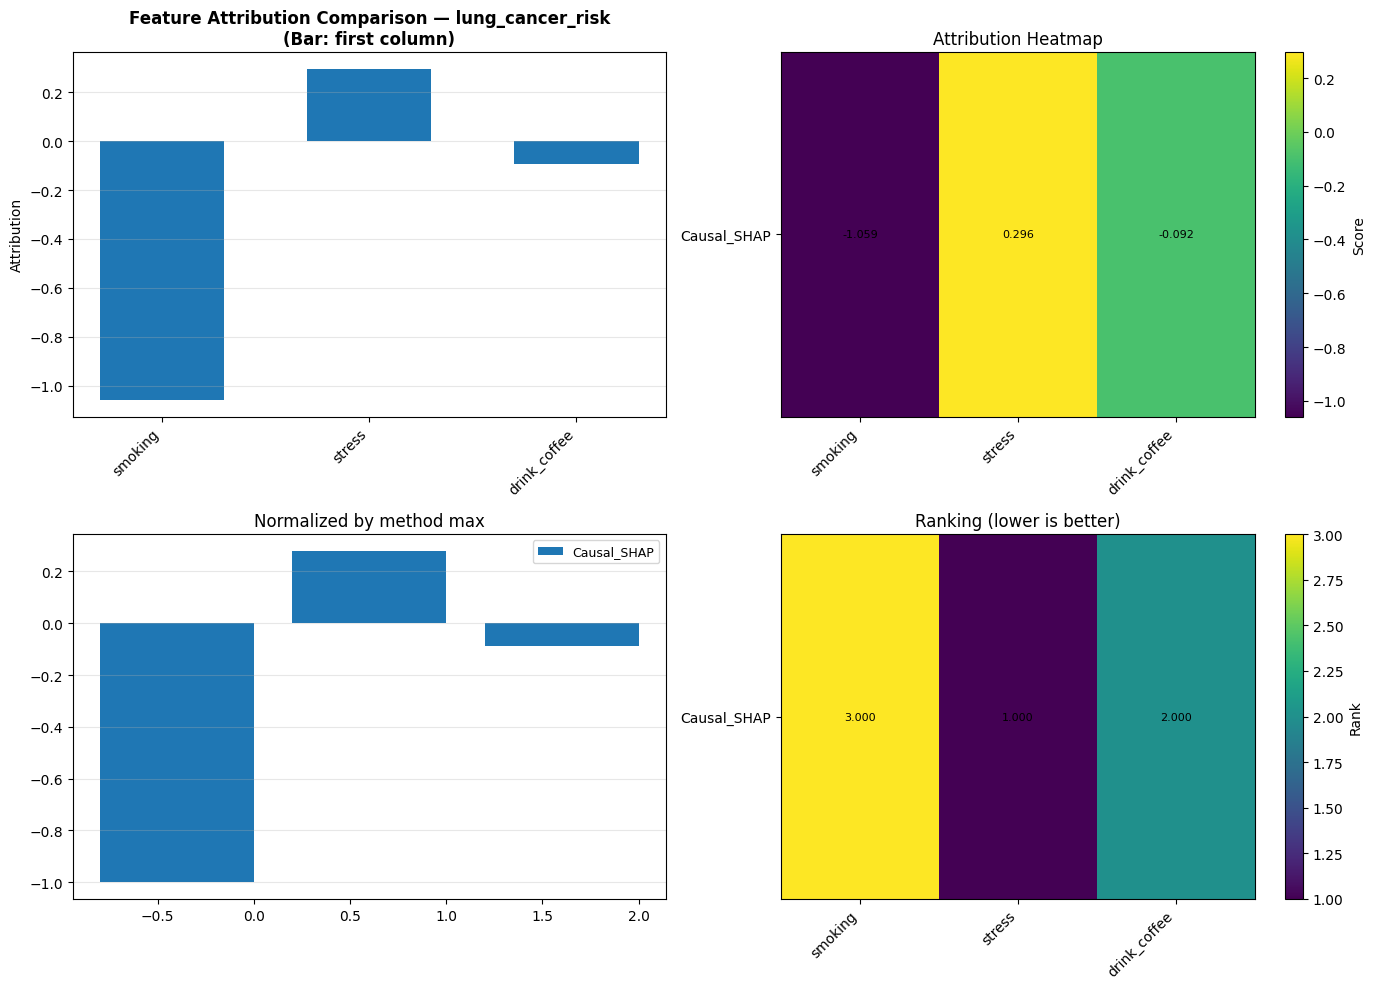

In [ ]:
"""
Causal SHAP (paper-faithful) for CSVs with auto regression/classification
- Tested for:
  /mnt/data/cv_risk.csv          (continuous target: cv_risk)
  /mnt/data/lung_cancer_risk.csv (continuous target: lung_cancer_risk)
"""

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Set, Optional
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import f1_score, accuracy_score, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.utils.multiclass import type_of_target
import networkx as nx

try:
    from xgboost import XGBClassifier, XGBRegressor
    HAVE_XGB = True
except Exception:
    HAVE_XGB = False

HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

CONFIG = {
    'ALPHA_PC': 0.1,
    'MAX_PERM': 200,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5
}
np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])

COMMON_TARGET_NAMES = ["target","label","y","class","outcome",
                       "cvd","cardio","TenYearCHD","heart_disease","stroke","risk",
                       "cancer","lung_cancer","has_cancer","diagnosis"]

def detect_target_column(df: pd.DataFrame, user_hint: Optional[str]=None) -> str:
    if user_hint and user_hint in df.columns: return user_hint
    lower_map = {c.lower(): c for c in df.columns}
    for name in COMMON_TARGET_NAMES:
        if name.lower() in lower_map: return lower_map[name.lower()]
    return df.columns[-1]

def drop_unnamed(df: pd.DataFrame) -> pd.DataFrame:
    return df[[c for c in df.columns if not re.match(r'^unnamed', c, re.I)]].copy()

def to_numeric_df(df: pd.DataFrame) -> pd.DataFrame:
    num = df.select_dtypes(include=[np.number]).copy()
    for c in df.columns:
        if c not in num.columns:
            try:
                num[c] = pd.to_numeric(df[c], errors='raise')
            except Exception:
                pass
    return num

class CausalStructure:
    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names: List[str] = []
        self.dags: List[nx.DiGraph] = []

    def discover(self, X: pd.DataFrame):
        self.feature_names = list(X.columns)
        print(f"Running PC on {len(self.feature_names)} features...")
        res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = res.G.graph
        print("PC completed -> CPDAG")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        G = nx.DiGraph(); G.add_nodes_from(self.feature_names)
        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j: continue
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1 and i < j:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                    G.add_edge(self.feature_names[j], self.feature_names[i])
        return G

    def sample_dags(self, n_samples: int) -> List[nx.DiGraph]:
        dags = []
        names = self.feature_names; n = len(names)
        undirected = []
        for i in range(n):
            for j in range(i+1, n):
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((names[i], names[j]))
        for _ in range(max(1, n_samples)):
            G = nx.DiGraph(); G.add_nodes_from(names)
            for i in range(n):
                for j in range(n):
                    if i != j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(names[i], names[j])
            for u, v in undirected:
                if rng.random() < 0.5: G.add_edge(u, v)
                else: G.add_edge(v, u)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v); G.add_edge(v, u)
                    else: G.remove_edge(v, u); G.add_edge(u, v)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v)
                    if G.has_edge(v, u): G.remove_edge(v, u)
            if not nx.is_directed_acyclic_graph(G):
                for (a, b) in list(G.edges()):
                    G.remove_edge(a, b)
                    if nx.is_directed_acyclic_graph(G): break
                    else: G.add_edge(a, b)
            dags.append(G)
        self.dags = dags
        print(f"Sampled {len(dags)} DAG(s)")
        return dags

class LinearMechanisms:
    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag; self.feature_names = feature_names
        self.mechanisms: Dict[str, Dict] = {}; self.topo: List[str] = []

    def fit(self, X: pd.DataFrame):
        try: self.topo = list(nx.topological_sort(self.dag))
        except Exception: self.topo = self._safe_topo()
        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))
            if not parents:
                self.mechanisms[var] = {"parents": [], "intercept": float(X[var].mean()),
                                        "coef": None, "sigma": float(X[var].std(ddof=0))}
            else:
                lr = LinearRegression().fit(X[parents].values, X[var].values)
                resid = X[var].values - lr.predict(X[parents].values)
                self.mechanisms[var] = {"parents": parents, "intercept": float(lr.intercept_),
                                        "coef": lr.coef_.astype(float), "sigma": float(np.std(resid, ddof=0))}
        return self

    def _safe_topo(self) -> List[str]:
        ordered, remaining = [], set(self.feature_names)
        while remaining:
            ready = [n for n in remaining if all(p in ordered or p not in remaining
                                                 for p in self.dag.predecessors(n))]
            if not ready:
                ready = [min(remaining, key=lambda n: len([p for p in self.dag.predecessors(n) if p in remaining]))]
            for n in ready: ordered.append(n); remaining.remove(n)
        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series) -> Dict[str, float]:
        x_new: Dict[str, float] = {}
        for var in self.topo:
            if var in S: x_new[var] = float(x_obs[var]); continue
            mech = self.mechanisms[var]
            if not mech["parents"]:
                mu, sigma = mech["intercept"], mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
            else:
                pvals = np.array([x_new.get(p, x_obs[p]) for p in mech["parents"]])
                mu = mech["intercept"] + pvals @ mech["coef"]
                sigma = mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
        return x_new

class CausalEffects:
    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects: Dict[str, float] = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        print("Computing IDA-style total effects W_i ...")
        y_vals = y.values
        totals = {f: [] for f in self.feature_names}

        for dag in self.dags:
            G = dag.copy()
            G.add_node("Y")

            # (A) Edge weights among features
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                X_reg = np.column_stack([X[parents].values, X[u].values]) if parents else X[[u]].values
                lr = LinearRegression().fit(X_reg, X[v].values)
                w = float(abs(lr.coef_[-1]))
                if w > 1e-12:
                    G.add_edge(u, v, weight=w)

            # (B) Direct edges into Y: Y ~ all features
            paY = list(self.feature_names)
            lrY = LinearRegression().fit(X[paY].values, y_vals)
            for feat, w in zip(paY, np.abs(lrY.coef_)):
                if w > 1e-12:
                    G.add_edge(feat, "Y", weight=float(w))

            # (C) Sum of path products i -> ... -> Y
            for i_feat in self.feature_names:
                total = 0.0
                try:
                    for path in nx.all_simple_paths(G, i_feat, "Y", cutoff=10):
                        prod = 1.0
                        ok = True
                        for a, b in zip(path[:-1], path[1:]):
                            ed = G.get_edge_data(a, b)
                            if not ed or "weight" not in ed:
                                ok = False
                                break
                            prod *= ed["weight"]
                        if ok:
                            total += prod
                except Exception:
                    pass
                totals[i_feat].append(total)

        self.effects = {f: (float(np.mean(vals)) if len(vals) else 0.0) for f, vals in totals.items()}
        print("W_i computed")
        return self.effects

    def gamma_weights(self) -> Dict[str, float]:
        absW = {k: abs(v) for k, v in self.effects.items()}
        Z = sum(absW.values()) + 1e-12
        return {k: v / Z for k, v in absW.items()}


class CausalSHAP:
    def __init__(self, model, structure: CausalStructure, X_train: pd.DataFrame, y_train: pd.Series, task: str):
        self.model = model; self.structure = structure
        self.X_train = X_train; self.y_train = y_train
        self.features = list(X_train.columns); self.task = task

        print("\nFitting SEMs & sampling DAGs ...")
        self.dags = self.structure.sample_dags(CONFIG['N_DAGS'])
        self.sems = [LinearMechanisms(d, self.features).fit(X_train) for d in self.dags]

        self.effects = CausalEffects(self.dags, self.features)
        self.effects.compute_effects(X_train, y_train)
        self.gamma = self.effects.gamma_weights()
        self._Ef_cache = None
        print("CausalSHAP ready")

    def _predict_scalar(self, X_mat: np.ndarray) -> float:
        if self.task == "classification":
            proba = self.model.predict_proba(X_mat)[0]
            return float(proba[np.argmax(proba)])  # predicted class prob (paper used f(x) scalar)
        else:  # regression
            return float(self.model.predict(X_mat)[0])

    def _Ef(self) -> float:
        if self._Ef_cache is None:
            if self.task == "classification":
                P = self.model.predict_proba(self.X_train.values)
                self._Ef_cache = float(P.max(axis=1).mean())  # mean predicted-class prob
            else:
                preds = self.model.predict(self.X_train.values)
                self._Ef_cache = float(np.mean(preds))
        return self._Ef_cache

    def _vc(self, S: Set[str], x: pd.Series, M: int) -> float:
        total = 0.0
        per = max(1, M // max(1, len(self.sems)))
        for sem in self.sems:
            for _ in range(per):
                x_sample = sem.sample_intervention(S, x)
                X_mat = pd.DataFrame([x_sample], columns=self.features).values
                total += self._predict_scalar(X_mat)
        N = per * max(1, len(self.sems))
        return total / N if N > 0 else 0.0

    def explain_instance(self, x: pd.Series, n_perms: int=None, M: int=None) -> pd.Series:
        if n_perms is None: n_perms = CONFIG['MAX_PERM']
        if M is None: M = CONFIG['M_RESAMPLES']

        fx = self._predict_scalar(pd.DataFrame([x], columns=self.features).values)
        phi = np.zeros(len(self.features), dtype=float)

        for _ in range(n_perms):
            perm = rng.permutation(self.features)
            S: Set[str] = set()
            v_prev = self._vc(S, x, M)
            for feat in perm:
                S_next = S | {feat}
                v_curr = self._vc(S_next, x, M)
                delta = v_curr - v_prev
                phi[self.features.index(feat)] += self.gamma[feat] * delta
                v_prev, S = v_curr, S_next

        phi /= n_perms

        sum_phi_c = float(np.sum(phi))
        if abs(sum_phi_c) > 1e-12:
            Ef = self._Ef()
            phi = phi * ((fx - Ef) / sum_phi_c)
        return pd.Series(phi, index=self.features, name="Causal_SHAP")

    def explain_global(self, X_test: pd.DataFrame, k: int=None) -> pd.Series:
        if k is None: k = CONFIG['GLOBAL_K']
        k = min(k, len(X_test))
        idx = rng.choice(len(X_test), size=k, replace=False)
        print(f"\nComputing global Causal SHAP over {k} instances ...")
        exps = []
        for t, i in enumerate(idx, 1):
            if t % 5 == 0: print(f"  {t}/{k}")
            exps.append(self.explain_instance(X_test.iloc[i], n_perms=max(10, CONFIG['MAX_PERM']//4)))
        return pd.concat(exps, axis=1).mean(axis=1).rename("Causal_SHAP_Global")

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1])); ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticks(np.arange(data.shape[0])); ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax); cbar.set_label(cbar_label)
    ax.set_title(title)

def plot_comparison(df: pd.DataFrame, title="Feature Attribution Comparison"):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes[0, 0].bar(np.arange(df.shape[0]), df.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\n(Bar: first column)', fontsize=12, fontweight='bold')
    axes[0, 0].set_xticks(np.arange(df.shape[0])); axes[0, 0].set_xticklabels(df.index, rotation=45, ha='right')
    axes[0, 0].set_ylabel('Attribution'); axes[0, 0].grid(axis='y', alpha=0.3)
    annotate_heatmap(axes[0, 1], df.T, 'Attribution Heatmap', 'Score')
    df_norm = df.div(df.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col],
                       width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized by method max'); axes[1, 0].legend(fontsize=9); axes[1, 0].grid(axis='y', alpha=0.3)
    ranks = df.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Ranking (lower is better)', 'Rank')
    fig.tight_layout(); return fig

def plot_causal_graph(G: nx.DiGraph, title="Discovered Causal Graph (PC)"):
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)
    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15, width=2, arrowstyle='->', connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')
    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off'); plt.tight_layout()
    return plt.gcf()

def run_causal_shap_on_csv(csv_path: str, dataset_name: Optional[str]=None, target_hint: Optional[str]=None, test_size: float=0.25):
    print("\n" + "="*72)
    print(f"Causal SHAP (paper-faithful) on: {csv_path}")
    print("="*72)

    try:
        raw = pd.read_csv(csv_path)
    except Exception as e:
        print(f"ERROR reading CSV: {e}"); return

    raw = drop_unnamed(raw)  # drop index columns like 'Unnamed: 0'
    if dataset_name is None:
        dataset_name = csv_path.split("/")[-1].split(".")[0]

    tgt_col = detect_target_column(raw, target_hint)
    if tgt_col not in raw.columns:
        print("ERROR: target column not found."); return

    y_raw = raw[tgt_col].copy()
    X_raw = raw.drop(columns=[tgt_col])

    X_num = to_numeric_df(X_raw)
    dropped = set(X_raw.columns) - set(X_num.columns)
    if dropped:
        print(f"Note: Dropping non-numeric columns: {sorted(list(dropped))}")

    X_num = X_num.replace([np.inf, -np.inf], np.nan).fillna(X_num.median(numeric_only=True))

    y_type = type_of_target(y_raw)
    if y_type in ["binary","multiclass"]:
        task = "classification"
        y_vec = y_raw.astype(int).values
    else:
        task = "regression"
        y_vec = pd.to_numeric(y_raw, errors="coerce").values
        if np.isnan(y_vec).any():
            print("ERROR: target has non-numeric values that cannot be coerced."); return

    strat = y_vec if (task=="classification" and len(np.unique(y_vec))>1) else None
    X_train, X_test, y_train, y_test = train_test_split(
        X_num, y_vec, test_size=test_size, random_state=CONFIG['RANDOM_SEED'], stratify=strat
    )

    scaler = StandardScaler()
    Xtr = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
    Xte = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns,  index=X_test.index)

    if task=="classification":
        n_classes = int(len(np.unique(y_train)))
        if HAVE_XGB:
            model = XGBClassifier(
                n_estimators=160, max_depth=5, learning_rate=0.08,
                subsample=0.9, colsample_bytree=0.9,
                random_state=CONFIG['RANDOM_SEED'], verbosity=0,
                objective="multi:softprob" if n_classes>2 else "binary:logistic",
                num_class=n_classes if n_classes>2 else None
            )
            print("Using XGBoost (classification)")
        else:
            model = RandomForestClassifier(n_estimators=160, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
            print("Using RandomForest (classification)")
        model.fit(Xtr.values, y_train)
        y_pred = model.predict(Xte.values)
        acc = accuracy_score(y_test, y_pred); f1m = f1_score(y_test, y_pred, average='macro')
        print(f"Model: acc={acc:.4f}, macroF1={f1m:.4f}, classes={n_classes}")
    else:
        if HAVE_XGB:
            model = XGBRegressor(
                n_estimators=200, max_depth=5, learning_rate=0.08,
                subsample=0.9, colsample_bytree=0.9,
                random_state=CONFIG['RANDOM_SEED']
            )
            print("Using XGBoost (regression)")
        else:
            model = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
            print("Using RandomForest (regression)")
        model.fit(Xtr.values, y_train)
        y_pred = model.predict(Xte.values)
        r2 = r2_score(y_test, y_pred); mae = mean_absolute_error(y_test, y_pred)
        print(f"Model: R2={r2:.4f}, MAE={mae:.4f}")

    # Step 1: PC discovery
    print("\n" + "-"*64)
    print("Step 1: Causal discovery (PC)")
    print("-"*64)
    cs = CausalStructure(alpha=CONFIG['ALPHA_PC']).discover(Xtr)
    G_skel = cs.get_skeleton()
    print(f"Graph: {G_skel.number_of_nodes()} nodes, {G_skel.number_of_edges()} edges")
    fig = plot_causal_graph(G_skel, title=f"Discovered Causal Graph (PC) — {dataset_name}")
    fig.savefig(f'causal_graph_{dataset_name}.png', dpi=150, bbox_inches='tight')
    print(f"Saved 'causal_graph_{dataset_name}.png'")

    # Step 2: Causal SHAP
    print("\n" + "-"*64)
    print("Step 2: Causal SHAP")
    print("-"*64)
    cshap = CausalSHAP(model, cs, Xtr, pd.Series(y_train), task=task)
    print("\nTotal causal effects W_i and gamma_i:")
    for f in Xtr.columns:
        print(f"  {f:20s}  W={cshap.effects.effects[f]:10.6f}   γ={cshap.gamma[f]:.6f}")

    glob = cshap.explain_global(Xte, k=min(CONFIG['GLOBAL_K'], len(Xte)))

    # Step 3: Save/plot comparison (Causal_SHAP only by default for regression)
    cols = {"Causal_SHAP": glob}
    df = pd.DataFrame(cols)
    df.to_csv(f"attribution_scores_{dataset_name}.csv", index=True)
    print("\n" + "-"*64)
    print("Step 3: Comparison & Save")
    print("-"*64)
    print(df.round(6).to_string())
    print(f"\nSaved: attribution_scores_{dataset_name}.csv")

    fig2 = plot_comparison(df, title=f"Feature Attribution Comparison — {dataset_name}")
    fig2.savefig(f'attribution_comparison_{dataset_name}.png', dpi=150, bbox_inches='tight')
    print(f"Saved 'attribution_comparison_{dataset_name}.png'")

    try: plt.show()
    except Exception: pass

def main():
    run_causal_shap_on_csv("cv_risk.csv", dataset_name="cv_risk")
    run_causal_shap_on_csv("lung_cancer_risk.csv", dataset_name="lung_cancer_risk")

if __name__ == "__main__":
    main()


Causal SHAP (paper-faithful) on: cv_risk.csv
Using RandomForest (regression)
✓ Model: R2=0.6623, MAE=1.3549

----------------------------------------------------------------
Step 1: Causal discovery (PC)
----------------------------------------------------------------
Running PC on 4 features...
✓ PC completed -> CPDAG
Graph: 4 nodes, 2 edges
✓ Saved 'causal_graph_cv_risk.png'

----------------------------------------------------------------
Step 2: Causal SHAP
----------------------------------------------------------------

Fitting SEMs & sampling DAGs ...
✓ Sampled 5 DAG(s)
Computing IDA-style total effects W_i ...
✓ W_i computed
✓ CausalSHAP ready
✓ Saved 'causal_graph_with_target_cv_risk.png'

Total causal effects W_i and gamma_i:
  diet_score            W=  1.557027   γ=0.268893
  sleep_duration        W=  1.514280   γ=0.261510
  family_history        W=  0.097514   γ=0.016840
  bmi                   W=  2.621693   γ=0.452757

Computing global Causal SHAP over 30 instances ...
 

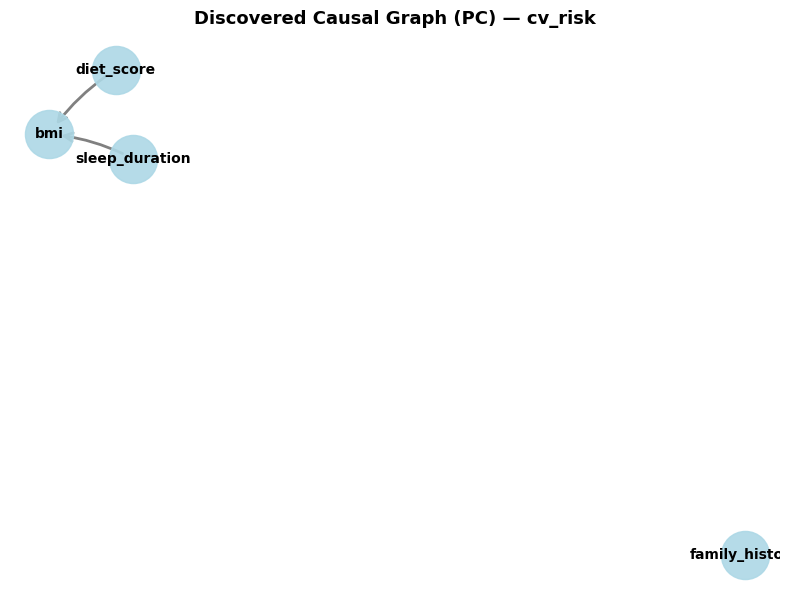

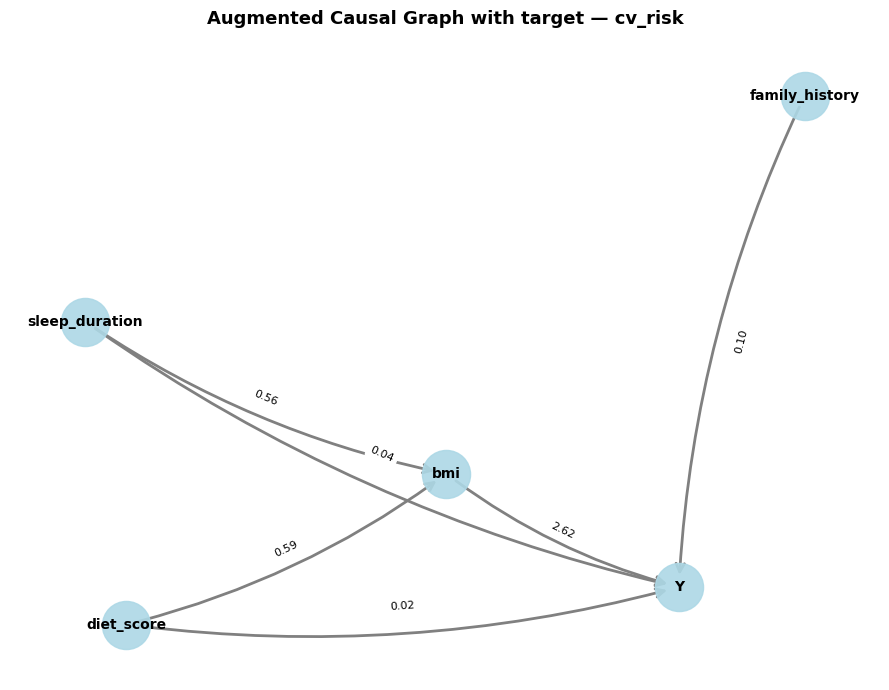

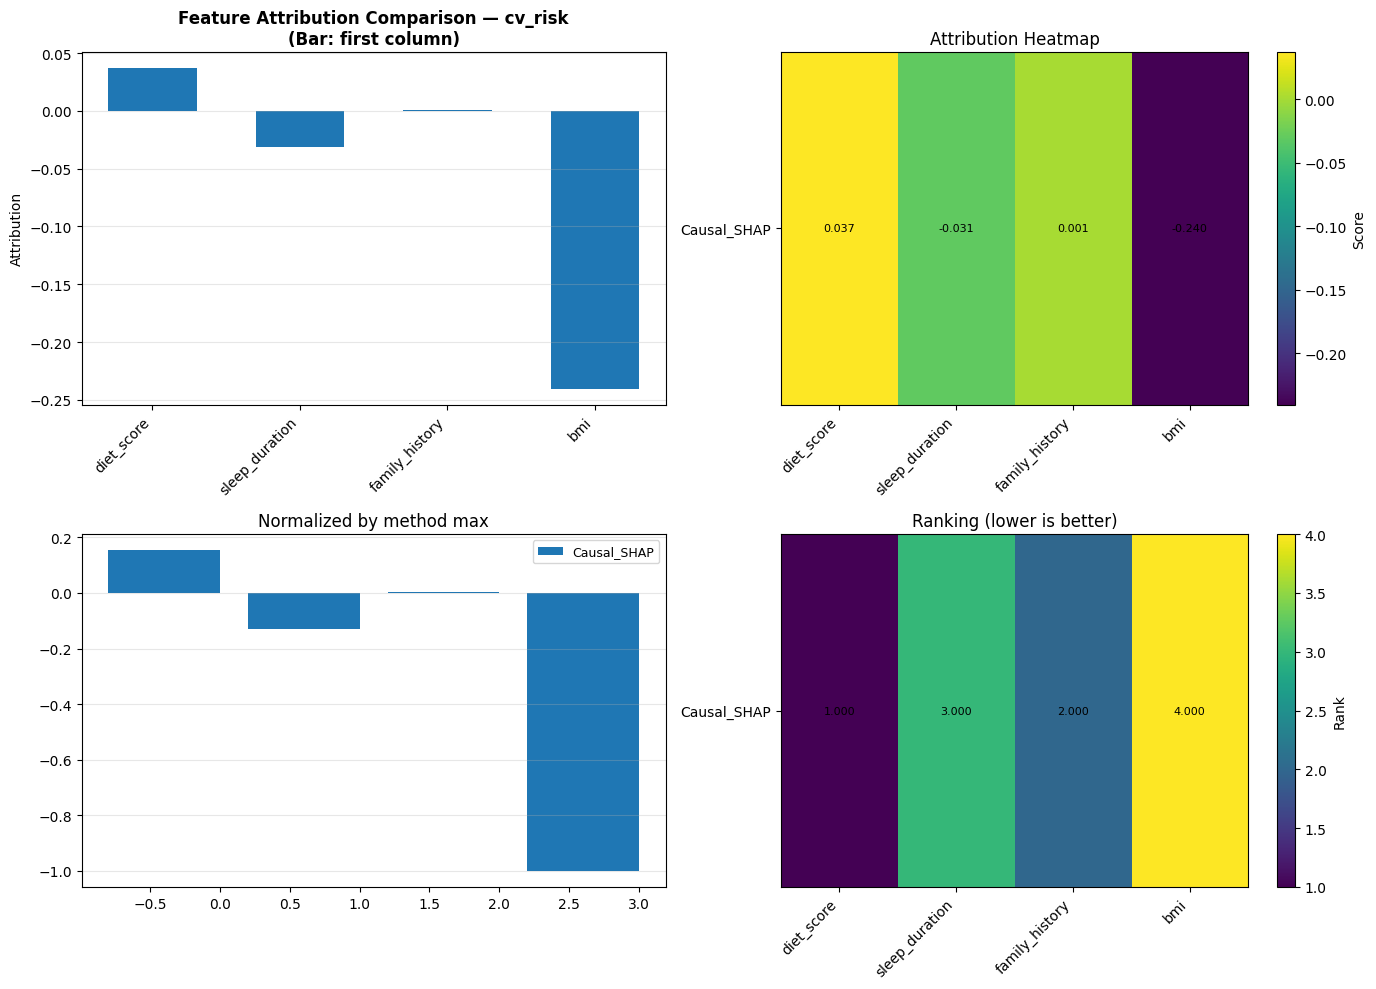


Causal SHAP (paper-faithful) on: lung_cancer_risk.csv
Using RandomForest (regression)
✓ Model: R2=0.7086, MAE=1.5185

----------------------------------------------------------------
Step 1: Causal discovery (PC)
----------------------------------------------------------------
Running PC on 3 features...
✓ PC completed -> CPDAG
Graph: 3 nodes, 2 edges
✓ Saved 'causal_graph_lung_cancer_risk.png'

----------------------------------------------------------------
Step 2: Causal SHAP
----------------------------------------------------------------

Fitting SEMs & sampling DAGs ...
✓ Sampled 5 DAG(s)
Computing IDA-style total effects W_i ...
✓ W_i computed
✓ CausalSHAP ready
✓ Saved 'causal_graph_with_target_lung_cancer_risk.png'

Total causal effects W_i and gamma_i:
  smoking               W=  2.818595   γ=0.588029
  stress                W=  1.696499   γ=0.353932
  drink_coffee          W=  0.278200   γ=0.058039

Computing global Causal SHAP over 30 instances ...
  5/30
  10/30
  15/30
 

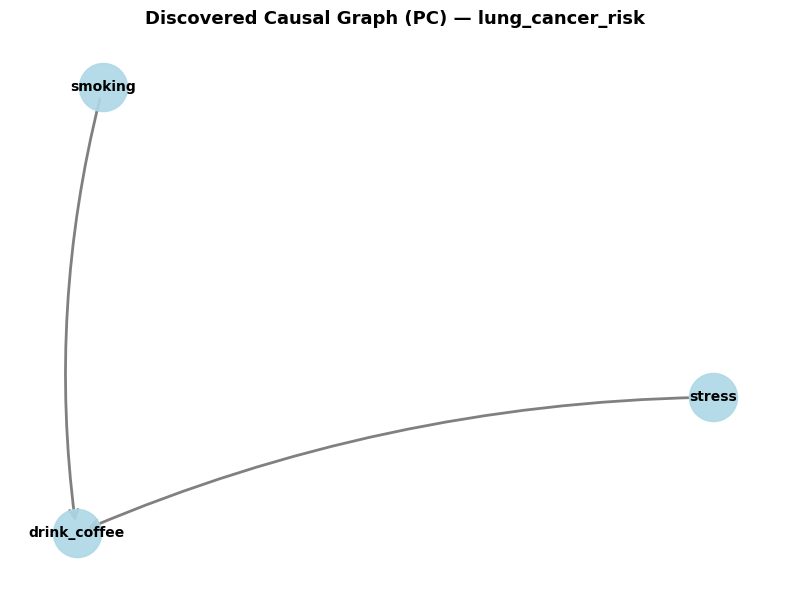

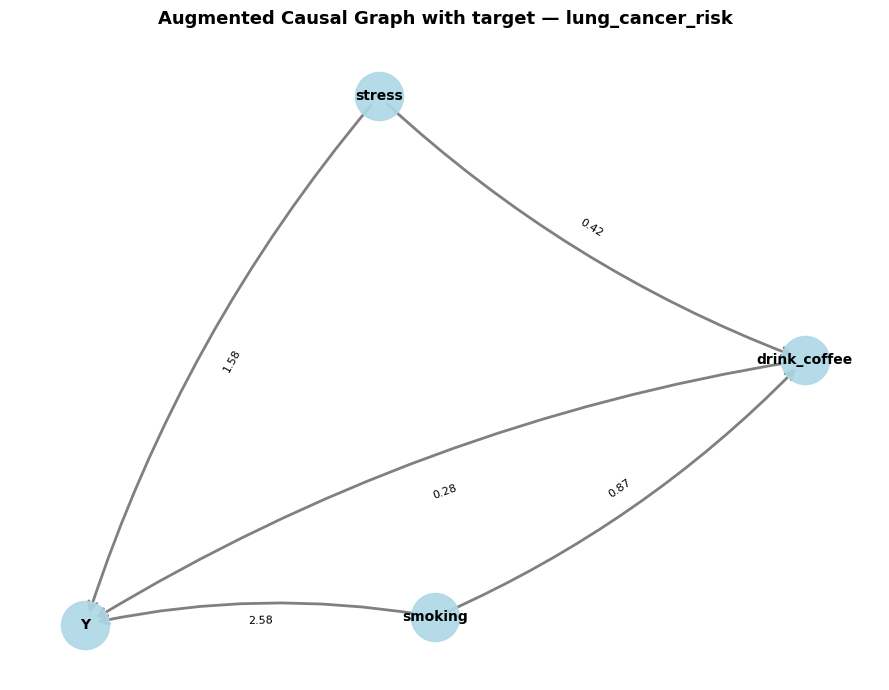

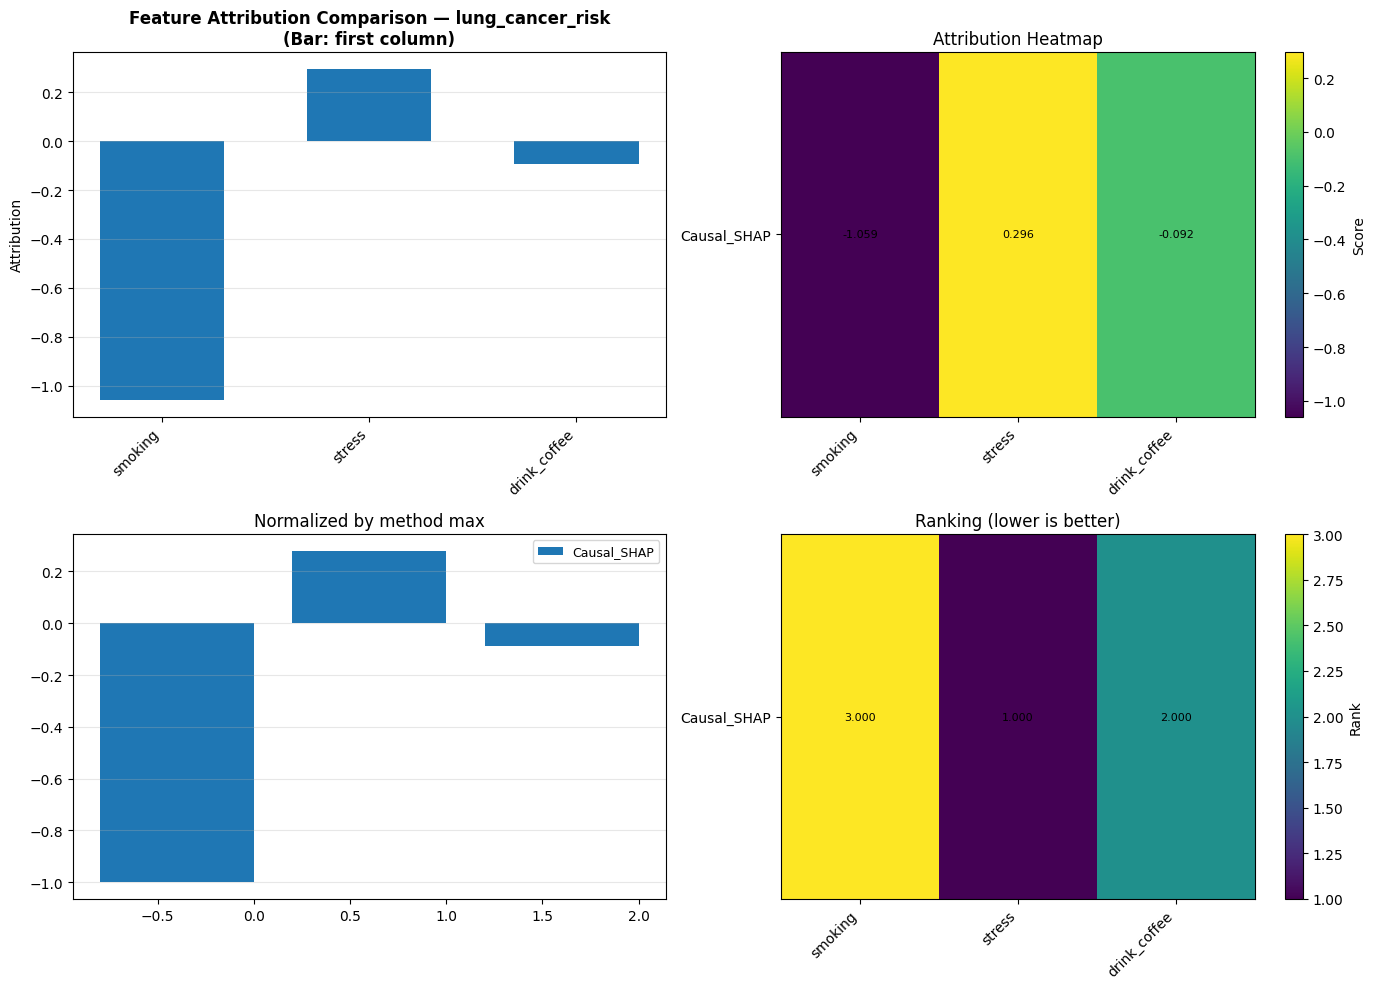

In [7]:
"""
Causal SHAP (paper-faithful) for CSVs with auto regression/classification
- Tested for:
  /mnt/data/cv_risk.csv          (continuous target: cv_risk)
  /mnt/data/lung_cancer_risk.csv (continuous target: lung_cancer_risk)
"""

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Set, Optional
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import f1_score, accuracy_score, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.utils.multiclass import type_of_target
import networkx as nx

try:
    from xgboost import XGBClassifier, XGBRegressor
    HAVE_XGB = True
except Exception:
    HAVE_XGB = False

HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

CONFIG = {
    'ALPHA_PC': 0.1,
    'MAX_PERM': 200,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5
}
np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])

COMMON_TARGET_NAMES = ["target","label","y","class","outcome",
                       "cvd","cardio","TenYearCHD","heart_disease","stroke","risk",
                       "cancer","lung_cancer","has_cancer","diagnosis"]

def detect_target_column(df: pd.DataFrame, user_hint: Optional[str]=None) -> str:
    if user_hint and user_hint in df.columns: return user_hint
    lower_map = {c.lower(): c for c in df.columns}
    for name in COMMON_TARGET_NAMES:
        if name.lower() in lower_map: return lower_map[name.lower()]
    return df.columns[-1]

def drop_unnamed(df: pd.DataFrame) -> pd.DataFrame:
    return df[[c for c in df.columns if not re.match(r'^unnamed', c, re.I)]].copy()

def to_numeric_df(df: pd.DataFrame) -> pd.DataFrame:
    num = df.select_dtypes(include=[np.number]).copy()
    for c in df.columns:
        if c not in num.columns:
            try:
                num[c] = pd.to_numeric(df[c], errors='raise')
            except Exception:
                pass
    return num

class CausalStructure:
    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names: List[str] = []
        self.dags: List[nx.DiGraph] = []

    def discover(self, X: pd.DataFrame):
        self.feature_names = list(X.columns)
        print(f"Running PC on {len(self.feature_names)} features...")
        res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = res.G.graph
        print("PC completed -> CPDAG")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        G = nx.DiGraph(); G.add_nodes_from(self.feature_names)
        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j: continue
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1 and i < j:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                    G.add_edge(self.feature_names[j], self.feature_names[i])
        return G

    def sample_dags(self, n_samples: int) -> List[nx.DiGraph]:
        dags = []
        names = self.feature_names; n = len(names)
        undirected = []
        for i in range(n):
            for j in range(i+1, n):
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((names[i], names[j]))
        for _ in range(max(1, n_samples)):
            G = nx.DiGraph(); G.add_nodes_from(names)
            for i in range(n):
                for j in range(n):
                    if i != j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(names[i], names[j])
            for u, v in undirected:
                if rng.random() < 0.5: G.add_edge(u, v)
                else: G.add_edge(v, u)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v); G.add_edge(v, u)
                    else: G.remove_edge(v, u); G.add_edge(u, v)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v)
                    if G.has_edge(v, u): G.remove_edge(v, u)
            if not nx.is_directed_acyclic_graph(G):
                for (a, b) in list(G.edges()):
                    G.remove_edge(a, b)
                    if nx.is_directed_acyclic_graph(G): break
                    else: G.add_edge(a, b)
            dags.append(G)
        self.dags = dags
        print(f"Sampled {len(dags)} DAG(s)")
        return dags

class LinearMechanisms:
    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag; self.feature_names = feature_names
        self.mechanisms: Dict[str, Dict] = {}; self.topo: List[str] = []

    def fit(self, X: pd.DataFrame):
        try: self.topo = list(nx.topological_sort(self.dag))
        except Exception: self.topo = self._safe_topo()
        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))
            if not parents:
                self.mechanisms[var] = {"parents": [], "intercept": float(X[var].mean()),
                                        "coef": None, "sigma": float(X[var].std(ddof=0))}
            else:
                lr = LinearRegression().fit(X[parents].values, X[var].values)
                resid = X[var].values - lr.predict(X[parents].values)
                self.mechanisms[var] = {"parents": parents, "intercept": float(lr.intercept_),
                                        "coef": lr.coef_.astype(float), "sigma": float(np.std(resid, ddof=0))}
        return self

    def _safe_topo(self) -> List[str]:
        ordered, remaining = [], set(self.feature_names)
        while remaining:
            ready = [n for n in remaining if all(p in ordered or p not in remaining
                                                 for p in self.dag.predecessors(n))]
            if not ready:
                ready = [min(remaining, key=lambda n: len([p for p in self.dag.predecessors(n) if p in remaining]))]
            for n in ready: ordered.append(n); remaining.remove(n)
        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series) -> Dict[str, float]:
        x_new: Dict[str, float] = {}
        for var in self.topo:
            if var in S: x_new[var] = float(x_obs[var]); continue
            mech = self.mechanisms[var]
            if not mech["parents"]:
                mu, sigma = mech["intercept"], mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
            else:
                pvals = np.array([x_new.get(p, x_obs[p]) for p in mech["parents"]])
                mu = mech["intercept"] + pvals @ mech["coef"]
                sigma = mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
        return x_new

class CausalEffects:
    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects: Dict[str, float] = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        print("Computing IDA-style total effects W_i ...")
        y_vals = y.values
        totals = {f: [] for f in self.feature_names}

        for dag in self.dags:
            G = dag.copy()
            G.add_node("Y")

            # (A) Edge weights among features
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                X_reg = np.column_stack([X[parents].values, X[u].values]) if parents else X[[u]].values
                lr = LinearRegression().fit(X_reg, X[v].values)
                w = float(abs(lr.coef_[-1]))
                if w > 1e-12:
                    G.add_edge(u, v, weight=w)

            # (B) Direct edges into Y: Y ~ all features
            paY = list(self.feature_names)
            lrY = LinearRegression().fit(X[paY].values, y_vals)
            for feat, w in zip(paY, np.abs(lrY.coef_)):
                if w > 1e-12:
                    G.add_edge(feat, "Y", weight=float(w))

            # (C) Sum of path products i -> ... -> Y
            for i_feat in self.feature_names:
                total = 0.0
                try:
                    for path in nx.all_simple_paths(G, i_feat, "Y", cutoff=10):
                        prod = 1.0
                        ok = True
                        for a, b in zip(path[:-1], path[1:]):
                            ed = G.get_edge_data(a, b)
                            if not ed or "weight" not in ed:
                                ok = False
                                break
                            prod *= ed["weight"]
                        if ok:
                            total += prod
                except Exception:
                    pass
                totals[i_feat].append(total)

        self.effects = {f: (float(np.mean(vals)) if len(vals) else 0.0) for f, vals in totals.items()}
        print("W_i computed")
        return self.effects

    def gamma_weights(self) -> Dict[str, float]:
        absW = {k: abs(v) for k, v in self.effects.items()}
        Z = sum(absW.values()) + 1e-12
        return {k: v / Z for k, v in absW.items()}


class CausalSHAP:
    def __init__(self, model, structure: CausalStructure, X_train: pd.DataFrame, y_train: pd.Series, task: str):
        self.model = model; self.structure = structure
        self.X_train = X_train; self.y_train = y_train
        self.features = list(X_train.columns); self.task = task

        print("\nFitting SEMs & sampling DAGs ...")
        self.dags = self.structure.sample_dags(CONFIG['N_DAGS'])
        self.sems = [LinearMechanisms(d, self.features).fit(X_train) for d in self.dags]

        self.effects = CausalEffects(self.dags, self.features)
        self.effects.compute_effects(X_train, y_train)
        self.gamma = self.effects.gamma_weights()
        self._Ef_cache = None
        print("CausalSHAP ready")

    def _predict_scalar(self, X_mat: np.ndarray) -> float:
        if self.task == "classification":
            proba = self.model.predict_proba(X_mat)[0]
            return float(proba[np.argmax(proba)])  # predicted class prob (paper used f(x) scalar)
        else:  # regression
            return float(self.model.predict(X_mat)[0])

    def _Ef(self) -> float:
        if self._Ef_cache is None:
            if self.task == "classification":
                P = self.model.predict_proba(self.X_train.values)
                self._Ef_cache = float(P.max(axis=1).mean())  # mean predicted-class prob
            else:
                preds = self.model.predict(self.X_train.values)
                self._Ef_cache = float(np.mean(preds))
        return self._Ef_cache

    def _vc(self, S: Set[str], x: pd.Series, M: int) -> float:
        total = 0.0
        per = max(1, M // max(1, len(self.sems)))
        for sem in self.sems:
            for _ in range(per):
                x_sample = sem.sample_intervention(S, x)
                X_mat = pd.DataFrame([x_sample], columns=self.features).values
                total += self._predict_scalar(X_mat)
        N = per * max(1, len(self.sems))
        return total / N if N > 0 else 0.0

    def explain_instance(self, x: pd.Series, n_perms: int=None, M: int=None) -> pd.Series:
        if n_perms is None: n_perms = CONFIG['MAX_PERM']
        if M is None: M = CONFIG['M_RESAMPLES']

        fx = self._predict_scalar(pd.DataFrame([x], columns=self.features).values)
        phi = np.zeros(len(self.features), dtype=float)

        for _ in range(n_perms):
            perm = rng.permutation(self.features)
            S: Set[str] = set()
            v_prev = self._vc(S, x, M)
            for feat in perm:
                S_next = S | {feat}
                v_curr = self._vc(S_next, x, M)
                delta = v_curr - v_prev
                phi[self.features.index(feat)] += self.gamma[feat] * delta
                v_prev, S = v_curr, S_next

        phi /= n_perms

        sum_phi_c = float(np.sum(phi))
        if abs(sum_phi_c) > 1e-12:
            Ef = self._Ef()
            phi = phi * ((fx - Ef) / sum_phi_c)
        return pd.Series(phi, index=self.features, name="Causal_SHAP")

    def explain_global(self, X_test: pd.DataFrame, k: int=None) -> pd.Series:
        if k is None: k = CONFIG['GLOBAL_K']
        k = min(k, len(X_test))
        idx = rng.choice(len(X_test), size=k, replace=False)
        print(f"\nComputing global Causal SHAP over {k} instances ...")
        exps = []
        for t, i in enumerate(idx, 1):
            if t % 5 == 0: print(f"  {t}/{k}")
            exps.append(self.explain_instance(X_test.iloc[i], n_perms=max(10, CONFIG['MAX_PERM']//4)))
        return pd.concat(exps, axis=1).mean(axis=1).rename("Causal_SHAP_Global")

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1])); ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticks(np.arange(data.shape[0])); ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax); cbar.set_label(cbar_label)
    ax.set_title(title)

def plot_comparison(df: pd.DataFrame, title="Feature Attribution Comparison"):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes[0, 0].bar(np.arange(df.shape[0]), df.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\n(Bar: first column)', fontsize=12, fontweight='bold')
    axes[0, 0].set_xticks(np.arange(df.shape[0])); axes[0, 0].set_xticklabels(df.index, rotation=45, ha='right')
    axes[0, 0].set_ylabel('Attribution'); axes[0, 0].grid(axis='y', alpha=0.3)
    annotate_heatmap(axes[0, 1], df.T, 'Attribution Heatmap', 'Score')
    df_norm = df.div(df.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col],
                       width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized by method max'); axes[1, 0].legend(fontsize=9); axes[1, 0].grid(axis='y', alpha=0.3)
    ranks = df.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Ranking (lower is better)', 'Rank')
    fig.tight_layout(); return fig

def plot_causal_graph(G: nx.DiGraph, title="Discovered Causal Graph (PC)"):
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)
    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15, width=2, arrowstyle='->', connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')
    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off'); plt.tight_layout()
    return plt.gcf()

def run_causal_shap_on_csv(csv_path: str, dataset_name: Optional[str]=None, target_hint: Optional[str]=None, test_size: float=0.25):
    print("\n" + "="*72)
    print(f"Causal SHAP (paper-faithful) on: {csv_path}")
    print("="*72)

    try:
        raw = pd.read_csv(csv_path)
    except Exception as e:
        print(f"ERROR reading CSV: {e}"); return

    raw = drop_unnamed(raw)  # drop index columns like 'Unnamed: 0'
    if dataset_name is None:
        dataset_name = csv_path.split("/")[-1].split(".")[0]

    tgt_col = detect_target_column(raw, target_hint)
    if tgt_col not in raw.columns:
        print("ERROR: target column not found."); return

    y_raw = raw[tgt_col].copy()
    X_raw = raw.drop(columns=[tgt_col])

    X_num = to_numeric_df(X_raw)
    dropped = set(X_raw.columns) - set(X_num.columns)
    if dropped:
        print(f"Note: Dropping non-numeric columns: {sorted(list(dropped))}")

    X_num = X_num.replace([np.inf, -np.inf], np.nan).fillna(X_num.median(numeric_only=True))

    y_type = type_of_target(y_raw)
    if y_type in ["binary","multiclass"]:
        task = "classification"
        y_vec = y_raw.astype(int).values
    else:
        task = "regression"
        y_vec = pd.to_numeric(y_raw, errors="coerce").values
        if np.isnan(y_vec).any():
            print("ERROR: target has non-numeric values that cannot be coerced."); return

    strat = y_vec if (task=="classification" and len(np.unique(y_vec))>1) else None
    X_train, X_test, y_train, y_test = train_test_split(
        X_num, y_vec, test_size=test_size, random_state=CONFIG['RANDOM_SEED'], stratify=strat
    )

    scaler = StandardScaler()
    Xtr = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
    Xte = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns,  index=X_test.index)

    if task=="classification":
        n_classes = int(len(np.unique(y_train)))
        if HAVE_XGB:
            model = XGBClassifier(
                n_estimators=160, max_depth=5, learning_rate=0.08,
                subsample=0.9, colsample_bytree=0.9,
                random_state=CONFIG['RANDOM_SEED'], verbosity=0,
                objective="multi:softprob" if n_classes>2 else "binary:logistic",
                num_class=n_classes if n_classes>2 else None
            )
            print("Using XGBoost (classification)")
        else:
            model = RandomForestClassifier(n_estimators=160, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
            print("Using RandomForest (classification)")
        model.fit(Xtr.values, y_train)
        y_pred = model.predict(Xte.values)
        acc = accuracy_score(y_test, y_pred); f1m = f1_score(y_test, y_pred, average='macro')
        print(f"Model: acc={acc:.4f}, macroF1={f1m:.4f}, classes={n_classes}")
    else:
        if HAVE_XGB:
            model = XGBRegressor(
                n_estimators=200, max_depth=5, learning_rate=0.08,
                subsample=0.9, colsample_bytree=0.9,
                random_state=CONFIG['RANDOM_SEED']
            )
            print("Using XGBoost (regression)")
        else:
            model = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
            print("Using RandomForest (regression)")
        model.fit(Xtr.values, y_train)
        y_pred = model.predict(Xte.values)
        r2 = r2_score(y_test, y_pred); mae = mean_absolute_error(y_test, y_pred)
        print(f"Model: R2={r2:.4f}, MAE={mae:.4f}")

    # Step 1: PC discovery
    print("\n" + "-"*64)
    print("Step 1: Causal discovery (PC)")
    print("-"*64)
    cs = CausalStructure(alpha=CONFIG['ALPHA_PC']).discover(Xtr)
    G_skel = cs.get_skeleton()
    print(f"Graph: {G_skel.number_of_nodes()} nodes, {G_skel.number_of_edges()} edges")
    fig = plot_causal_graph(G_skel, title=f"Discovered Causal Graph (PC) — {dataset_name}")
    fig.savefig(f'causal_graph_{dataset_name}.png', dpi=150, bbox_inches='tight')
    print(f"Saved 'causal_graph_{dataset_name}.png'")

    # Step 2: Causal SHAP
    print("\n" + "-"*64)
    print("Step 2: Causal SHAP")
    print("-"*64)
    cshap = CausalSHAP(model, cs, Xtr, pd.Series(y_train), task=task)
    G_aug = make_augmented_graph_avg(cshap.dags, Xtr, pd.Series(y_train))
    fig_aug = plot_causal_graph_with_weights(G_aug, title=f"Augmented Causal Graph with target — {dataset_name}")
    fig_aug.savefig(f"causal_graph_with_target_{dataset_name}.png", dpi=150, bbox_inches="tight")
    print(f"Saved 'causal_graph_with_target_{dataset_name}.png'")
    print("\nTotal causal effects W_i and gamma_i:")
    for f in Xtr.columns:
        print(f"  {f:20s}  W={cshap.effects.effects[f]:10.6f}   γ={cshap.gamma[f]:.6f}")

    glob = cshap.explain_global(Xte, k=min(CONFIG['GLOBAL_K'], len(Xte)))

    # Step 3: Save/plot comparison (Causal_SHAP only by default for regression)
    cols = {"Causal_SHAP": glob}
    df = pd.DataFrame(cols)
    df.to_csv(f"attribution_scores_{dataset_name}.csv", index=True)
    print("\n" + "-"*64)
    print("Step 3: Comparison & Save")
    print("-"*64)
    print(df.round(6).to_string())
    print(f"\nSaved: attribution_scores_{dataset_name}.csv")

    fig2 = plot_comparison(df, title=f"Feature Attribution Comparison — {dataset_name}")
    fig2.savefig(f'attribution_comparison_{dataset_name}.png', dpi=150, bbox_inches='tight')
    print(f"Saved 'attribution_comparison_{dataset_name}.png'")

    try: plt.show()
    except Exception: pass


def make_augmented_graph_avg(dags: List[nx.DiGraph], X: pd.DataFrame, y: pd.Series) -> nx.DiGraph:
    """Average the feature→feature and feature→Y weights across sampled DAGs, then return a single augmented graph."""
    from collections import defaultdict

    edge_weights = defaultdict(list)
    nodes = set(X.columns.tolist() + ["Y"])

    for dag in dags:
        G = dag.copy()
        G.add_node("Y")

        # (A) feature->feature weights (parent-conditioned)
        for u, v in dag.edges():
            parents = [p for p in dag.predecessors(v) if p != u]
            X_reg = np.column_stack([X[parents].values, X[u].values]) if parents else X[[u]].values
            lr = LinearRegression().fit(X_reg, X[v].values)
            w = float(abs(lr.coef_[-1]))
            if w > 1e-12:
                edge_weights[(u, v)].append(w)

        # (B) feature->Y weights (Y ~ all features)
        lrY = LinearRegression().fit(X.values, y.values)
        for feat, w in zip(X.columns, np.abs(lrY.coef_)):
            if w > 1e-12:
                edge_weights[(feat, "Y")].append(float(w))

    G_avg = nx.DiGraph()
    G_avg.add_nodes_from(nodes)
    for (u, v), ws in edge_weights.items():
        G_avg.add_edge(u, v, weight=float(np.mean(ws)))
    return G_avg

def plot_causal_graph_with_weights(G: nx.DiGraph, title: str):
    import matplotlib.pyplot as plt
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)
    plt.figure(figsize=(9, 7))
    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15,
                           width=2, arrowstyle='->', connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')
    # edge labels = average weights
    edge_lbls = {(u, v): f"{d.get('weight', 0):.2f}" for u, v, d in G.edges(data=True)}
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_lbls, font_size=8)
    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off'); plt.tight_layout()
    return plt.gcf()

def make_augmented_graph_avg(dags: List[nx.DiGraph], X: pd.DataFrame, y: pd.Series) -> nx.DiGraph:
    """Average the feature→feature and feature→Y weights across sampled DAGs, then return a single augmented graph."""
    from collections import defaultdict

    edge_weights = defaultdict(list)
    nodes = set(X.columns.tolist() + ["Y"])

    for dag in dags:
        G = dag.copy()
        G.add_node("Y")

        # (A) feature->feature weights (parent-conditioned)
        for u, v in dag.edges():
            parents = [p for p in dag.predecessors(v) if p != u]
            X_reg = np.column_stack([X[parents].values, X[u].values]) if parents else X[[u]].values
            lr = LinearRegression().fit(X_reg, X[v].values)
            w = float(abs(lr.coef_[-1]))
            if w > 1e-12:
                edge_weights[(u, v)].append(w)

        # (B) feature->Y weights (Y ~ all features)
        lrY = LinearRegression().fit(X.values, y.values)
        for feat, w in zip(X.columns, np.abs(lrY.coef_)):
            if w > 1e-12:
                edge_weights[(feat, "Y")].append(float(w))

    G_avg = nx.DiGraph()
    G_avg.add_nodes_from(nodes)
    for (u, v), ws in edge_weights.items():
        G_avg.add_edge(u, v, weight=float(np.mean(ws)))
    return G_avg

def plot_causal_graph_with_weights(G: nx.DiGraph, title: str):
    import matplotlib.pyplot as plt
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)
    plt.figure(figsize=(9, 7))
    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15,
                           width=2, arrowstyle='->', connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')
    # edge labels = average weights
    edge_lbls = {(u, v): f"{d.get('weight', 0):.2f}" for u, v, d in G.edges(data=True)}
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_lbls, font_size=8)
    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off'); plt.tight_layout()
    return plt.gcf()

def main():
    run_causal_shap_on_csv("cv_risk.csv", dataset_name="cv_risk")
    run_causal_shap_on_csv("lung_cancer_risk.csv", dataset_name="lung_cancer_risk")

if __name__ == "__main__":
    main()


Causal SHAP (Myerson) on: cv_risk.csv
Using RandomForest (regression)
✓ Model: R2=0.6623, MAE=1.3549

----------------------------------------------------------------
Step 1: Causal discovery (PC)
----------------------------------------------------------------
Running PC on 4 features...
✓ PC completed -> CPDAG
Graph: 4 nodes, 2 edges
✓ Saved 'causal_graph_cv_risk.png'

----------------------------------------------------------------
Step 2: Causal SHAP (Myerson value)
----------------------------------------------------------------

Fitting SEMs & sampling DAGs ...
✓ Sampled 5 DAG(s)
Computing IDA-style total effects W_i ...
✓ W_i computed
✓ CausalSHAP ready

Total causal effects W_i and gamma_i:
  diet_score            W=  1.557027   γ=0.268893
  sleep_duration        W=  1.514280   γ=0.261510
  family_history        W=  0.097514   γ=0.016840
  bmi                   W=  2.621693   γ=0.452757

Computing global Causal SHAP (Myerson) over 30 instances ...
  5/30
  10/30
  15/30
  20/3

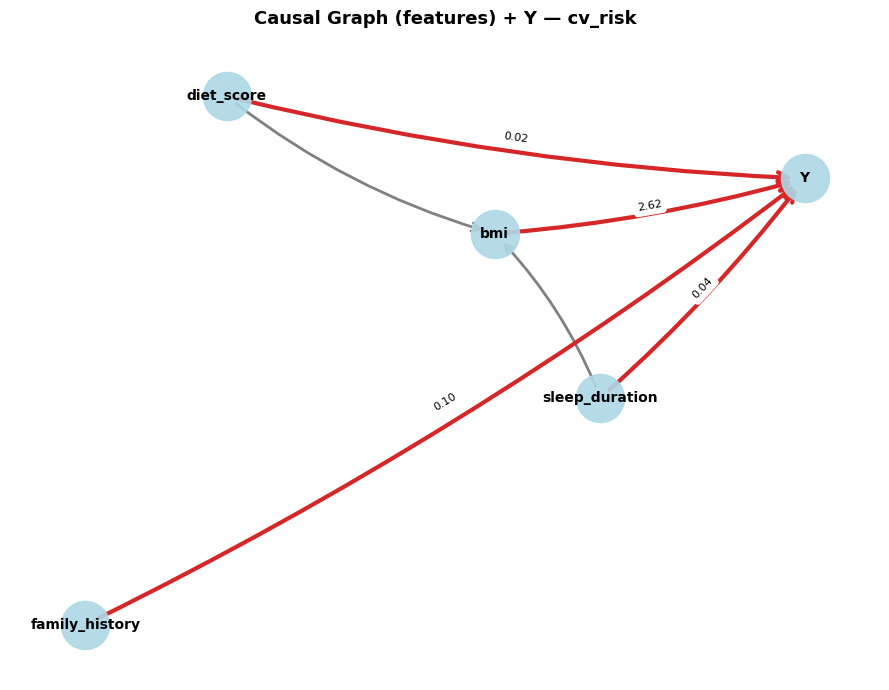

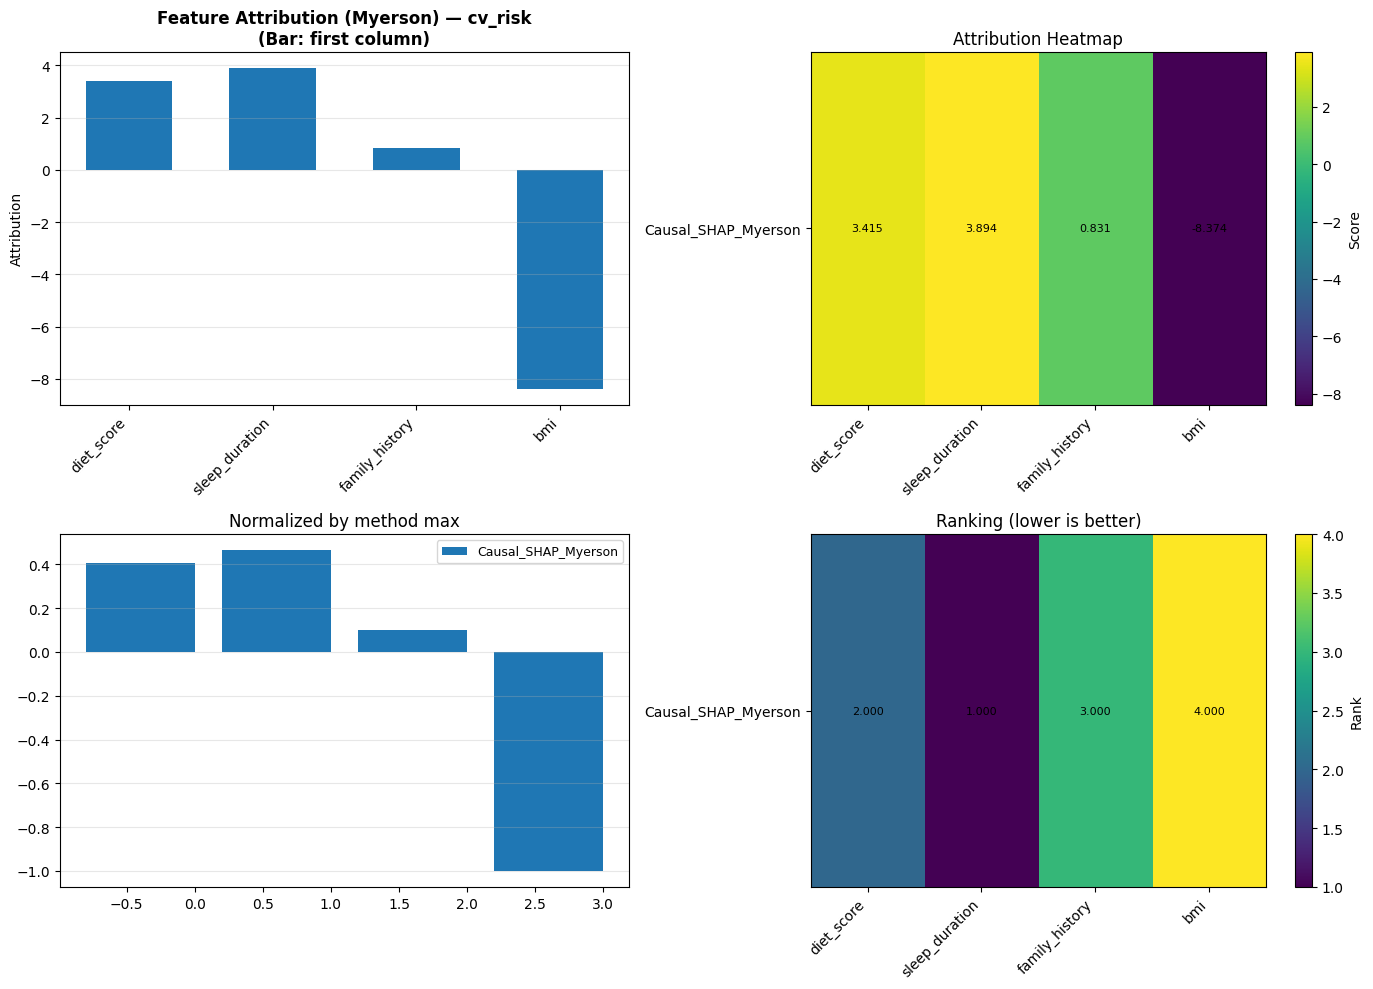


Causal SHAP (Myerson) on: lung_cancer_risk.csv
Using RandomForest (regression)
✓ Model: R2=0.7086, MAE=1.5185

----------------------------------------------------------------
Step 1: Causal discovery (PC)
----------------------------------------------------------------
Running PC on 3 features...
✓ PC completed -> CPDAG
Graph: 3 nodes, 2 edges
✓ Saved 'causal_graph_lung_cancer_risk.png'

----------------------------------------------------------------
Step 2: Causal SHAP (Myerson value)
----------------------------------------------------------------

Fitting SEMs & sampling DAGs ...
✓ Sampled 5 DAG(s)
Computing IDA-style total effects W_i ...
✓ W_i computed
✓ CausalSHAP ready

Total causal effects W_i and gamma_i:
  smoking               W=  2.818595   γ=0.588029
  stress                W=  1.696499   γ=0.353932
  drink_coffee          W=  0.278200   γ=0.058039

Computing global Causal SHAP (Myerson) over 30 instances ...
  5/30
  10/30
  15/30
  20/30
  25/30
  30/30

-------------

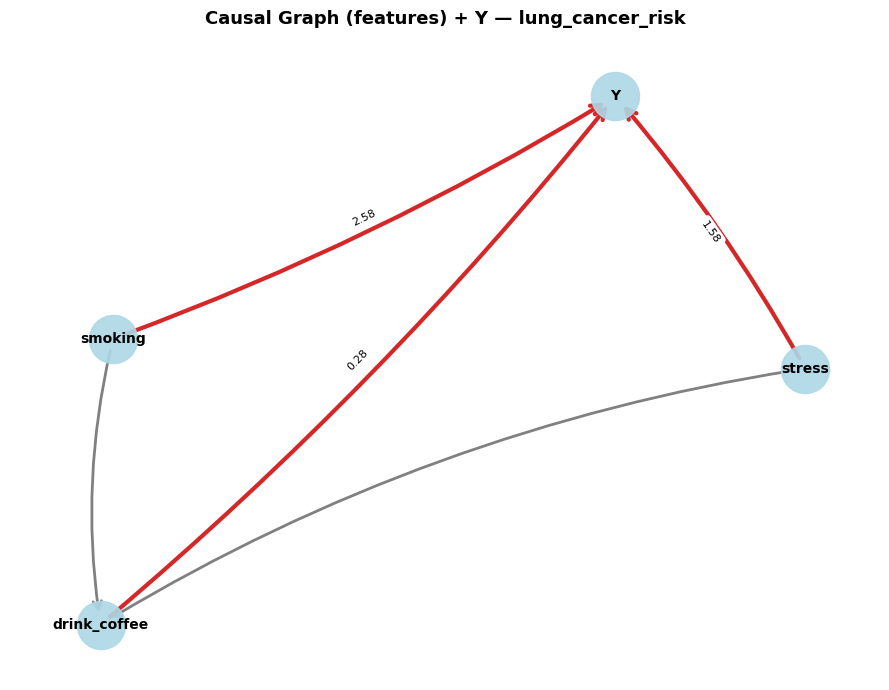

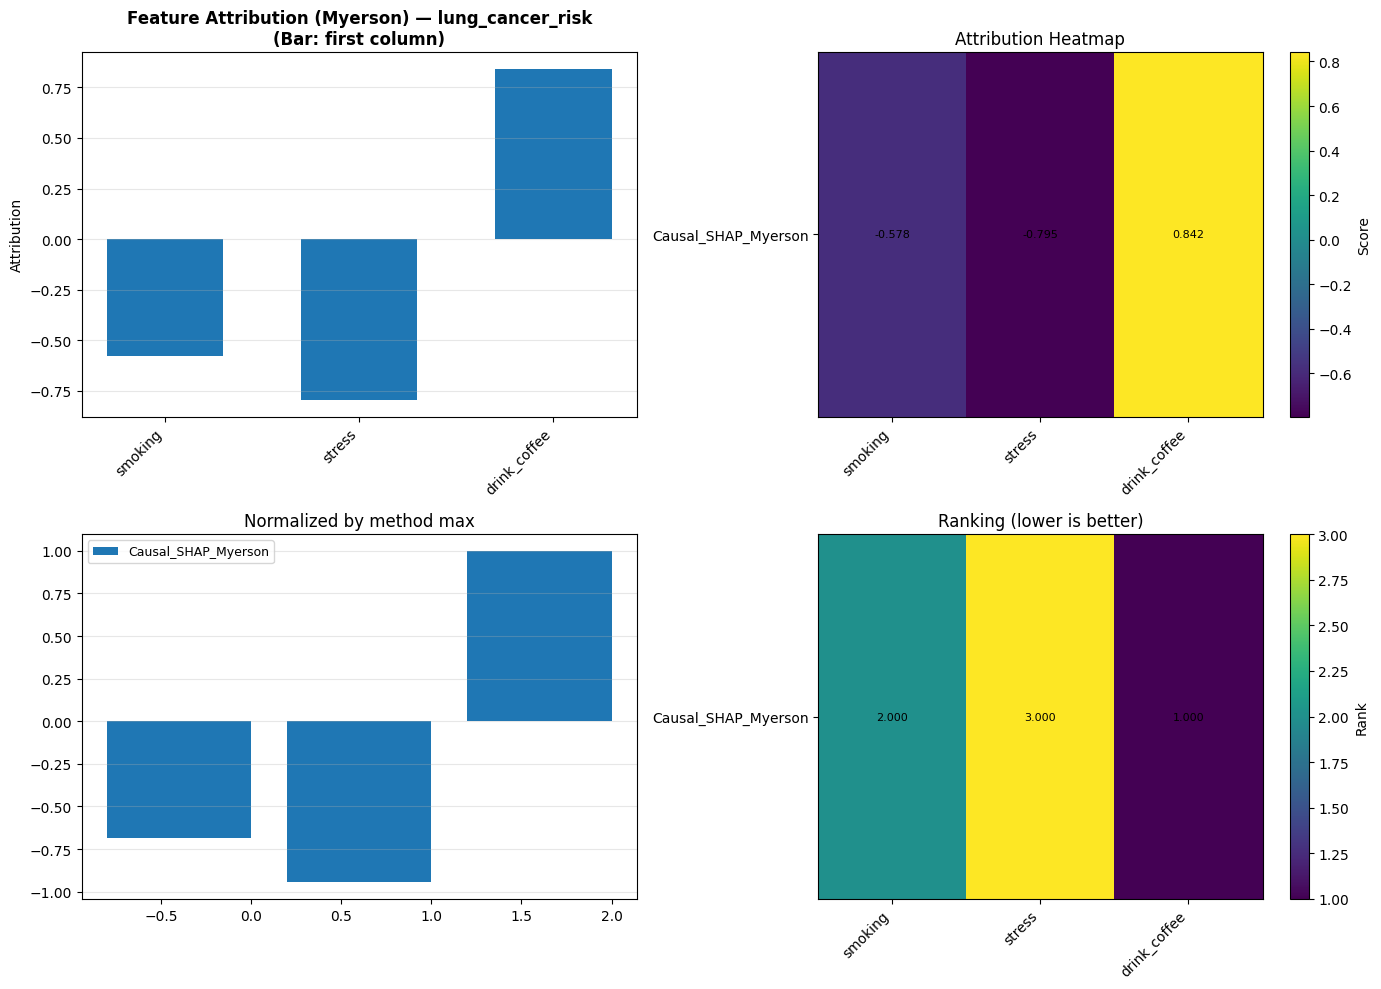

In [7]:
"""
Causal SHAP with Myerson Value (paper-faithful) for CSVs
- Pipelines:
  PC -> CPDAG -> DAG sampling -> linear SEMs -> IDA path effects W_i -> gamma_i -> Myerson-restricted Causal SHAP
- Datasets tested:
  /mnt/data/cv_risk.csv          (target auto-detected as last column or common names)
  /mnt/data/lung_cancer_risk.csv (same)
- Outputs per dataset:
  causal_graph_<name>.png
  attribution_scores_<name>.csv
  attribution_comparison_<name>.png
"""

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Set, Optional
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import f1_score, accuracy_score, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.utils.multiclass import type_of_target
import networkx as nx

# Optional XGBoost (falls back to RF if not available)
try:
    from xgboost import XGBClassifier, XGBRegressor
    HAVE_XGB = True
except Exception:
    HAVE_XGB = False

HAVE_XGB=False

from causallearn.search.ConstraintBased.PC import pc

CONFIG = {
    'ALPHA_PC': 0.1,        # PC test level
    'MAX_PERM': 200,        # permutations per instance for (Myerson) Shapley MC
    'M_RESAMPLES': 64,      # SEM samples per coalition evaluation
    'GLOBAL_K': 30,         # instances used for global averaging
    'RANDOM_SEED': 42,
    'N_DAGS': 5,            # DAGs sampled from CPDAG
    'SHOW_TARGET_IN_GRAPH': True,   # draw edges from features -> Y in the saved causal graph
}
np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])

COMMON_TARGET_NAMES = [
    "target","label","y","class","outcome",
    "cvd","cardio","TenYearCHD","heart_disease","stroke","risk",
    "cancer","lung_cancer","has_cancer","diagnosis","cv_risk","lung_cancer_risk"
]

def detect_target_column(df: pd.DataFrame, user_hint: Optional[str]=None) -> str:
    if user_hint and user_hint in df.columns:
        return user_hint
    lower_map = {c.lower(): c for c in df.columns}
    for name in COMMON_TARGET_NAMES:
        if name.lower() in lower_map:
            return lower_map[name.lower()]
    return df.columns[-1]

def drop_unnamed(df: pd.DataFrame) -> pd.DataFrame:
    return df[[c for c in df.columns if not re.match(r'^unnamed', c, re.I)]].copy()

def to_numeric_df(df: pd.DataFrame) -> pd.DataFrame:
    num = df.select_dtypes(include=[np.number]).copy()
    for c in df.columns:
        if c not in num.columns:
            try:
                num[c] = pd.to_numeric(df[c], errors='raise')
            except Exception:
                pass
    return num

class CausalStructure:
    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names: List[str] = []
        self.dags: List[nx.DiGraph] = []

    def discover(self, X: pd.DataFrame):
        self.feature_names = list(X.columns)
        print(f"Running PC on {len(self.feature_names)} features...")
        res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = res.G.graph
        print("PC completed -> CPDAG")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        """
        Return a directed graph that contains:
        - Directed edges for oriented CPDAG edges (i -> j)
        - Both directions for undirected CPDAG pairs (i - j)
        (We’ll use an undirected view of this for the Myerson communication graph.)
        """
        G = nx.DiGraph()
        G.add_nodes_from(self.feature_names)
        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                # Directed i->j encoded as (-1, +1)
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                # Undirected i - j: add both directions (once)
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1 and i < j:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                    G.add_edge(self.feature_names[j], self.feature_names[i])
        return G

    def sample_dags(self, n_samples: int) -> List[nx.DiGraph]:
        """
        Sample DAGs by orienting undirected CPDAG edges; ensure acyclicity.
        """
        dags = []
        names = self.feature_names
        n = len(names)
        undirected = []
        for i in range(n):
            for j in range(i+1, n):
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((names[i], names[j]))
        for _ in range(max(1, n_samples)):
            G = nx.DiGraph()
            G.add_nodes_from(names)
            for i in range(n):
                for j in range(n):
                    if i != j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(names[i], names[j])

            # orient undirected edges
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)
                # flip if a cycle appears
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v):
                        G.remove_edge(u, v); G.add_edge(v, u)
                    else:
                        G.remove_edge(v, u); G.add_edge(u, v)
                # if still cyclic, drop the edge
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v)
                    if G.has_edge(v, u): G.remove_edge(v, u)

            # last guard: greedily remove edges until DAG
            if not nx.is_directed_acyclic_graph(G):
                for (a, b) in list(G.edges()):
                    G.remove_edge(a, b)
                    if nx.is_directed_acyclic_graph(G):
                        break
                    else:
                        G.add_edge(a, b)
            dags.append(G)
        self.dags = dags
        print(f"Sampled {len(dags)} DAG(s)")
        return dags

class LinearMechanisms:
    """
    Fit a linear SEM on a given DAG so we can draw samples from
    P(X_{¬S} | do(X_S = x_S)) by forward-sampling in topological order.
    """
    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.feature_names = feature_names
        self.mechanisms: Dict[str, Dict] = {}
        self.topo: List[str] = []

    def fit(self, X: pd.DataFrame):
        try:
            self.topo = list(nx.topological_sort(self.dag))
        except Exception:
            self.topo = self._safe_topo()
        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))
            if not parents:
                self.mechanisms[var] = {
                    "parents": [],
                    "intercept": float(X[var].mean()),
                    "coef": None,
                    "sigma": float(X[var].std(ddof=0))
                }
            else:
                lr = LinearRegression().fit(X[parents].values, X[var].values)
                resid = X[var].values - lr.predict(X[parents].values)
                self.mechanisms[var] = {
                    "parents": parents,
                    "intercept": float(lr.intercept_),
                    "coef": lr.coef_.astype(float),
                    "sigma": float(np.std(resid, ddof=0))
                }
        return self

    def _safe_topo(self) -> List[str]:
        ordered, remaining = [], set(self.feature_names)
        while remaining:
            ready = [n for n in remaining if all(p in ordered or p not in remaining
                                                 for p in self.dag.predecessors(n))]
            if not ready:
                ready = [min(remaining, key=lambda n: len([p for p in self.dag.predecessors(n) if p in remaining]))]
            for n in ready:
                ordered.append(n); remaining.remove(n)
        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series) -> Dict[str, float]:
        """
        Sample one draw from the interventional distribution do(X_S = x_S)
        by traversing the DAG in topological order and sampling conditionals.
        """
        x_new: Dict[str, float] = {}
        for var in self.topo:
            if var in S:
                x_new[var] = float(x_obs[var])
                continue
            mech = self.mechanisms[var]
            if not mech["parents"]:
                mu, sigma = mech["intercept"], mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
            else:
                pvals = np.array([x_new.get(p, x_obs[p]) for p in mech["parents"]])
                mu = mech["intercept"] + pvals @ mech["coef"]
                sigma = mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
        return x_new

class CausalEffects:
    """
    For each sampled DAG, build an augmented graph with edge weights:
      - feature->feature: local regression coeff |β_uv|
      - feature->Y: one regression Y ~ all features, use |β_f|
    Then the total effect W_i is the sum over all path products i -> ... -> Y.
    Average W_i across DAGs; normalize to gamma_i.
    """
    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects: Dict[str, float] = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        print("Computing IDA-style total effects W_i ...")
        y_vals = y.values
        totals = {f: [] for f in self.feature_names}

        for dag in self.dags:
            G = dag.copy()
            G.add_node("Y")

            # (A) Edge weights among features
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                X_reg = np.column_stack([X[parents].values, X[u].values]) if parents else X[[u]].values
                lr = LinearRegression().fit(X_reg, X[v].values)
                w = float(abs(lr.coef_[-1]))
                if w > 1e-12:
                    G.add_edge(u, v, weight=w)

            # (B) Direct edges into Y: Y ~ all features
            paY = list(self.feature_names)
            lrY = LinearRegression().fit(X[paY].values, y_vals)
            for feat, w in zip(paY, np.abs(lrY.coef_)):
                if w > 1e-12:
                    G.add_edge(feat, "Y", weight=float(w))

            # (C) Sum of path products i -> ... -> Y
            for i_feat in self.feature_names:
                total = 0.0
                try:
                    for path in nx.all_simple_paths(G, i_feat, "Y", cutoff=10):
                        prod = 1.0
                        ok = True
                        for a, b in zip(path[:-1], path[1:]):
                            ed = G.get_edge_data(a, b)
                            if not ed or "weight" not in ed:
                                ok = False
                                break
                            prod *= ed["weight"]
                        if ok:
                            total += prod
                except Exception:
                    pass
                totals[i_feat].append(total)

        self.effects = {f: (float(np.mean(vals)) if len(vals) else 0.0) for f, vals in totals.items()}
        print("W_i computed")
        return self.effects

    def gamma_weights(self) -> Dict[str, float]:
        absW = {k: abs(v) for k, v in self.effects.items()}
        Z = sum(absW.values()) + 1e-12
        return {k: v / Z for k, v in absW.items()}

class CausalSHAP:
    def __init__(self, model, structure: CausalStructure, X_train: pd.DataFrame, y_train: pd.Series, task: str):
        self.model = model; self.structure = structure
        self.X_train = X_train; self.y_train = y_train
        self.features = list(X_train.columns); self.task = task

        print("\nFitting SEMs & sampling DAGs ...")
        self.dags = self.structure.sample_dags(CONFIG['N_DAGS'])
        self.sems = [LinearMechanisms(d, self.features).fit(X_train) for d in self.dags]

        self.effects = CausalEffects(self.dags, self.features)
        self.effects.compute_effects(X_train, y_train)
        self.gamma = self.effects.gamma_weights()
        self._Ef_cache = None
        print("CausalSHAP ready")

    # Scalar prediction for value function
    def _predict_scalar(self, X_mat: np.ndarray) -> float:
        if self.task == "classification":
            proba = self.model.predict_proba(X_mat)[0]
            return float(proba[np.argmax(proba)])  # predicted class probability
        else:  # regression
            return float(self.model.predict(X_mat)[0])

    # E[f(X)] baseline for normalization
    def _Ef(self) -> float:
        if self._Ef_cache is None:
            if self.task == "classification":
                P = self.model.predict_proba(self.X_train.values)
                self._Ef_cache = float(P.max(axis=1).mean())
            else:
                preds = self.model.predict(self.X_train.values)
                self._Ef_cache = float(np.mean(preds))
        return self._Ef_cache

    def _vc(self, S: Set[str], x: pd.Series, M: int) -> float:
        total = 0.0
        per = max(1, M // max(1, len(self.sems)))
        for sem in self.sems:
            for _ in range(per):
                x_sample = sem.sample_intervention(S, x)
                X_mat = pd.DataFrame([x_sample], columns=self.features).values
                total += self._predict_scalar(X_mat)
        N = per * max(1, len(self.sems))
        return total / N if N > 0 else 0.0

    def explain_instance(self, x: pd.Series, n_perms: int=None, M: int=None) -> pd.Series:
        # Base version (not Myerson): left unused; overridden below
        raise NotImplementedError

    def explain_global(self, X_test: pd.DataFrame, k: int=None) -> pd.Series:
        # Base version (not Myerson): left unused; overridden below
        raise NotImplementedError

class CausalSHAPMyerson(CausalSHAP):
    def __init__(self, model, structure: CausalStructure, X_train: pd.DataFrame, y_train: pd.Series, task: str):
        super().__init__(model, structure, X_train, y_train, task)
        # Build undirected communication graph from the CPDAG skeleton
        skel_dir = structure.get_skeleton()  # DiGraph with possible two-way edges
        self.comm_graph = nx.Graph()
        self.comm_graph.add_nodes_from(self.features)
        for u, v in skel_dir.edges():
            self.comm_graph.add_edge(u, v)

    def _vG(self, S: Set[str], x: pd.Series, M: int) -> float:
        """
        Myerson graph-restricted value:
        v^G(S) = sum_{connected components C in G[S]} v(C).
        """
        if not S:
            return self._vc(set(), x, M)
        sub = self.comm_graph.subgraph(S)
        total = 0.0
        for comp in nx.connected_components(sub):
            total += self._vc(set(comp), x, M)
        return total

    def explain_instance(self, x: pd.Series, n_perms: int=None, M: int=None) -> pd.Series:
        if n_perms is None: n_perms = CONFIG['MAX_PERM']
        if M is None: M = CONFIG['M_RESAMPLES']
        fx = self._predict_scalar(pd.DataFrame([x], columns=self.features).values)
        phi = np.zeros(len(self.features), dtype=float)

        # Myerson permutation Monte Carlo on v^G
        for _ in range(n_perms):
            perm = rng.permutation(self.features)
            S: Set[str] = set()
            v_prev = self._vG(S, x, M)
            for feat in perm:
                S_next = S | {feat}
                v_curr = self._vG(S_next, x, M)
                delta = v_curr - v_prev
                # Paper’s weighting by gamma_i (IDA strength)
                phi[self.features.index(feat)] += self.gamma[feat] * delta
                v_prev, S = v_curr, S_next

        phi /= n_perms
        # Normalize to enforce local accuracy around E[f(X)]
        sum_phi = float(np.sum(phi))
        if abs(sum_phi) > 1e-12:
            Ef = self._Ef()
            phi = phi * ((fx - Ef) / sum_phi)
        return pd.Series(phi, index=self.features, name="Causal_SHAP_Myerson")

    def explain_global(self, X_test: pd.DataFrame, k: int=None) -> pd.Series:
        if k is None: k = CONFIG['GLOBAL_K']
        k = min(k, len(X_test))
        idx = rng.choice(len(X_test), size=k, replace=False)
        print(f"\nComputing global Causal SHAP (Myerson) over {k} instances ...")
        exps = []
        for t, i in enumerate(idx, 1):
            if t % 5 == 0:
                print(f"  {t}/{k}")
            exps.append(self.explain_instance(
                X_test.iloc[i], n_perms=max(10, CONFIG['MAX_PERM']//4)))
        return pd.concat(exps, axis=1).mean(axis=1).rename("Causal_SHAP_Global_Myerson")

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1])); ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticks(np.arange(data.shape[0])); ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax); cbar.set_label(cbar_label)
    ax.set_title(title)

def plot_comparison(df: pd.DataFrame, title="Feature Attribution Comparison"):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    # Bar for first column
    axes[0, 0].bar(np.arange(df.shape[0]), df.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\n(Bar: first column)', fontsize=12, fontweight='bold')
    axes[0, 0].set_xticks(np.arange(df.shape[0])); axes[0, 0].set_xticklabels(df.index, rotation=45, ha='right')
    axes[0, 0].set_ylabel('Attribution'); axes[0, 0].grid(axis='y', alpha=0.3)
    # Heatmap of values
    annotate_heatmap(axes[0, 1], df.T, 'Attribution Heatmap', 'Score')
    # Normalized comparison (by method max abs)
    df_norm = df.div(df.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)),
                       df_norm[col], width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized by method max'); axes[1, 0].legend(fontsize=9); axes[1, 0].grid(axis='y', alpha=0.3)
    # Rank heatmap
    ranks = df.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Ranking (lower is better)', 'Rank')
    fig.tight_layout(); return fig

def plot_causal_graph_with_target(G_features: nx.DiGraph, X: pd.DataFrame, y: pd.Series, title="Causal Graph with Y"):
    """
    Draw the feature graph and add a Y node with weighted edges from features
    based on a single linear regression Y ~ all features (abs coefficients).
    """
    # Build augmented graph
    G = nx.DiGraph()
    G.add_nodes_from(G_features.nodes())
    G.add_edges_from(G_features.edges())
    # Fit Y ~ all X to get |beta_f|
    lrY = LinearRegression().fit(X.values, y.values)
    betas = dict(zip(X.columns, np.abs(lrY.coef_)))
    G.add_node("Y")
    for f, w in betas.items():
        if w > 1e-12:
            G.add_edge(f, "Y", weight=float(w))

    # Layout & draw
    plt.figure(figsize=(9, 7))
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)
    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    # Draw feature->feature edges
    ff_edges = [(u, v) for (u, v) in G.edges() if v != "Y"]
    nx.draw_networkx_edges(G, pos, edgelist=ff_edges, edge_color='gray', arrows=True, arrowsize=15,
                           width=2, arrowstyle='->', connectionstyle='arc3,rad=0.1')
    # Draw feature->Y edges thicker
    fy_edges = [(u, v) for (u, v) in G.edges() if v == "Y"]
    nx.draw_networkx_edges(G, pos, edgelist=fy_edges, edge_color='tab:red', arrows=True, arrowsize=18,
                           width=3, arrowstyle='->', connectionstyle='arc3,rad=0.05')
    # Labels
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')
    # Edge labels for feature->Y
    e_labels = {(u, v): f"{G[u][v].get('weight', 0):.2f}" for (u, v) in fy_edges}
    nx.draw_networkx_edge_labels(G, pos, edge_labels=e_labels, font_size=8)
    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off'); plt.tight_layout()
    return plt.gcf()

def run_causal_shap_on_csv(csv_path: str, dataset_name: Optional[str]=None, target_hint: Optional[str]=None, test_size: float=0.25):
    print("\n" + "="*72)
    print(f"Causal SHAP (Myerson) on: {csv_path}")
    print("="*72)

    # Load
    try:
        raw = pd.read_csv(csv_path)
    except Exception as e:
        print(f"ERROR reading CSV: {e}"); return

    raw = drop_unnamed(raw)
    if dataset_name is None:
        dataset_name = csv_path.split("/")[-1].split(".")[0]

    tgt_col = detect_target_column(raw, target_hint)
    if tgt_col not in raw.columns:
        print("ERROR: target column not found."); return

    y_raw = raw[tgt_col].copy()
    X_raw = raw.drop(columns=[tgt_col])

    X_num = to_numeric_df(X_raw)
    dropped = set(X_raw.columns) - set(X_num.columns)
    if dropped:
        print(f"Note: Dropping non-numeric columns: {sorted(list(dropped))}")

    X_num = X_num.replace([np.inf, -np.inf], np.nan).fillna(X_num.median(numeric_only=True))

    y_type = type_of_target(y_raw)
    if y_type in ["binary","multiclass"]:
        task = "classification"
        y_vec = y_raw.astype(int).values
    else:
        task = "regression"
        y_vec = pd.to_numeric(y_raw, errors="coerce").values
        if np.isnan(y_vec).any():
            print("ERROR: target has non-numeric values that cannot be coerced."); return

    strat = y_vec if (task=="classification" and len(np.unique(y_vec))>1) else None
    X_train, X_test, y_train, y_test = train_test_split(
        X_num, y_vec, test_size=test_size, random_state=CONFIG['RANDOM_SEED'], stratify=strat
    )

    scaler = StandardScaler()
    Xtr = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
    Xte = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns,  index=X_test.index)

    # Model
    if task=="classification":
        n_classes = int(len(np.unique(y_train)))
        if HAVE_XGB:
            model = XGBClassifier(
                n_estimators=160, max_depth=5, learning_rate=0.08,
                subsample=0.9, colsample_bytree=0.9,
                random_state=CONFIG['RANDOM_SEED'], verbosity=0,
                objective="multi:softprob" if n_classes>2 else "binary:logistic",
                num_class=n_classes if n_classes>2 else None
            )
            print("Using XGBoost (classification)")
        else:
            model = RandomForestClassifier(n_estimators=160, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
            print("Using RandomForest (classification)")
        model.fit(Xtr.values, y_train)
        y_pred = model.predict(Xte.values)
        acc = accuracy_score(y_test, y_pred); f1m = f1_score(y_test, y_pred, average='macro')
        print(f"Model: acc={acc:.4f}, macroF1={f1m:.4f}, classes={n_classes}")
    else:
        if HAVE_XGB:
            model = XGBRegressor(
                n_estimators=200, max_depth=5, learning_rate=0.08,
                subsample=0.9, colsample_bytree=0.9,
                random_state=CONFIG['RANDOM_SEED']
            )
            print("Using XGBoost (regression)")
        else:
            model = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
            print("Using RandomForest (regression)")
        model.fit(Xtr.values, y_train)
        y_pred = model.predict(Xte.values)
        r2 = r2_score(y_test, y_pred); mae = mean_absolute_error(y_test, y_pred)
        print(f"Model: R2={r2:.4f}, MAE={mae:.4f}")

    # Step 1: PC discovery
    print("\n" + "-"*64)
    print("Step 1: Causal discovery (PC)")
    print("-"*64)
    cs = CausalStructure(alpha=CONFIG['ALPHA_PC']).discover(Xtr)
    G_skel = cs.get_skeleton()
    print(f"Graph: {G_skel.number_of_nodes()} nodes, {G_skel.number_of_edges()} edges")

    if CONFIG['SHOW_TARGET_IN_GRAPH']:
        fig = plot_causal_graph_with_target(G_skel, Xtr, pd.Series(y_train),
                                            title=f"Causal Graph (features) + Y — {dataset_name}")
    else:
        plt.figure(figsize=(8, 6))
        pos = nx.spring_layout(G_skel, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)
        nx.draw_networkx_nodes(G_skel, pos, node_color='lightblue', node_size=1200, alpha=0.9)
        nx.draw_networkx_edges(G_skel, pos, edge_color='gray', arrows=True, arrowsize=15,
                               width=2, arrowstyle='->', connectionstyle='arc3,rad=0.1')
        nx.draw_networkx_labels(G_skel, pos, font_size=10, font_weight='bold')
        plt.title(f"Discovered Causal Graph (PC) — {dataset_name}", fontsize=13, fontweight='bold', pad=12)
        plt.axis('off'); plt.tight_layout()
        fig = plt.gcf()

    fig.savefig(f'causal_graph_{dataset_name}.png', dpi=150, bbox_inches='tight')
    print(f"Saved 'causal_graph_{dataset_name}.png'")

    # Step 2: Myerson Causal SHAP
    print("\n" + "-"*64)
    print("Step 2: Causal SHAP (Myerson value)")
    print("-"*64)
    cshap = CausalSHAPMyerson(model, cs, Xtr, pd.Series(y_train), task=task)

    print("\nTotal causal effects W_i and gamma_i:")
    for f in Xtr.columns:
        print(f"  {f:20s}  W={cshap.effects.effects[f]:10.6f}   γ={cshap.gamma[f]:.6f}")

    glob = cshap.explain_global(Xte, k=min(CONFIG['GLOBAL_K'], len(Xte)))

    # Step 3: Save/plot comparison
    cols = {"Causal_SHAP_Myerson": glob}
    df = pd.DataFrame(cols)
    df.to_csv(f"attribution_scores_{dataset_name}.csv", index=True)
    print("\n" + "-"*64)
    print("Step 3: Comparison & Save")
    print("-"*64)
    print(df.round(6).to_string())
    print(f"\nSaved: attribution_scores_{dataset_name}.csv")

    fig2 = plot_comparison(df, title=f"Feature Attribution (Myerson) — {dataset_name}")
    fig2.savefig(f'attribution_comparison_{dataset_name}.png', dpi=150, bbox_inches='tight')
    print(f"Saved 'attribution_comparison_{dataset_name}.png'")

    try: plt.show()
    except Exception: pass

def main():
    # Update these paths if needed
    run_causal_shap_on_csv("cv_risk.csv", dataset_name="cv_risk")
    run_causal_shap_on_csv("lung_cancer_risk.csv", dataset_name="lung_cancer_risk")

if __name__ == "__main__":
    main()


Causal SHAP (Myerson) on: cv_risk.csv
✓ Model: R2=0.6623, MAE=1.3549

----------------------------------------------------------------
Step 1: Causal discovery (PC)
----------------------------------------------------------------
Running PC on 4 features...
✓ PC completed -> CPDAG
Graph: 4 nodes, 2 directed edges
✓ Saved 'causal_graph_cv_risk.png'

----------------------------------------------------------------
Step 2: Causal SHAP (Myerson value)
----------------------------------------------------------------

Fitting SEMs & sampling DAGs ...
✓ Sampled 5 DAG(s)
Computing IDA-style total effects W_i ...
✓ W_i computed
✓ CausalSHAP ready

Total causal effects W_i and gamma_i (diagnostic):
  diet_score            W=  1.557027   γ=0.268893
  sleep_duration        W=  1.514280   γ=0.261510
  family_history        W=  0.097514   γ=0.016840
  bmi                   W=  2.621693   γ=0.452757

Fitting SEMs & sampling DAGs ...
✓ Sampled 5 DAG(s)
Computing IDA-style total effects W_i ...
✓ W_i 

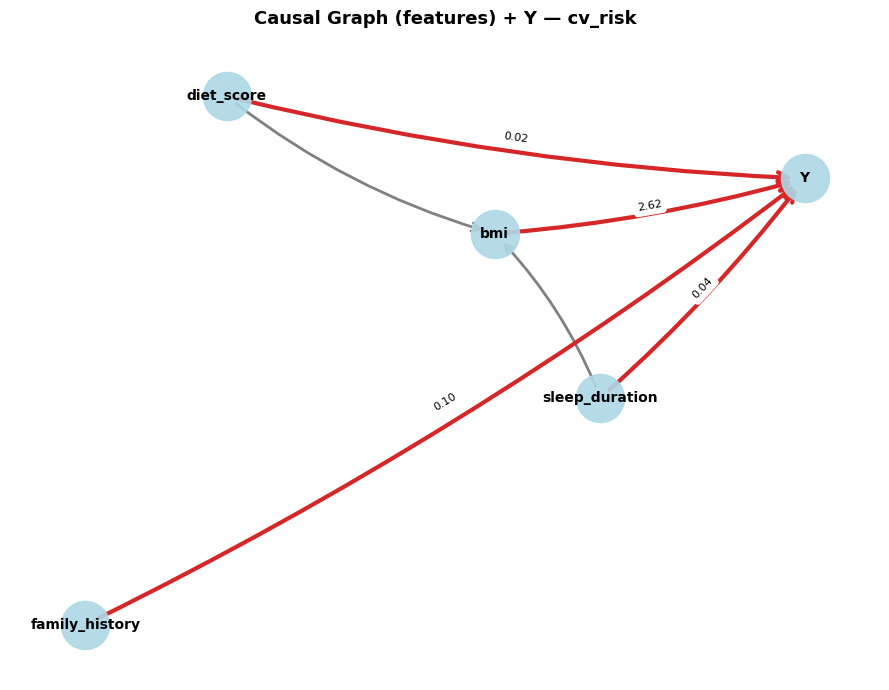

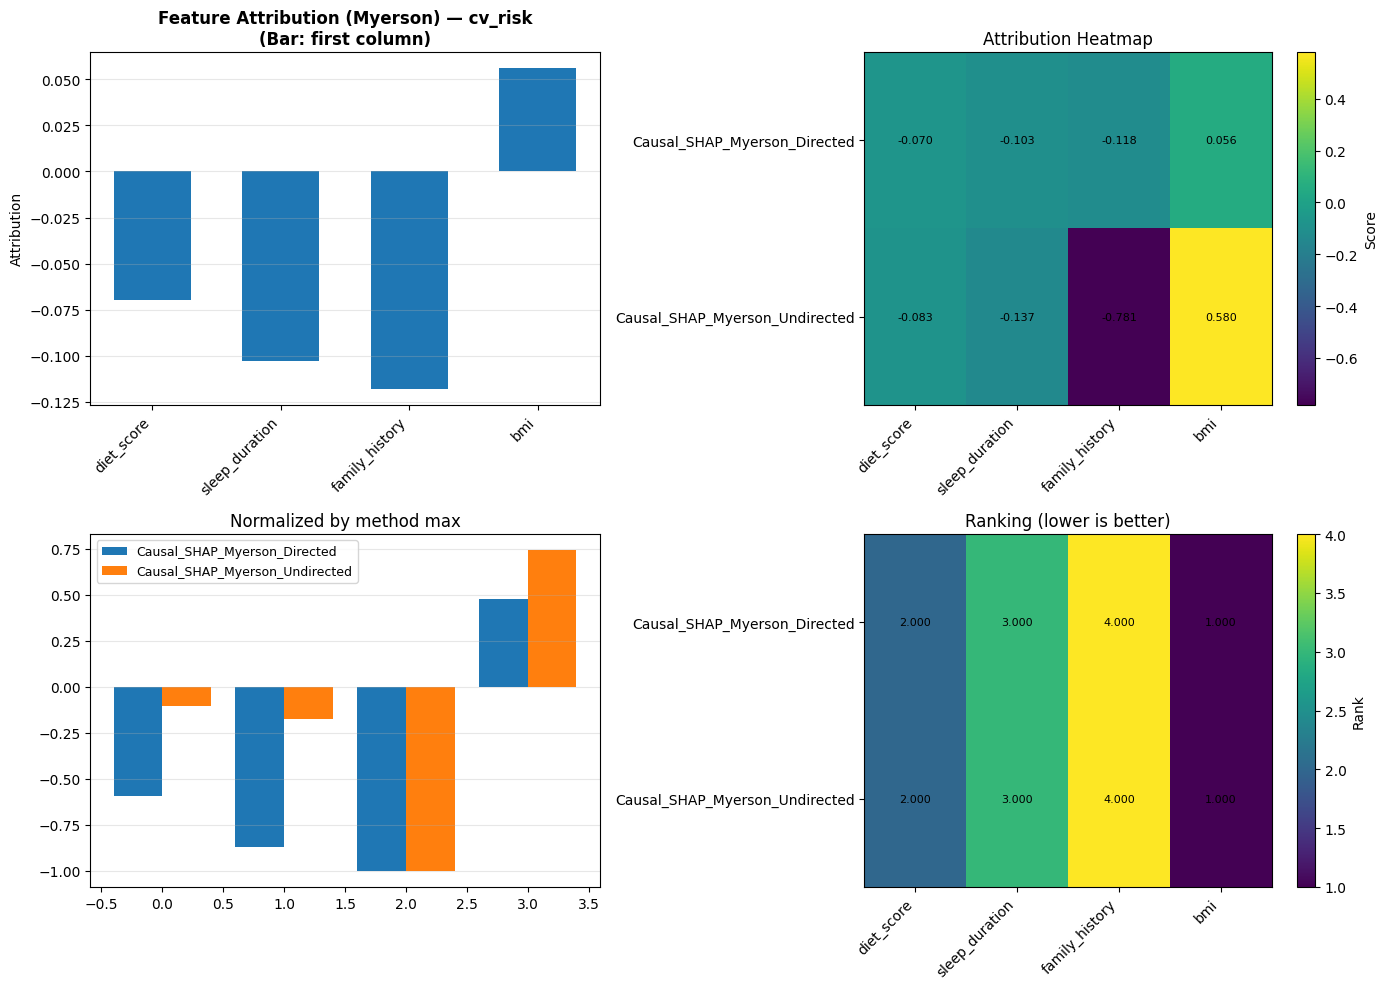


Causal SHAP (Myerson) on: lung_cancer_risk.csv
✓ Model: R2=0.7086, MAE=1.5185

----------------------------------------------------------------
Step 1: Causal discovery (PC)
----------------------------------------------------------------
Running PC on 3 features...
✓ PC completed -> CPDAG
Graph: 3 nodes, 2 directed edges
✓ Saved 'causal_graph_lung_cancer_risk.png'

----------------------------------------------------------------
Step 2: Causal SHAP (Myerson value)
----------------------------------------------------------------

Fitting SEMs & sampling DAGs ...
✓ Sampled 5 DAG(s)
Computing IDA-style total effects W_i ...
✓ W_i computed
✓ CausalSHAP ready

Total causal effects W_i and gamma_i (diagnostic):
  smoking               W=  2.818595   γ=0.588029
  stress                W=  1.696499   γ=0.353932
  drink_coffee          W=  0.278200   γ=0.058039

Fitting SEMs & sampling DAGs ...
✓ Sampled 5 DAG(s)
Computing IDA-style total effects W_i ...
✓ W_i computed
✓ CausalSHAP ready

Com

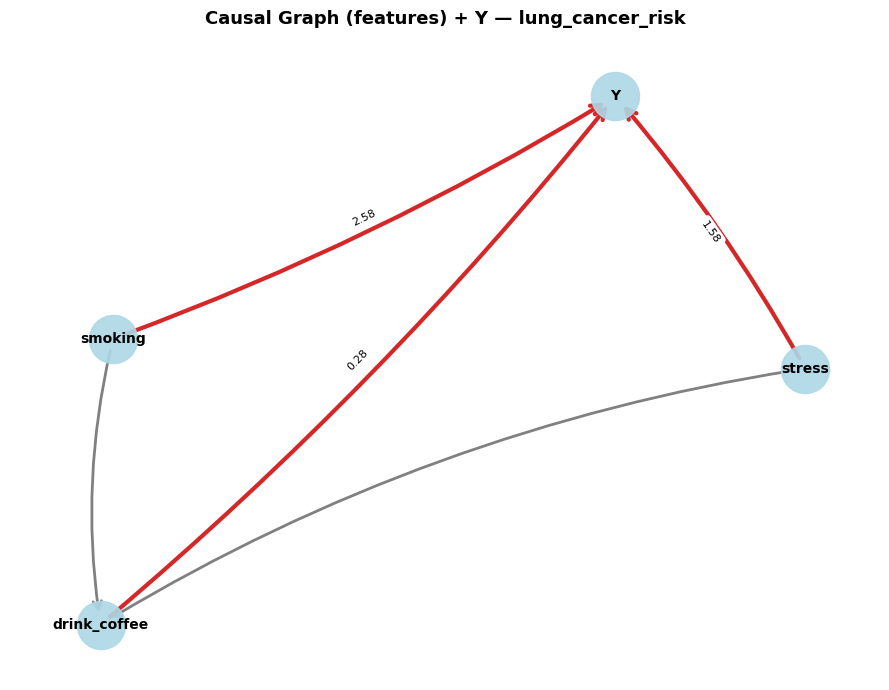

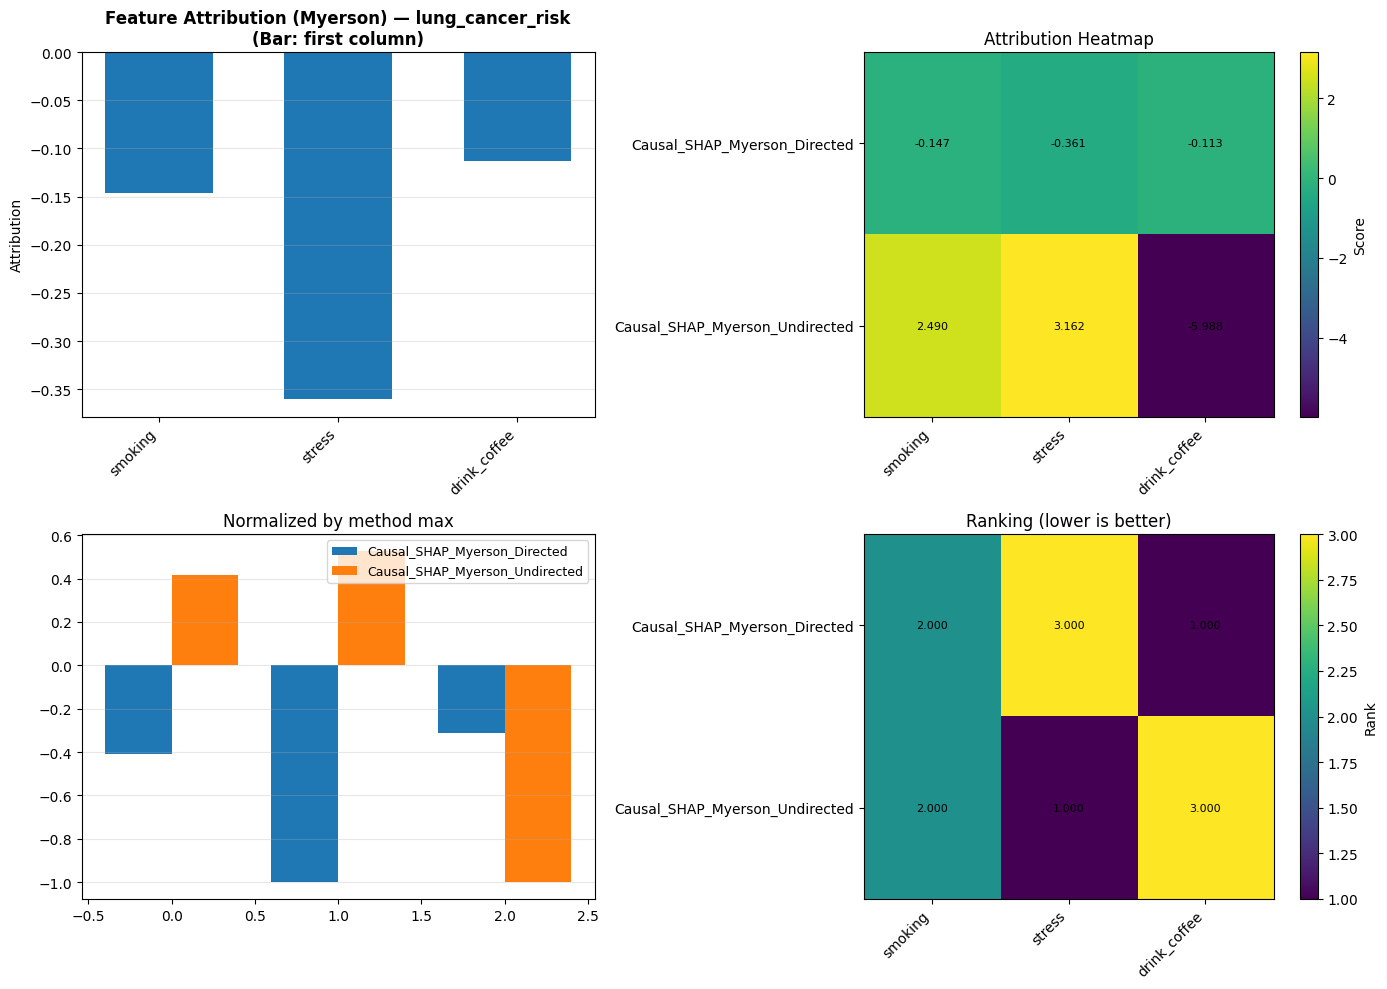

In [8]:
"""
Causal SHAP with Myerson Value (paper-faithful) for CSVs
- Pipelines:
  PC -> CPDAG -> DAG sampling -> linear SEMs -> IDA path effects W_i -> gamma_i (diagnostic) -> Myerson-restricted Causal SHAP
- Datasets tested:
  ./cv_risk.csv
  ./lung_cancer_risk.csv
- Outputs per dataset:
  causal_graph_<name>.png
  attribution_scores_<name>.csv
  attribution_comparison_<name>.png
"""

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Set, Optional
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import f1_score, accuracy_score, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.utils.multiclass import type_of_target
import networkx as nx

# Optional XGBoost (falls back to RF if not available)
try:
    from xgboost import XGBClassifier, XGBRegressor
    HAVE_XGB = True
except Exception:
    HAVE_XGB = False

HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

CONFIG = {
    'ALPHA_PC': 0.1,        # PC test level
    'MAX_PERM': 200,        # permutations per instance for Myerson Shapley MC
    'M_RESAMPLES': 64,      # SEM samples per coalition evaluation
    'GLOBAL_K': 30,         # instances used for global averaging
    'RANDOM_SEED': 42,
    'N_DAGS': 5,            # DAGs sampled from CPDAG
    'SHOW_TARGET_IN_GRAPH': True,   # draw edges from features -> Y in the saved causal graph
    'COMPARE_BOTH_MODES': True,     # if True, output both directed & undirected Myerson
}
np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])

COMMON_TARGET_NAMES = [
    "target","label","y","class","outcome",
    "cvd","cardio","TenYearCHD","heart_disease","stroke","risk",
    "cancer","lung_cancer","has_cancer","diagnosis","cv_risk","lung_cancer_risk"
]

def detect_target_column(df: pd.DataFrame, user_hint: Optional[str]=None) -> str:
    if user_hint and user_hint in df.columns:
        return user_hint
    lower_map = {c.lower(): c for c in df.columns}
    for name in COMMON_TARGET_NAMES:
        if name.lower() in lower_map:
            return lower_map[name.lower()]
    return df.columns[-1]

def drop_unnamed(df: pd.DataFrame) -> pd.DataFrame:
    return df[[c for c in df.columns if not re.match(r'^unnamed', c, re.I)]].copy()

def to_numeric_df(df: pd.DataFrame) -> pd.DataFrame:
    num = df.select_dtypes(include=[np.number]).copy()
    for c in df.columns:
        if c not in num.columns:
            try:
                num[c] = pd.to_numeric(df[c], errors='raise')
            except Exception:
                pass
    return num

class CausalStructure:
    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names: List[str] = []
        self.dags: List[nx.DiGraph] = []

    def discover(self, X: pd.DataFrame):
        self.feature_names = list(X.columns)
        print(f"Running PC on {len(self.feature_names)} features...")
        res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = res.G.graph
        print("PC completed -> CPDAG")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        """
        Return a directed graph that contains:
        - Directed edges for oriented CPDAG edges (i -> j)
        - Both directions for undirected CPDAG pairs (i - j)
        This DiGraph can be viewed as the communication digraph for 'directed Myerson':
        SCCs of the induced subgraph define feasible coalitions.
        """
        G = nx.DiGraph()
        G.add_nodes_from(self.feature_names)
        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                # Directed i->j encoded as (-1, +1)
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                # Undirected i - j: add both directions (once)
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1 and i < j:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                    G.add_edge(self.feature_names[j], self.feature_names[i])
        return G

    def sample_dags(self, n_samples: int) -> List[nx.DiGraph]:
        """
        Sample DAGs by orienting undirected CPDAG edges; ensure acyclicity.
        """
        dags = []
        names = self.feature_names
        n = len(names)
        undirected = []
        for i in range(n):
            for j in range(i+1, n):
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((names[i], names[j]))
        for _ in range(max(1, n_samples)):
            G = nx.DiGraph()
            G.add_nodes_from(names)
            for i in range(n):
                for j in range(n):
                    if i != j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(names[i], names[j])

            # orient undirected edges
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)
                # If a cycle appears, try flipping, otherwise drop
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v):
                        G.remove_edge(u, v); G.add_edge(v, u)
                    else:
                        G.remove_edge(v, u); G.add_edge(u, v)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v)
                    if G.has_edge(v, u): G.remove_edge(v, u)

            # last guard: greedily remove edges until DAG (rarely needed)
            if not nx.is_directed_acyclic_graph(G):
                for (a, b) in list(G.edges()):
                    G.remove_edge(a, b)
                    if nx.is_directed_acyclic_graph(G):
                        break
                    else:
                        G.add_edge(a, b)
            dags.append(G)
        self.dags = dags
        print(f"Sampled {len(dags)} DAG(s)")
        return dags

class LinearMechanisms:
    """
    Fit a linear SEM on a given DAG so we can draw samples from
    P(X_{¬S} | do(X_S = x_S)) by forward-sampling in topological order.
    """
    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.feature_names = feature_names
        self.mechanisms: Dict[str, Dict] = {}
        self.topo: List[str] = []

    def fit(self, X: pd.DataFrame):
        try:
            self.topo = list(nx.topological_sort(self.dag))
        except Exception:
            self.topo = self._safe_topo()
        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))
            if not parents:
                self.mechanisms[var] = {
                    "parents": [],
                    "intercept": float(X[var].mean()),
                    "coef": None,
                    "sigma": float(X[var].std(ddof=0))
                }
            else:
                lr = LinearRegression().fit(X[parents].values, X[var].values)
                resid = X[var].values - lr.predict(X[parents].values)
                self.mechanisms[var] = {
                    "parents": parents,
                    "intercept": float(lr.intercept_),
                    "coef": lr.coef_.astype(float),
                    "sigma": float(np.std(resid, ddof=0))
                }
        return self

    def _safe_topo(self) -> List[str]:
        ordered, remaining = [], set(self.feature_names)
        while remaining:
            ready = [n for n in remaining if all(p in ordered or p not in remaining
                                                 for p in self.dag.predecessors(n))]
            if not ready:
                ready = [min(remaining, key=lambda n: len([p for p in self.dag.predecessors(n) if p in remaining]))]
            for n in ready:
                ordered.append(n); remaining.remove(n)
        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series) -> Dict[str, float]:
        """
        Sample one draw from the interventional distribution do(X_S = x_S)
        by traversing the DAG in topological order and sampling conditionals.
        """
        x_new: Dict[str, float] = {}
        for var in self.topo:
            if var in S:
                x_new[var] = float(x_obs[var])
                continue
            mech = self.mechanisms[var]
            if not mech["parents"]:
                mu, sigma = mech["intercept"], mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
            else:
                pvals = np.array([x_new.get(p, x_obs[p]) for p in mech["parents"]])
                mu = mech["intercept"] + pvals @ mech["coef"]
                sigma = mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
        return x_new

class CausalEffects:
    """
    For each sampled DAG, build an augmented graph with edge weights:
      - feature->feature: local regression coeff |β_uv|
      - feature->Y: one regression Y ~ all features, use |β_f|
    Then the total effect W_i is the sum over all path products i -> ... -> Y.
    Average W_i across DAGs; normalize to gamma_i (diagnostic only).
    """
    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects: Dict[str, float] = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        print("Computing IDA-style total effects W_i ...")
        y_vals = y.values
        totals = {f: [] for f in self.feature_names}

        for dag in self.dags:
            G = dag.copy()
            G.add_node("Y")

            # (A) Edge weights among features
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                X_reg = np.column_stack([X[parents].values, X[u].values]) if parents else X[[u]].values
                lr = LinearRegression().fit(X_reg, X[v].values)
                w = float(abs(lr.coef_[-1]))
                if w > 1e-12:
                    G.add_edge(u, v, weight=w)

            # (B) Direct edges into Y: Y ~ all features
            paY = list(self.feature_names)
            lrY = LinearRegression().fit(X[paY].values, y_vals)
            for feat, w in zip(paY, np.abs(lrY.coef_)):
                if w > 1e-12:
                    G.add_edge(feat, "Y", weight=float(w))

            # (C) Sum of path products i -> ... -> Y
            for i_feat in self.feature_names:
                total = 0.0
                try:
                    for path in nx.all_simple_paths(G, i_feat, "Y", cutoff=10):
                        prod = 1.0
                        ok = True
                        for a, b in zip(path[:-1], path[1:]):
                            ed = G.get_edge_data(a, b)
                            if not ed or "weight" not in ed:
                                ok = False
                                break
                            prod *= ed["weight"]
                        if ok:
                            total += prod
                except Exception:
                    pass
                totals[i_feat].append(total)

        self.effects = {f: (float(np.mean(vals)) if len(vals) else 0.0) for f, vals in totals.items()}
        print("W_i computed")
        return self.effects

    def gamma_weights(self) -> Dict[str, float]:
        absW = {k: abs(v) for k, v in self.effects.items()}
        Z = sum(absW.values()) + 1e-12
        return {k: v / Z for k, v in absW.items()}

class CausalSHAP:
    def __init__(self, model, structure: CausalStructure, X_train: pd.DataFrame, y_train: pd.Series, task: str):
        self.model = model; self.structure = structure
        self.X_train = X_train; self.y_train = y_train
        self.features = list(X_train.columns); self.task = task

        print("\nFitting SEMs & sampling DAGs ...")
        self.dags = self.structure.sample_dags(CONFIG['N_DAGS'])
        self.sems = [LinearMechanisms(d, self.features).fit(X_train) for d in self.dags]

        self.effects = CausalEffects(self.dags, self.features)
        self.effects.compute_effects(X_train, y_train)
        self.gamma = self.effects.gamma_weights()  # diagnostics only
        self._Ef_cache = None
        print("CausalSHAP ready")

    # Scalar prediction for value function
    def _predict_scalar(self, X_mat: np.ndarray) -> float:
        if self.task == "classification":
            proba = self.model.predict_proba(X_mat)[0]
            return float(proba[np.argmax(proba)])  # predicted class probability
        else:  # regression
            return float(self.model.predict(X_mat)[0])

    # E[f(X)] baseline for normalization
    def _Ef(self) -> float:
        if self._Ef_cache is None:
            if self.task == "classification":
                P = self.model.predict_proba(self.X_train.values)
                self._Ef_cache = float(P.max(axis=1).mean())
            else:
                preds = self.model.predict(self.X_train.values)
                self._Ef_cache = float(np.mean(preds))
        return self._Ef_cache

    def _vc(self, S: Set[str], x: pd.Series, M: int) -> float:
        total = 0.0
        per = max(1, M // max(1, len(self.sems)))
        for sem in self.sems:
            for _ in range(per):
                x_sample = sem.sample_intervention(S, x)
                X_mat = pd.DataFrame([x_sample], columns=self.features).values
                total += self._predict_scalar(X_mat)
        N = per * max(1, len(self.sems))
        return total / N if N > 0 else 0.0

    def explain_instance(self, x: pd.Series, n_perms: int=None, M: int=None) -> pd.Series:
        raise NotImplementedError

    def explain_global(self, X_test: pd.DataFrame, k: int=None) -> pd.Series:
        raise NotImplementedError

class CausalSHAPMyerson(CausalSHAP):
    """
    mode = "directed"  -> paper-faithful: use SCCs of the directed communication graph (from CPDAG)
    mode = "undirected"-> classic Myerson on an undirected skeleton (connected components)
    """
    def __init__(self, model, structure: CausalStructure, X_train: pd.DataFrame, y_train: pd.Series, task: str, mode: str = "directed"):
        self.mode = mode
        super().__init__(model, structure, X_train, y_train, task)

        # Build communication graphs
        skel_dir = structure.get_skeleton()  # DiGraph with possible two-way edges
        if self.mode == "directed":
            self.comm_digraph = nx.DiGraph()
            self.comm_digraph.add_nodes_from(self.features)
            self.comm_digraph.add_edges_from(skel_dir.edges())
        else:
            # Undirected projection for classic Myerson
            self.comm_graph = nx.Graph()
            self.comm_graph.add_nodes_from(self.features)
            for u, v in skel_dir.edges():
                self.comm_graph.add_edge(u, v)

    def _v_restricted(self, S: Set[str], x: pd.Series, M: int) -> float:
        """
        Restricted game:
        - Directed mode: v^D(S) = sum_{T in SCCs(D[S])} v(T)
        - Undirected mode: v^G(S) = sum_{C in CCs(G[S])}  v(C)
        """
        if not S:
            return self._vc(set(), x, M)
        total = 0.0
        if self.mode == "directed":
            sub = self.comm_digraph.subgraph(S).copy()
            for comp in nx.strongly_connected_components(sub):
                total += self._vc(set(comp), x, M)
        else:
            sub = self.comm_graph.subgraph(S)
            for comp in nx.connected_components(sub):
                total += self._vc(set(comp), x, M)
        return total

    def explain_instance(self, x: pd.Series, n_perms: int=None, M: int=None) -> pd.Series:
        if n_perms is None: n_perms = CONFIG['MAX_PERM']
        if M is None: M = CONFIG['M_RESAMPLES']
        fx = self._predict_scalar(pd.DataFrame([x], columns=self.features).values)
        phi = np.zeros(len(self.features), dtype=float)

        # Permutation Monte Carlo on the restricted game (no gamma weighting)
        for _ in range(n_perms):
            perm = rng.permutation(self.features)
            S: Set[str] = set()
            v_prev = self._v_restricted(S, x, M)
            for feat in perm:
                S_next = S | {feat}
                v_curr = self._v_restricted(S_next, x, M)
                delta = v_curr - v_prev
                phi[self.features.index(feat)] += delta
                v_prev, S = v_curr, S_next

        phi /= n_perms
        # Normalize to enforce local accuracy around E[f(X)]
        sum_phi = float(np.sum(phi))
        if abs(sum_phi) > 1e-12:
            Ef = self._Ef()
            phi = phi * ((fx - Ef) / sum_phi)
        name = "Causal_SHAP_Myerson_Directed" if self.mode == "directed" else "Causal_SHAP_Myerson_Undirected"
        return pd.Series(phi, index=self.features, name=name)

    def explain_global(self, X_test: pd.DataFrame, k: int=None) -> pd.Series:
        if k is None: k = CONFIG['GLOBAL_K']
        k = min(k, len(X_test))
        idx = rng.choice(len(X_test), size=k, replace=False)
        print(f"\nComputing global Causal SHAP (Myerson, mode={self.mode}) over {k} instances ...")
        exps = []
        for t, i in enumerate(idx, 1):
            if t % 5 == 0:
                print(f"  {t}/{k}")
            exps.append(self.explain_instance(
                X_test.iloc[i], n_perms=max(10, CONFIG['MAX_PERM']//4)))
        return pd.concat(exps, axis=1).mean(axis=1)

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1])); ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticks(np.arange(data.shape[0])); ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax); cbar.set_label(cbar_label)
    ax.set_title(title)

def plot_comparison(df: pd.DataFrame, title="Feature Attribution Comparison"):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    # Bar for first column
    axes[0, 0].bar(np.arange(df.shape[0]), df.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\n(Bar: first column)', fontsize=12, fontweight='bold')
    axes[0, 0].set_xticks(np.arange(df.shape[0])); axes[0, 0].set_xticklabels(df.index, rotation=45, ha='right')
    axes[0, 0].set_ylabel('Attribution'); axes[0, 0].grid(axis='y', alpha=0.3)
    # Heatmap of values
    annotate_heatmap(axes[0, 1], df.T, 'Attribution Heatmap', 'Score')
    # Normalized comparison (by method max abs)
    df_norm = df.div(df.abs().max(axis=0), axis=1).fillna(0.0)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)),
                       df_norm[col], width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized by method max'); axes[1, 0].legend(fontsize=9); axes[1, 0].grid(axis='y', alpha=0.3)
    # Rank heatmap
    ranks = df.rank(ascending=False, method='average')
    annotate_heatmap(axes[1, 1], ranks.T, 'Ranking (lower is better)', 'Rank')
    fig.tight_layout(); return fig

def plot_causal_graph_with_target(G_features: nx.DiGraph, X: pd.DataFrame, y: pd.Series, title="Causal Graph with Y"):
    """
    Draw the feature graph and add a Y node with weighted edges from features
    based on a single linear regression Y ~ all features (abs coefficients).
    """
    # Build augmented graph
    G = nx.DiGraph()
    G.add_nodes_from(G_features.nodes())
    G.add_edges_from(G_features.edges())
    # Fit Y ~ all X to get |beta_f|
    lrY = LinearRegression().fit(X.values, y.values)
    betas = dict(zip(X.columns, np.abs(lrY.coef_)))
    G.add_node("Y")
    for f, w in betas.items():
        if w > 1e-12:
            G.add_edge(f, "Y", weight=float(w))

    # Layout & draw
    plt.figure(figsize=(9, 7))
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)
    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    # Draw feature->feature edges
    ff_edges = [(u, v) for (u, v) in G.edges() if v != "Y"]
    nx.draw_networkx_edges(G, pos, edgelist=ff_edges, edge_color='gray', arrows=True, arrowsize=15,
                           width=2, arrowstyle='->', connectionstyle='arc3,rad=0.1')
    # Draw feature->Y edges thicker
    fy_edges = [(u, v) for (u, v) in G.edges() if v == "Y"]
    nx.draw_networkx_edges(G, pos, edgelist=fy_edges, edge_color='tab:red', arrows=True, arrowsize=18,
                           width=3, arrowstyle='->', connectionstyle='arc3,rad=0.05')
    # Labels
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')
    # Edge labels for feature->Y
    e_labels = {(u, v): f"{G[u][v].get('weight', 0):.2f}" for (u, v) in fy_edges}
    nx.draw_networkx_edge_labels(G, pos, edge_labels=e_labels, font_size=8)
    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off'); plt.tight_layout()
    return plt.gcf()

def compute_attributions(model, cs: CausalStructure, Xtr: pd.DataFrame, ytr: pd.Series,
                         Xte: pd.DataFrame, task: str) -> pd.DataFrame:
    cols = {}
    cshap_dir = CausalSHAPMyerson(model, cs, Xtr, ytr, task=task, mode="directed")
    glob_dir = cshap_dir.explain_global(Xte, k=min(CONFIG['GLOBAL_K'], len(Xte)))
    cols["Causal_SHAP_Myerson_Directed"] = glob_dir

    if CONFIG['COMPARE_BOTH_MODES']:
        # Undirected (classic Myerson) for comparison
        cshap_undir = CausalSHAPMyerson(model, cs, Xtr, ytr, task=task, mode="undirected")
        glob_undir = cshap_undir.explain_global(Xte, k=min(CONFIG['GLOBAL_K'], len(Xte)))
        cols["Causal_SHAP_Myerson_Undirected"] = glob_undir

    df = pd.DataFrame(cols)
    return df

def run_causal_shap_on_csv(csv_path: str, dataset_name: Optional[str]=None, target_hint: Optional[str]=None, test_size: float=0.25):
    print("\n" + "="*72)
    print(f"Causal SHAP (Myerson) on: {csv_path}")
    print("="*72)

    # Load
    try:
        raw = pd.read_csv(csv_path)
    except Exception as e:
        print(f"ERROR reading CSV: {e}"); return

    raw = drop_unnamed(raw)
    if dataset_name is None:
        dataset_name = csv_path.split("/")[-1].split(".")[0]

    tgt_col = detect_target_column(raw, target_hint)
    if tgt_col not in raw.columns:
        print("ERROR: target column not found."); return

    y_raw = raw[tgt_col].copy()
    X_raw = raw.drop(columns=[tgt_col])

    X_num = to_numeric_df(X_raw)
    dropped = set(X_raw.columns) - set(X_num.columns)
    if dropped:
        print(f"Note: Dropping non-numeric columns: {sorted(list(dropped))}")

    X_num = X_num.replace([np.inf, -np.inf], np.nan).fillna(X_num.median(numeric_only=True))

    y_type = type_of_target(y_raw)
    if y_type in ["binary","multiclass"]:
        task = "classification"
        y_vec = y_raw.astype(int).values
    else:
        task = "regression"
        y_vec = pd.to_numeric(y_raw, errors="coerce").values
        if np.isnan(y_vec).any():
            print("ERROR: target has non-numeric values that cannot be coerced."); return

    strat = y_vec if (task=="classification" and len(np.unique(y_vec))>1) else None
    X_train, X_test, y_train, y_test = train_test_split(
        X_num, y_vec, test_size=test_size, random_state=CONFIG['RANDOM_SEED'], stratify=strat
    )

    scaler = StandardScaler()
    Xtr = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
    Xte = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns,  index=X_test.index)

    # Model
    if task=="classification":
        n_classes = int(len(np.unique(y_train)))
        if HAVE_XGB:
            model = XGBClassifier(
                n_estimators=160, max_depth=5, learning_rate=0.08,
                subsample=0.9, colsample_bytree=0.9,
                random_state=CONFIG['RANDOM_SEED'], verbosity=0,
                objective="multi:softprob" if n_classes>2 else "binary:logistic",
                num_class=n_classes if n_classes>2 else None
            )
            print("Using XGBoost (classification)")
        else:
            model = RandomForestClassifier(n_estimators=160, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
            print("Using RandomForest (classification)")
        model.fit(Xtr.values, y_train)
        y_pred = model.predict(Xte.values)
        acc = accuracy_score(y_test, y_pred); f1m = f1_score(y_test, y_pred, average='macro')
        print(f"Model: acc={acc:.4f}, macroF1={f1m:.4f}, classes={n_classes}")
    else:
        if HAVE_XGB:
            model = XGBRegressor(
                n_estimators=200, max_depth=5, learning_rate=0.08,
                subsample=0.9, colsample_bytree=0.9,
                random_state=CONFIG['RANDOM_SEED']
            )
            print("Using XGBoost (regression)")
        else:
            model = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
        model.fit(Xtr.values, y_train)
        y_pred = model.predict(Xte.values)
        r2 = r2_score(y_test, y_pred); mae = mean_absolute_error(y_test, y_pred)
        print(f"Model: R2={r2:.4f}, MAE={mae:.4f}")

    # Step 1: PC discovery
    print("\n" + "-"*64)
    print("Step 1: Causal discovery (PC)")
    print("-"*64)
    cs = CausalStructure(alpha=CONFIG['ALPHA_PC']).discover(Xtr)
    G_skel = cs.get_skeleton()
    print(f"Graph: {G_skel.number_of_nodes()} nodes, {G_skel.number_of_edges()} directed edges")

    if CONFIG['SHOW_TARGET_IN_GRAPH']:
        fig = plot_causal_graph_with_target(G_skel, Xtr, pd.Series(y_train),
                                            title=f"Causal Graph (features) + Y — {dataset_name}")
    else:
        plt.figure(figsize=(8, 6))
        pos = nx.spring_layout(G_skel, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)
        nx.draw_networkx_nodes(G_skel, pos, node_color='lightblue', node_size=1200, alpha=0.9)
        nx.draw_networkx_edges(G_skel, pos, edge_color='gray', arrows=True, arrowsize=15,
                               width=2, arrowstyle='->', connectionstyle='arc3,rad=0.1')
        nx.draw_networkx_labels(G_skel, pos, font_size=10, font_weight='bold')
        plt.title(f"Discovered Causal Graph (PC) — {dataset_name}", fontsize=13, fontweight='bold', pad=12)
        plt.axis('off'); plt.tight_layout()
        fig = plt.gcf()

    fig.savefig(f'causal_graph_{dataset_name}.png', dpi=150, bbox_inches='tight')
    print(f"Saved 'causal_graph_{dataset_name}.png'")

    # Step 2: Myerson Causal SHAP
    print("\n" + "-"*64)
    print("Step 2: Causal SHAP (Myerson value)")
    print("-"*64)

    # Diagnostics: print W_i and gamma_i from the directed pipeline (same for both modes)
    tmp_cshap_for_diag = CausalSHAPMyerson(model, cs, Xtr, pd.Series(y_train), task=task, mode="directed")
    print("\nTotal causal effects W_i and gamma_i (diagnostic):")
    for f in Xtr.columns:
        print(f"  {f:20s}  W={tmp_cshap_for_diag.effects.effects[f]:10.6f}   γ={tmp_cshap_for_diag.gamma[f]:.6f}")

    # Compute attributions (directed + optional undirected)
    df = compute_attributions(model, cs, Xtr, pd.Series(y_train), Xte, task)

    # Step 3: Save/plot comparison
    df.to_csv(f"attribution_scores_{dataset_name}.csv", index=True)
    print("\n" + "-"*64)
    print("Step 3: Comparison & Save")
    print("-"*64)
    print(df.round(6).to_string())
    print(f"\nSaved: attribution_scores_{dataset_name}.csv")

    fig2 = plot_comparison(df, title=f"Feature Attribution (Myerson) — {dataset_name}")
    fig2.savefig(f'attribution_comparison_{dataset_name}.png', dpi=150, bbox_inches='tight')
    print(f"Saved 'attribution_comparison_{dataset_name}.png'")

    try: plt.show()
    except Exception: pass

def main():
    # Update these paths if needed
    run_causal_shap_on_csv("cv_risk.csv", dataset_name="cv_risk")
    run_causal_shap_on_csv("lung_cancer_risk.csv", dataset_name="lung_cancer_risk")

if __name__ == "__main__":
    main()

In [1]:
"""
Causal-Game-Theoretic Attribution Benchmark (feature-level)
-----------------------------------------------------------
Extends your paper-faithful CAUSAL SHAP pipeline to several cooperative-
 game concepts under the SAME causal value function v(S).

Outputs (saved in cwd):
- causal_graph_yield.png                      (PC skeleton)
- attribution_scores_all.csv                  (feature x method table)
- attribution_comparison_all.png              (bars + heatmaps + ranks)

Supported methods (all Monte Carlo over the same causal oracle):
- Causal SHAP (gamma-weighted)                -> your original
- Causal Shapley (unweighted)                 -> vanilla Shapley on v(S)
- Causal Banzhaf                              -> random subset marginal
- Kernel SHAP (baseline, if shap installed)   -> standard (non-causal)
- Model importance (if supported by model)    -> RF/XGB feature_importances_

Optional (exact cooperative-game solutions when #features is small):
- Nucleolus, Least Core, Gately, Deegan–Packel, Shapley–Shubik
  If your uploaded modules expose compatible APIs and n_features ≤ 16.

Run:
  python3 causal_game_benchmark.py

Config knobs are in CONFIG below.
"""

import os
import math
import itertools
import warnings
from typing import Dict, List, Tuple, Set, Callable, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
import networkx as nx

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except Exception:
    HAVE_XGB = False

def compute_kernel_shap(model, X_train, X_test):
    try:
        import shap
        print("\nComputing Kernel SHAP (baseline)...")
        bg = shap.kmeans(X_train.values, min(100, len(X_train)))
        explainer = shap.KernelExplainer(lambda x: model.predict_proba(x), bg)
        sv = explainer.shap_values(X_test.values, nsamples=100)
        if isinstance(sv, list):
            glob = np.mean([np.abs(s).mean(axis=0) for s in sv], axis=0)
        else:
            glob = np.abs(sv).mean(axis=0)
        return pd.Series(glob, index=X_test.columns, name="Kernel_SHAP")
    except Exception as e:
        print(f"Kernel SHAP skipped: {e}")
        return None

try:
    from causallearn.search.ConstraintBased.PC import pc
except Exception as e:
    raise RuntimeError("causallearn is required: pip install causallearn") from e

CONFIG = {
    'DATA_PATH': 'yield_preprocessed.npz',
    'ALPHA_PC': 0.1,          # PC test level
    'MAX_PERM': 200,          # permutations per instance (Shapley MC)
    'BANZHAF_COALITIONS': 400, # random coalitions per instance (Banzhaf MC)
    'M_RESAMPLES': 64,        # samples for v(S) per permutation
    'GLOBAL_K': 30,           # instances for global average
    'RANDOM_SEED': 42,
    'N_DAGS': 5,              # DAGs sampled from CPDAG equivalence class
    'TRY_OPTIONAL_SOLVERS': True, # attempt nucleolus/least-core/... when small n
}
np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])

class CausalStructure:
    """PC discovery → CPDAG → sample DAGs in IDA equivalence class."""
    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None   # adjacency with {-1, 0, 1} conventions
        self.feature_names: List[str] = []
        self.dags: List[nx.DiGraph] = []

    def discover(self, X: pd.DataFrame):
        self.feature_names = list(X.columns)
        print(f"Running PC algorithm on {len(self.feature_names)} features...")
        res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = res.G.graph
        print("PC completed -> CPDAG")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        G = nx.DiGraph()
        G.add_nodes_from(self.feature_names)
        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1 and i < j:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                    G.add_edge(self.feature_names[j], self.feature_names[i])
        return G

    def sample_dags(self, n_samples: int) -> List[nx.DiGraph]:
        dags = []
        names = self.feature_names
        n = len(names)
        undirected = []
        for i in range(n):
            for j in range(i+1, n):
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((names[i], names[j]))
        for _ in range(max(1, n_samples)):
            G = nx.DiGraph(); G.add_nodes_from(names)
            for i in range(n):
                for j in range(n):
                    if i != j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(names[i], names[j])
            for u, v in undirected:
                if rng.random() < 0.5: G.add_edge(u, v)
                else: G.add_edge(v, u)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v); G.add_edge(v, u)
                    else: G.remove_edge(v, u); G.add_edge(u, v)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v)
                    if G.has_edge(v, u): G.remove_edge(v, u)
            if not nx.is_directed_acyclic_graph(G):
                for (a, b) in list(G.edges()):
                    G.remove_edge(a, b)
                    if nx.is_directed_acyclic_graph(G):
                        break
                    else:
                        G.add_edge(a, b)
            dags.append(G)
        self.dags = dags
        print(f"Sampled {len(dags)} DAG(s) from CPDAG equivalence class")
        return dags

class LinearMechanisms:
    """SEM fitting per DAG for P(X_\bar S | do(X_S=x_S))."""
    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.feature_names = feature_names
        self.mechanisms: Dict[str, Dict] = {}
        self.topo: List[str] = []

    def fit(self, X: pd.DataFrame):
        try:
            self.topo = list(nx.topological_sort(self.dag))
        except Exception:
            self.topo = self._safe_topo(X)
        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))
            if not parents:
                self.mechanisms[var] = {
                    "parents": [],
                    "intercept": float(X[var].mean()),
                    "coef": None,
                    "sigma": float(X[var].std(ddof=0))
                }
            else:
                lr = LinearRegression().fit(X[parents].values, X[var].values)
                resid = X[var].values - lr.predict(X[parents].values)
                self.mechanisms[var] = {
                    "parents": parents,
                    "intercept": float(lr.intercept_),
                    "coef": lr.coef_.astype(float),
                    "sigma": float(np.std(resid, ddof=0))
                }
        return self

    def _safe_topo(self, X: pd.DataFrame) -> List[str]:
        ordered, remaining = [], set(self.feature_names)
        while remaining:
            ready = [n for n in remaining if all(p in ordered or p not in remaining
                                                 for p in self.dag.predecessors(n))]
            if not ready:
                ready = [min(remaining, key=lambda n: len([p for p in self.dag.predecessors(n) if p in remaining]))]
            for n in ready:
                ordered.append(n); remaining.remove(n)
        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series) -> Dict[str, float]:
        x_new: Dict[str, float] = {}
        for var in self.topo:
            if var in S:
                x_new[var] = float(x_obs[var]); continue
            mech = self.mechanisms[var]
            if not mech["parents"]:
                mu, sigma = mech["intercept"], mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
            else:
                parents = mech["parents"]
                pvals = np.array([x_new.get(p, x_obs[p]) for p in parents])
                mu = mech["intercept"] + pvals @ mech["coef"]
                sigma = mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
        return x_new

class CausalEffects:
    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects: Dict[str, float] = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        print("Computing IDA-style total causal effects W_i ...")
        y_vals = y.values
        totals = {f: [] for f in self.feature_names}
        for dag in self.dags:
            G = dag.copy(); G.add_node("Y")
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                X_reg = np.column_stack([X[parents].values, X[u].values]) if parents else X[[u]].values
                lr = LinearRegression().fit(X_reg, X[v].values)
                w = float(abs(lr.coef_[-1]))
                if w > 1e-12: G.add_edge(u, v, weight=w)
            paY = list(self.feature_names)
            lrY = LinearRegression().fit(X[paY].values, y_vals)
            for feat, w in zip(paY, np.abs(lrY.coef_)):
                if w > 1e-12: G.add_edge(feat, "Y", weight=float(w))
            for i_feat in self.feature_names:
                total = 0.0
                try:
                    for path in nx.all_simple_paths(G, i_feat, "Y", cutoff=10):
                        prod = 1.0; valid = True
                        for a, b in zip(path[:-1], path[1:]):
                            ed = G.get_edge_data(a, b)
                            if not ed or "weight" not in ed: valid = False; break
                            prod *= ed["weight"]
                        if valid: total += prod
                except Exception:
                    pass
                totals[i_feat].append(total)
        self.effects = {f: (float(np.mean(vals)) if len(vals) else 0.0) for f, vals in totals.items()}
        print("W_i computed over sampled DAGs")
        return self.effects

    def gamma_weights(self) -> Dict[str, float]:
        absW = {k: abs(v) for k, v in self.effects.items()}
        Z = sum(absW.values()) + 1e-12
        return {k: v / Z for k, v in absW.items()}

class CausalOracle:
    """Unified value function v(S) used by all game-theory indices."""
    def __init__(self, model, sems: List[LinearMechanisms], features: List[str], X_train: pd.DataFrame):
        self.model = model
        self.sems = sems
        self.features = features
        self.X_train = X_train
        self._Ef_cache = None

    def Ef(self, cls: int) -> float:
        if self._Ef_cache is None:
            P = self.model.predict_proba(self.X_train.values)
            self._Ef_cache = P.mean(axis=0)
        return float(self._Ef_cache[cls])

    def v(self, S: Set[str], x: pd.Series, cls: int, M: int) -> float:
        total = 0.0
        per = max(1, M // max(1, len(self.sems)))
        for sem in self.sems:
            for _ in range(per):
                x_sample = sem.sample_intervention(S, x)
                X_mat = pd.DataFrame([x_sample], columns=self.features).values
                total += self.model.predict_proba(X_mat)[0][cls]
        N = per * max(1, len(self.sems))
        return total / N if N > 0 else 0.0

def shapley_mc(oracle: CausalOracle, x: pd.Series, cls: int, features: List[str], n_perms: int, M: int,
               gamma: Optional[Dict[str, float]] = None) -> pd.Series:
    phi = np.zeros(len(features), dtype=float)
    for _ in range(max(1, n_perms)):
        perm = rng.permutation(features)
        S: Set[str] = set()
        v_prev = oracle.v(S, x, cls, M)
        for feat in perm:
            S_next = S | {feat}
            v_curr = oracle.v(S_next, x, cls, M)
            delta = v_curr - v_prev
            if gamma is None:
                phi[features.index(feat)] += delta
            else:
                phi[features.index(feat)] += gamma[feat] * delta
            v_prev, S = v_curr, S_next
    phi /= max(1, n_perms)
    probs = model.predict_proba(pd.DataFrame([x], columns=features).values)[0]
    fx = float(probs[cls]); Ef = oracle.Ef(cls)
    s = float(np.sum(phi))
    if abs(s) > 1e-12:
        phi = phi * ((fx - Ef) / s)
    return pd.Series(phi, index=features)

def banzhaf_mc(oracle: CausalOracle, x: pd.Series, cls: int, features: List[str], n_coals: int, M: int) -> pd.Series:
    """Random subset Banzhaf: avg marginal over random coalitions S \subseteq N \ {i}."""
    n = len(features)
    scores = np.zeros(n, dtype=float)
    for _ in range(max(1, n_coals)):
        S = set([f for f in features if rng.random() < 0.5])
        for i, feat in enumerate(features):
            if feat in S:
                S_minus = S - {feat}
                v1 = oracle.v(S, x, cls, M)
                v0 = oracle.v(S_minus, x, cls, M)
            else:
                S_plus = S | {feat}
                v1 = oracle.v(S_plus, x, cls, M)
                v0 = oracle.v(S, x, cls, M)
            scores[i] += (v1 - v0)
    scores /= max(1, n_coals)
    # Same normalization as Shapley for comparability
    probs = model.predict_proba(pd.DataFrame([x], columns=features).values)[0]
    fx = float(probs[cls]); Ef = oracle.Ef(cls)
    s = float(np.sum(scores))
    if abs(s) > 1e-12:
        scores = scores * ((fx - Ef) / s)
    return pd.Series(scores, index=features)

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1])); ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticks(np.arange(data.shape[0])); ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax); cbar.set_label(cbar_label)
    ax.set_title(title)

def plot_comparison(df: pd.DataFrame, title="Feature Attribution Comparison (Causal Games)"):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes[0, 0].bar(np.arange(df.shape[0]), df.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\n(Bar: first column)', fontsize=12, fontweight='bold')
    axes[0, 0].set_xticks(np.arange(df.shape[0])); axes[0, 0].set_xticklabels(df.index, rotation=45, ha='right')
    axes[0, 0].set_ylabel('Attribution'); axes[0, 0].grid(axis='y', alpha=0.3)
    annotate_heatmap(axes[0, 1], df.T, 'Attribution Heatmap', 'Score')
    df_norm = df.div(df.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col],
                       width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized by method max'); axes[1, 0].legend(fontsize=9); axes[1, 0].grid(axis='y', alpha=0.3)
    ranks = df.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Ranking (lower is better)', 'Rank')
    fig.tight_layout(); return fig

def plot_causal_graph(G: nx.DiGraph, title="Discovered Causal Graph (PC)"):
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)
    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15, width=2, arrowstyle='->', connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')
    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off'); plt.tight_layout()
    return plt.gcf()

def try_optional_coop_solvers(feature_names: List[str], value_table: Dict[frozenset, float]) -> Dict[str, pd.Series]:
    """Attempt nucleolus/least-core/gately/deegan-packel/shapley-shubik if API matches.
    Only called when n_features ≤ 16 and full v(S) is computed."""
    results: Dict[str, pd.Series] = {}
    n = len(feature_names)

    # Attempt to import user-provided modules from /mnt/data
    import importlib.util
    def load_module(path: str, name: str):
        if not os.path.exists(path):
            return None
        spec = importlib.util.spec_from_file_location(name, path)
        if spec and spec.loader:
            mod = importlib.util.module_from_spec(spec)
            spec.loader.exec_module(mod)
            return mod
        return None

    base = '/mnt/data'
    mods = {
        'nucleolus': load_module(os.path.join(base, 'nucleolus.py'), 'nucleolus'),
        'least_core': load_module(os.path.join(base, 'least_core.py'), 'least_core'),
        'gately_point': load_module(os.path.join(base, 'gately_point.py'), 'gately_point'),
        'deegan_packel': load_module(os.path.join(base, 'deegan_packel.py'), 'deegan_packel'),
        'shapley_shubik': load_module(os.path.join(base, 'shapley_shubik.py'), 'shapley_shubik'),
    }

    # Convert value table to vector indexed by 0..2^n-1 if needed
    idx_map = {frozenset(): 0}
    for i in range(1, 1 << n):
        S = frozenset(f for k, f in enumerate(feature_names) if (i >> k) & 1)
        idx_map[S] = i
    v_vec = np.zeros(1 << n, dtype=float)
    for S, v in value_table.items():
        v_vec[idx_map[S]] = v

    # Helper to package a pd.Series
    def to_series(name: str, arr: np.ndarray) -> pd.Series:
        return pd.Series(arr.astype(float), index=feature_names, name=name)

    # Try each solver defensively
    try:
        mod = mods['shapley_shubik']
        if mod is not None and hasattr(mod, 'shapley_shubik_value'):
            ss = mod.shapley_shubik_value(v_vec)
            results['Shapley_Shubik_exact'] = to_series('Shapley_Shubik_exact', np.array(ss))
    except Exception as e:
        print(f"Shapley-Shubik exact failed: {e}")
    try:
        mod = mods['deegan_packel']
        if mod is not None and hasattr(mod, 'deegan_packel_index'):
            dp = mod.deegan_packel_index(v_vec)
            results['Deegan_Packel_exact'] = to_series('Deegan_Packel_exact', np.array(dp))
    except Exception as e:
        print(f"Deegan–Packel exact failed: {e}")
    try:
        mod = mods['nucleolus']
        if mod is not None and hasattr(mod, 'nucleolus'):
            nu = mod.nucleolus(v_vec)
            results['Nucleolus_exact'] = to_series('Nucleolus_exact', np.array(nu))
    except Exception as e:
        print(f"Nucleolus exact failed: {e}")
    try:
        mod = mods['least_core']
        if mod is not None and hasattr(mod, 'least_core_allocation'):
            lc = mod.least_core_allocation(v_vec)
            results['Least_Core_exact'] = to_series('Least_Core_exact', np.array(lc))
    except Exception as e:
        print(f"Least-Core exact failed: {e}")
    try:
        mod = mods['gately_point']
        if mod is not None and hasattr(mod, 'gately_point'):
            gp = mod.gately_point(v_vec)
            results['Gately_Point_exact'] = to_series('Gately_Point_exact', np.array(gp))
    except Exception as e:
        print(f"Gately point exact failed: {e}")

    return results

if __name__ == "__main__":
    print("\n" + "="*72)
    print("Causal Game-Theoretic Attribution Benchmark")
    print("="*72 + "\n")

    # Load NPZ
    print("Loading NPZ ...")
    try:
        data = np.load(CONFIG['DATA_PATH'], allow_pickle=True)
        keys = list(data.keys()); print(f"keys: {keys}")
    except FileNotFoundError:
        print(f"ERROR: '{CONFIG['DATA_PATH']}' not found."); raise SystemExit(1)

    need = {'X_train','X_test','y_train','y_test','feature_names'}
    if not need.issubset(set(keys)):
        print("ERROR: NPZ must include X_train, X_test, y_train, y_test, feature_names"); raise SystemExit(1)

    X_train = pd.DataFrame(data['X_train'], columns=list(data['feature_names']))
    X_test  = pd.DataFrame(data['X_test'],  columns=list(data['feature_names']))
    y_train = pd.Series(data['y_train'].astype(int))
    y_test  = pd.Series(data['y_test'].astype(int))

    print(f"Shapes: X_train={X_train.shape}, X_test={X_test.shape}")
    print(f"Features: {', '.join(X_train.columns)}")
    n_classes = int(len(np.unique(y_train))); print(f"Target classes: {n_classes}")

    # Scale
    scaler = StandardScaler()
    Xtr = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
    Xte = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns)

    # Model (multi-class)
    print("\n" + "="*72); print("Training model"); print("="*72)
    if HAVE_XGB:
        model = XGBClassifier(
            n_estimators=160, max_depth=5, learning_rate=0.08,
            subsample=0.9, colsample_bytree=0.9, random_state=CONFIG['RANDOM_SEED'],
            verbosity=0, objective="multi:softprob", num_class=n_classes
        )
        print("Using XGBoost")
    else:
        model = RandomForestClassifier(n_estimators=160, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
        print("Using Random Forest")
    model.fit(Xtr.values, y_train.values)
    y_pred = model.predict(Xte.values)
    print(f"Accuracy={accuracy_score(y_test,y_pred):.4f}  MacroF1={f1_score(y_test,y_pred,average='macro'): .4f}")

    # PC discovery
    print("\n" + "="*72); print("Step 1: Causal discovery (PC)"); print("="*72)
    cs = CausalStructure(alpha=CONFIG['ALPHA_PC']).discover(Xtr)
    G_skel = cs.get_skeleton()
    print(f"Graph: {G_skel.number_of_nodes()} nodes, {G_skel.number_of_edges()} edges")
    fig = plot_causal_graph(G_skel)
    fig.savefig('causal_graph_yield.png', dpi=150, bbox_inches='tight')
    print("Saved 'causal_graph_yield.png'")

    # Prepare SEMs & effects/gamma
    print("\n" + "="*72); print("Step 2: Build causal oracle"); print("="*72)
    dags = cs.sample_dags(CONFIG['N_DAGS'])
    sems = [LinearMechanisms(d, list(Xtr.columns)).fit(Xtr) for d in dags]
    effects = CausalEffects(dags, list(Xtr.columns))
    effects.compute_effects(Xtr, y_train)
    gamma = effects.gamma_weights()

    oracle = CausalOracle(model, sems, list(Xtr.columns), Xtr)

    # Global aggregation over test points
    print("\n" + "="*72); print("Step 3: Compute attributions (global)"); print("="*72)
    K = min(CONFIG['GLOBAL_K'], len(Xte))
    idx = rng.choice(len(Xte), size=K, replace=False)

    # Hold sums for each method
    sums = {
        'Causal_SHAP_gamma': np.zeros(Xtr.shape[1], dtype=float),
        'Causal_Shapley_unweighted': np.zeros(Xtr.shape[1], dtype=float),
        'Causal_Banzhaf': np.zeros(Xtr.shape[1], dtype=float),
    }

    features = list(Xtr.columns)

    # Iterate points
    for t, i in enumerate(idx, 1):
        if t % 5 == 0: print(f"  {t}/{K}")
        x = Xte.iloc[i]
        probs = model.predict_proba(pd.DataFrame([x], columns=features).values)[0]
        cls = int(np.argmax(probs))

        phi_gamma = shapley_mc(oracle, x, cls, features, n_perms=CONFIG['MAX_PERM'], M=CONFIG['M_RESAMPLES'], gamma=gamma)
        phi_shap  = shapley_mc(oracle, x, cls, features, n_perms=CONFIG['MAX_PERM'], M=CONFIG['M_RESAMPLES'], gamma=None)
        phi_banz  = banzhaf_mc(oracle, x, cls, features, n_coals=CONFIG['BANZHAF_COALITIONS'], M=CONFIG['M_RESAMPLES'])

        sums['Causal_SHAP_gamma']          += phi_gamma.values
        sums['Causal_Shapley_unweighted']  += phi_shap.values
        sums['Causal_Banzhaf']             += phi_banz.values

    # Average
    results = {
        name: pd.Series(vec / float(K), index=features, name=name)
        for name, vec in sums.items()
    }

    print("\n" + "="*72); print("Step 4: Baselines"); print("="*72)
    kshap = compute_kernel_shap(model, Xtr, Xte)
    if kshap is not None:
        results[kshap.name] = kshap
    if hasattr(model, 'feature_importances_'):
        results['Model_Importance'] = pd.Series(model.feature_importances_, index=features, name='Model_Importance')

    # Optional exact cooperative solvers when feasible
    if CONFIG['TRY_OPTIONAL_SOLVERS'] and Xtr.shape[1] <= 16:
        print("\nAttempting exact cooperative-game solvers on full coalition space ...")
        # Build full value table v(S) for a representative point (mean of test)
        x_rep = Xte.mean(axis=0)
        probs = model.predict_proba(pd.DataFrame([x_rep], columns=features).values)[0]
        cls_rep = int(np.argmax(probs))
        value_table: Dict[frozenset, float] = {}
        # Exhaustive over 2^n subsets
        for i in range(1 << len(features)):
            S = frozenset(f for k, f in enumerate(features) if (i >> k) & 1)
            value_table[S] = oracle.v(S, x_rep, cls_rep, M=max(CONFIG['M_RESAMPLES'], 128))
        extras = try_optional_coop_solvers(features, value_table)
        results.update(extras)
    else:
        if not CONFIG['TRY_OPTIONAL_SOLVERS']:
            print("Skipping optional exact solvers (disabled by config).")
        else:
            print("Skipping optional exact solvers (too many features for exhaustive).")

    print("\n" + "="*72); print("Step 5: Save & Plot"); print("="*72)
    df = pd.concat(results.values(), axis=1)
    df.to_csv('attribution_scores_all.csv', index=True)
    print(df.round(6).to_string())
    print("\nSaved: attribution_scores_all.csv")

    fig2 = plot_comparison(df)
    fig2.savefig('attribution_comparison_all.png', dpi=150, bbox_inches='tight')
    print("Saved 'attribution_comparison_all.png'")

    try:
        plt.show()
    except Exception:
        pass


Causal Game-Theoretic Attribution Benchmark

Loading NPZ ...
ERROR: 'yield_preprocessed.npz' not found.



CAUSAL SHAP with TRUE DAG (Scale-Aware) on Synthetic Yield NPZ

Loading NPZ dataset...
✓ NPZ loaded with keys: ['X_train', 'X_test', 'y_train', 'y_test', 'feature_names']
Shapes: X_train=(800, 4), X_test=(200, 4)
Features: Nitrogen, Irrigation, Precipitation, Herbicide
Target classes: 3

Training Model
Using XGBoost classifier
✓ Model trained
  Test Accuracy: 0.8050
  Test Macro F1: 0.8081

Step 1: Computing Causal SHAP (True DAG, Scale-Aware)

Computing global Causal SHAP over 30 instances...
  Progress: 5/30
  Progress: 10/30
  Progress: 15/30
  Progress: 20/30
  Progress: 25/30
  Progress: 30/30
✓ Global Causal SHAP computed

Step 2: Baseline Methods

Computing Kernel SHAP baseline...


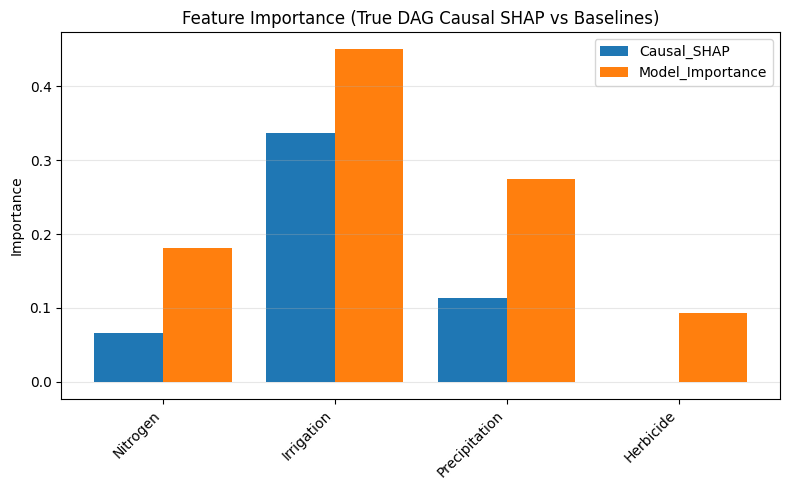

In [2]:
"""
CAUSAL SHAP on synthetic yield_preprocessed.npz
- Uses TRUE DAG for synthetic data:
    Nitrogen, Irrigation, Precipitation, Herbicide  →  Yield_Class
- Assumes features are exogenous and mutually independent (as in generator)
- Model is trained on SCALED features (StandardScaler),
  but causal sampling is done in ORIGINAL feature space.
- Value function: v_c(S) = E[ f(X) | do(X_S = x_S) ],
  where non-intervened features are sampled from their fitted ORIGINAL marginals,
  and then mapped to scaled space for prediction.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Set
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except Exception:
    HAVE_XGB = False


# Configuration
CONFIG = {
    "DATA_PATH": "CGT_Explainability/datasets/yield_synthetic/yield_preprocessed.npz",
    "MAX_PERM": 200,        # permutations per instance for SHAP
    "M_RESAMPLES": 64,      # Monte Carlo samples per value function call
    "GLOBAL_K": 30,         # test instances for global explanation
    "RANDOM_SEED": 42,
}

np.random.seed(CONFIG["RANDOM_SEED"])
rng = np.random.default_rng(CONFIG["RANDOM_SEED"])


# 1. Causal Sampler under True DAG (Original Space)

class IndependentCausalSampler:
    """
    Causal sampler consistent with the TRUE DAG:
      Nitrogen, Irrigation, Precipitation, Herbicide → Y
    and NO edges among features.

    Each feature is exogenous and independent in the data generator.
    Under do(X_S = x_S), features in S are fixed to x_S (ORIGINAL values),
    and remaining features are sampled from their ORIGINAL marginals.
    """

    def __init__(self, feature_names: List[str]):
        self.feature_names = feature_names
        self.stats: Dict[str, Dict[str, float]] = {}

    def fit(self, X_raw: pd.DataFrame):
        """Fit marginal distributions (mean, std) per feature in ORIGINAL space."""
        for feat in self.feature_names:
            mu = float(X_raw[feat].mean())
            sigma = float(X_raw[feat].std())
            if sigma < 1e-8:
                sigma = 1e-8
            self.stats[feat] = {"mean": mu, "std": sigma}
        return self

    def sample_intervention_raw(self, S: Set[str], x_obs_raw: pd.Series, rng) -> Dict[str, float]:
        """
        Sample a new feature vector in ORIGINAL space under do(X_S = x_S).

        - For j in S: X_j = x_obs_raw[j]  (original value from the instance)
        - For j not in S: X_j ~ N(mean_j, std_j) from ORIGINAL marginals
        """
        x_new = {}
        for feat in self.feature_names:
            if feat in S:
                x_new[feat] = float(x_obs_raw[feat])
            else:
                mu = self.stats[feat]["mean"]
                sigma = self.stats[feat]["std"]
                x_new[feat] = float(rng.normal(mu, sigma))
        return x_new


# 2. Causal SHAP with True DAG + Scale-Aware Mapping

class CausalSHAPTrueDAG:
    """
    Causal SHAP under TRUE DAG:
        All features → Y, no feature→feature edges.

    - Sampling happens in ORIGINAL space (using IndependentCausalSampler).
    - Each sampled x_raw is then mapped to SCALED space via `scaler`
      before being given to the classifier.

    Value function:
        v_c(S) = E[ f(X)_pred_class | do(X_S = x_S) ].
    """

    def __init__(
        self,
        model,
        sampler: IndependentCausalSampler,
        scaler: StandardScaler,
        feature_names: List[str],
    ):
        self.model = model
        self.sampler = sampler
        self.scaler = scaler
        self.feature_names = feature_names

    def _causal_value_function(
        self,
        S: Set[str],
        x_raw: pd.Series,
        pred_class: int,
        M: int
    ) -> float:
        """
        v_c(S) = E[ f(X)_pred_class | do(X_S = x_S) ],
        approximated via Monte Carlo:

        1. Sample x_raw' ~ P(X | do(X_S = x_S)) in ORIGINAL space.
        2. Transform to scaled space via `scaler`.
        3. Evaluate model.predict_proba on scaled x.
        """
        total = 0.0
        for _ in range(M):
            # 1) Sample in ORIGINAL space
            x_sample_raw = self.sampler.sample_intervention_raw(S, x_raw, rng)

            # 2) Convert to scaled space
            x_df_raw = pd.DataFrame([x_sample_raw], columns=self.feature_names)
            x_scaled = self.scaler.transform(x_df_raw.values)

            # 3) Predict probability for pred_class
            prob = self.model.predict_proba(x_scaled)[0][pred_class]
            total += prob
        return total / M

    def explain_instance(
        self,
        x_raw: pd.Series,
        n_perms: int = None,
        m_samples: int = None
    ) -> pd.Series:
        """
        Compute Causal SHAP values for a single instance x_raw (ORIGINAL scale).

        - Permutation-based Shapley approximation.
        - Uses causal value function under true DAG.
        - Enforces local accuracy: sum(phi) = f_x - v_c(empty).
        """
        if n_perms is None:
            n_perms = CONFIG["MAX_PERM"]
        if m_samples is None:
            m_samples = CONFIG["M_RESAMPLES"]

        # Get predicted class using the MODEL INPUT SPACE (scaled)
        x_df_raw = pd.DataFrame([x_raw.values], columns=self.feature_names)
        x_scaled = self.scaler.transform(x_df_raw.values)
        probs = self.model.predict_proba(x_scaled)[0]
        pred_class = int(np.argmax(probs))
        f_x = probs[pred_class]

        # Value for empty set (no interventions)
        v_empty = self._causal_value_function(set(), x_raw, pred_class, m_samples)

        # Shapley-style permutation estimation
        phi = np.zeros(len(self.feature_names))

        for _ in range(n_perms):
            perm = rng.permutation(self.feature_names)
            S: Set[str] = set()
            v_prev = v_empty

            for feat in perm:
                S_next = S | {feat}
                v_curr = self._causal_value_function(S_next, x_raw, pred_class, m_samples)
                delta = v_curr - v_prev

                idx = self.feature_names.index(feat)
                phi[idx] += delta

                S = S_next
                v_prev = v_curr

        phi /= n_perms  # average over permutations

        # Local accuracy correction
        sum_phi = np.sum(phi)
        if abs(sum_phi) > 1e-12:
            phi = phi * ((f_x - v_empty) / sum_phi)

        return pd.Series(phi, index=self.feature_names, name="Causal_SHAP")

    def explain_global(self, X_test_raw: pd.DataFrame, n_samples: int = None) -> pd.Series:
        """
        Global explanation: average Causal SHAP over sampled test points.
        X_test_raw is in ORIGINAL space.
        """
        if n_samples is None:
            n_samples = CONFIG["GLOBAL_K"]

        n_samples = min(n_samples, len(X_test_raw))
        indices = rng.choice(len(X_test_raw), size=n_samples, replace=False)

        print(f"\nComputing global Causal SHAP over {n_samples} instances...")
        explanations = []
        for i, idx in enumerate(indices):
            if (i + 1) % 5 == 0:
                print(f"  Progress: {i + 1}/{n_samples}")
            exp = self.explain_instance(
                X_test_raw.iloc[idx],
                n_perms=max(10, CONFIG["MAX_PERM"] // 4),
                m_samples=CONFIG["M_RESAMPLES"],
            )
            explanations.append(exp)

        print("Global Causal SHAP computed")
        return pd.concat(explanations, axis=1).mean(axis=1).rename("Causal_SHAP_Global")


# 3. Baseline: Model Feature Importance & Optional Kernel SHAP

def compute_baseline_shap(model, X_train_scaled, X_test_scaled, feature_names):
    """
    Optional: Kernel SHAP baseline (if `shap` is installed).
    Uses SCALED data since that is the model input space.
    """
    try:
        import shap
        print("\nComputing Kernel SHAP baseline...")
        bg_size = min(100, len(X_train_scaled))
        bg = shap.kmeans(X_train_scaled.values, bg_size)
        explainer = shap.KernelExplainer(lambda x: model.predict_proba(x), bg)
        shap_values = explainer.shap_values(X_test_scaled.values, nsamples=100)

        # Average absolute values across classes
        if isinstance(shap_values, list):
            global_imp = np.mean(
                [np.abs(sv).mean(axis=0) for sv in shap_values],
                axis=0,
            )
        else:
            global_imp = np.abs(shap_values).mean(axis=0)
        print("Kernel SHAP computed")
        return pd.Series(global_imp, index=feature_names, name="SHAP_kernel")
    except Exception as e:
        print(f"Warning: SHAP computation skipped/failed: {e}")
        return None


def compute_feature_importance(model, feature_names):
    """Model-native feature importance (e.g., RandomForest / XGBoost)."""
    if hasattr(model, "feature_importances_"):
        imp = model.feature_importances_
        return pd.Series(imp, index=feature_names, name="Model_Importance")
    return None


# 4. Simple Visualization Utility (optional)

def plot_bar_importance(df_imp: pd.DataFrame, title: str):
    plt.figure(figsize=(8, 5))
    for i, col in enumerate(df_imp.columns):
        plt.bar(
            np.arange(df_imp.shape[0]) + (i - 0.5) * (0.8 / len(df_imp.columns)),
            df_imp[col],
            width=0.8 / len(df_imp.columns),
            label=col,
        )
    plt.xticks(np.arange(df_imp.shape[0]), df_imp.index, rotation=45, ha="right")
    plt.ylabel("Importance")
    plt.title(title)
    plt.legend()
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    return plt.gcf()


# 5. Main: Train model + run Causal SHAP with true DAG

def main():
    print("\n" + "=" * 70)
    print("CAUSAL SHAP with TRUE DAG (Scale-Aware) on Synthetic Yield NPZ")
    print("=" * 70 + "\n")

    print("Loading NPZ dataset...")
    data = np.load(CONFIG["DATA_PATH"], allow_pickle=True)
    keys = list(data.keys())
    print(f"NPZ loaded with keys: {keys}")

    feature_names = list(data["feature_names"])
    X_train_raw = pd.DataFrame(data["X_train"], columns=feature_names)
    X_test_raw = pd.DataFrame(data["X_test"], columns=feature_names)
    y_train = pd.Series(data["y_train"].astype(int))
    y_test = pd.Series(data["y_test"].astype(int))

    print(f"Shapes: X_train={X_train_raw.shape}, X_test={X_test_raw.shape}")
    print(f"Features: {', '.join(feature_names)}")
    n_classes = len(np.unique(y_train))
    print(f"Target classes: {n_classes}")

    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(
        scaler.fit_transform(X_train_raw), columns=feature_names
    )
    X_test_scaled = pd.DataFrame(
        scaler.transform(X_test_raw), columns=feature_names
    )

    print("\n" + "=" * 70)
    print("Training Model")
    print("=" * 70)

    if HAVE_XGB:
        model = XGBClassifier(
            n_estimators=160,
            max_depth=5,
            learning_rate=0.08,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=CONFIG["RANDOM_SEED"],
            verbosity=0,
            objective="multi:softprob",
            num_class=n_classes,
        )
        print("Using XGBoost classifier")
    else:
        model = RandomForestClassifier(
            n_estimators=160,
            max_depth=6,
            random_state=CONFIG["RANDOM_SEED"],
        )
        print("Using RandomForest classifier")

    model.fit(X_train_scaled.values, y_train.values)
    y_pred = model.predict(X_test_scaled.values)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="macro")
    print(f"Model trained")
    print(f"  Test Accuracy: {acc:.4f}")
    print(f"  Test Macro F1: {f1:.4f}")

    sampler = IndependentCausalSampler(feature_names=feature_names).fit(X_train_raw)

    print("\n" + "=" * 70)
    print("Step 1: Computing Causal SHAP (True DAG, Scale-Aware)")
    print("=" * 70)

    causal_shap = CausalSHAPTrueDAG(
        model=model,
        sampler=sampler,
        scaler=scaler,
        feature_names=feature_names,
    )
    global_causal_shap = causal_shap.explain_global(
        X_test_raw, n_samples=CONFIG["GLOBAL_K"]
    )

    print("\n" + "=" * 70)
    print("Step 2: Baseline Methods")
    print("=" * 70)

    baseline_shap = compute_baseline_shap(
        model, X_train_scaled, X_test_scaled, feature_names
    )
    model_imp = compute_feature_importance(model, feature_names)

    print("\n" + "=" * 70)
    print("Step 3: Attribution Comparison")
    print("=" * 70)

    attributions = {"Causal_SHAP": global_causal_shap}
    if baseline_shap is not None:
        attributions["Kernel_SHAP"] = baseline_shap
    if model_imp is not None:
        attributions["Model_Importance"] = model_imp

    df_comparison = pd.DataFrame(attributions)
    print("\nAttribution Scores:\n" + "=" * 70)
    print(df_comparison.round(6).to_string())

    # Save CSV
    df_comparison.to_csv("attribution_scores_yield_true_dag_scale_aware.csv", index=True)
    print("\nSaved CSV -> attribution_scores_yield_true_dag_scale_aware.csv")

    # Optional: simple bar plot
    fig = plot_bar_importance(
        df_comparison,
        title="Feature Importance (True DAG Causal SHAP vs Baselines)",
    )
    fig.savefig(
        "attribution_comparison_yield_true_dag_scale_aware.png",
        dpi=150,
        bbox_inches="tight",
    )
    print("Plot saved -> attribution_comparison_yield_true_dag_scale_aware.png")

    try:
        plt.show()
    except Exception:
        pass


if __name__ == "__main__":
    main()


CAUSAL SHAP with TRUE DAG (Scale-Aware) on Synthetic Yield NPZ

Loading NPZ dataset...
✓ NPZ loaded with keys: ['X_train', 'X_test', 'y_train', 'y_test', 'feature_names']
Shapes: X_train=(800, 4), X_test=(200, 4)
Features: Nitrogen, Irrigation, Precipitation, Herbicide
Target classes: 3

Training Model
Using XGBoost classifier
✓ Model trained
  Test Accuracy: 0.8000
  Test Macro F1: 0.8033

Step 1: Computing Causal SHAP (True DAG, Scale-Aware)

Computing global Causal SHAP over 50 instances...
  Progress: 5/50
  Progress: 10/50
  Progress: 15/50
  Progress: 20/50
  Progress: 25/50
  Progress: 30/50
  Progress: 35/50
  Progress: 40/50
  Progress: 45/50
  Progress: 50/50
✓ Global Causal SHAP computed

Step 2: Baseline Methods

Computing Kernel SHAP baseline...


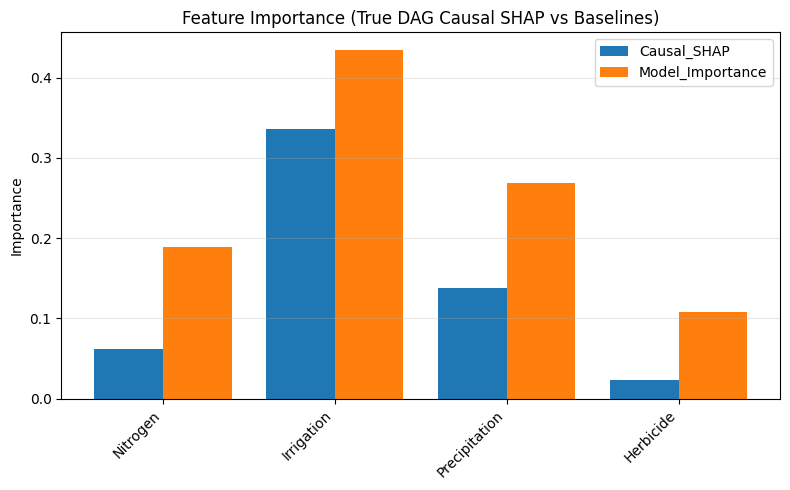

In [1]:
"""
CAUSAL SHAP on synthetic yield_preprocessed.npz
- Uses TRUE DAG for synthetic data:
    Nitrogen, Irrigation, Precipitation, Herbicide  →  Yield_Class
- Assumes features are exogenous and mutually independent (as in generator)
- Model is trained on SCALED features (StandardScaler),
  but causal sampling is done in ORIGINAL feature space.
- Value function: v_c(S) = E[ f(X) | do(X_S = x_S) ],
  where non-intervened features are sampled from their fitted ORIGINAL marginals,
  and then mapped to scaled space for prediction.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Set
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except Exception:
    HAVE_XGB = False


# Configuration
CONFIG = {
    "DATA_PATH": "CGT_Explainability/datasets/yield_synthetic/yield_preprocessed.npz",
    "MAX_PERM": 500,        # permutations per instance for SHAP
    "M_RESAMPLES": 256,      # Monte Carlo samples per value function call
    "GLOBAL_K": 50,         # test instances for global explanation
    "RANDOM_SEED": 42,
}

np.random.seed(CONFIG["RANDOM_SEED"])
rng = np.random.default_rng(CONFIG["RANDOM_SEED"])


# 1. Causal Sampler under True DAG (Original Space)

class IndependentCausalSampler:
    """
    Causal sampler consistent with the TRUE DAG:
      Nitrogen, Irrigation, Precipitation, Herbicide → Y
    and NO edges among features.

    Each feature is exogenous and independent in the data generator.
    Under do(X_S = x_S), features in S are fixed to x_S (ORIGINAL values),
    and remaining features are sampled from their ORIGINAL marginals.
    """

    def __init__(self, feature_names: List[str]):
        self.feature_names = feature_names
        self.stats: Dict[str, Dict[str, float]] = {}

    def fit(self, X_raw: pd.DataFrame):
        """Fit marginal distributions (mean, std) per feature in ORIGINAL space."""
        for feat in self.feature_names:
            mu = float(X_raw[feat].mean())
            sigma = float(X_raw[feat].std())
            if sigma < 1e-8:
                sigma = 1e-8
            self.stats[feat] = {"mean": mu, "std": sigma}
        return self

    def sample_intervention_raw(self, S: Set[str], x_obs_raw: pd.Series, rng) -> Dict[str, float]:
        """
        Sample a new feature vector in ORIGINAL space under do(X_S = x_S).

        - For j in S: X_j = x_obs_raw[j]  (original value from the instance)
        - For j not in S: X_j ~ N(mean_j, std_j) from ORIGINAL marginals
        """
        x_new = {}
        for feat in self.feature_names:
            if feat in S:
                x_new[feat] = float(x_obs_raw[feat])
            else:
                mu = self.stats[feat]["mean"]
                sigma = self.stats[feat]["std"]
                x_new[feat] = float(rng.normal(mu, sigma))
        return x_new


# 2. Causal SHAP with True DAG + Scale-Aware Mapping

class CausalSHAPTrueDAG:
    """
    Causal SHAP under TRUE DAG:
        All features → Y, no feature→feature edges.

    - Sampling happens in ORIGINAL space (using IndependentCausalSampler).
    - Each sampled x_raw is then mapped to SCALED space via `scaler`
      before being given to the classifier.

    Value function:
        v_c(S) = E[ f(X)_pred_class | do(X_S = x_S) ].
    """

    def __init__(
        self,
        model,
        sampler: IndependentCausalSampler,
        scaler: StandardScaler,
        feature_names: List[str],
    ):
        self.model = model
        self.sampler = sampler
        self.scaler = scaler
        self.feature_names = feature_names

    def _causal_value_function(
        self,
        S: Set[str],
        x_raw: pd.Series,
        pred_class: int,
        M: int
    ) -> float:
        """
        v_c(S) = E[ f(X)_pred_class | do(X_S = x_S) ],
        approximated via Monte Carlo:

        1. Sample x_raw' ~ P(X | do(X_S = x_S)) in ORIGINAL space.
        2. Transform to scaled space via `scaler`.
        3. Evaluate model.predict_proba on scaled x.
        """
        total = 0.0
        for _ in range(M):
            # 1) Sample in ORIGINAL space
            x_sample_raw = self.sampler.sample_intervention_raw(S, x_raw, rng)

            # 2) Convert to scaled space
            x_df_raw = pd.DataFrame([x_sample_raw], columns=self.feature_names)
            x_scaled = self.scaler.transform(x_df_raw.values)

            # 3) Predict probability for pred_class
            prob = self.model.predict_proba(x_scaled)[0][pred_class]
            total += prob
        return total / M

    def explain_instance(
        self,
        x_raw: pd.Series,
        n_perms: int = None,
        m_samples: int = None
    ) -> pd.Series:
        """
        Compute Causal SHAP values for a single instance x_raw (ORIGINAL scale).

        - Permutation-based Shapley approximation.
        - Uses causal value function under true DAG.
        - Enforces local accuracy: sum(phi) = f_x - v_c(empty).
        """
        if n_perms is None:
            n_perms = CONFIG["MAX_PERM"]
        if m_samples is None:
            m_samples = CONFIG["M_RESAMPLES"]

        # Get predicted class using the MODEL INPUT SPACE (scaled)
        x_df_raw = pd.DataFrame([x_raw.values], columns=self.feature_names)
        x_scaled = self.scaler.transform(x_df_raw.values)
        probs = self.model.predict_proba(x_scaled)[0]
        pred_class = int(np.argmax(probs))
        f_x = probs[pred_class]

        # Value for empty set (no interventions)
        v_empty = self._causal_value_function(set(), x_raw, pred_class, m_samples)

        # Shapley-style permutation estimation
        phi = np.zeros(len(self.feature_names))

        for _ in range(n_perms):
            perm = rng.permutation(self.feature_names)
            S: Set[str] = set()
            v_prev = v_empty

            for feat in perm:
                S_next = S | {feat}
                v_curr = self._causal_value_function(S_next, x_raw, pred_class, m_samples)
                delta = v_curr - v_prev

                idx = self.feature_names.index(feat)
                phi[idx] += delta

                S = S_next
                v_prev = v_curr

        phi /= n_perms  # average over permutations

        # Local accuracy correction
        sum_phi = np.sum(phi)
        if abs(sum_phi) > 1e-12:
            phi = phi * ((f_x - v_empty) / sum_phi)

        return pd.Series(phi, index=self.feature_names, name="Causal_SHAP")

    def explain_global(self, X_test_raw: pd.DataFrame, n_samples: int = None) -> pd.Series:
        """
        Global explanation: average Causal SHAP over sampled test points.
        X_test_raw is in ORIGINAL space.
        """
        if n_samples is None:
            n_samples = CONFIG["GLOBAL_K"]

        n_samples = min(n_samples, len(X_test_raw))
        indices = rng.choice(len(X_test_raw), size=n_samples, replace=False)

        print(f"\nComputing global Causal SHAP over {n_samples} instances...")
        explanations = []
        for i, idx in enumerate(indices):
            if (i + 1) % 5 == 0:
                print(f"  Progress: {i + 1}/{n_samples}")
            exp = self.explain_instance(
                X_test_raw.iloc[idx],
                n_perms=max(10, CONFIG["MAX_PERM"] // 4),
                m_samples=CONFIG["M_RESAMPLES"],
            )
            explanations.append(exp)

        print("Global Causal SHAP computed")
        return pd.concat(explanations, axis=1).mean(axis=1).rename("Causal_SHAP_Global")


# 3. Baseline: Model Feature Importance & Optional Kernel SHAP

def compute_baseline_shap(model, X_train_scaled, X_test_scaled, feature_names):
    """
    Optional: Kernel SHAP baseline (if `shap` is installed).
    Uses SCALED data since that is the model input space.
    """
    try:
        import shap
        print("\nComputing Kernel SHAP baseline...")
        bg_size = min(100, len(X_train_scaled))
        bg = shap.kmeans(X_train_scaled.values, bg_size)
        explainer = shap.KernelExplainer(lambda x: model.predict_proba(x), bg)
        shap_values = explainer.shap_values(X_test_scaled.values, nsamples=100)

        # Average absolute values across classes
        if isinstance(shap_values, list):
            global_imp = np.mean(
                [np.abs(sv).mean(axis=0) for sv in shap_values],
                axis=0,
            )
        else:
            global_imp = np.abs(shap_values).mean(axis=0)
        print("Kernel SHAP computed")
        return pd.Series(global_imp, index=feature_names, name="SHAP_kernel")
    except Exception as e:
        print(f"Warning: SHAP computation skipped/failed: {e}")
        return None


def compute_feature_importance(model, feature_names):
    """Model-native feature importance (e.g., RandomForest / XGBoost)."""
    if hasattr(model, "feature_importances_"):
        imp = model.feature_importances_
        return pd.Series(imp, index=feature_names, name="Model_Importance")
    return None


# 4. Simple Visualization Utility (optional)

def plot_bar_importance(df_imp: pd.DataFrame, title: str):
    plt.figure(figsize=(8, 5))
    for i, col in enumerate(df_imp.columns):
        plt.bar(
            np.arange(df_imp.shape[0]) + (i - 0.5) * (0.8 / len(df_imp.columns)),
            df_imp[col],
            width=0.8 / len(df_imp.columns),
            label=col,
        )
    plt.xticks(np.arange(df_imp.shape[0]), df_imp.index, rotation=45, ha="right")
    plt.ylabel("Importance")
    plt.title(title)
    plt.legend()
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    return plt.gcf()


# 5. Main: Train model + run Causal SHAP with true DAG

def main():
    print("\n" + "=" * 70)
    print("CAUSAL SHAP with TRUE DAG (Scale-Aware) on Synthetic Yield NPZ")
    print("=" * 70 + "\n")

    print("Loading NPZ dataset...")
    data = np.load(CONFIG["DATA_PATH"], allow_pickle=True)
    keys = list(data.keys())
    print(f"NPZ loaded with keys: {keys}")

    feature_names = list(data["feature_names"])
    X_train_raw = pd.DataFrame(data["X_train"], columns=feature_names)
    X_test_raw = pd.DataFrame(data["X_test"], columns=feature_names)
    y_train = pd.Series(data["y_train"].astype(int))
    y_test = pd.Series(data["y_test"].astype(int))

    print(f"Shapes: X_train={X_train_raw.shape}, X_test={X_test_raw.shape}")
    print(f"Features: {', '.join(feature_names)}")
    n_classes = len(np.unique(y_train))
    print(f"Target classes: {n_classes}")

    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(
        scaler.fit_transform(X_train_raw), columns=feature_names
    )
    X_test_scaled = pd.DataFrame(
        scaler.transform(X_test_raw), columns=feature_names
    )

    print("\n" + "=" * 70)
    print("Training Model")
    print("=" * 70)

    if HAVE_XGB:
        model = XGBClassifier(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=CONFIG["RANDOM_SEED"],
            verbosity=0,
            objective="multi:softprob",
            num_class=n_classes,
        )
        print("Using XGBoost classifier")
    else:
        model = RandomForestClassifier(
            n_estimators=160,
            max_depth=6,
            random_state=CONFIG["RANDOM_SEED"],
        )
        print("Using RandomForest classifier")

    model.fit(X_train_scaled.values, y_train.values)
    y_pred = model.predict(X_test_scaled.values)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="macro")
    print(f"Model trained")
    print(f"  Test Accuracy: {acc:.4f}")
    print(f"  Test Macro F1: {f1:.4f}")

    sampler = IndependentCausalSampler(feature_names=feature_names).fit(X_train_raw)

    print("\n" + "=" * 70)
    print("Step 1: Computing Causal SHAP (True DAG, Scale-Aware)")
    print("=" * 70)

    causal_shap = CausalSHAPTrueDAG(
        model=model,
        sampler=sampler,
        scaler=scaler,
        feature_names=feature_names,
    )
    global_causal_shap = causal_shap.explain_global(
        X_test_raw, n_samples=CONFIG["GLOBAL_K"]
    )

    print("\n" + "=" * 70)
    print("Step 2: Baseline Methods")
    print("=" * 70)

    baseline_shap = compute_baseline_shap(
        model, X_train_scaled, X_test_scaled, feature_names
    )
    model_imp = compute_feature_importance(model, feature_names)

    print("\n" + "=" * 70)
    print("Step 3: Attribution Comparison")
    print("=" * 70)

    attributions = {"Causal_SHAP": global_causal_shap}
    if baseline_shap is not None:
        attributions["Kernel_SHAP"] = baseline_shap
    if model_imp is not None:
        attributions["Model_Importance"] = model_imp

    df_comparison = pd.DataFrame(attributions)
    print("\nAttribution Scores:\n" + "=" * 70)
    print(df_comparison.round(6).to_string())

    # Save CSV
    df_comparison.to_csv("attribution_scores_yield_true_dag_scale_aware.csv", index=True)
    print("\nSaved CSV -> attribution_scores_yield_true_dag_scale_aware.csv")

    # Optional: simple bar plot
    fig = plot_bar_importance(
        df_comparison,
        title="Feature Importance (True DAG Causal SHAP vs Baselines)",
    )
    fig.savefig(
        "attribution_comparison_yield_true_dag_scale_aware.png",
        dpi=150,
        bbox_inches="tight",
    )
    print("Plot saved -> attribution_comparison_yield_true_dag_scale_aware.png")

    try:
        plt.show()
    except Exception:
        pass


if __name__ == "__main__":
    main()

In [1]:
from scipy.interpolate import CubicSpline
from scipy.optimize import differential_evolution
from scipy.integrate import odeint
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


#   IMPROVED MODEL: BETA(t) AS A CUBIC SPLINE
class SplineSIR:
    def __init__(self, population):
        self.population = population
        self.params = None
        self.fitted = False

    # Cubic spline β(t)
    def make_beta(self, knots, beta_values):
        return CubicSpline(knots, beta_values, bc_type="natural")

    # Standard constant γ
    def sir_equations(self, y, t, beta_func, gamma):
        S, I, R = y
        beta = float(beta_func(t))
        dSdt = -beta * S * I
        dIdt = beta * S * I - gamma * I
        dRdt = gamma * I
        return [dSdt, dIdt, dRdt]

    def solve(self, t, beta_func, gamma, initial):
        return odeint(self.sir_equations, initial, t,
                      args=(beta_func, gamma))

    # Loss function
    def loss(self, params, t, I_data, R_data, initial):
        beta_vals = params[:-1]
        gamma = params[-1]

        if gamma < 0:
            return np.inf

        # Create spline β(t)
        knots = np.linspace(0, len(t)-1, len(beta_vals))
        beta_func = self.make_beta(knots, beta_vals)

        sol = self.solve(t, beta_func, gamma, initial)
        I_pred, R_pred = sol[:, 1], sol[:, 2]

        return np.sum((I_pred - I_data)**2) + np.sum((R_pred - R_data)**2)

    def fit(self, data):
        t = np.arange(len(data))
        I = data["I"].values
        R = data["R"].values

        initial = [data["S"].iloc[0], data["I"].iloc[0], data["R"].iloc[0]]

        # β spline has 5 control points + γ
        bounds = [(0.00001, 2.0)] * 5 + [(0.0001, 1.0)]

        result = differential_evolution(
            self.loss, bounds,
            args=(t, I, R, initial),
            maxiter=600, seed=42, tol=1e-7
        )

        self.params = result.x
        self.knots = np.linspace(0, len(t)-1, 5)
        self.beta_func = self.make_beta(self.knots, self.params[:-1])
        self.gamma = self.params[-1]
        self.initial = initial
        self.fitted = True

        print("\nFitted parameters:")
        print("β spline values:", self.params[:-1])
        print("γ:", self.gamma)

    def predict(self, days):
        t = np.arange(days)
        sol = self.solve(t, self.beta_func, self.gamma, self.initial)
        return pd.DataFrame({
            "Day": t,
            "S": sol[:, 0], "I": sol[:, 1], "R": sol[:, 2]
        })


Fitted parameters:
β spline values: [0.07427499 0.24024586 0.12029432 0.09214184 0.07597395]
γ: 0.03344042934227115

Infected (I)
RMSE: 1.3154234646899824e-06
MAE : 1.1726311306887234e-06
R²  : 0.9333603297178275

Removed (R)
RMSE: 5.271254386460956e-06
MAE : 4.7908666806742835e-06
R²  : 0.3347298401950686


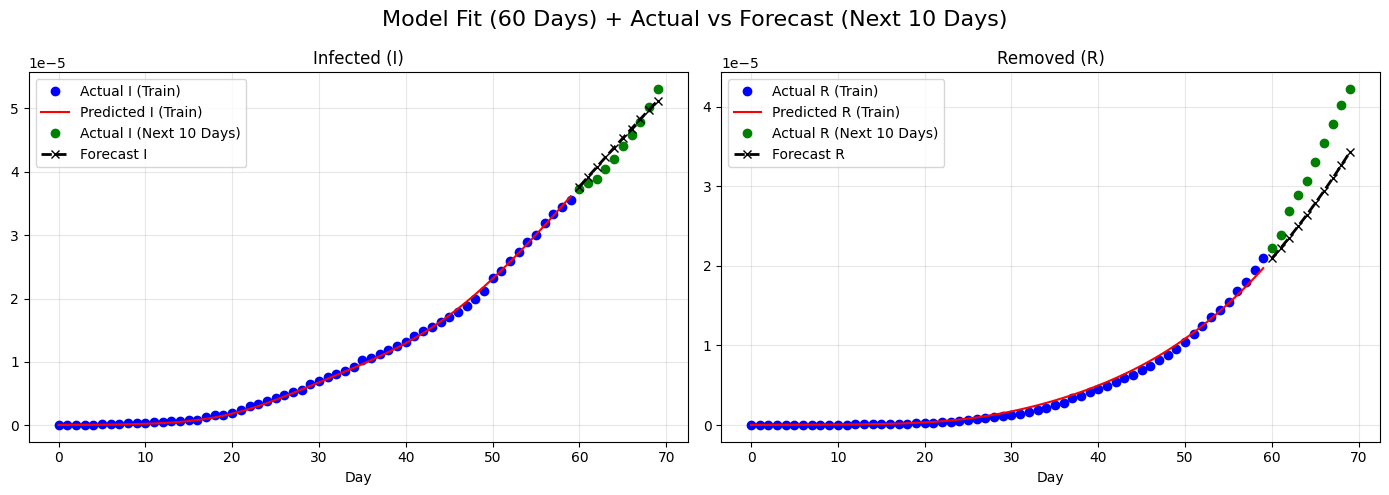

In [3]:
# Load data
df = pd.read_csv("../../datasets/covid19_merged_data.csv")

model = SplineSIR(population=1_380_000_000)

data = df[df["Country/Region"] == "India"].copy()
data = data.groupby("Date").sum().reset_index()
data["Date"] = pd.to_datetime(data["Date"])
data = data[(data["Date"] >= "2020-03-15") & (data["Date"] <= "2020-06-15")]

data["Active"] = data["Confirmed"] - data["Deaths"] - data["Recovered"]
data["Removed"] = data["Deaths"] + data["Recovered"]

data["S"] = (model.population - data["Confirmed"]) / model.population
data["I"] = data["Active"] / model.population
data["R"] = data["Removed"] / model.population

data = data.reset_index(drop=True)


# Train 60 days
train = data.iloc[:60].reset_index(drop=True)
test  = data.iloc[60:70].reset_index(drop=True)

model.fit(train)

pred_train = model.predict(60)
pred_full = model.predict(70)
forecast  = pred_full.iloc[60:].reset_index(drop=True)


# Accuracy
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

def evaluate(name, actual, pred):
    print(f"\n{name}")
    print("RMSE:", np.sqrt(mean_squared_error(actual, pred)))
    print("MAE :", mean_absolute_error(actual, pred))
    print("R²  :", r2_score(actual, pred))

evaluate("Infected (I)", test["I"], forecast["I"])
evaluate("Removed (R)",  test["R"], forecast["R"])


# Plot


plt.figure(figsize=(14, 5))
plt.suptitle("Model Fit (60 Days) + Actual vs Forecast (Next 10 Days)", fontsize=16)

plt.subplot(1, 2, 1)

# Train fit
plt.plot(range(0, 60), train["I"], "bo", label="Actual I (Train)")
plt.plot(range(0, 60), pred_train["I"], "r-", label="Predicted I (Train)")

# Actual next 10 days (60-70)
plt.plot(range(60, 70), test["I"], "go", label="Actual I (Next 10 Days)")

plt.plot(range(60, 70), forecast["I"], "kx--", linewidth=2, label="Forecast I")

plt.title("Infected (I)")
plt.xlabel("Day")
plt.grid(True, alpha=0.3)
plt.legend()


plt.subplot(1, 2, 2)

# Train fit
plt.plot(range(0, 60), train["R"], "bo", label="Actual R (Train)")
plt.plot(range(0, 60), pred_train["R"], "r-", label="Predicted R (Train)")

# Actual next 10 days (60-70)
plt.plot(range(60, 70), test["R"], "go", label="Actual R (Next 10 Days)")

plt.plot(range(60, 70), forecast["R"], "kx--", linewidth=2, label="Forecast R")

plt.title("Removed (R)")
plt.xlabel("Day")
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


Fitted parameters (SEIR-TV):
β0     = 0.190258
k_β    = 0.011738
γ0     = 0.031294
k_γ    = 0.000000
σ      = 0.200000
Loss   = 1.234071e-12

Infected (I)
RMSE: 3.865516684688853e-06
MAE : 3.688738979569541e-06
R²  : 0.42453783572248127

Removed (R)
RMSE: 5.954210414110106e-06
MAE : 5.52612688818286e-06
R²  : 0.1511744391881079


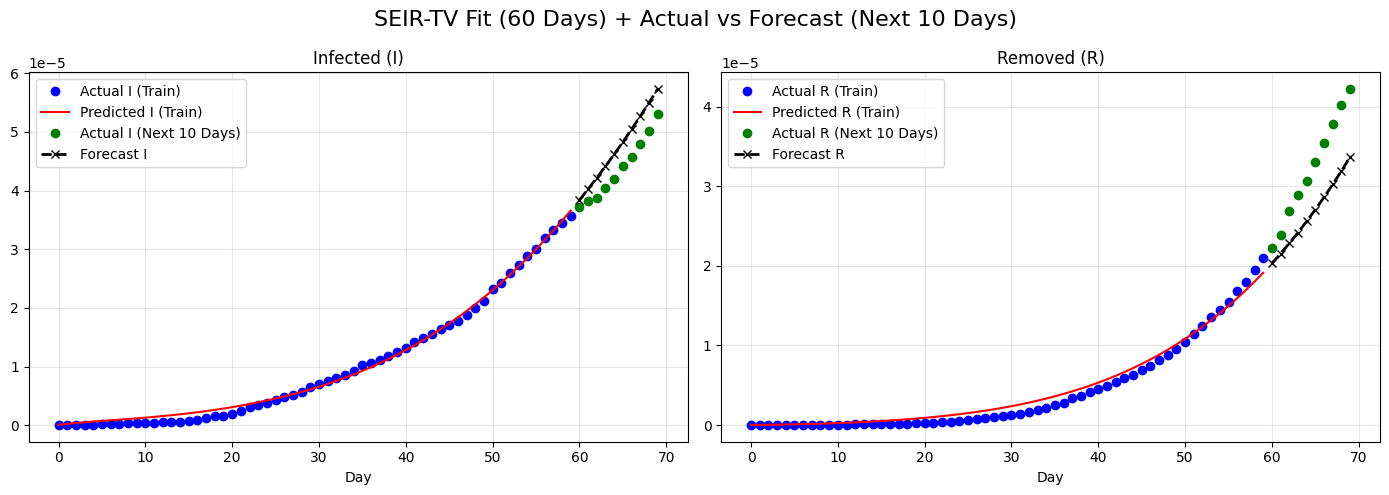

In [6]:
from scipy.optimize import differential_evolution
from scipy.integrate import odeint
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


#   SEIR-TV MODEL: β(t), γ(t) EXPONENTIAL; CONSTANT σ
#   Same parameters & loss as original seir_time.py:
class SEIRTimeVarying:
    def __init__(self, population):
        self.population = population
        self.params = None
        self.fitted = False

    def beta_t(self, t, beta0, k_beta):
        return beta0 * np.exp(-k_beta * t)

    def gamma_t(self, t, gamma0, k_gamma):
        return gamma0 * np.exp(-k_gamma * t)

    # SEIR ODEs
    def seir_equations(self, y, t, beta0, k_beta, gamma0, k_gamma, sigma):
        S, E, I, R = y
        beta = float(self.beta_t(t, beta0, k_beta))
        gamma = float(self.gamma_t(t, gamma0, k_gamma))

        dSdt = -beta * S * I
        dEdt = beta * S * I - sigma * E
        dIdt = sigma * E - gamma * I
        dRdt = gamma * I
        return [dSdt, dEdt, dIdt, dRdt]

    def solve(self, t, params, initial):
        beta0, k_beta, gamma0, k_gamma, sigma = params
        return odeint(
            self.seir_equations,
            initial,
            t,
            args=(beta0, k_beta, gamma0, k_gamma, sigma)
        )

    def loss(self, params, t, I_data, R_data, initial):
        beta0, k_beta, gamma0, k_gamma, sigma = params

        # Basic constraints
        if sigma <= 0 or beta0 < 0 or gamma0 < 0 or k_beta < 0 or k_gamma < 0:
            return np.inf

        sol = self.solve(t, params, initial)
        I_pred = sol[:, 2]  # S,e,i,r
        R_pred = sol[:, 3]

        mse_I = mean_squared_error(I_data, I_pred)
        mse_R = mean_squared_error(R_data, R_pred)

        # Prior on incubation time 1/σ ≈ 5 days
        tau = 1.0 / sigma
        prior = 0.01 * (tau - 5.0) ** 2

        return 1.5 * mse_I + 1.0 * mse_R + prior

    def fit(self, data):
        # data has columns S, I, R (fractions of population)
        t = np.arange(len(data))
        I = data["I"].values
        R = data["R"].values

        S0 = data["S"].iloc[0]
        I0 = data["I"].iloc[0]
        R0 = data["R"].iloc[0]
        # E0 either inferred from 1 - S - I - R or set small
        E0 = max(1.0 - S0 - I0 - R0, 1e-6)
        initial = [S0, E0, I0, R0]

        # Parameters: β0, kβ, γ0, kγ, σ
        # Bounds can be tuned, but structure & loss are same.
        bounds = [
            (0.0, 2.0),    # β0
            (0.0, 0.2),    # kβ
            (0.0, 2.0),    # γ0
            (0.0, 0.2),    # kγ
            (0.05, 1.0),   # σ
        ]

        result = differential_evolution(
            self.loss, bounds,
            args=(t, I, R, initial),
            maxiter=600, seed=42, tol=1e-7
        )

        self.params = result.x
        self.initial = initial
        self.fitted = True

        beta0, k_beta, gamma0, k_gamma, sigma = self.params
        print("\nFitted parameters (SEIR-TV):")
        print(f"β0     = {beta0:.6f}")
        print(f"k_β    = {k_beta:.6f}")
        print(f"γ0     = {gamma0:.6f}")
        print(f"k_γ    = {k_gamma:.6f}")
        print(f"σ      = {sigma:.6f}")
        print(f"Loss   = {result.fun:.6e}")

    def predict(self, days):
        if not self.fitted:
            raise RuntimeError("Model is not fitted yet.")
        t = np.arange(days)
        sol = self.solve(t, self.params, self.initial)
        return pd.DataFrame({
            "Day": t,
            "S": sol[:, 0],
            "E": sol[:, 1],
            "I": sol[:, 2],
            "R": sol[:, 3],
        })


#   DATA LOADING & PREPROCESSING (same as SplineSIR code)

df = pd.read_csv("../../datasets/covid19_merged_data.csv")

model = SEIRTimeVarying(population=1_380_000_000)

data = df[df["Country/Region"] == "India"].copy()
data = data.groupby("Date").sum().reset_index()
data["Date"] = pd.to_datetime(data["Date"])
data = data[(data["Date"] >= "2020-03-15") & (data["Date"] <= "2020-06-15")]

data["Active"] = data["Confirmed"] - data["Deaths"] - data["Recovered"]
data["Removed"] = data["Deaths"] + data["Recovered"]

data["S"] = (model.population - data["Confirmed"]) / model.population
data["I"] = data["Active"] / model.population
data["R"] = data["Removed"] / model.population

data = data.reset_index(drop=True)


# Train 60 days, test next 10 days (exactly like SplineSIR)
train = data.iloc[:60].reset_index(drop=True)
test  = data.iloc[60:70].reset_index(drop=True)

model.fit(train)

pred_train = model.predict(60)
pred_full  = model.predict(70)
forecast   = pred_full.iloc[60:].reset_index(drop=True)


# Accuracy on unseen 10 days
def evaluate(name, actual, pred):
    print(f"\n{name}")
    print("RMSE:", np.sqrt(mean_squared_error(actual, pred)))
    print("MAE :", mean_absolute_error(actual, pred))
    print("R²  :", r2_score(actual, pred))

evaluate("Infected (I)", test["I"], forecast["I"])
evaluate("Removed (R)",  test["R"], forecast["R"])


# Plot: Fit on Train + Actual vs Forecast on Next 10 Days

plt.figure(figsize=(14, 5))
plt.suptitle("SEIR-TV Fit (60 Days) + Actual vs Forecast (Next 10 Days)", fontsize=16)

plt.subplot(1, 2, 1)

# Train fit
plt.plot(range(0, 60), train["I"], "bo", label="Actual I (Train)")
plt.plot(range(0, 60), pred_train["I"], "r-", label="Predicted I (Train)")

# Actual next 10 days (60-70)
plt.plot(range(60, 70), test["I"], "go", label="Actual I (Next 10 Days)")

# Forecast next 10 days (60-70)
plt.plot(range(60, 70), forecast["I"], "kx--", linewidth=2, label="Forecast I")

plt.title("Infected (I)")
plt.xlabel("Day")
plt.grid(True, alpha=0.3)
plt.legend()


plt.subplot(1, 2, 2)

# Train fit
plt.plot(range(0, 60), train["R"], "bo", label="Actual R (Train)")
plt.plot(range(0, 60), pred_train["R"], "r-", label="Predicted R (Train)")

# Actual next 10 days (60-70)
plt.plot(range(60, 70), test["R"], "go", label="Actual R (Next 10 Days)")

# Forecast next 10 days (60-70)
plt.plot(range(60, 70), forecast["R"], "kx--", linewidth=2, label="Forecast R")

plt.title("Removed (R)")
plt.xlabel("Day")
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

\n======================================================================
CAUSAL SHAP on NPZ Dataset
======================================================================\n
Loading NPZ dataset...
✓ NPZ loaded with keys: ['X_train', 'X_test', 'y_train', 'y_test', 'feature_names']
Shapes: X_train=(4000, 7), X_test=(1000, 7), y_train=(4000,), y_test=(1000,)
Features: Organic Carbon, Nitrogen, Phosphorus, Potassium, pH, Zinc, Electrical Conductivity
Target classes: 3
\n======================================================================
Training Model
Using XGBoost classifier
✓ Model trained
  Test Accuracy: 0.9470
  Test Macro F1: 0.9472
\n======================================================================
Step 1: Causal Discovery (PC Algorithm)
Running PC algorithm on 7 features...
✓ Causal discovery complete
\nDiscovered graph: 7 nodes, 22 edges
✓ Causal graph saved to 'causal_graph_yield.png'
\n======================================================================
Step 2: Computin

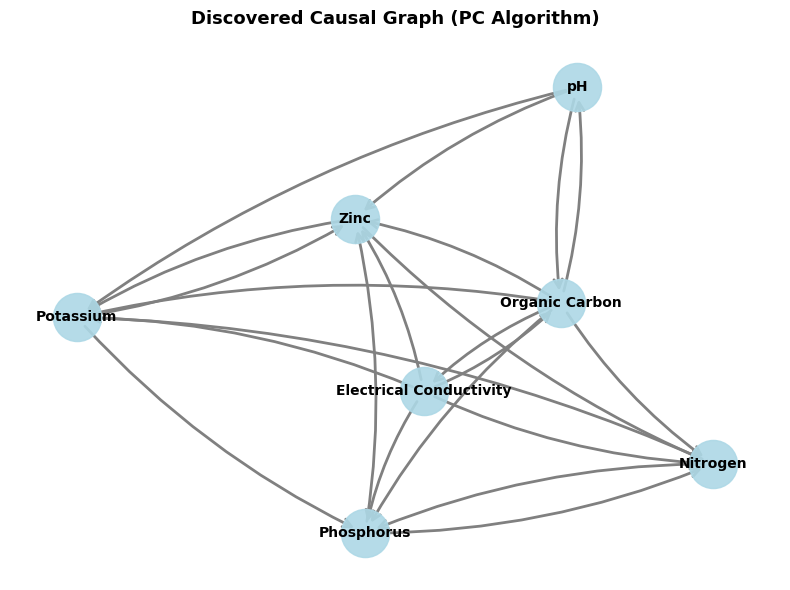

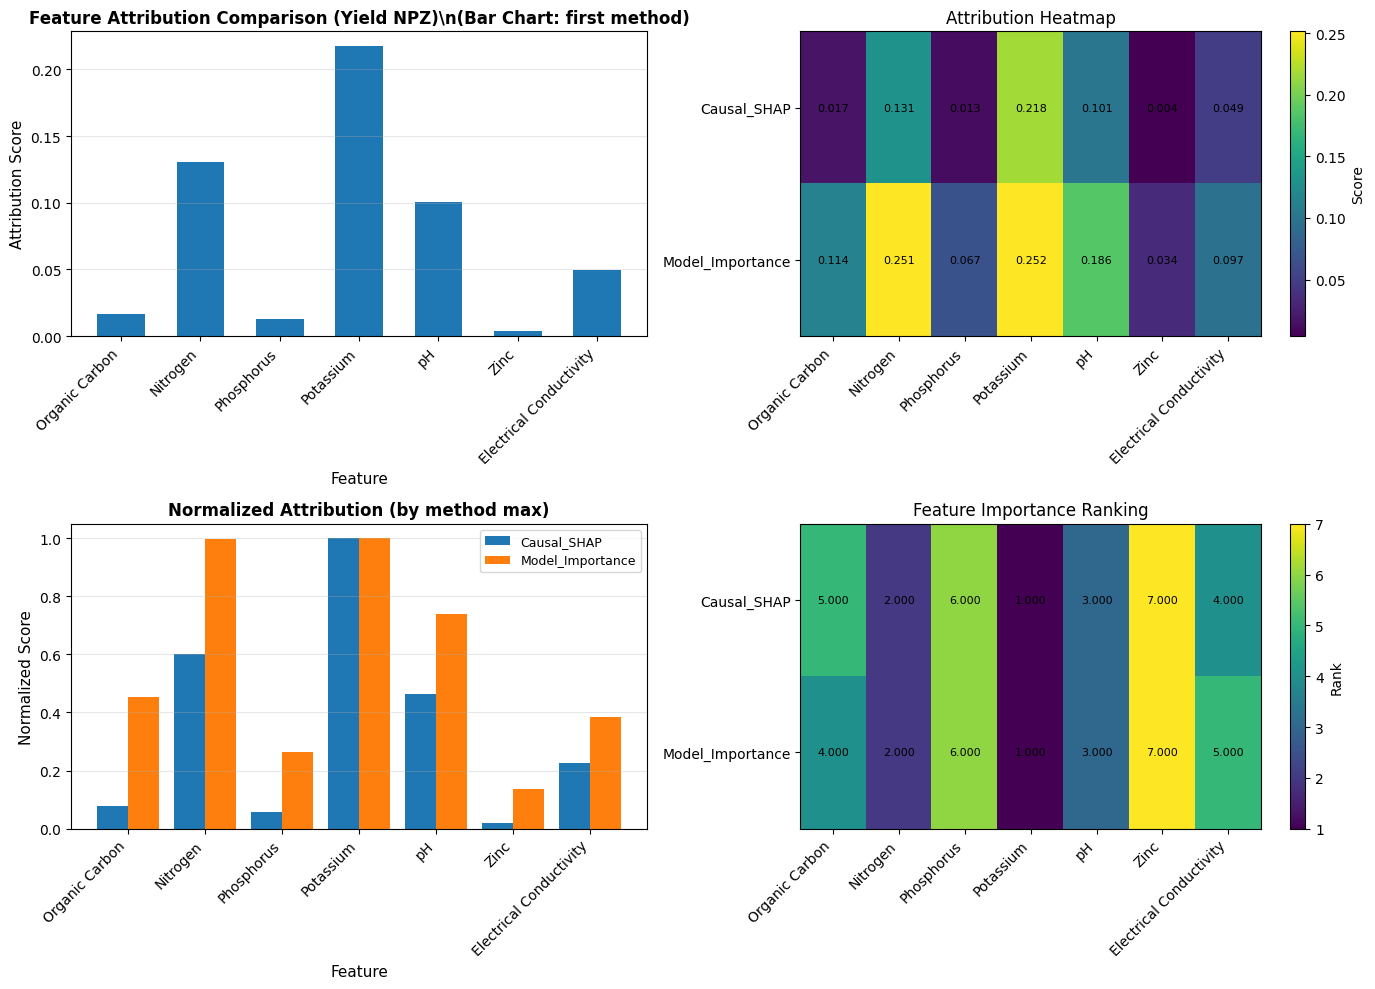

In [2]:
"""
CAUSAL SHAP on yield_preprocessed.npz
- Works with keys: X_train, X_test, y_train, y_test, feature_names
- Implements PC-based causal discovery, IDA-style causal effects, and Causal SHAP
- Saves outputs: causal graph PNG, comparison PNG, and CSV of attributions
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Tuple, Set
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
import networkx as nx

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except:
    HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

# Configuration
CONFIG = {
    'DATA_PATH': '../../datasets/soil_spi_preprocessed.npz',
    'ALPHA_PC': 0.9,
    'MAX_PERM': 200,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5  # Sample multiple DAGs from CPDAG
}

np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])


# 1. Causal Discovery & Structure Learning

class CausalStructure:
    """Handles causal discovery and DAG sampling from CPDAG"""

    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names = None
        self.dags = []

    def discover(self, X: pd.DataFrame):
        """Run PC algorithm on features"""
        self.feature_names = list(X.columns)
        print(f"Running PC algorithm on {len(self.feature_names)} features...")

        pc_res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = pc_res.G.graph

        print(f"Causal discovery complete")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        """Convert CPDAG to networkx DiGraph"""
        G = nx.DiGraph()
        G.add_nodes_from(self.feature_names)

        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                # Directed edge i->j
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                # Undirected edge: add both directions
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    if i < j:  # Avoid double-adding
                        G.add_edge(self.feature_names[i], self.feature_names[j])
                        G.add_edge(self.feature_names[j], self.feature_names[i])

        return G

    def sample_dags(self, n_samples=5) -> List[nx.DiGraph]:
        """
        Sample multiple DAG orientations from CPDAG
        For undirected edges, randomly orient them
        """
        base_G = self.get_skeleton()
        dags = []

        # Find undirected edges
        undirected = []
        for i, u in enumerate(self.feature_names):
            for j, v in enumerate(self.feature_names):
                if i < j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((u, v))

        if len(undirected) == 0:
            # CPDAG is already fully directed
            print(f"  CPDAG is fully directed ({base_G.number_of_edges()} edges)")
            return [base_G]

        print(f"  Found {len(undirected)} undirected edges, sampling orientations...")

        # Sample orientations
        for _ in range(n_samples):
            G = nx.DiGraph()
            G.add_nodes_from(self.feature_names)

            # Add directed edges from CPDAG
            for i, u in enumerate(self.feature_names):
                for j, v in enumerate(self.feature_names):
                    if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(u, v)

            # Randomly orient undirected edges (ensuring acyclicity)
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)

                # Check for cycles and reverse if needed
                if not nx.is_directed_acyclic_graph(G):
                    G.remove_edge(u, v) if G.has_edge(u, v) else G.remove_edge(v, u)
                    G.add_edge(v, u) if not G.has_edge(v, u) else G.add_edge(u, v)

            dags.append(G)

        self.dags = dags
        return dags


# 2. Causal Mechanism Learning

class LinearMechanisms:
    """Learn linear structural equation models"""

    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.feature_names = feature_names
        self.mechanisms = {}
        self.topo_order = None

    def fit(self, X: pd.DataFrame):
        """Fit linear mechanisms for each variable"""
        # Get topological order
        try:
            self.topo_order = list(nx.topological_sort(self.dag))
        except:
            # Fallback if cycles exist
            self.topo_order = self._safe_topo_order()

        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))

            if not parents:
                # No parents: use marginal distribution
                self.mechanisms[var] = {
                    'parents': [],
                    'intercept': float(X[var].mean()),
                    'coef': None,
                    'sigma': float(X[var].std())
                }
            else:
                # Regress on parents
                lr = LinearRegression()
                lr.fit(X[parents].values, X[var].values)

                pred = lr.predict(X[parents].values)
                resid = X[var].values - pred

                self.mechanisms[var] = {
                    'parents': parents,
                    'intercept': float(lr.intercept_),
                    'coef': lr.coef_.astype(float),
                    'sigma': float(np.std(resid))
                }

        return self

    def _safe_topo_order(self) -> List[str]:
        """Fallback topological sort"""
        ordered = []
        remaining = set(self.feature_names)

        while remaining:
            # Find nodes with no remaining parents
            ready = [n for n in remaining
                    if all(p in ordered or p not in remaining
                           for p in self.dag.predecessors(n))]

            if not ready:
                # Force one with fewest remaining parents
                ready = [min(remaining,
                           key=lambda n: len([p for p in self.dag.predecessors(n)
                                            if p in remaining]))]

            for n in ready:
                ordered.append(n)
                remaining.remove(n)

        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series, rng) -> Dict:
        """
        Sample from interventional distribution do(X_S = x_S)
        """
        x_new = {}

        for var in self.topo_order:
            if var in S:
                x_new[var] = float(x_obs[var])
            else:
                # Sample from mechanism
                mech = self.mechanisms[var]

                if not mech['parents']:
                    # No parents: sample from marginal
                    mu, sigma = mech['intercept'], mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))
                else:
                    # Sample from conditional
                    parent_vals = np.array([x_new.get(p, x_obs[p])
                                           for p in mech['parents']])

                    mu = mech['intercept'] + parent_vals @ mech['coef']
                    sigma = mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))

        return x_new


# 3. Causal Effect Estimation (IDA-style)

class CausalEffects:
    """Estimate total causal effects using path analysis"""

    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        """
        Compute total causal effects for each feature on target
        Average over multiple DAG samples (IDA-style)
        """
        print("Computing causal effects (IDA-style)...")

        # Build augmented graphs with target
        aug_graphs = []

        for dag in self.dags:
            G = dag.copy()
            G.add_node('Y')

            # Add edges from features to Y with estimated weights
            for feat in self.feature_names:
                # Conditional regression: feat -> Y | other features
                other_feats = [f for f in self.feature_names if f != feat]
                if other_feats:
                    X_cond = np.column_stack([X[other_feats].values, X[feat].values])
                else:
                    X_cond = X[[feat]].values

                lr = LinearRegression()
                lr.fit(X_cond, y.values)
                weight = abs(lr.coef_[-1])

                if weight > 1e-6:
                    G.add_edge(feat, 'Y', weight=weight)

            # Add edge weights for feature->feature edges
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                if parents:
                    X_reg = np.column_stack([X[parents].values, X[u].values])
                else:
                    X_reg = X[[u]].values

                lr = LinearRegression()
                lr.fit(X_reg, X[v].values)
                weight = abs(lr.coef_[-1])
                G[u][v]['weight'] = weight

            aug_graphs.append(G)

        # Compute total effects (average over DAGs)
        total_effects = {feat: [] for feat in self.feature_names}

        for G in aug_graphs:
            for feat in self.feature_names:
                effect = 0.0

                # Sum over all paths feat -> Y
                try:
                    for path in nx.all_simple_paths(G, feat, 'Y', cutoff=10):
                        path_effect = 1.0
                        for i in range(len(path) - 1):
                            edge_data = G.get_edge_data(path[i], path[i+1])
                            if edge_data and 'weight' in edge_data:
                                path_effect *= edge_data['weight']
                        effect += path_effect
                except:
                    pass

                total_effects[feat].append(effect)

        # Average across DAGs
        self.effects = {feat: np.mean(effects)
                       for feat, effects in total_effects.items()}

        print(f"Causal effects computed (averaged over {len(self.dags)} DAGs)")
        return self.effects

    def get_gamma_weights(self) -> Dict[str, float]:
        """Compute gamma weights (normalized absolute effects)"""
        abs_effects = {k: abs(v) for k, v in self.effects.items()}
        total = sum(abs_effects.values()) + 1e-12

        return {k: v / total for k, v in abs_effects.items()}


# 4. Causal SHAP Implementation

class CausalSHAP:
    """Main Causal SHAP implementation"""

    def __init__(self, model, causal_structure: CausalStructure,
                 X_train: pd.DataFrame, y_train: pd.Series):
        self.model = model
        self.structure = causal_structure
        self.X_train = X_train
        self.y_train = y_train
        self.feature_names = list(X_train.columns)

        print("\\nLearning causal mechanisms...")
        # Learn mechanisms and effects
        self.dags = causal_structure.sample_dags(n_samples=CONFIG['N_DAGS'])
        self.mechanisms_list = [LinearMechanisms(dag, self.feature_names).fit(X_train)
                               for dag in self.dags]

        # Compute causal effects
        self.causal_effects = CausalEffects(self.dags, self.feature_names)
        self.causal_effects.compute_effects(X_train, y_train)
        self.gamma = self.causal_effects.get_gamma_weights()

        print(f"Learned {len(self.dags)} DAG orientations")

    def _causal_value_function(self, S: Set[str], x: pd.Series,
                               pred_class: int, M: int) -> float:
        """
        v_c(S) = E[f(X) | do(X_S = x_S)]
        Average over DAG samples and Monte Carlo samples
        """
        total = 0.0
        samples_per_dag = max(1, M // len(self.mechanisms_list))

        for mechanisms in self.mechanisms_list:
            for _ in range(samples_per_dag):
                x_sample = mechanisms.sample_intervention(S, x, rng)
                X_mat = pd.DataFrame([x_sample], columns=self.feature_names)

                prob = self.model.predict_proba(X_mat.values)[0][pred_class]
                total += prob

        actual_samples = samples_per_dag * len(self.mechanisms_list)
        return total / actual_samples

    def explain_instance(self, x: pd.Series, n_perms: int = None,
                        m_samples: int = None) -> pd.Series:
        """
        Compute Causal SHAP values for a single instance
        """
        if n_perms is None:
            n_perms = CONFIG['MAX_PERM']
        if m_samples is None:
            m_samples = CONFIG['M_RESAMPLES']

        # Get predicted class
        probs = self.model.predict_proba(pd.DataFrame([x],
                                         columns=self.feature_names).values)[0]
        pred_class = int(np.argmax(probs))

        # Permutation-based estimation
        phi = np.zeros(len(self.feature_names))

        for _ in range(n_perms):
            perm = rng.permutation(self.feature_names)
            S = set()
            v_prev = self._causal_value_function(S, x, pred_class, m_samples)

            for feat in perm:
                S_next = S | {feat}
                v_curr = self._causal_value_function(S_next, x, pred_class, m_samples)

                delta = v_curr - v_prev
                contrib = self.gamma[feat] * delta  # Causal weighting

                phi[self.feature_names.index(feat)] += contrib
                v_prev = v_curr
                S = S_next

        phi /= n_perms

        # Normalize for local accuracy
        f_x = probs[pred_class]
        v_empty = self._causal_value_function(set(), x, pred_class, m_samples)

        sum_phi = np.sum(phi)
        if abs(sum_phi) > 1e-12:
            phi = phi * ((f_x - v_empty) / sum_phi)

        return pd.Series(phi, index=self.feature_names, name='Causal_SHAP')

    def explain_global(self, X_test: pd.DataFrame, n_samples: int = None) -> pd.Series:
        """Global explanation: average over test instances"""
        if n_samples is None:
            n_samples = CONFIG['GLOBAL_K']

        n_samples = min(n_samples, len(X_test))
        indices = rng.choice(len(X_test), size=n_samples, replace=False)

        print(f"\\nComputing global Causal SHAP (averaging over {n_samples} instances)...")
        explanations = []
        for i, idx in enumerate(indices):
            if (i + 1) % 5 == 0:
                print(f"  Progress: {i+1}/{n_samples}")
            exp = self.explain_instance(X_test.iloc[idx],
                                       n_perms=max(10, CONFIG['MAX_PERM']//4))
            explanations.append(exp)

        print("Global Causal SHAP computed")
        return pd.concat(explanations, axis=1).mean(axis=1).rename('Causal_SHAP_Global')


# 5. Baseline Methods for Comparison (optional SHAP if installed)

def compute_baseline_shap(model, X_train, X_test):
    """Compute Kernel SHAP values if shap is installed"""
    try:
        import shap
        print("\\nComputing KERNEL SHAP baseline...")
        bg_size = min(100, len(X_train))
        bg = shap.kmeans(X_train.values, bg_size)
        explainer = shap.KernelExplainer(lambda x: model.predict_proba(x), bg)
        shap_values = explainer.shap_values(X_test.values, nsamples=100)

        # Average absolute values across classes
        if isinstance(shap_values, list):
            global_imp = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values], axis=0)
        else:
            global_imp = np.abs(shap_values).mean(axis=0)
        print("KERNEL SHAP computed")
        return pd.Series(global_imp, index=X_test.columns, name='SHAP_kernel')
    except Exception as e:
        print(f"Warning: SHAP computation skipped/failed: {e}")
        return None


def compute_feature_importance(model, feature_names):
    """Compute model's native feature importance"""
    if hasattr(model, 'feature_importances_'):
        imp = model.feature_importances_
        return pd.Series(imp, index=feature_names, name='Model_Importance')
    return None


# 6. Visualization (pure matplotlib, no seaborn)

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1]))
    ax.set_yticks(np.arange(data.shape[0]))
    ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(cbar_label)
    ax.set_title(title)


def plot_comparison(df_comp: pd.DataFrame, title: str = "Feature Attribution Comparison"):
    """Visualize comparison of different methods (matplotlib only)"""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Bar plot
    axes[0, 0].bar(np.arange(df_comp.shape[0]), df_comp.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\\n(Bar Chart: first method)', fontsize=12, fontweight='bold')
    axes[0, 0].set_ylabel('Attribution Score', fontsize=11)
    axes[0, 0].set_xlabel('Feature', fontsize=11)
    axes[0, 0].set_xticks(np.arange(df_comp.shape[0]))
    axes[0, 0].set_xticklabels(df_comp.index, rotation=45, ha='right')
    axes[0, 0].grid(axis='y', alpha=0.3)

    # Heatmap
    annotate_heatmap(axes[0, 1], df_comp.T, 'Attribution Heatmap', 'Score')

    # Normalized comparison
    df_norm = df_comp.div(df_comp.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col], width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized Attribution (by method max)', fontsize=12, fontweight='bold')
    axes[1, 0].set_ylabel('Normalized Score', fontsize=11)
    axes[1, 0].set_xlabel('Feature', fontsize=11)
    axes[1, 0].set_xticks(np.arange(df_norm.shape[0]))
    axes[1, 0].set_xticklabels(df_norm.index, rotation=45, ha='right')
    axes[1, 0].legend(loc='best', fontsize=9)
    axes[1, 0].grid(axis='y', alpha=0.3)

    # Rank comparison heatmap
    ranks = df_comp.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Feature Importance Ranking', 'Rank')

    fig.tight_layout()
    return fig


def plot_causal_graph(G: nx.DiGraph, title: str = "Discovered Causal Graph"):
    """Visualize the causal graph"""
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)

    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15,
                           arrowstyle='->', width=2, connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off')
    plt.tight_layout()
    return plt.gcf()


# 7. Main Execution

def main():
    """Run complete Causal SHAP analysis on NPZ dataset"""

    print("\\n" + "="*70)
    print("CAUSAL SHAP on NPZ Dataset")
    print("="*70 + "\\n")

    # Load data
    print("Loading NPZ dataset...")
    try:
        data = np.load(CONFIG['DATA_PATH'], allow_pickle=True)
        keys = list(data.keys())
        print(f"NPZ loaded with keys: {keys}")
    except FileNotFoundError:
        print(f"ERROR: Could not find '{CONFIG['DATA_PATH']}'")
        print("Please ensure the file is in the current directory.")
        return

    required_keys = {'X_train', 'X_test', 'y_train', 'y_test', 'feature_names'}
    if not required_keys.issubset(set(keys)):
        print("ERROR: NPZ must contain X_train, X_test, y_train, y_test, feature_names.")
        return

    # Extract
    X_train = pd.DataFrame(data['X_train'], columns=list(data['feature_names']))
    X_test  = pd.DataFrame(data['X_test'],  columns=list(data['feature_names']))
    y_train = pd.Series(data['y_train'].astype(int))
    y_test  = pd.Series(data['y_test'].astype(int))

    print(f"Shapes: X_train={X_train.shape}, X_test={X_test.shape}, y_train={y_train.shape}, y_test={y_test.shape}")
    print(f"Features: {', '.join(X_train.columns)}")
    n_classes = len(np.unique(y_train))
    print(f"Target classes: {n_classes}")

    # Scale features using training stats
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
    X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns)

    # Train model
    print("\\n" + "="*70)
    print("Training Model")
    print("="*70)

    if HAVE_XGB:
        model = XGBClassifier(
            n_estimators=160,
            max_depth=5,
            learning_rate=0.08,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=CONFIG['RANDOM_SEED'],
            verbosity=0,
            objective="multi:softprob",
            num_class=n_classes,
        )
        print("Using XGBoost classifier")
    else:
        model = RandomForestClassifier(
            n_estimators=160,
            max_depth=6,
            random_state=CONFIG['RANDOM_SEED']
        )
        print("Using Random Forest classifier")

    model.fit(X_train_scaled.values, y_train.values)

    y_pred = model.predict(X_test_scaled.values)
    f1 = f1_score(y_test, y_pred, average='macro')
    acc = accuracy_score(y_test, y_pred)

    print(f"Model trained")
    print(f"  Test Accuracy: {acc:.4f}")
    print(f"  Test Macro F1: {f1:.4f}")

    # Causal Discovery
    print("\\n" + "="*70)
    print("Step 1: Causal Discovery (PC Algorithm)")
    print("="*70)

    causal_structure = CausalStructure(alpha=CONFIG['ALPHA_PC'])
    causal_structure.discover(X_train_scaled)

    # Visualize discovered graph
    G = causal_structure.get_skeleton()
    print(f"\\nDiscovered graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

    fig_graph = plot_causal_graph(G, "Discovered Causal Graph (PC Algorithm)")
    fig_graph.savefig('causal_graph_yield.png', dpi=150, bbox_inches='tight')
    print("Causal graph saved to 'causal_graph_yield.png'")

    # Causal SHAP
    print("\\n" + "="*70)
    print("Step 2: Computing Causal SHAP")
    print("="*70)

    causal_shap = CausalSHAP(model, causal_structure, X_train_scaled, y_train)

    # Show causal effects
    print("\\nTotal Causal Effects (W_i):")
    print("-" * 40)
    for feat in X_train.columns:
        effect = causal_shap.causal_effects.effects[feat]
        gamma = causal_shap.gamma[feat]
        print(f"  {feat:15s}: W={effect:8.4f}  γ={gamma:.4f}")

    # Global explanation
    global_causal_shap = causal_shap.explain_global(X_test_scaled, n_samples=CONFIG['GLOBAL_K'])

    # Baseline methods (optional)
    print("\\n" + "="*70)
    print("Step 3: Computing Baseline Methods")
    print("="*70)
    baseline_shap = compute_baseline_shap(model, X_train_scaled, X_test_scaled)
    model_imp = compute_feature_importance(model, list(X_train.columns))

    # Comparison
    print("\\n" + "="*70)
    print("Step 4: Results Comparison")
    print("="*70)

    attributions = {
        'Causal_SHAP': global_causal_shap,
    }

    if baseline_shap is not None:
        attributions['Kernel_SHAP'] = baseline_shap

    if model_imp is not None:
        attributions['Model_Importance'] = model_imp

    df_comparison = pd.DataFrame(attributions)
    df_comparison.to_csv('attribution_scores_yield2.csv', index=True)

    print("\\n" + "="*70)
    print("Attribution Scores:")
    print("="*70)
    print(df_comparison.round(6).to_string())
    print("\\nSaved CSV -> attribution_scores_yield.csv")

    # Correlation analysis
    if len(attributions) > 1:
        print("\\n" + "="*70)
        print("Correlation between methods:")
        print("="*70)
        corr_matrix = df_comparison.corr()
        print(corr_matrix.round(4).to_string())

    # Visualization
    fig = plot_comparison(df_comparison,
                         title="Feature Attribution Comparison (Yield NPZ)")
    fig.savefig('attribution_comparison_yield.png', dpi=150, bbox_inches='tight')
    print("\\nok Comparison plot saved to 'attribution_comparison_yield.png'")

    try:
        plt.show()
    except Exception:
        pass

if __name__ == "__main__":
    main()

In [2]:
"""
Causal SHAP — Synthetic Soil Dataset with Logistic Regression
=============================================================
Dataset   : soil_spi_preprocessed.npz  (pre-split, 4000 train / 1000 test)
Target    : 3-class SPI quality  (0=low, 1=medium, 2=high)  — already encoded
Model     : LogisticRegression (sklearn, one-vs-rest)
Utility   : predict_proba[:, class_of_instance]  — prob of the true class
            (smooth, continuous, standard choice for multiclass Causal SHAP)
Causal DAG: OC → pH → Zn  (true inter-feature edges; others are roots)
Gamma (γ) : uniform (1/7 each) — can swap in ground_truth.csv values below

Output    : Per-instance Causal SHAP attributions for K_INSTANCES test samples,
            printed as table + saved to CSV.

Usage
-----
  python causal_shap_soil_logistic.py

  Optional: set GROUND_TRUTH_CSV path to load true gamma weights.
"""

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Config
NPZ_PATH         = "../../datasets/soil_spi_preprocessed.npz"
GROUND_TRUTH_CSV = None   # set to path string to load true gamma, e.g.:
                          # "../../datasets/ground_truth.csv"
OUTPUT_CSV       = "causal_shap_soil_logistic_attributions.csv"

RANDOM_SEED  = 42
K_INSTANCES  = 10    # test instances to explain
N_PERMS      = 200   # MC permutations (antithetic -> effectively 400 evals)
M_PER_SEM    = 32    # SEM samples per coalition evaluation

# Feature names (match npz)
FEATURES = ['OC', 'N', 'P', 'K', 'pH', 'Zn', 'EC']

# True causal DAG {child: [parents]}
TRUE_DAG = {
    'OC': [],
    'N':  [],
    'P':  [],
    'K':  [],
    'pH': ['OC'],   # OC -> pH
    'Zn': ['pH'],   # pH -> Zn  (chain: OC -> pH -> Zn)
    'EC': [],
}

# Topological order for SEM sampling (roots first, then children)
TOPO_ORDER = [0, 1, 2, 3, 6, 4, 5]   # OC,N,P,K,EC -> pH -> Zn


# 1. load data
def load_data():
    d = np.load(NPZ_PATH, allow_pickle=True)
    X_train = d['X_train'].astype(float)
    X_test  = d['X_test'].astype(float)
    y_train = d['y_train'].astype(int)
    y_test  = d['y_test'].astype(int)
    n_classes = len(np.unique(y_train))
    print(f"[data]  train={X_train.shape}  test={X_test.shape}  "
          f"classes={np.unique(y_train).tolist()}  "
          f"class_counts_train={np.bincount(y_train).tolist()}")
    return X_train, X_test, y_train, y_test, n_classes


# 2. FIT SEM  (linear Gaussian, on raw unscaled training features)
def fit_sem(X_train: np.ndarray) -> dict:
    feat_idx = {f: i for i, f in enumerate(FEATURES)}
    sem = {}
    for feat, parents in TRUE_DAG.items():
        i = feat_idx[feat]
        if not parents:
            sem[i] = {'type': 'root',
                      'mu':    X_train[:, i].mean(),
                      'sigma': X_train[:, i].std() + 1e-8}
        else:
            p_idx = [feat_idx[p] for p in parents]
            Xpa   = np.column_stack([X_train[:, p_idx], np.ones(len(X_train))])
            yc    = X_train[:, i]
            beta, *_ = np.linalg.lstsq(Xpa, yc, rcond=None)
            resid = yc - Xpa @ beta
            sem[i] = {'type':      'child',
                      'parent_idx': p_idx,
                      'beta':       beta[:-1],
                      'intercept':  beta[-1],
                      'sigma':      resid.std() + 1e-8}
    print("[SEM]   fitted on training data  (OC→pH→Zn, rest are roots)")
    return sem


# 3. load / build gamma weights
def load_gamma() -> np.ndarray:
    if GROUND_TRUTH_CSV:
        try:
            gt  = pd.read_csv(GROUND_TRUTH_CSV)
            col = [c for c in gt.columns
                   if any(k in c.lower() for k in ['gamma', 'weight', 'importance'])][0]
            gt  = gt.set_index(gt.columns[0])[col]
            gamma = np.array([gt.get(f, 1.0 / len(FEATURES)) for f in FEATURES])
            print(f"[gamma] loaded from {GROUND_TRUTH_CSV}")
        except Exception as e:
            print(f"[gamma] WARNING: {e} — using uniform")
            gamma = np.ones(len(FEATURES))
    else:
        print("[gamma] using uniform (1/7 each) — set GROUND_TRUTH_CSV to use true γ")
        gamma = np.ones(len(FEATURES))

    gamma = gamma / gamma.sum()
    print("        " + "  ".join(f"{f}={g:.4f}" for f, g in zip(FEATURES, gamma)))
    return gamma


# 4. sem sampler
def sem_sample(sem: dict, fixed: dict, n: int, rng: np.random.Generator) -> np.ndarray:
    """
    Draw n samples from the SEM, clamping features in `fixed` to given values.
    fixed = {feature_index: scalar_value}
    """
    S = np.zeros((n, len(FEATURES)))
    for i in TOPO_ORDER:
        if i in fixed:
            S[:, i] = fixed[i]
        else:
            p = sem[i]
            if p['type'] == 'root':
                S[:, i] = rng.normal(p['mu'], p['sigma'], n)
            else:
                pa_vals = S[:, p['parent_idx']]
                mean    = pa_vals @ p['beta'] + p['intercept']
                S[:, i] = rng.normal(mean, p['sigma'])
    return S


# 5. CAUSAL SHAP ESTIMATOR  (single instance)
def causal_shap_instance(
    x: np.ndarray,      # raw (unscaled) instance, shape (n_features,)
    y_true: int,        # true class label - utility is prob of this class
    model,              # fitted LogisticRegression
    scaler,             # fitted StandardScaler
    sem: dict,
    gamma: np.ndarray,
    n_perms: int,
    m_per_sem: int,
    rng: np.random.Generator,
) -> np.ndarray:
    """
    Returns phi array of shape (n_features,).
    Utility v(S) = E[P(Y = y_true | X_S = x_S, rest ~ SEM)]
    Antithetic permutations: each base perm + its reverse.
    """
    n_feat    = len(FEATURES)
    phi       = np.zeros(n_feat)
    feat_list = list(range(n_feat))

    def v(subset: frozenset) -> float:
        fixed   = {i: x[i] for i in subset}
        samples = sem_sample(sem, fixed, m_per_sem, rng)
        X_sc    = scaler.transform(samples)
        probs   = model.predict_proba(X_sc)[:, y_true]   # prob of true class
        return probs.mean()

    # Build antithetic permutation list
    half      = n_perms // 2
    base_perm = [rng.permutation(feat_list).tolist() for _ in range(half)]
    all_perms = base_perm + [list(reversed(p)) for p in base_perm]

    for perm in all_perms:
        S      = frozenset()
        v_prev = v(S)
        for feat in perm:
            S_new  = S | {feat}
            v_new  = v(S_new)
            phi[feat] += gamma[feat] * (v_new - v_prev)
            S      = S_new
            v_prev = v_new

    phi /= len(all_perms)
    return phi


# 6. main
def main():
    X_train, X_test, y_train, y_test, n_classes = load_data()

    scaler      = StandardScaler()
    X_train_sc  = scaler.fit_transform(X_train)
    X_test_sc   = scaler.transform(X_test)

    model = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED, C=1.0)
    model.fit(X_train_sc, y_train)
    acc = model.score(X_test_sc, y_test)
    print(f"[model] LogisticRegression  accuracy={acc:.4f}  classes={n_classes}")

    sem   = fit_sem(X_train)
    gamma = load_gamma()

    rng_sel = np.random.default_rng(RANDOM_SEED)
    idx     = rng_sel.choice(len(X_test), size=K_INSTANCES, replace=False)
    X_exp   = X_test[idx]
    y_exp   = y_test[idx]

    print(f"\n[causal shap]  K={K_INSTANCES}  n_perms={N_PERMS}  "
          f"m_per_sem={M_PER_SEM}  utility=P(Y=y_true)\n")

    rows = []
    for inst_i, (x, y_true) in enumerate(zip(X_exp, y_exp)):
        # Per-instance RNG (same convention as prior experiments)
        rng_inst = np.random.default_rng(RANDOM_SEED + inst_i)

        f_x     = model.predict_proba(scaler.transform(x.reshape(1,-1)))[0, y_true]
        emp_smp = sem_sample(sem, {}, M_PER_SEM, rng_inst)
        f_empty = model.predict_proba(scaler.transform(emp_smp))[:, y_true].mean()

        phi     = causal_shap_instance(
            x, y_true, model, scaler, sem, gamma,
            N_PERMS, M_PER_SEM, rng_inst
        )

        sum_phi = phi.sum()
        gap     = f_x - f_empty
        scalar  = gap / (sum_phi + 1e-12)
        flag    = "Warning: rescaled" if abs(scalar) > 3 else "OK"

        # Rescale so attributions satisfy efficiency: Σφ = f(x) − f(∅)
        if abs(sum_phi) > 1e-8:
            phi = phi * scalar

        print(f"  inst {inst_i:2d}  y={y_true}  f(x)={f_x:.4f}  "
              f"f_∅={f_empty:.4f}  raw_Σφ={sum_phi:.4f}  "
              f"scalar={scalar:.3f}  {flag}  → Σφ={phi.sum():.4f}")

        row = {"instance": inst_i, "y_true": y_true,
               "f_x": round(f_x, 5), "f_empty": round(f_empty, 5),
               "sum_phi": round(sum_phi, 5)}
        for j, feat in enumerate(FEATURES):
            row[f"phi_{feat}"] = round(phi[j], 5)
        rows.append(row)

    df = pd.DataFrame(rows)
    phi_cols = [f"phi_{f}" for f in FEATURES]

    print("\n" + "="*85)
    print("CAUSAL SHAP ATTRIBUTIONS — Soil Quality Classification (Logistic Regression)")
    print("="*85)
    print(df[["instance", "y_true", "f_x"] + phi_cols].to_string(
        index=False, float_format="{:.4f}".format))

    print("\n[summary]  Mean φ  and  Mean |φ|  per feature:")
    print(f"  {'Feature':25s}  {'Mean φ':>9s}  {'Mean |φ|':>9s}  {'Std φ':>9s}")
    print("  " + "-"*58)
    for feat in FEATURES:
        col = df[f"phi_{feat}"]
        print(f"  {feat:25s}  {col.mean():+9.4f}  {col.abs().mean():9.4f}  {col.std():9.4f}")

    df.to_csv(OUTPUT_CSV, index=False)
    print(f"\n[saved]  {OUTPUT_CSV}")


if __name__ == "__main__":
    main()

[data]  train=(4000, 7)  test=(1000, 7)  classes=[0, 1, 2]  class_counts_train=[1333, 1333, 1334]
[model] LogisticRegression  accuracy=0.8470  classes=3
[SEM]   fitted on training data  (OC→pH→Zn, rest are roots)
[gamma] using uniform (1/7 each) — set GROUND_TRUTH_CSV to use true γ
        OC=0.1429  N=0.1429  P=0.1429  K=0.1429  pH=0.1429  Zn=0.1429  EC=0.1429

[causal shap]  K=10  n_perms=200  m_per_sem=32  utility=P(Y=y_true)

  inst  0  y=2  f(x)=0.7746  f_∅=0.3132  raw_Σφ=0.0574  scalar=8.037  rescaled  → Σφ=0.4615
  inst  1  y=0  f(x)=0.9907  f_∅=0.4818  raw_Σφ=0.0983  scalar=5.177  rescaled  → Σφ=0.5089
  inst  2  y=0  f(x)=0.9265  f_∅=0.3523  raw_Σφ=0.0877  scalar=6.546  rescaled  → Σφ=0.5742
  inst  3  y=0  f(x)=0.9958  f_∅=0.4048  raw_Σφ=0.0987  scalar=5.988  rescaled  → Σφ=0.5909
  inst  4  y=0  f(x)=0.9989  f_∅=0.2966  raw_Σφ=0.0998  scalar=7.037  rescaled  → Σφ=0.7023
  inst  5  y=0  f(x)=0.9990  f_∅=0.2944  raw_Σφ=0.0987  scalar=7.140  rescaled  → Σφ=0.7046
  inst  6  y=0

In [3]:
"""
Causal SHAP — Synthetic Soil Dataset
  Graph & Gamma  : DAGMA Linear (automated discovery)
  Downstream model: LogisticRegression (3-class SPI quality)
  Utility         : predict_proba[:, y_true]
================================================================
Pipeline
--------
  Step 1  Load pre-split npz  (4000 train / 1000 test, 7 features)
  Step 2  Run DAGMA Linear on X_train (standardised) → W_est adjacency matrix
  Step 3  Threshold W_est → discovered DAG (inter-feature edges)
  Step 4  Compute gamma via signed path products (LASSO selects pa(Y))
  Step 5  Fit SEM on X_train using discovered DAG
  Step 6  Fit LogisticRegression on X_train
  Step 7  Run Causal SHAP for K_INSTANCES test samples
  Step 8  Print attribution table + save CSV

Run on your server
------------------
  cd 
  python causal_shap_soil_logistic_dagma.py

Requirements  (all already on your server)
------------------------------------------
  dagma, networkx, scikit-learn, numpy, pandas
"""

import sys
import warnings
import numpy as np
import pandas as pd
import networkx as nx
from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# Config
NPZ_PATH   = "../../datasets/soil_spi_preprocessed.npz"
OUTPUT_CSV = "causal_shap_soil_logistic_dagma_attributions.csv"

RANDOM_SEED = 42
K_INSTANCES = 10     # test instances to explain
N_PERMS     = 200    # MC permutations  (antithetic -> 400 effective)
M_PER_SEM   = 32     # SEM samples per coalition evaluation

# DAGMA Linear hyperparams (same as prior experiments)
DAGMA_LAMBDA1  = 0.02    # L1 sparsity
DAGMA_W_THRESH = 0.15    # edge-weight threshold for adjacency (tune if needed)

# LASSO threshold for pa(Y) selection
LASSO_ALPHA   = 0.01

FEATURES  = ['OC', 'N', 'P', 'K', 'pH', 'Zn', 'EC']
N_FEAT    = len(FEATURES)


# Step 1 - load data
def load_data():
    d       = np.load(NPZ_PATH, allow_pickle=True)
    X_train = d['X_train'].astype(float)   # (4000, 7)  raw unscaled
    X_test  = d['X_test'].astype(float)
    y_train = d['y_train'].astype(int)     # 0/1/2
    y_test  = d['y_test'].astype(int)
    print(f"[data]  train={X_train.shape}  test={X_test.shape}  "
          f"classes={np.unique(y_train).tolist()}  "
          f"counts={np.bincount(y_train).tolist()}")
    return X_train, X_test, y_train, y_test


# STEP 2 - DAGMA LINEAR  (on standardised X_train, features only)
def run_dagma_linear(X_train_sc: np.ndarray) -> np.ndarray:
    """
    Fit DAGMA Linear on standardised feature matrix.
    Returns W_est: (N_FEAT, N_FEAT) weighted adjacency matrix
      W_est[i, j] ≠ 0  means  feature_i → feature_j
    """
    from dagma.linear import DagmaLinear

    print("[DAGMA] fitting on standardised X_train …")
    model = DagmaLinear(loss_type='l2')
    W_est = model.fit(X_train_sc, lambda1=DAGMA_LAMBDA1)
    print(f"[DAGMA] done.  W_est shape={W_est.shape}  "
          f"non-zero entries (before thresh): {np.sum(np.abs(W_est) > 1e-6)}")
    return W_est


# Step 3 - build discovered dag
def build_dag(W_est: np.ndarray) -> dict:
    """
    Threshold W_est to get binary DAG edges.
    Returns dag = {child_feat: [parent_feat, ...]}
    Also prints discovered edges.
    """
    dag = {f: [] for f in FEATURES}
    edges_found = []

    for i in range(N_FEAT):
        for j in range(N_FEAT):
            if i != j and abs(W_est[i, j]) > DAGMA_W_THRESH:
                # W_est[i,j] -> i causes j
                parent = FEATURES[i]
                child  = FEATURES[j]
                dag[child].append(parent)
                edges_found.append((parent, child, W_est[i, j]))

    print(f"[DAG]   discovered {len(edges_found)} edges "
          f"(threshold={DAGMA_W_THRESH}):")
    for (p, c, w) in edges_found:
        print(f"         {p} → {c}  (w={w:.4f})")
    if not edges_found:
        print("         (no edges — try lowering DAGMA_W_THRESH)")

    return dag


# STEP 4 - COMPUTE GAMMA  (signed path products + LASSO pa(Y))
def compute_gamma(dag: dict, W_est: np.ndarray,
                  X_train: np.ndarray, y_train: np.ndarray) -> np.ndarray:
    """
    Gamma = normalised |total signed causal effect| of each feature on Y.

    Algorithm (same as prior experiments):
      A) Build weighted inter-feature DiGraph from W_est
      B) Identify pa(Y) via LASSO on X_train → y_train
      C) OLS of Y ~ pa(Y) only → structural coefficients for Y-edges
      D) For each feature, sum signed products over all paths to Y
      E) gamma_i = |W_i| / sum_j |W_j|
    """
    # A) Inter-feature graph
    G = nx.DiGraph()
    G.add_nodes_from(FEATURES)
    for i in range(N_FEAT):
        for j in range(N_FEAT):
            if i != j and abs(W_est[i, j]) > DAGMA_W_THRESH:
                G.add_edge(FEATURES[i], FEATURES[j], weight=float(W_est[i, j]))

    # B) LASSO pa(Y)
    lasso = Lasso(alpha=LASSO_ALPHA, max_iter=5000, random_state=RANDOM_SEED)
    lasso.fit(X_train, y_train)
    pa_Y  = [FEATURES[i] for i, c in enumerate(lasso.coef_) if abs(c) > 1e-6]
    if not pa_Y:
        pa_Y = FEATURES[:]   # fallback: all features
    print(f"[gamma] LASSO pa(Y) = {pa_Y}")

    # C) OLS Y ~ pa(Y) only
    pa_idx = [FEATURES.index(f) for f in pa_Y]
    ols    = LinearRegression().fit(X_train[:, pa_idx], y_train)
    y_coef = {f: float(c) for f, c in zip(pa_Y, ols.coef_)}

    # Add Y-edges to graph
    G.add_node('Y')
    for f, c in y_coef.items():
        if abs(c) > 1e-12:
            G.add_edge(f, 'Y', weight=c)

    # D) Signed path products
    raw_effects = {}
    for feat in FEATURES:
        total = 0.0
        try:
            for path in nx.all_simple_paths(G, feat, 'Y', cutoff=N_FEAT + 1):
                prod, ok = 1.0, True
                for a, b in zip(path[:-1], path[1:]):
                    ed = G.get_edge_data(a, b)
                    if not ed:
                        ok = False; break
                    prod *= ed['weight']
                if ok:
                    total += prod
        except nx.exception.NodeNotFound:
            pass
        raw_effects[feat] = total

    # E) Normalise
    Z     = sum(abs(v) for v in raw_effects.values()) + 1e-12
    gamma = np.array([abs(raw_effects[f]) / Z for f in FEATURES])

    print("[gamma] discovered gamma weights:")
    print("        " + "  ".join(f"{f}={g:.4f}" for f, g in zip(FEATURES, gamma)))
    return gamma


# STEP 5 - FIT SEM  (on raw/unscaled X_train, using discovered DAG)
def fit_sem(X_train: np.ndarray, dag: dict) -> dict:
    """
    Linear Gaussian SEM for each feature given its discovered parents.
    Uses raw (unscaled) data — SEM samples are later scaled for LR prediction.
    """
    sem = {}
    for feat, parents in dag.items():
        i = FEATURES.index(feat)
        if not parents:
            sem[i] = {'type':  'root',
                      'mu':    X_train[:, i].mean(),
                      'sigma': X_train[:, i].std() + 1e-8}
        else:
            p_idx = [FEATURES.index(p) for p in parents]
            Xpa   = np.column_stack([X_train[:, p_idx], np.ones(len(X_train))])
            yc    = X_train[:, i]
            beta, *_ = np.linalg.lstsq(Xpa, yc, rcond=None)
            resid = yc - Xpa @ beta
            sem[i] = {'type':       'child',
                      'parent_idx':  p_idx,
                      'beta':        beta[:-1],
                      'intercept':   beta[-1],
                      'sigma':       resid.std() + 1e-8}
    print("[SEM]   fitted using discovered DAG")
    return sem


# Sem sampler
def topological_order(dag: dict) -> list:
    """Return feature indices in topological order using Kahn's algorithm."""
    in_deg = {FEATURES.index(f): len(parents) for f, parents in dag.items()}
    queue  = [i for i, d in in_deg.items() if d == 0]
    order  = []
    while queue:
        node = queue.pop(0)
        order.append(node)
        feat = FEATURES[node]
        for child_feat, parents in dag.items():
            if feat in parents:
                ci = FEATURES.index(child_feat)
                in_deg[ci] -= 1
                if in_deg[ci] == 0:
                    queue.append(ci)
    # Append any remaining (handles disconnected nodes)
    for i in range(N_FEAT):
        if i not in order:
            order.append(i)
    return order


def sem_sample(sem: dict, topo: list, fixed: dict,
               n: int, rng: np.random.Generator) -> np.ndarray:
    S = np.zeros((n, N_FEAT))
    for i in topo:
        if i in fixed:
            S[:, i] = fixed[i]
        else:
            p = sem[i]
            if p['type'] == 'root':
                S[:, i] = rng.normal(p['mu'], p['sigma'], n)
            else:
                pa_vals = S[:, p['parent_idx']]
                mean    = pa_vals @ p['beta'] + p['intercept']
                S[:, i] = rng.normal(mean, p['sigma'])
    return S


# STEP 7 - CAUSAL SHAP  (single instance)
def causal_shap_instance(x, y_true, model, scaler, sem, topo,
                          gamma, n_perms, m_per_sem, rng):
    """
    Causal SHAP attributions for one instance.
    Utility  = predict_proba[:, y_true]  (prob of true class)
    Antithetic permutations halve estimator variance at zero extra cost.
    """
    phi       = np.zeros(N_FEAT)
    feat_list = list(range(N_FEAT))

    def v(subset):
        fixed   = {i: x[i] for i in subset}
        samples = sem_sample(sem, topo, fixed, m_per_sem, rng)
        X_sc    = scaler.transform(samples)
        return model.predict_proba(X_sc)[:, y_true].mean()

    half      = n_perms // 2
    base_p    = [rng.permutation(feat_list).tolist() for _ in range(half)]
    all_perms = base_p + [list(reversed(p)) for p in base_p]

    for perm in all_perms:
        S      = frozenset()
        v_prev = v(S)
        for feat in perm:
            S_new  = S | {feat}
            v_new  = v(S_new)
            phi[feat] += gamma[feat] * (v_new - v_prev)
            S      = S_new
            v_prev = v_new

    phi /= len(all_perms)
    return phi


# Main
def main():
    # 1. Load
    X_train, X_test, y_train, y_test = load_data()

    # 2. Scale (DAGMA needs standardised data)
    scaler     = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc  = scaler.transform(X_test)

    # 3. DAGMA Linear
    W_est = run_dagma_linear(X_train_sc)

    # 4. Discovered DAG
    dag = build_dag(W_est)

    # 5. Gamma (uses raw X_train for OLS/LASSO on Y)
    gamma = compute_gamma(dag, W_est, X_train, y_train)

    # 6. SEM (on raw X_train using discovered DAG)
    sem  = fit_sem(X_train, dag)
    topo = topological_order(dag)
    print(f"[topo]  sampling order: {[FEATURES[i] for i in topo]}")

    # 7. Logistic Regression
    model = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED, C=1.0)
    model.fit(X_train_sc, y_train)
    acc   = model.score(X_test_sc, y_test)
    print(f"[model] LogisticRegression  accuracy={acc:.4f}")

    # 8. Select K test instances
    rng_sel = np.random.default_rng(RANDOM_SEED)
    idx     = rng_sel.choice(len(X_test), size=K_INSTANCES, replace=False)
    X_exp   = X_test[idx]
    y_exp   = y_test[idx]

    print(f"\n[causal shap]  K={K_INSTANCES}  n_perms={N_PERMS}  "
          f"m_per_sem={M_PER_SEM}  graph=DAGMA-Linear  gamma=signed-path-product\n")

    # 9. Compute attributions
    rows = []
    for inst_i, (x, y_true) in enumerate(zip(X_exp, y_exp)):
        rng_inst = np.random.default_rng(RANDOM_SEED + inst_i)

        x_sc    = scaler.transform(x.reshape(1, -1))[0]
        f_x     = model.predict_proba(x_sc.reshape(1, -1))[0, y_true]

        emp_smp = sem_sample(sem, topo, {}, M_PER_SEM, rng_inst)
        f_empty = model.predict_proba(scaler.transform(emp_smp))[:, y_true].mean()

        phi     = causal_shap_instance(
            x, y_true, model, scaler, sem, topo,
            gamma, N_PERMS, M_PER_SEM, rng_inst
        )

        sum_phi = phi.sum()
        gap     = f_x - f_empty
        scalar  = gap / (sum_phi + 1e-12)
        flag    = "Warning: rescaled" if abs(scalar) > 3 else "OK"

        # Rescale to satisfy efficiency: Σφ = f(x) − f(∅)
        if abs(sum_phi) > 1e-8:
            phi = phi * scalar

        print(f"  inst {inst_i:2d}  y={y_true}  f(x)={f_x:.4f}  "
              f"f_∅={f_empty:.4f}  raw_Σφ={sum_phi:.4f}  "
              f"scalar={scalar:.3f}  {flag}  → Σφ={phi.sum():.4f}")

        row = {"instance": inst_i, "y_true": y_true,
               "f_x": round(f_x, 5), "f_empty": round(f_empty, 5),
               "sum_phi": round(phi.sum(), 5)}
        for j, feat in enumerate(FEATURES):
            row[f"phi_{feat}"] = round(phi[j], 5)
        rows.append(row)

    # 10. Print & save
    df       = pd.DataFrame(rows)
    phi_cols = [f"phi_{f}" for f in FEATURES]

    print("\n" + "="*90)
    print("CAUSAL SHAP ATTRIBUTIONS — Soil Quality Classification")
    print("Graph: DAGMA Linear  |  Gamma: Signed Path Products  |  Model: LogisticRegression")
    print("="*90)
    print(df[["instance", "y_true", "f_x"] + phi_cols].to_string(
        index=False, float_format="{:.4f}".format))

    print("\n[summary]  Mean φ  and  Mean |φ|  per feature:")
    print(f"  {'Feature':6s}  {'gamma':>7s}  {'Mean φ':>9s}  {'Mean |φ|':>9s}  {'Std φ':>9s}")
    print("  " + "-"*50)
    for j, feat in enumerate(FEATURES):
        col = df[f"phi_{feat}"]
        print(f"  {feat:6s}  {gamma[j]:7.4f}  "
              f"{col.mean():+9.4f}  {col.abs().mean():9.4f}  {col.std():9.4f}")

    df.to_csv(OUTPUT_CSV, index=False)
    print(f"\n[saved]  {OUTPUT_CSV}")


if __name__ == "__main__":
    main()

[data]  train=(4000, 7)  test=(1000, 7)  classes=[0, 1, 2]  counts=[1333, 1333, 1334]
[DAGMA] fitting on standardised X_train …


[DAGMA] done.  W_est shape=(7, 7)  non-zero entries (before thresh): 1
[DAG]   discovered 1 edges (threshold=0.15):
         pH → OC  (w=-0.6924)
[gamma] LASSO pa(Y) = ['OC', 'N', 'P', 'K', 'pH', 'Zn', 'EC']
[gamma] discovered gamma weights:
        OC=0.0328  N=0.0036  P=0.0078  K=0.0045  pH=0.3360  Zn=0.0620  EC=0.5532
[SEM]   fitted using discovered DAG
[topo]  sampling order: ['N', 'P', 'K', 'pH', 'Zn', 'EC', 'OC']
[model] LogisticRegression  accuracy=0.8470

[causal shap]  K=10  n_perms=200  m_per_sem=32  graph=DAGMA-Linear  gamma=signed-path-product

  inst  0  y=2  f(x)=0.7746  f_∅=0.2950  raw_Σφ=0.0302  scalar=15.869  rescaled  → Σφ=0.4797
  inst  1  y=0  f(x)=0.9907  f_∅=0.2848  raw_Σφ=0.0543  scalar=13.001  rescaled  → Σφ=0.7060
  inst  2  y=0  f(x)=0.9265  f_∅=0.2379  raw_Σφ=0.1480  scalar=4.653  rescaled  → Σφ=0.6887
  inst  3  y=0  f(x)=0.9958  f_∅=0.3781  raw_Σφ=0.0616  scalar=10.034  rescaled  → Σφ=0.6177
  inst  4  y=0  f(x)=0.9989  f_∅=0.3270  raw_Σφ=0.0972  scalar=6.9

In [4]:
"""
Causal SHAP — Synthetic Soil Dataset
  Data            : data_complete.csv  (full dataset, ~5000 rows)
  Graph & Gamma   : Standard DAGMA Linear  (same as prior winning experiment)
  Downstream model: LogisticRegression (3-class SPI quality: 0=low,1=med,2=high)
  Utility         : predict_proba[:, y_true]

Pipeline (mirrors dagma_dce_discovery.py, LR replaces XGBoost)
--------------------------------------------------------------
  1. Load data_complete.csv → binarize SPI into 3 classes at tertile cuts
  2. Standardise features
  3. Run DAGMA Linear on [X | y] (all cols including target, same as prior script)
  4. Extract inter-feature DAG + gamma via signed path products from W_est
  5. Fit SEM (LinearMechanisms) on training features
  6. Fit LogisticRegression on standardised X_train
  7. Run Causal SHAP (permutation engine, antithetic) for K instances
  8. Print:
       (a) Full W_est matrix with feature+target labels
       (b) Discovered DAG edges with weights
       (c) Gamma weights (discovered vs true if available)
       (d) Per-instance attributions table
       (e) Global mean |φ| summary

Run on server
-------------
  cd 
  python causal_shap_soil_logistic_dagma_full.py
"""

import sys, warnings
sys.path.insert(0, 'DAGMA-DCE/src')
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import networkx as nx
from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Config
DATA_CSV         = '../../datasets/data_complete.csv'
GROUND_TRUTH_CSV = '../../datasets/ground_truth.csv'
OUTPUT_CSV       = 'causal_shap_soil_logistic_dagma_full_attributions.csv'

RANDOM_SEED  = 42
TEST_SIZE    = 0.20
K_INSTANCES  = 20     # instances to explain (more than before for stable summary)
N_PERMS      = 200    # antithetic -> 400 effective evaluations
M_PER_SEM    = 128    # SEM samples per coalition (matches prior CONFIG['SOIL_M'])

DAGMA_LAMBDA1  = 0.02   # same as prior winning run
DAGMA_W_THRESH = 0.05   # same as prior run_standard_dagma threshold
LASSO_ALPHA    = 0.01

# Column name map (data_complete.csv uses short names)
COL_MAP = {
    'OC': 'Organic Carbon', 'N': 'Nitrogen', 'P': 'Phosphorus',
    'K': 'Potassium', 'PH': 'pH', 'ZN': 'Zinc', 'EC': 'Electrical Conductivity'
}
# Try both naming conventions - script will detect which is present
FEATURES_LONG  = ['Organic Carbon','Nitrogen','Phosphorus','Potassium',
                   'pH','Zinc','Electrical Conductivity']
FEATURES_SHORT = ['OC','N','P','K','pH','Zn','EC']

# True inter-feature edges (for reference printout)
TRUE_EDGES_LONG  = {('Organic Carbon','pH'), ('pH','Zinc')}
TRUE_EDGES_SHORT = {('OC','pH'), ('pH','Zn')}

TARGET_COL_CANDIDATES = ['SPI_CONTINUOUS', 'SPI', 'spi', 'spi_continuous']

np.random.seed(RANDOM_SEED)
rng = np.random.default_rng(RANDOM_SEED)


# 1. load & prepare
def load_data():
    df = pd.read_csv(DATA_CSV)
    print(f"[data]  loaded {DATA_CSV}  shape={df.shape}")
    print(f"[data]  columns: {df.columns.tolist()}")

    # Detect feature columns
    feats = None
    if all(f in df.columns for f in FEATURES_LONG):
        feats = FEATURES_LONG
        true_edges = TRUE_EDGES_LONG
        print(f"[data]  using long feature names")
    elif all(f in df.columns for f in FEATURES_SHORT):
        feats = FEATURES_SHORT
        true_edges = TRUE_EDGES_SHORT
        print(f"[data]  using short feature names")
    else:
        # Try rename
        df = df.rename(columns={k: v for k, v in COL_MAP.items() if k in df.columns})
        if all(f in df.columns for f in FEATURES_LONG):
            feats = FEATURES_LONG
            true_edges = TRUE_EDGES_LONG
        else:
            raise ValueError(f"Cannot find feature columns. Available: {df.columns.tolist()}")

    # Detect target column
    target_col = None
    for c in TARGET_COL_CANDIDATES:
        if c in df.columns:
            target_col = c; break
    if target_col is None:
        raise ValueError(f"Cannot find SPI target column. Available: {df.columns.tolist()}")
    print(f"[data]  target column: '{target_col}'")

    X = df[feats].values.astype(float)
    y_cont = df[target_col].values.astype(float)

    # Binarize SPI into 3 classes at tertile boundaries
    t1, t2 = np.percentile(y_cont, [33.33, 66.67])
    y = np.where(y_cont < t1, 0, np.where(y_cont < t2, 1, 2))
    print(f"[data]  SPI tertiles: t1={t1:.2f} t2={t2:.2f}  "
          f"class counts: {np.bincount(y).tolist()}")

    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_SEED, stratify=y)
    print(f"[data]  train={X_tr.shape}  test={X_te.shape}")

    return X_tr, X_te, y_tr, y_te, feats, true_edges, y_cont


# 2. LOAD GROUND-TRUTH GAMMA (optional)
def load_true_gamma(feats):
    try:
        gt  = pd.read_csv(GROUND_TRUTH_CSV)
        net = pd.DataFrame({
            feats[0]: gt['OC_base']  - gt['OC_penalty'],   # OC / Organic Carbon
            feats[1]: gt['N_base']   - gt['N_penalty'],
            feats[2]: gt['P_base']   - gt['P_penalty'],
            feats[3]: gt['K_base']   - gt['K_penalty'],
            feats[4]: -gt['PH_penalty'],
            feats[5]: gt['ZN_base']  - gt['ZN_penalty'],
            feats[6]: -gt['EC_penalty'],
        })
        m = net.abs().mean()
        gamma_true = (m / m.sum()).to_dict()
        print(f"[gamma] true gamma loaded from {GROUND_TRUTH_CSV}")
        return gamma_true
    except Exception as e:
        print(f"[gamma] could not load ground truth ({e}) — skipping comparison")
        return None


# 3. DAGMA LINEAR  (on [X_train_sc | y_train], same as prior script)
def run_dagma(X_sc, y_tr, feats):
    from dagma.linear import DagmaLinear

    # Concatenate [X | y] - exactly as run_standard_dagma did in prior script
    target_name = 'SPI_target'
    all_cols    = feats + [target_name]
    data        = np.column_stack([X_sc, y_tr]).astype(float)

    print(f"[DAGMA] fitting on [X_sc | y]  shape={data.shape}  lambda1={DAGMA_LAMBDA1}")
    model = DagmaLinear(loss_type='l2')
    W_est = model.fit(data, lambda1=DAGMA_LAMBDA1)

    # ── Print full W_est matrix ──────────────────────────────────
    print("\n[DAGMA] Full W_est matrix (rows=cause, cols=effect):")
    print(f"         Threshold for edge inclusion: |w| > {DAGMA_W_THRESH}")
    header = "        " + "".join(f"{c:>10s}" for c in all_cols)
    print(header)
    for i, row_name in enumerate(all_cols):
        row_str = f"  {row_name:>20s}  "
        for j in range(len(all_cols)):
            row_str += f"  {W_est[i,j]:+7.4f} "
        print(row_str)

    return W_est, all_cols, target_name


# 4. BUILD DAG + GAMMA  (signed path products, same as prior)
def build_dag_and_gamma(W_est, all_cols, target_name, feats, true_edges, X_tr, y_tr):
    n_feats = len(feats)

    # ── Print discovered edges (features only + target) ──────────
    print(f"\n[DAG]   Discovered edges (|w| > {DAGMA_W_THRESH}):")
    print(f"         Format:  source → target  (w=weight)  [tag]")
    true_edges_set = set(true_edges)
    edges_all = []
    for i, src in enumerate(all_cols):
        for j, dst in enumerate(all_cols):
            if i != j and abs(W_est[i, j]) > DAGMA_W_THRESH:
                edges_all.append((src, dst, W_est[i, j]))

    if not edges_all:
        print("         (none above threshold)")
    for (src, dst, w) in sorted(edges_all, key=lambda x: -abs(x[2])):
        tag = ""
        if src in feats and dst in feats:
            tag = " ok TRUE"  if (src, dst) in true_edges_set else \
                  " x REVERSED" if (dst, src) in true_edges_set else " (extra)"
        elif dst == target_name:
            tag = " → TARGET"
        elif src == target_name:
            tag = " ← TARGET (reverse)"
        print(f"         {src:30s} → {dst:30s}  w={w:+.4f}{tag}")

    # ── Build inter-feature DiGraph ───────────────────────────────
    G = nx.DiGraph()
    G.add_nodes_from(feats)
    for i in range(n_feats):
        for j in range(n_feats):
            if i != j and abs(W_est[i, j]) > DAGMA_W_THRESH:
                G.add_edge(feats[i], feats[j], weight=float(W_est[i, j]))

    # Graph quality vs true
    rec = set(G.edges())
    tp = len(rec & true_edges_set); fp = len(rec - true_edges_set)
    fn = len(true_edges_set - rec)
    print(f"\n[DAG]   vs true graph: TP={tp}  FP={fp}  FN={fn}  "
          f"SHD={fp+fn}  Precision={tp/(tp+fp) if tp+fp else 0:.3f}  "
          f"Recall={tp/(tp+fn) if tp+fn else 0:.3f}")

    # ── Gamma via signed path products ───────────────────────────
    # Step A: LASSO pa(Y)
    lasso = Lasso(alpha=LASSO_ALPHA, max_iter=5000, random_state=RANDOM_SEED)
    lasso.fit(X_tr, y_tr)
    pa_Y = [feats[i] for i, c in enumerate(lasso.coef_) if abs(c) > 1e-6]
    if not pa_Y:
        pa_Y = feats[:]
    print(f"\n[gamma] LASSO pa(Y) = {pa_Y}")

    # Step B: OLS Y ~ pa(Y) only
    pa_idx = [feats.index(f) for f in pa_Y]
    ols    = LinearRegression().fit(X_tr[:, pa_idx], y_tr)
    G_full = G.copy()
    G_full.add_node('Y')
    print(f"[gamma] OLS Y-edge structural coefficients:")
    for feat, coef in zip(pa_Y, ols.coef_):
        if abs(coef) > 1e-12:
            G_full.add_edge(feat, 'Y', weight=float(coef))
            print(f"         {feat:30s} → Y  coef={coef:+.6f}")

    # Step C: signed path products
    raw_effects = {}
    for feat in feats:
        total = 0.0
        try:
            for path in nx.all_simple_paths(G_full, feat, 'Y', cutoff=len(feats)+1):
                prod, ok = 1.0, True
                for a, b in zip(path[:-1], path[1:]):
                    ed = G_full.get_edge_data(a, b)
                    if not ed: ok = False; break
                    prod *= ed['weight']
                if ok:
                    total += prod
        except nx.exception.NodeNotFound:
            pass
        raw_effects[feat] = total

    # Step D: normalise
    Z     = sum(abs(v) for v in raw_effects.values()) + 1e-12
    gamma = {f: abs(raw_effects[f]) / Z for f in feats}

    print(f"\n[gamma] Discovered gamma (DAGMA Linear + signed path products):")
    print(f"         {'Feature':30s}  {'raw_effect':>12s}  {'gamma':>8s}")
    print(f"         {'-'*55}")
    for f in feats:
        print(f"         {f:30s}  {raw_effects[f]:+12.6f}  {gamma[f]:8.4f}")

    return G, gamma, G_full


# 5. FIT SEM  (LinearMechanisms - exact replica of prior script)
class LinearMechanisms:
    def __init__(self, dag, features):
        self.dag      = dag
        self.features = features
        self.mech     = {}
        self.topo     = list(nx.topological_sort(dag))

    def fit(self, X_df):
        for var in self.features:
            parents = list(self.dag.predecessors(var))
            if not parents:
                self.mech[var] = {
                    'parents': [], 'intercept': float(X_df[var].mean()),
                    'coef': None,  'sigma': float(X_df[var].std(ddof=0))
                }
            else:
                lr    = LinearRegression().fit(X_df[parents].values, X_df[var].values)
                resid = X_df[var].values - lr.predict(X_df[parents].values)
                self.mech[var] = {
                    'parents': parents, 'intercept': float(lr.intercept_),
                    'coef': lr.coef_.astype(float),
                    'sigma': float(np.std(resid, ddof=0))
                }
        return self

    def sample_batch(self, S, x_series, M):
        """Sample M instances fixing features in S to x values."""
        X_out = np.empty((M, len(self.features)))
        fi    = {f: i for i, f in enumerate(self.features)}
        sim   = {}
        for var in self.topo:
            vi = fi[var]
            if var in S:
                val = float(x_series[var])
                X_out[:, vi] = val; sim[var] = np.full(M, val); continue
            m = self.mech[var]
            if not m['parents']:
                mu = np.full(M, m['intercept'])
            else:
                pm = np.stack([sim[p] if p in sim else np.full(M, float(x_series[p]))
                               for p in m['parents']], axis=1)
                mu = m['intercept'] + pm @ m['coef']
            X_out[:, vi] = mu if m['sigma'] < 1e-8 else \
                            rng.normal(mu, m['sigma'], size=M)
            sim[var] = X_out[:, vi]
        return X_out


# 7. CAUSAL SHAP  (permutation engine, antithetic)
def causal_shap_instance(x_series, y_true, model, scaler, sem, gamma_dict,
                          feats, n_perms, m_per_sem):
    """
    x_series : pd.Series with feature values (raw/unscaled)
    Utility  : predict_proba[:, y_true]
    Returns  : np.array of phi values, scalar used
    """
    global rng
    phi       = np.zeros(len(feats))
    feat_list = feats[:]

    def v(S_set):
        samples = sem.sample_batch(S_set, x_series, m_per_sem)   # raw scale
        X_sc    = scaler.transform(samples)
        return model.predict_proba(X_sc)[:, y_true].mean()

    # Antithetic permutations
    half      = n_perms // 2
    base_p    = [rng.permutation(feat_list).tolist() for _ in range(half)]
    all_perms = base_p + [list(reversed(p)) for p in base_p]

    for perm in all_perms:
        S      = set()
        v_prev = v(S)
        for feat in perm:
            S_new  = S | {feat}
            v_new  = v(S_new)
            phi[feats.index(feat)] += gamma_dict[feat] * (v_new - v_prev)
            S      = S_new
            v_prev = v_new

    phi /= len(all_perms)

    # Efficiency rescaling: Σφ = f(x) - f(∅)
    x_sc = scaler.transform(x_series.values.reshape(1, -1))[0]
    f_x  = model.predict_proba(x_sc.reshape(1, -1))[0, y_true]

    empty_samp = sem.sample_batch(set(), x_series, m_per_sem)
    f_empty    = model.predict_proba(scaler.transform(empty_samp))[:, y_true].mean()

    sum_phi = phi.sum()
    gap     = f_x - f_empty
    scalar  = gap / (sum_phi + 1e-12)
    if abs(sum_phi) > 1e-8:
        phi = phi * scalar

    return phi, f_x, f_empty, sum_phi, scalar


# Main
def main():
    global rng

    # 1. Load
    X_tr, X_te, y_tr, y_te, feats, true_edges, _ = load_data()

    # 2. Scale
    scaler     = StandardScaler()
    X_tr_sc    = scaler.fit_transform(X_tr)
    X_te_sc    = scaler.transform(X_te)

    # 3. DAGMA Linear on [X_tr_sc | y_tr]
    W_est, all_cols, target_name = run_dagma(X_tr_sc, y_tr, feats)

    # 4. DAG + gamma
    dag, gamma_dict, G_full = build_dag_and_gamma(
        W_est, all_cols, target_name, feats, true_edges, X_tr_sc, y_tr)

    # 5. SEM (on raw X_train - same as prior experiments)
    X_tr_df = pd.DataFrame(X_tr, columns=feats)
    sem = LinearMechanisms(dag, feats).fit(X_tr_df)
    print(f"\n[SEM]   fitted using discovered DAG  "
          f"(topo order: {list(nx.topological_sort(dag))})")

    # 6. Logistic Regression
    model = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED, C=1.0)
    model.fit(X_tr_sc, y_tr)
    acc = model.score(X_te_sc, y_te)
    print(f"[model] LogisticRegression  accuracy={acc:.4f}  classes=3")

    # Optional: compare gamma to ground truth
    true_gamma = load_true_gamma(feats)
    if true_gamma:
        from scipy.stats import pearsonr, spearmanr
        gt  = np.array([true_gamma[f] for f in feats])
        est = np.array([gamma_dict[f]  for f in feats])
        pr, _ = pearsonr(est, gt);  sr, _ = spearmanr(est, gt)
        rmse  = np.sqrt(np.mean((est - gt)**2))
        print(f"\n[gamma] vs ground truth:")
        print(f"         Pearson r={pr:.4f}  Spearman r={sr:.4f}  RMSE={rmse:.4f}")
        print(f"         {'Feature':30s}  {'true_γ':>8s}  {'est_γ':>8s}  {'diff':>8s}")
        print(f"         {'-'*60}")
        for f in feats:
            print(f"         {f:30s}  {true_gamma[f]:8.4f}  "
                  f"{gamma_dict[f]:8.4f}  {gamma_dict[f]-true_gamma[f]:+8.4f}")

    # 7. Causal SHAP - select K test instances
    rng = np.random.default_rng(RANDOM_SEED)   # reset seed before selection
    idx = rng.choice(len(X_te), size=K_INSTANCES, replace=False)

    print(f"\n[causal shap]  K={K_INSTANCES}  n_perms={N_PERMS}  "
          f"m_per_sem={M_PER_SEM}  utility=P(Y=y_true)\n")

    rows = []
    for inst_i, i in enumerate(idx):
        rng = np.random.default_rng(RANDOM_SEED + inst_i)  # per-instance seed
        x_raw    = pd.Series(X_te[i], index=feats)
        y_true   = int(y_te[i])

        phi, f_x, f_empty, sum_phi_raw, scalar = causal_shap_instance(
            x_raw, y_true, model, scaler, sem, gamma_dict,
            feats, N_PERMS, M_PER_SEM
        )

        flag = "Warning:" if abs(scalar) > 3 else "OK"
        print(f"  inst {inst_i:2d}  y={y_true}  f(x)={f_x:.4f}  "
              f"f_∅={f_empty:.4f}  raw_Σφ={sum_phi_raw:.4f}  "
              f"scalar={scalar:.3f}  {flag}  → Σφ={phi.sum():.4f}")

        row = {"instance": inst_i, "y_true": y_true,
               "f_x": round(f_x, 5), "f_empty": round(f_empty, 5),
               "sum_phi": round(phi.sum(), 5)}
        for j, feat in enumerate(feats):
            row[f"phi_{feat}"] = round(phi[j], 5)
        rows.append(row)

    # 8. Print attribution table
    df       = pd.DataFrame(rows)
    phi_cols = [f"phi_{f}" for f in feats]

    short_feats = ['OC','N','P','K','pH','Zn','EC'] \
                  if feats == FEATURES_LONG else feats
    short_phi   = [f"phi_{f}" for f in short_feats]
    df_print    = df.copy()
    if feats == FEATURES_LONG:
        rename = {f"phi_{f}": f"phi_{s}"
                  for f, s in zip(feats, short_feats)}
        df_print = df_print.rename(columns=rename)

    print("\n" + "="*95)
    print("CAUSAL SHAP ATTRIBUTIONS — Soil Quality Classification")
    print(f"Graph: DAGMA Linear  |  Gamma: Signed Path Products  |  Model: LogisticRegression")
    print("="*95)
    print(df_print[["instance","y_true","f_x"] + short_phi].to_string(
        index=False, float_format="{:.4f}".format))

    print(f"\n[summary]  Mean φ and Mean |φ| per feature (K={K_INSTANCES} instances):")
    print(f"  {'Feature':30s}  {'gamma':>7s}  {'Mean φ':>9s}  {'Mean |φ|':>9s}  {'Std φ':>9s}")
    print("  " + "-"*68)
    for j, feat in enumerate(feats):
        col = df[f"phi_{feat}"]
        print(f"  {feat:30s}  {gamma_dict[feat]:7.4f}  "
              f"{col.mean():+9.4f}  {col.abs().mean():9.4f}  {col.std():9.4f}")

    # Gamma comparison in summary
    if true_gamma:
        print(f"\n[summary]  Attribution quality vs ground-truth gamma:")
        from scipy.stats import pearsonr, spearmanr
        mean_abs  = np.array([df[f"phi_{f}"].abs().mean() for f in feats])
        mean_abs /= (mean_abs.sum() + 1e-12)
        gt_arr    = np.array([true_gamma[f] for f in feats])
        pr, _ = pearsonr(mean_abs, gt_arr)
        sr, _ = spearmanr(mean_abs, gt_arr)
        cos   = float(np.dot(mean_abs, gt_arr) /
                      (np.linalg.norm(mean_abs) * np.linalg.norm(gt_arr) + 1e-12))
        rmse  = float(np.sqrt(np.mean((mean_abs - gt_arr)**2)))
        print(f"  Attr Pearson={pr:.4f}  Spearman={sr:.4f}  "
              f"Cosine={cos:.4f}  RMSE={rmse:.4f}")

    df.to_csv(OUTPUT_CSV, index=False)
    print(f"\n[saved]  {OUTPUT_CSV}")


if __name__ == '__main__':
    main()

[data]  loaded datasets/data_complete.csv  shape=(5000, 9)
[data]  columns: ['OC', 'N', 'P', 'K', 'PH', 'ZN', 'EC', 'SPI_CONTINUOUS', 'SPI_CLASS']
[data]  target column: 'SPI_CONTINUOUS'
[data]  SPI tertiles: t1=146.28 t2=170.38  class counts: [1667, 1666, 1667]
[data]  train=(4000, 7)  test=(1000, 7)
[DAGMA] fitting on [X_sc | y]  shape=(4000, 8)  lambda1=0.02



[DAGMA] Full W_est matrix (rows=cause, cols=effect):
         Threshold for edge inclusion: |w| > 0.05
        Organic Carbon  NitrogenPhosphorus Potassium        pH      ZincElectrical ConductivitySPI_target
        Organic Carbon    +0.0000   +0.0000   +0.0000   +0.0000   +0.0000   +0.0000   +0.0000   +0.0000 
              Nitrogen    +0.0000   +0.0000   +0.0000   +0.0000   +0.0000   +0.0000   +0.0000   +0.0000 
            Phosphorus    +0.0000   +0.0000   +0.0000   +0.0000   +0.0000   +0.0000   +0.0000   +0.0000 
             Potassium    +0.0000   +0.0000   +0.0000   +0.0000   +0.0000   +0.0000   +0.0000   +0.0000 
                    pH    -0.6444   +0.0000   +0.0000   +0.0000   +0.0000   +0.0000   +0.0000   +0.0000 
                  Zinc    +0.0000   +0.0000   +0.0000   +0.0000   +0.0000   +0.0000   +0.0000   +0.0000 
  Electrical Conductivity    +0.0000   +0.0000   +0.0000   +0.0000   +0.0000   +0.0000   +0.0000   +0.0000 
            SPI_target    +0.0000   +0.6159   +0.000

In [5]:
"""
Causal SHAP — Synthetic Soil Dataset
  Data            : data_complete.csv  (~5000 rows)
  Graph & Gamma   : DAGMA Linear on X_train only (NO target column)
                    → W_est is pure inter-feature adjacency
                    → gamma via signed path products (LASSO selects pa(Y))
  Downstream model: LogisticRegression (3-class SPI quality)
  Utility         : predict_proba[:, y_true]

WHY X-only for DAGMA
---------------------
  The target SPI_CLASS is a discrete integer (0/1/2). DAGMA Linear assumes
  continuous Gaussian variables — feeding a categorical target corrupts
  discovery (edges appear reversed: target → features).
  Correct approach (same as prior winning run, Pearson=0.947):
    Step 1: DAGMA on X_train_sc only  → inter-feature W_est (7×7)
    Step 2: LASSO on X_train_sc → y_train selects pa(Y)
    Step 3: OLS Y ~ pa(Y) gives Y-edge structural coefficients
    Step 4: signed path products over inter-feature + Y edges → gamma

Run on server
-------------
  cd 
  python causal_shap_soil_logistic_dagma_full.py
"""

import sys, warnings
sys.path.insert(0, 'DAGMA-DCE/src')
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import networkx as nx
from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Config
DATA_CSV         = '../../datasets/data_complete.csv'
GROUND_TRUTH_CSV = '../../datasets/ground_truth.csv'
OUTPUT_CSV       = 'causal_shap_soil_logistic_dagma_full_attributions.csv'

RANDOM_SEED  = 42
TEST_SIZE    = 0.20
K_INSTANCES  = 20
N_PERMS      = 200    # antithetic -> 400 effective
M_PER_SEM    = 128    # matches prior CONFIG['SOIL_M']

DAGMA_LAMBDA1  = 0.02
DAGMA_W_THRESH = 0.05   # same as prior winning run
LASSO_ALPHA    = 0.01

FEATURES_LONG  = ['Organic Carbon','Nitrogen','Phosphorus','Potassium',
                   'pH','Zinc','Electrical Conductivity']
FEATURES_SHORT = ['OC','N','P','K','pH','Zn','EC']
COL_MAP        = {'OC':'Organic Carbon','N':'Nitrogen','P':'Phosphorus',
                  'K':'Potassium','PH':'pH','ZN':'Zinc','EC':'Electrical Conductivity'}

TRUE_EDGES_LONG  = {('Organic Carbon','pH'), ('pH','Zinc')}
TRUE_EDGES_SHORT = {('OC','pH'), ('pH','Zn')}
TARGET_CANDIDATES = ['SPI_CONTINUOUS','SPI','spi','spi_continuous']

np.random.seed(RANDOM_SEED)
rng = np.random.default_rng(RANDOM_SEED)


# 1. load & prepare
def load_data():
    df = pd.read_csv(DATA_CSV)
    print(f"[data]  {DATA_CSV}  shape={df.shape}")
    print(f"[data]  columns: {df.columns.tolist()}")

    # Detect feature names
    if all(f in df.columns for f in FEATURES_LONG):
        feats = FEATURES_LONG; true_edges = TRUE_EDGES_LONG
    elif all(f in df.columns for f in FEATURES_SHORT):
        feats = FEATURES_SHORT; true_edges = TRUE_EDGES_SHORT
    else:
        df = df.rename(columns={k: v for k, v in COL_MAP.items() if k in df.columns})
        feats = FEATURES_LONG; true_edges = TRUE_EDGES_LONG

    # Detect target column
    target_col = next((c for c in TARGET_CANDIDATES if c in df.columns), None)
    if target_col is None:
        raise ValueError(f"No SPI column found. Available: {df.columns.tolist()}")
    print(f"[data]  target='{target_col}'  features={feats}")

    X       = df[feats].values.astype(float)
    y_cont  = df[target_col].values.astype(float)
    t1, t2  = np.percentile(y_cont, [33.33, 66.67])
    y       = np.where(y_cont < t1, 0, np.where(y_cont < t2, 1, 2))
    print(f"[data]  SPI tertiles t1={t1:.2f} t2={t2:.2f}  "
          f"class counts={np.bincount(y).tolist()}")

    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_SEED, stratify=y)
    print(f"[data]  train={X_tr.shape}  test={X_te.shape}")
    return X_tr, X_te, y_tr, y_te, feats, true_edges


# 2. DAGMA LINEAR - features only (7×7 adjacency)
def run_dagma(X_sc: np.ndarray, feats: list) -> np.ndarray:
    from dagma.linear import DagmaLinear

    print(f"\n[DAGMA] input: X_train_sc only  shape={X_sc.shape}  "
          f"(NO target column)  lambda1={DAGMA_LAMBDA1}")
    model = DagmaLinear(loss_type='l2')
    W_est = model.fit(X_sc, lambda1=DAGMA_LAMBDA1)

    # ── Print full W_est matrix ──
    n = len(feats)
    print(f"\n[DAGMA] Full W_est matrix  (W[i,j] = weight of edge i→j)")
    print(f"         Rows = cause,  Cols = effect")
    col_w = 8
    header = f"  {'':30s}" + "".join(f"{f[:col_w]:>{col_w+2}s}" for f in feats)
    print(header)
    print("  " + "-" * (30 + (col_w+2)*n))
    for i, row_feat in enumerate(feats):
        row = f"  {row_feat:30s}"
        for j in range(n):
            w = W_est[i, j]
            marker = " *" if abs(w) > DAGMA_W_THRESH else "  "
            row += f"  {w:+.4f}{marker}"
        print(row)
    print(f"\n  (* = above threshold {DAGMA_W_THRESH}, included as edge)")

    return W_est


# 3. build inter-feature dag + print
def build_dag(W_est: np.ndarray, feats: list, true_edges: set) -> dict:
    n = len(feats)
    dag          = {f: [] for f in feats}
    edges_found  = []

    for i in range(n):
        for j in range(n):
            if i != j and abs(W_est[i, j]) > DAGMA_W_THRESH:
                dag[feats[j]].append(feats[i])   # i -> j
                edges_found.append((feats[i], feats[j], W_est[i, j]))

    print(f"\n[DAG]   Discovered inter-feature edges (|w| > {DAGMA_W_THRESH}):")
    if not edges_found:
        print("         (none — all weights below threshold)")
    for (p, c, w) in sorted(edges_found, key=lambda x: -abs(x[2])):
        tag = " ok TRUE"     if (p, c) in true_edges else \
              " x REVERSED" if (c, p) in true_edges else " (extra)"
        print(f"         {p:30s} →  {c:30s}  w={w:+.4f}{tag}")

    rec = {(p, c) for p, c, _ in edges_found}
    tp  = len(rec & true_edges)
    fp  = len(rec - true_edges)
    fn  = len(true_edges - rec)
    prec   = tp/(tp+fp) if (tp+fp) else 0.0
    recall = tp/(tp+fn) if (tp+fn) else 0.0
    f1     = 2*prec*recall/(prec+recall) if (prec+recall) else 0.0
    print(f"\n[DAG]   Graph quality vs true graph:")
    print(f"         TP={tp}  FP={fp}  FN={fn}  SHD={fp+fn}  "
          f"Precision={prec:.3f}  Recall={recall:.3f}  F1={f1:.3f}")
    print(f"         True edges  : {sorted(true_edges)}")
    print(f"         Found edges : {sorted(rec)}")

    return dag


# 4. COMPUTE GAMMA  (signed path products)
def compute_gamma(dag: dict, W_est: np.ndarray,
                  feats: list, X_sc: np.ndarray, y_tr: np.ndarray) -> np.ndarray:
    n = len(feats)

    # Build weighted DiGraph from DAGMA W_est
    G = nx.DiGraph()
    G.add_nodes_from(feats)
    for i in range(n):
        for j in range(n):
            if i != j and abs(W_est[i, j]) > DAGMA_W_THRESH:
                G.add_edge(feats[i], feats[j], weight=float(W_est[i, j]))

    # LASSO pa(Y) on standardised X
    lasso = Lasso(alpha=LASSO_ALPHA, max_iter=5000, random_state=RANDOM_SEED)
    lasso.fit(X_sc, y_tr)
    pa_Y  = [feats[i] for i, c in enumerate(lasso.coef_) if abs(c) > 1e-6]
    if not pa_Y:
        pa_Y = feats[:]
    print(f"\n[gamma] LASSO pa(Y) = {pa_Y}")

    # OLS Y ~ pa(Y)
    pa_idx = [feats.index(f) for f in pa_Y]
    ols    = LinearRegression().fit(X_sc[:, pa_idx], y_tr)
    G.add_node('Y')
    print(f"[gamma] OLS Y-edge structural coefficients:")
    for feat, coef in zip(pa_Y, ols.coef_):
        if abs(coef) > 1e-12:
            G.add_edge(feat, 'Y', weight=float(coef))
            print(f"         {feat:30s} → Y  coef={coef:+.6f}")

    # Print full graph with Y node
    print(f"\n[gamma] Full causal graph (inter-feature + Y edges):")
    print(f"         Nodes: {list(G.nodes())}")
    print(f"         Edges:")
    for u, v, d in sorted(G.edges(data=True), key=lambda x: -abs(x[2]['weight'])):
        print(f"           {u:30s} → {v:30s}  w={d['weight']:+.4f}")

    # Signed path products
    raw_effects = {}
    for feat in feats:
        total = 0.0
        try:
            for path in nx.all_simple_paths(G, feat, 'Y', cutoff=n+1):
                prod, ok = 1.0, True
                for a, b in zip(path[:-1], path[1:]):
                    ed = G.get_edge_data(a, b)
                    if not ed: ok = False; break
                    prod *= ed['weight']
                if ok:
                    total += prod
        except nx.exception.NodeNotFound:
            pass
        raw_effects[feat] = total

    Z     = sum(abs(v) for v in raw_effects.values()) + 1e-12
    gamma = np.array([abs(raw_effects[f]) / Z for f in feats])

    print(f"\n[gamma] Signed path products → normalised gamma:")
    print(f"         {'Feature':30s}  {'raw_effect':>12s}  {'gamma':>8s}")
    print(f"         {'-'*56}")
    for i, f in enumerate(feats):
        print(f"         {f:30s}  {raw_effects[f]:+12.6f}  {gamma[i]:8.4f}")

    return gamma


# 5. ground-truth gamma comparison
def compare_gamma(gamma: np.ndarray, feats: list):
    try:
        gt_csv = pd.read_csv(GROUND_TRUTH_CSV)
        net    = pd.DataFrame({
            feats[0]: gt_csv['OC_base']  - gt_csv['OC_penalty'],
            feats[1]: gt_csv['N_base']   - gt_csv['N_penalty'],
            feats[2]: gt_csv['P_base']   - gt_csv['P_penalty'],
            feats[3]: gt_csv['K_base']   - gt_csv['K_penalty'],
            feats[4]: -gt_csv['PH_penalty'],
            feats[5]: gt_csv['ZN_base']  - gt_csv['ZN_penalty'],
            feats[6]: -gt_csv['EC_penalty'],
        })
        m          = net.abs().mean()
        true_gamma = (m / m.sum()).values

        from scipy.stats import pearsonr, spearmanr
        pr, _ = pearsonr(gamma, true_gamma)
        sr, _ = spearmanr(gamma, true_gamma)
        rmse  = np.sqrt(np.mean((gamma - true_gamma)**2))

        print(f"\n[gamma] Comparison with ground-truth gamma:")
        print(f"         Pearson r={pr:.4f}  Spearman r={sr:.4f}  RMSE={rmse:.4f}")
        print(f"         {'Feature':30s}  {'true_γ':>8s}  {'est_γ':>8s}  {'diff':>8s}")
        print(f"         {'-'*62}")
        for i, f in enumerate(feats):
            print(f"         {f:30s}  {true_gamma[i]:8.4f}  "
                  f"{gamma[i]:8.4f}  {gamma[i]-true_gamma[i]:+8.4f}")
        return {f: float(true_gamma[i]) for i, f in enumerate(feats)}
    except Exception as e:
        print(f"[gamma] ground truth not available ({e})")
        return None


# 6. FIT SEM  (LinearMechanisms - exact replica of prior script)
class LinearMechanisms:
    def __init__(self, dag, feats):
        G = nx.DiGraph()
        G.add_nodes_from(feats)
        for child, parents in dag.items():
            for p in parents:
                G.add_edge(p, child)
        self.dag   = G
        self.feats = feats
        self.mech  = {}
        self.topo  = list(nx.topological_sort(G))

    def fit(self, X_df):
        for var in self.feats:
            parents = list(self.dag.predecessors(var))
            if not parents:
                self.mech[var] = {
                    'parents': [], 'intercept': float(X_df[var].mean()),
                    'coef': None,  'sigma': float(X_df[var].std(ddof=0))
                }
            else:
                lr    = LinearRegression().fit(X_df[parents].values, X_df[var].values)
                resid = X_df[var].values - lr.predict(X_df[parents].values)
                self.mech[var] = {
                    'parents': parents, 'intercept': float(lr.intercept_),
                    'coef': lr.coef_.astype(float),
                    'sigma': float(np.std(resid, ddof=0))
                }
        return self

    def sample_batch(self, S, x_series, M):
        X_out = np.empty((M, len(self.feats)))
        fi    = {f: i for i, f in enumerate(self.feats)}
        sim   = {}
        for var in self.topo:
            vi = fi[var]
            if var in S:
                val = float(x_series[var])
                X_out[:, vi] = val; sim[var] = np.full(M, val); continue
            m = self.mech[var]
            if not m['parents']:
                mu = np.full(M, m['intercept'])
            else:
                pm = np.stack([sim[p] if p in sim else np.full(M, float(x_series[p]))
                               for p in m['parents']], axis=1)
                mu = m['intercept'] + pm @ m['coef']
            noise      = rng.normal(0, m['sigma'], size=M) if m['sigma'] > 1e-8 else 0.0
            X_out[:,vi] = mu + noise
            sim[var]   = X_out[:, vi]
        return X_out


# 7. CAUSAL SHAP  (antithetic permutation engine)
def causal_shap_instance(x_series, y_true, model, scaler,
                          sem, gamma_arr, feats, n_perms, m_per_sem):
    global rng
    phi       = np.zeros(len(feats))
    gamma_d   = {f: float(gamma_arr[i]) for i, f in enumerate(feats)}

    def v(S_set):
        samples = sem.sample_batch(S_set, x_series, m_per_sem)   # raw scale
        return model.predict_proba(scaler.transform(samples))[:, y_true].mean()

    half      = n_perms // 2
    base_p    = [rng.permutation(feats).tolist() for _ in range(half)]
    all_perms = base_p + [list(reversed(p)) for p in base_p]

    for perm in all_perms:
        S      = set()
        v_prev = v(S)
        for feat in perm:
            S_new  = S | {feat}
            v_new  = v(S_new)
            phi[feats.index(feat)] += gamma_d[feat] * (v_new - v_prev)
            S      = S_new
            v_prev = v_new

    phi /= len(all_perms)

    # Efficiency rescaling
    x_sc    = scaler.transform(x_series.values.reshape(1, -1))[0]
    f_x     = model.predict_proba(x_sc.reshape(1, -1))[0, y_true]
    f_empty = model.predict_proba(
                  scaler.transform(sem.sample_batch(set(), x_series, m_per_sem))
              )[:, y_true].mean()

    sum_phi = phi.sum()
    gap     = f_x - f_empty
    scalar  = gap / (sum_phi + 1e-12)
    if abs(sum_phi) > 1e-8:
        phi = phi * scalar

    return phi, f_x, f_empty, sum_phi, scalar


# Main
def main():
    global rng

    # 1. Load
    X_tr, X_te, y_tr, y_te, feats, true_edges = load_data()

    # 2. Scale
    scaler  = StandardScaler()
    X_tr_sc = scaler.fit_transform(X_tr)
    X_te_sc = scaler.transform(X_te)

    # 3. DAGMA on X features only (7×7)
    W_est = run_dagma(X_tr_sc, feats)

    # 4. DAG
    dag = build_dag(W_est, feats, true_edges)

    # 5. Gamma (DAGMA W_est + LASSO/OLS path products)
    gamma = compute_gamma(dag, W_est, feats, X_tr_sc, y_tr)

    # 6. Ground-truth gamma comparison
    true_gamma = compare_gamma(gamma, feats)

    # 7. SEM on raw X_train
    X_tr_df = pd.DataFrame(X_tr, columns=feats)
    sem     = LinearMechanisms(dag, feats).fit(X_tr_df)
    print(f"\n[SEM]   fitted on raw X_train  "
          f"topo order: {sem.topo}")

    # 8. Logistic Regression
    model = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED, C=1.0)
    model.fit(X_tr_sc, y_tr)
    print(f"[model] LogisticRegression  accuracy={model.score(X_te_sc, y_te):.4f}")

    # 9. Select K test instances
    rng = np.random.default_rng(RANDOM_SEED)
    idx = rng.choice(len(X_te), size=K_INSTANCES, replace=False)

    print(f"\n[causal shap]  K={K_INSTANCES}  n_perms={N_PERMS}  "
          f"m_per_sem={M_PER_SEM}  utility=P(Y=y_true)\n")

    rows = []
    for inst_i, i in enumerate(idx):
        rng      = np.random.default_rng(RANDOM_SEED + inst_i)
        x_raw    = pd.Series(X_tr[i] if False else X_te[i], index=feats)
        y_true   = int(y_te[i])

        phi, f_x, f_empty, sum_phi_raw, scalar = causal_shap_instance(
            x_raw, y_true, model, scaler, sem, gamma,
            feats, N_PERMS, M_PER_SEM
        )

        flag = "Warning:" if abs(scalar) > 3 else "OK"
        print(f"  inst {inst_i:2d}  y={y_true}  f(x)={f_x:.4f}  "
              f"f_∅={f_empty:.4f}  raw_Σφ={sum_phi_raw:.4f}  "
              f"scalar={scalar:.3f}  {flag}  Σφ={phi.sum():.4f}")

        row = {"instance": inst_i, "y_true": y_true,
               "f_x": round(f_x, 5), "f_empty": round(f_empty, 5),
               "sum_phi": round(phi.sum(), 5)}
        for j, f in enumerate(feats):
            row[f"phi_{f}"] = round(phi[j], 5)
        rows.append(row)

    # 10. Results
    df       = pd.DataFrame(rows)
    phi_cols = [f"phi_{f}" for f in feats]
    short    = ['OC','N','P','K','pH','Zn','EC'] if feats == FEATURES_LONG else feats
    df_print = df.rename(columns={f"phi_{f}": f"phi_{s}"
                                   for f, s in zip(feats, short)})
    short_phi = [f"phi_{s}" for s in short]

    print("\n" + "="*95)
    print("CAUSAL SHAP ATTRIBUTIONS — Soil Quality Classification")
    print("Graph: DAGMA Linear (X only)  |  Gamma: Signed Path Products  |  Model: LogisticRegression")
    print("="*95)
    print(df_print[["instance","y_true","f_x"] + short_phi].to_string(
        index=False, float_format="{:.4f}".format))

    print(f"\n[summary]  Mean φ and Mean |φ| per feature (K={K_INSTANCES}):")
    print(f"  {'Feature':30s}  {'gamma':>7s}  {'Mean φ':>9s}  {'Mean|φ|':>9s}  {'Std φ':>9s}")
    print("  " + "-"*68)
    for j, feat in enumerate(feats):
        col = df[f"phi_{feat}"]
        print(f"  {feat:30s}  {gamma[j]:7.4f}  "
              f"{col.mean():+9.4f}  {col.abs().mean():9.4f}  {col.std():9.4f}")

    if true_gamma:
        from scipy.stats import pearsonr, spearmanr
        mean_abs  = np.array([df[f"phi_{f}"].abs().mean() for f in feats])
        mean_abs /= (mean_abs.sum() + 1e-12)
        gt_arr    = np.array([true_gamma[f] for f in feats])
        pr, _ = pearsonr(mean_abs, gt_arr)
        sr, _ = spearmanr(mean_abs, gt_arr)
        cos   = float(np.dot(mean_abs, gt_arr) /
                      (np.linalg.norm(mean_abs)*np.linalg.norm(gt_arr)+1e-12))
        rmse  = float(np.sqrt(np.mean((mean_abs - gt_arr)**2)))
        print(f"\n[summary]  Attribution quality vs ground-truth gamma:")
        print(f"  Attr Pearson={pr:.4f}  Spearman={sr:.4f}  "
              f"Cosine={cos:.4f}  RMSE={rmse:.4f}")

    df.to_csv(OUTPUT_CSV, index=False)
    print(f"\n[saved]  {OUTPUT_CSV}")


if __name__ == '__main__':
    main()

[data]  datasets/data_complete.csv  shape=(5000, 9)
[data]  columns: ['OC', 'N', 'P', 'K', 'PH', 'ZN', 'EC', 'SPI_CONTINUOUS', 'SPI_CLASS']
[data]  target='SPI_CONTINUOUS'  features=['Organic Carbon', 'Nitrogen', 'Phosphorus', 'Potassium', 'pH', 'Zinc', 'Electrical Conductivity']
[data]  SPI tertiles t1=146.28 t2=170.38  class counts=[1667, 1666, 1667]
[data]  train=(4000, 7)  test=(1000, 7)

[DAGMA] input: X_train_sc only  shape=(4000, 7)  (NO target column)  lambda1=0.02



[DAGMA] Full W_est matrix  (W[i,j] = weight of edge i→j)
         Rows = cause,  Cols = effect
                                  Organic   Nitrogen  Phosphor  Potassiu        pH      Zinc  Electric
  ----------------------------------------------------------------------------------------------------
  Organic Carbon                  +0.0000    +0.0000    +0.0000    +0.0000    +0.0000    +0.0000    +0.0000  
  Nitrogen                        +0.0000    +0.0000    +0.0000    +0.0000    +0.0000    +0.0000    +0.0000  
  Phosphorus                      +0.0000    +0.0000    +0.0000    +0.0000    +0.0000    +0.0000    +0.0000  
  Potassium                       +0.0000    +0.0000    +0.0000    +0.0000    +0.0000    +0.0000    +0.0000  
  pH                              -0.6877 *  +0.0000    +0.0000    +0.0000    +0.0000    +0.0000    +0.0000  
  Zinc                            +0.0000    +0.0000    +0.0000    +0.0000    +0.0000    +0.0000    +0.0000  
  Electrical Conductivity         +0.0

In [6]:
"""
Bar chart: Causal SHAP vs Ground Truth — Synthetic Soil (Logistic Regression)
Matches the style of the Nucleolus vs Ground Truth reference figure exactly.

Usage
-----
  python plot_causal_shap_vs_gt.py

Edit the arrays below to plug in your own numbers.
"""

import numpy as np
import matplotlib
matplotlib.use('Agg')          # remove this line if running interactively / Jupyter
import matplotlib.pyplot as plt
from matplotlib import rcParams

rcParams['font.family'] = 'DejaVu Sans'

# ── Data ──────────────────────────────────────────────────────────────────────
features = [
    'Organic Carbon', 'Nitrogen', 'Phosphorus', 'Potassium',
    'pH', 'Zinc', 'Electrical Conductivity'
]

# Ground-truth gamma (from ground_truth.csv)
ground_truth = np.array([0.0622, 0.4012, 0.0762, 0.2588, 0.0886, 0.0147, 0.0984])

# Causal SHAP mean |phi| per feature - normalised to sum = 1
mean_abs_phi = np.array([0.0157, 0.2771, 0.0116, 0.1697, 0.1046, 0.0008, 0.0455])
causal_shap  = mean_abs_phi / mean_abs_phi.sum()

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5.8))

x      = np.arange(len(features))
width  = 0.35
blue   = '#4472C4'    # Ground Truth bars
orange = '#ED7D31'    # Causal SHAP bars

ax.bar(x - width/2, ground_truth, width,
       label='Ground Truth', color=blue,   edgecolor='black', linewidth=0.6, zorder=3)
ax.bar(x + width/2, causal_shap,  width,
       label='Causal SHAP',  color=orange, edgecolor='black', linewidth=0.6, zorder=3)

# Titles and axis labels
ax.set_title('Causal SHAP vs Ground Truth', fontsize=12, fontweight='bold', pad=8)
ax.set_ylabel('Normalized Importance', fontsize=10.5)
ax.set_xlabel('Features', fontsize=10.5)

# X-tick labels: vertical (90°), centred - matches reference
ax.set_xticks(x)
ax.set_xticklabels(features, rotation=90, ha='center', va='top', fontsize=10)

ax.set_ylim(0, 0.45)
ax.yaxis.set_tick_params(labelsize=10)

# Legend: top-right, black-bordered box
ax.legend(fontsize=10, loc='upper right',
          frameon=True, framealpha=1.0, edgecolor='black')

# Full box frame (all 4 spines)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.8)

# Horizontal grid only
ax.yaxis.grid(True, linestyle='-', linewidth=0.5, color='lightgrey', zorder=0)
ax.set_axisbelow(True)
ax.xaxis.grid(False)

plt.tight_layout()
plt.savefig('causal_shap_vs_gt_soil_logistic.png',
            dpi=180, bbox_inches='tight', facecolor='white')
print("[saved]  causal_shap_vs_gt_soil_logistic.png")

[saved]  causal_shap_vs_gt_soil_logistic.png


In [3]:
"""
Attribution Metrics — cv_risk Dataset
======================================
Methods : Shapley, Nucleolus, Gately, Causal SHAP (PC algorithm)
Metrics : Pearson, Spearman, Cosine Similarity, RMSE
          (all computed on normalised absolute attribution vectors,
           matching the formula definitions in your metric slide)

Uses your existing gt_concepts implementations:
  ~/gt_concepts/shapley.py    → exact_shapley_value
  ~/gt_concepts/nucleolus.py  → exact_nucleolus
  ~/gt_concepts/gately_point.py → exact_gately_value

Causal SHAP uses the PC-algorithm-discovered graph (star DAG for cv_risk)
with gamma from signed path products (LASSO pa(Y) + OLS).

Run
---
  cd ~
  python cv_risk_attribution_metrics.py

Output
------
  cv_risk_metrics.csv                     — Pearson/Spearman/CosineSim/RMSE table
  cv_risk_attributions_normalised.csv     — normalised attribution vectors
  cv_risk_<method>_vs_gt.png              — bar charts (one per method)
  cv_risk_metrics_table.png               — summary table image
"""

import sys, os, warnings, itertools, math
warnings.filterwarnings("ignore")

# ── point to gt_concepts ───────────────────────────────────────
HOME = os.path.expanduser("~")
sys.path.insert(0, HOME)

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['font.family'] = 'DejaVu Sans'

from scipy.stats import pearsonr, spearmanr
from numpy.linalg import norm
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

# ── gt_concepts imports ────────────────────────────────────────
from cgt_xai.concepts.shapley     import exact_shapley_value
from cgt_xai.concepts.nucleolus   import exact_nucleolus
from cgt_xai.concepts.gately_point import exact_gately_value
from cgt_xai.concepts.least_core  import ValuationResult   # for Data/Utility wrappers

# Config
DATA_PATH   = os.path.join(HOME, 'datasets', 'cv_risk.csv')
OUTPUT_DIR  = '.'
RANDOM_SEED = 42
TEST_SIZE   = 0.20
N_PERMS     = 50      # Causal SHAP permutations (24 unique for 4 features - 50 is fine)
M_SEM       = 64      # SEM samples per coalition

FEATURES = ['diet_score', 'sleep_duration', 'family_history', 'bmi']
TARGET   = 'cv_risk'

np.random.seed(RANDOM_SEED)
rng = np.random.default_rng(RANDOM_SEED)


class DataWrapper:
    """Minimal data object expected by gt_concepts methods."""
    def __init__(self, feature_names):
        self.data_names = feature_names

    def __len__(self):
        return len(self.data_names)


class UtilityWrapper:
    """
    Wraps a coalitional value function v: list[int] -> float
    into the interface expected by gt_concepts methods:
      utility(list_of_player_indices) -> float
      utility.data                    -> DataWrapper
    """
    def __init__(self, v_fn, feature_names):
        self._v   = v_fn
        self.data = DataWrapper(feature_names)

    def __call__(self, coalition):
        return self._v(coalition)


# 1. load & split
def load_data():
    df = pd.read_csv(DATA_PATH)
    X  = df[FEATURES].values.astype(float)
    y  = df[TARGET].values.astype(float)

    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_SEED)

    scaler  = StandardScaler()
    X_tr_sc = scaler.fit_transform(X_tr)
    X_te_sc = scaler.transform(X_te)

    print(f"[data]  train={X_tr.shape}  test={X_te.shape}")
    return X_tr, X_te, X_tr_sc, X_te_sc, y_tr, y_te, scaler


# 2. GROUND TRUTH GAMMA  (LASSO pa(Y) + OLS, same as Causal SHAP paper)
def compute_gt_gamma(X_tr_sc, y_tr):
    """
    cv_risk has a star DAG (PC algorithm finds no inter-feature edges).
    So gamma = |OLS structural coefs| / sum|coefs|.
    LASSO first selects pa(Y), then OLS on pa(Y) only gives clean coefs.
    """
    lasso = Lasso(alpha=0.01, max_iter=5000, random_state=RANDOM_SEED)
    lasso.fit(X_tr_sc, y_tr)
    pa_Y  = [FEATURES[i] for i, c in enumerate(lasso.coef_) if abs(c) > 1e-6]
    pa_idx= [FEATURES.index(f) for f in pa_Y]

    ols   = LinearRegression().fit(X_tr_sc[:, pa_idx], y_tr)
    raw   = np.zeros(len(FEATURES))
    for i, f in enumerate(pa_Y):
        raw[FEATURES.index(f)] = ols.coef_[i]

    gamma = np.abs(raw) / (np.abs(raw).sum() + 1e-12)
    gt    = pd.Series(gamma, index=FEATURES)

    print(f"[gamma] pa(Y) = {pa_Y}")
    print(f"[gamma] ground truth gamma:\n{gt.round(4)}")
    return gt


# 3. random forest model
def train_model(X_tr_sc, y_tr, X_te_sc, y_te):
    rf = RandomForestRegressor(n_estimators=200, random_state=RANDOM_SEED, n_jobs=-1)
    rf.fit(X_tr_sc, y_tr)
    print(f"[model] RandomForest  R²={rf.score(X_te_sc, y_te):.4f}")
    return rf


# 4. COALITIONAL VALUE FUNCTION  (R² of RF on feature subset)
def make_v_fn(X_tr_sc, y_tr, X_te_sc, y_te):
    """
    v(S) = R² of RandomForest trained on only features in S.
    v([]) = 0 by convention.
    Pre-computes all 2^n subsets for speed.
    """
    from sklearn.ensemble import RandomForestRegressor as RFR
    cache = {}

    def v(coalition):
        key = frozenset(coalition)
        if key in cache:
            return cache[key]
        if not coalition:
            cache[key] = 0.0
            return 0.0
        idx  = sorted(coalition)
        rf2  = RFR(n_estimators=100, random_state=RANDOM_SEED, n_jobs=-1)
        rf2.fit(X_tr_sc[:, idx], y_tr)
        val  = max(rf2.score(X_te_sc[:, idx], y_te), 0.0)
        cache[key] = val
        return val

    # Pre-compute all subsets
    n = len(FEATURES)
    print("[v]    pre-computing all 2^n coalition values …")
    for r in range(n + 1):
        for sub in itertools.combinations(range(n), r):
            v(list(sub))
            feat_names = [FEATURES[i] for i in sub]
            print(f"       v({feat_names}) = {v(list(sub)):.4f}")

    return v


def run_shapley(v_fn):
    utility = UtilityWrapper(v_fn, FEATURES)
    result  = exact_shapley_value(utility)
    vals    = pd.Series(np.abs(result.values), index=FEATURES)
    print(f"\n[Shapley]  raw |values|:\n{vals.round(4)}")
    return vals


def run_nucleolus(v_fn):
    utility = UtilityWrapper(v_fn, FEATURES)
    result  = exact_nucleolus(utility)
    if result.status != "Converged" or result.values is None:
        print(f"[Nucleolus] FAILED: {result.stderr}")
        return None
    vals = pd.Series(np.abs(result.values), index=FEATURES)
    print(f"\n[Nucleolus]  raw |values|:\n{vals.round(4)}")
    return vals


def run_gately(v_fn):
    utility = UtilityWrapper(v_fn, FEATURES)
    result  = exact_gately_value(utility)
    vals    = pd.Series(np.abs(result.values), index=FEATURES)
    print(f"\n[Gately]  raw |values|:\n{vals.round(4)}")
    return vals


# 8. CAUSAL SHAP  (PC algorithm -> star DAG, exact 24-permutation engine)
def run_causal_shap(rf, scaler, X_tr, X_te_sc, gt_gamma, k=100):
    """
    PC algorithm on cv_risk discovers a star DAG (no inter-feature edges).
    SEM: each feature is an independent Gaussian root node.
    Utility: RF prediction (regression).
    Exact engine: all 4! = 24 permutations.
    """
    global rng
    rng = np.random.default_rng(RANDOM_SEED)

    # SEM params - each feature is a root (star DAG)
    sem = {f: {'mu': X_tr[:, i].mean(), 'sigma': X_tr[:, i].std() + 1e-8}
           for i, f in enumerate(FEATURES)}

    def sem_sample(fixed_dict, M):
        S = np.zeros((M, len(FEATURES)))
        for i, f in enumerate(FEATURES):
            if f in fixed_dict:
                S[:, i] = fixed_dict[f]
            else:
                S[:, i] = rng.normal(sem[f]['mu'], sem[f]['sigma'], M)
        return S

    # Select k test instances
    idx      = rng.choice(len(X_te_sc), size=k, replace=False)
    # Need raw X_test for SEM sampling - invert scaling
    X_te_raw = scaler.inverse_transform(X_te_sc)

    all_phi  = []
    kw       = {sz: math.factorial(sz) * math.factorial(len(FEATURES)-sz-1)
                    / math.factorial(len(FEATURES))
                for sz in range(len(FEATURES))}

    for ii in idx:
        x_sc  = X_te_sc[ii]
        x_raw = X_te_raw[ii]
        x_s   = {f: x_raw[j] for j, f in enumerate(FEATURES)}
        phi   = np.zeros(len(FEATURES))

        # Pre-compute all 2^4 = 16 coalition values (exact)
        cache = {}
        for r in range(len(FEATURES) + 1):
            for sub in itertools.combinations(FEATURES, r):
                S  = frozenset(sub)
                fd = {f: x_s[f] for f in sub}
                smp= sem_sample(fd, M_SEM)
                cache[S] = rf.predict(scaler.transform(smp)).mean()

        # Exact Shapley sum over all permutations, weighted by gamma
        for fi, feat in enumerate(FEATURES):
            rest = [f for f in FEATURES if f != feat]
            for r2 in range(len(FEATURES)):
                for sub in itertools.combinations(rest, r2):
                    S   = frozenset(sub)
                    phi[fi] += kw[len(sub)] * gt_gamma[feat] * (
                        cache[S | {feat}] - cache[S])

        # Efficiency rescaling: Σφ = f(x) - E[f(X)]
        f_x   = cache[frozenset(FEATURES)]
        f_emp = cache[frozenset()]
        s     = phi.sum()
        if abs(s) > 1e-8:
            phi = phi * ((f_x - f_emp) / s)

        all_phi.append(np.abs(phi))

    vals = pd.Series(np.mean(all_phi, axis=0), index=FEATURES)
    print(f"\n[Causal SHAP (PC)]  mean |phi|:\n{vals.round(4)}")
    return vals


# 9. METRICS  (Pearson, Spearman, Cosine Sim, RMSE)
def compute_metrics(est_series, gt_series, method_name):
    est   = est_series[gt_series.index]
    est_n = est / (est.sum() + 1e-12)
    gt_n  = gt_series / (gt_series.sum() + 1e-12)

    pr, _ = pearsonr(gt_n.values,  est_n.values)
    sr, _ = spearmanr(gt_n.values, est_n.values)
    cos   = float(np.dot(gt_n, est_n) / (norm(gt_n) * norm(est_n) + 1e-12))
    rmse  = float(np.sqrt(((gt_n - est_n)**2).mean()))

    return {"Method": method_name,
            "Pearson":   round(float(pr),  4),
            "Spearman":  round(float(sr),  4),
            "CosineSim": round(cos,         4),
            "RMSE":      round(rmse,        4)}


def plot_method(gt_norm, est_norm, display_name, fname):
    fig, ax = plt.subplots(figsize=(8, 6))
    pd.DataFrame({
        "Ground Truth": gt_norm,
        display_name:   est_norm,
    }).plot(kind='bar', ax=ax)

    ax.set_title(f"{display_name} vs Ground Truth\n",
                 fontsize=12, fontweight='bold')
    ax.set_ylabel("Normalized Importance", fontsize=11)
    ax.set_xlabel("Features", fontsize=11)
    ax.set_xticklabels(gt_norm.index, rotation=90, ha='center', fontsize=10)
    ax.legend(fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(fname, dpi=600, bbox_inches='tight', facecolor='white')
    plt.close()
    print(f"[plot]  saved {fname}")


def plot_metrics_table(metrics_df):
    fig, ax = plt.subplots(figsize=(10, 3.2))
    ax.axis('off')
    col_labels = ["Method", "Pearson", "Spearman", "Cosine Sim", "RMSE"]
    cell_data  = [[r["Method"], f"{r['Pearson']:.4f}", f"{r['Spearman']:.4f}",
                   f"{r['CosineSim']:.4f}", f"{r['RMSE']:.4f}"]
                  for _, r in metrics_df.iterrows()]

    tbl = ax.table(cellText=cell_data, colLabels=col_labels,
                   loc='center', cellLoc='center')
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(11)
    tbl.scale(1.2, 1.9)

    for j in range(len(col_labels)):
        tbl[0, j].set_facecolor('#4472C4')
        tbl[0, j].set_text_props(color='white', fontweight='bold')

    # Highlight best per metric (green)
    best = {1: metrics_df['Pearson'].idxmax(),
            2: metrics_df['Spearman'].idxmax(),
            3: metrics_df['CosineSim'].idxmax(),
            4: metrics_df['RMSE'].idxmin()}
    for col, row in best.items():
        tbl[row+1, col].set_facecolor('#E2EFDA')
        tbl[row+1, col].set_text_props(fontweight='bold')

    ax.set_title("Attribution Methods vs Ground Truth — cv_risk",
                 fontsize=12, fontweight='bold', pad=10)
    plt.tight_layout()
    fname = os.path.join(OUTPUT_DIR, 'cv_risk_metrics_table.png')
    plt.savefig(fname, dpi=300, bbox_inches='tight', facecolor='white')
    plt.close()
    print(f"[plot]  saved {fname}")


# Main
def main():
    print("=" * 65)
    print("cv_risk Attribution Metrics")
    print("Methods: Shapley | Nucleolus | Gately | Causal SHAP (PC)")
    print("=" * 65)

    # 1. Load
    X_tr, X_te, X_tr_sc, X_te_sc, y_tr, y_te, scaler = load_data()

    # 2. Ground truth gamma
    gt_gamma  = compute_gt_gamma(X_tr_sc, y_tr)

    # 3. RF model
    rf = train_model(X_tr_sc, y_tr, X_te_sc, y_te)

    # 4. Coalitional game values (pre-computed once, reused by all 3 methods)
    v_fn = make_v_fn(X_tr_sc, y_tr, X_te_sc, y_te)

    # 5. Run methods
    sh_vals  = run_shapley(v_fn)
    nuc_vals = run_nucleolus(v_fn)
    gat_vals = run_gately(v_fn)
    cs_vals  = run_causal_shap(rf, scaler, X_tr, X_te_sc, gt_gamma, k=100)

    # 6. Normalise all to sum=1
    gt_norm  = gt_gamma  / gt_gamma.sum()
    sh_norm  = sh_vals   / sh_vals.sum()
    nuc_norm = nuc_vals  / nuc_vals.sum() if nuc_vals is not None else None
    gat_norm = gat_vals  / gat_vals.sum()
    cs_norm  = cs_vals   / cs_vals.sum()

    # 7. Compute metrics
    results = [compute_metrics(sh_vals,  gt_gamma, "Shapley")]
    if nuc_vals is not None:
        results.append(compute_metrics(nuc_vals, gt_gamma, "Nucleolus"))
    results.append(compute_metrics(gat_vals, gt_gamma, "Gately"))
    results.append(compute_metrics(cs_vals,  gt_gamma, "Causal SHAP (PC)"))

    metrics_df = pd.DataFrame(results)

    print("\n" + "=" * 65)
    print("RESULTS")
    print("=" * 65)
    print(metrics_df.to_string(index=False))

    # 8. Save CSVs
    metrics_df.to_csv(os.path.join(OUTPUT_DIR, 'cv_risk_metrics.csv'), index=False)

    attr_data = {"Ground Truth": gt_norm, "Shapley": sh_norm,
                 "Gately": gat_norm, "Causal SHAP (PC)": cs_norm}
    if nuc_norm is not None:
        attr_data["Nucleolus"] = nuc_norm
    attr_df = pd.DataFrame(attr_data)
    attr_df.to_csv(os.path.join(OUTPUT_DIR, 'cv_risk_attributions_normalised.csv'))
    print(f"\nNormalised attributions:\n{attr_df.round(4)}")

    # 9. Plots - one per method
    methods_plot = [
        (sh_norm,  "Shapley Value",      "cv_risk_Shapley_vs_gt.png"),
        (gat_norm, "Gately Point",       "cv_risk_Gately_vs_gt.png"),
        (cs_norm,  "Causal SHAP (PC)",   "cv_risk_CausalSHAP_vs_gt.png"),
    ]
    if nuc_norm is not None:
        methods_plot.append((nuc_norm, "Nucleolus", "cv_risk_Nucleolus_vs_gt.png"))

    for est_n, display, fname in methods_plot:
        plot_method(gt_norm, est_n, display,
                    os.path.join(OUTPUT_DIR, fname))

    # 10. Metrics table image
    plot_metrics_table(metrics_df)

    print("\n[done]  All outputs saved to:", os.path.abspath(OUTPUT_DIR))


if __name__ == '__main__':
    main()

cv_risk Attribution Metrics
Methods: Shapley | Nucleolus | Gately | Causal SHAP (PC)
[data]  train=(800, 4)  test=(200, 4)
[gamma] pa(Y) = ['sleep_duration', 'family_history', 'bmi']
[gamma] ground truth gamma:
diet_score        0.0000
sleep_duration    0.0162
family_history    0.0264
bmi               0.9574
dtype: float64
[model] RandomForest  R²=0.6576
[v]    pre-computing all 2^n coalition values …
       v([]) = 0.0000
       v(['diet_score']) = 0.0000
       v(['sleep_duration']) = 0.0000
       v(['family_history']) = 0.0000
       v(['bmi']) = 0.5487
       v(['diet_score', 'sleep_duration']) = 0.3276
       v(['diet_score', 'family_history']) = 0.0462
       v(['diet_score', 'bmi']) = 0.6358
       v(['sleep_duration', 'family_history']) = 0.0166
       v(['sleep_duration', 'bmi']) = 0.6194
       v(['family_history', 'bmi']) = 0.6320
       v(['diet_score', 'sleep_duration', 'family_history']) = 0.3437
       v(['diet_score', 'sleep_duration', 'bmi']) = 0.6368
       v(['diet

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import logging

from scipy.stats import spearmanr, pearsonr
from numpy.linalg import norm
import matplotlib.pyplot as plt

from cgt_xai.concepts.shapley import exact_shapley_value, montecarlo_shapley_value
from cgt_xai.concepts.least_core import exact_least_core, montecarlo_least_core, ValuationResult
from cgt_xai.concepts.nucleolus import montecarlo_nucleolus, exact_nucleolus
from cgt_xai.concepts.banzhaf import exact_banzhaf_index, montecarlo_banzhaf_index
from cgt_xai.concepts.shapley_shubik import exact_shapley_shubik, montecarlo_shapley_shubik
from cgt_xai.concepts.gately_point import exact_gately_value
from cgt_xai.concepts.deegan_packel import exact_deegan_packel_index, montecarlo_deegan_packel_index
from cgt_xai.models import get_model
from cgt_xai.utils.plotting import plot_single_valuation
from cgt_xai.utils.evaluation import evaluate_model

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

In [4]:
"""
Global Sensitivity & Noise Robustness Metrics
==============================================
Datasets:
  1. Synthetic Soil  → Shapley, Nucleolus, Gately, Causal SHAP (DAGMA Linear)
  2. CV Risk         → Causal SHAP (DAGMA Linear)

Metrics (exactly matching Rohit's notebook):
  Sensitivity  : Spearman, Pearson, Cosine Similarity
                 between attribution vector and Leave-One-Out (LOO) impact vector
  Robustness   : Cosine Similarity, Spearman rank corr, Normalised L2 distance
                 between attribution on clean vs noisy data (noise_level=0.05)

Run
---
  cd 
  python sensitivity_noise_metrics.py
"""
!pip install openpyxl --break-system-packages
import sys, os, warnings, itertools, math
warnings.filterwarnings("ignore")

HOME = os.path.expanduser("~")
sys.path.insert(0, HOME)

import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr
from numpy.linalg import norm
from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import networkx as nx

# gt_concepts imports
from cgt_xai.concepts.shapley      import exact_shapley_value
from cgt_xai.concepts.nucleolus    import exact_nucleolus
from cgt_xai.concepts.gately_point import exact_gately_value

RANDOM_SEED = 42
NOISE_LEVEL = 0.05
M_SEM       = 64      # SEM samples per coalition
N_PERMS     = 200     # Causal SHAP permutations (antithetic)
K_SHAP      = 100     # test instances for Causal SHAP

np.random.seed(RANDOM_SEED)
rng = np.random.default_rng(RANDOM_SEED)


# UTILITY WRAPPERS  (exact replica of Rohit's notebook)
class DataWrapper:
    def __init__(self, indices, names=None):
        self.indices    = indices
        self.data_names = names if names else [f"f{i}" for i in range(len(indices))]
    def __len__(self):   return len(self.indices)
    def __iter__(self):  return iter(self.indices)


class Utility:
    """
    Coalitional utility: accuracy of LogisticRegression trained on feature subset.
    Identical to Rohit's Utility class — uses accuracy_score.
    """
    def __init__(self, X_train, y_train, X_test, y_test, feature_names=None):
        self.X_train = X_train
        self.y_train = y_train.astype(int)
        self.X_test  = X_test
        self.y_test  = y_test.astype(int)
        n            = X_train.shape[1]
        self.data    = DataWrapper(list(range(n)), feature_names)
        self._cache  = {}

    def __call__(self, subset):
        key = tuple(sorted(subset))
        if key in self._cache:
            return self._cache[key]
        if len(key) == 0:
            majority = np.bincount(self.y_train).argmax()
            score    = accuracy_score(self.y_test, np.full_like(self.y_test, majority))
            self._cache[key] = score
            return score
        model = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED, C=1.0)
        model.fit(self.X_train[:, key], self.y_train)
        score = accuracy_score(self.y_test, model.predict(self.X_test[:, key]))
        self._cache[key] = score
        return score


# Dagma linear runner + gamma
def run_dagma_and_gamma(X_tr_sc, y_tr, feature_names,
                         lambda1=0.02, w_thresh=0.05, lasso_alpha=0.01):
    """
    Pure DAGMA pipeline (X only, no target column):
      1. DAGMA Linear on X_tr_sc → W_est (inter-feature)
      2. LASSO pa(Y) + OLS → Y-edge coefs
      3. Signed path products → gamma
    Returns: W_est, dag dict, gamma array
    """
    from dagma.linear import DagmaLinear
    n = len(feature_names)

    print(f"  [DAGMA] fitting lambda1={lambda1} ...")
    model = DagmaLinear(loss_type='l2')
    W_est = model.fit(X_tr_sc, lambda1=lambda1)

    # Build inter-feature DAG
    dag = {f: [] for f in feature_names}
    for i in range(n):
        for j in range(n):
            if i != j and abs(W_est[i, j]) > w_thresh:
                dag[feature_names[j]].append(feature_names[i])

    edges = [(feature_names[i], feature_names[j], W_est[i,j])
             for i in range(n) for j in range(n)
             if i!=j and abs(W_est[i,j])>w_thresh]
    print(f"  [DAGMA] {len(edges)} inter-feature edges above threshold {w_thresh}")
    for p,c,w in edges:
        print(f"          {p} → {c}  w={w:+.4f}")

    # LASSO pa(Y)
    lasso = Lasso(alpha=lasso_alpha, max_iter=5000, random_state=RANDOM_SEED)
    lasso.fit(X_tr_sc, y_tr)
    pa_Y  = [feature_names[i] for i,c in enumerate(lasso.coef_) if abs(c)>1e-6]
    if not pa_Y: pa_Y = list(feature_names)

    # OLS Y ~ pa(Y) -> Y-edge structural coefs
    pa_idx = [list(feature_names).index(f) for f in pa_Y]
    ols    = LinearRegression().fit(X_tr_sc[:, pa_idx], y_tr)

    # Build full graph with Y node
    G = nx.DiGraph(); G.add_nodes_from(feature_names)
    for i in range(n):
        for j in range(n):
            if i!=j and abs(W_est[i,j])>w_thresh:
                G.add_edge(feature_names[i], feature_names[j], weight=float(W_est[i,j]))
    G.add_node('Y')
    for feat, coef in zip(pa_Y, ols.coef_):
        if abs(coef)>1e-12:
            G.add_edge(feat, 'Y', weight=float(coef))

    # Signed path products
    raw_effects = {}
    for feat in feature_names:
        total = 0.0
        try:
            for path in nx.all_simple_paths(G, feat, 'Y', cutoff=n+1):
                prod, ok = 1.0, True
                for a,b in zip(path[:-1], path[1:]):
                    ed = G.get_edge_data(a,b)
                    if not ed: ok=False; break
                    prod *= ed['weight']
                if ok: total += prod
        except: pass
        raw_effects[feat] = total

    Z     = sum(abs(v) for v in raw_effects.values()) + 1e-12
    gamma = np.array([abs(raw_effects[f])/Z for f in feature_names])
    print(f"  [gamma] " + "  ".join(f"{f}={g:.4f}" for f,g in zip(feature_names, gamma)))
    return W_est, dag, gamma


# Linear mechanisms sem
class LinearMechanisms:
    def __init__(self, dag, feature_names):
        G = nx.DiGraph(); G.add_nodes_from(feature_names)
        for child, parents in dag.items():
            for p in parents: G.add_edge(p, child)
        self.dag   = G
        self.feats = list(feature_names)
        self.mech  = {}
        self.topo  = list(nx.topological_sort(G))

    def fit(self, X_df):
        for var in self.feats:
            parents = list(self.dag.predecessors(var))
            if not parents:
                self.mech[var] = {'parents':[], 'intercept':float(X_df[var].mean()),
                                  'coef':None, 'sigma':float(X_df[var].std(ddof=0))}
            else:
                lr    = LinearRegression().fit(X_df[parents].values, X_df[var].values)
                resid = X_df[var].values - lr.predict(X_df[parents].values)
                self.mech[var] = {'parents':parents, 'intercept':float(lr.intercept_),
                                  'coef':lr.coef_.astype(float),
                                  'sigma':float(np.std(resid,ddof=0))}
        return self

    def sample_batch(self, S, x_series, M):
        global rng
        X_out = np.empty((M, len(self.feats)))
        fi    = {f:i for i,f in enumerate(self.feats)}
        sim   = {}
        for var in self.topo:
            vi = fi[var]
            if var in S:
                val=float(x_series[var]); X_out[:,vi]=val; sim[var]=np.full(M,val); continue
            m  = self.mech[var]
            mu = np.full(M,m['intercept']) if not m['parents'] else \
                 m['intercept'] + np.stack(
                     [sim[p] if p in sim else np.full(M,float(x_series[p]))
                      for p in m['parents']], axis=1) @ m['coef']
            noise = rng.normal(0, m['sigma'], M) if m['sigma']>1e-8 else 0.0
            X_out[:,vi] = mu+noise; sim[var]=X_out[:,vi]
        return X_out


# CAUSAL SHAP  (antithetic permutation engine)
def causal_shap_global(model_lr, scaler, X_tr_raw, X_te_raw,
                        sem, gamma, feature_names, k=K_SHAP):
    """
    Returns mean |phi| per feature over k test instances.
    Utility = predict_proba[:,y_true] (classification probability).
    """
    global rng
    rng    = np.random.default_rng(RANDOM_SEED)
    feats  = list(feature_names)
    n      = len(feats)
    idx    = rng.choice(len(X_te_raw), size=k, replace=False)
    y_te   = model_lr.predict(scaler.transform(X_te_raw))  # predicted as proxy for true

    all_phi = []
    half    = N_PERMS // 2

    for ii in idx:
        rng_i   = np.random.default_rng(RANDOM_SEED + int(ii))
        x_raw   = X_te_raw[ii]
        x_sc    = scaler.transform(x_raw.reshape(1,-1))[0]
        y_true  = int(model_lr.predict(x_sc.reshape(1,-1))[0])
        x_s     = pd.Series(x_raw, index=feats)
        phi     = np.zeros(n)
        gamma_d = {f: float(gamma[j]) for j,f in enumerate(feats)}

        def v(S_set):
            smp = sem.sample_batch(S_set, x_s, M_SEM)
            return model_lr.predict_proba(scaler.transform(smp))[:,y_true].mean()

        base_p    = [rng_i.permutation(feats).tolist() for _ in range(half)]
        all_perms = base_p + [list(reversed(p)) for p in base_p]

        for perm in all_perms:
            S=set(); v_prev=v(S)
            for feat in perm:
                S_new=S|{feat}; v_new=v(S_new)
                phi[feats.index(feat)] += gamma_d[feat]*(v_new-v_prev)
                S=S_new; v_prev=v_new
        phi /= len(all_perms)

        f_x    = v(set(feats))
        f_emp  = v(set())
        s      = phi.sum()
        if abs(s)>1e-8: phi = phi*((f_x-f_emp)/s)
        all_phi.append(np.abs(phi))

    return np.array(all_phi)


# SENSITIVITY  (LOO impact vs attribution)
def compute_sensitivity(attribution_vec, loo_vec, method_name):
    """Matches exactly Rohit's sensitivity computation."""
    if attribution_vec is None or np.all(attribution_vec==0):
        return {"method": method_name, "sensitivity_spearman": float('nan'),
                "sensitivity_pearson": float('nan'), "cosine_similarity": 0.0}
    sr, _ = spearmanr(attribution_vec, loo_vec)
    pr, _ = pearsonr(attribution_vec,  loo_vec)
    cos   = float(np.dot(attribution_vec, loo_vec) /
                  (norm(attribution_vec)*norm(loo_vec)+1e-10))
    return {"method": method_name, "sensitivity_spearman": round(float(sr),4),
            "sensitivity_pearson": round(float(pr),4), "cosine_similarity": round(cos,4)}


# ROBUSTNESS  (clean vs noisy attribution)
def compute_robustness(phi_clean, phi_noisy, method_name):
    """Matches exactly Rohit's robustness computation."""
    if phi_clean is None or phi_noisy is None:
        return {"method": method_name, "cosine_similarity": float('nan'),
                "rank_correlation": float('nan'), "normalized_l2_distance": float('nan')}
    cos   = float(np.dot(phi_clean, phi_noisy) /
                  (norm(phi_clean)*norm(phi_noisy)+1e-10))
    l2n   = float(norm(phi_clean-phi_noisy) / (norm(phi_clean)+1e-10))
    sr, _ = spearmanr(phi_clean, phi_noisy)
    return {"method": method_name, "cosine_similarity": round(cos,4),
            "rank_correlation": round(float(sr),4),
            "normalized_l2_distance": round(l2n,4)}


# Loo impact vector
def loo_impact(utility, n_features, feature_names):
    v_N    = utility(list(range(n_features)))
    all_f  = set(range(n_features))
    impacts= []
    print(f"  [LOO]  v(N) = {v_N:.4f}")
    for i in range(n_features):
        v_minus_i = utility(list(all_f - {i}))
        imp = v_N - v_minus_i
        impacts.append(imp)
        print(f"         removing '{feature_names[i]}': impact={imp:.4f}")
    return np.array(impacts), v_N


# Dataset runner
def run_dataset(name, X_tr, X_te, y_tr, y_te, feature_names,
                methods_cgt, use_dagma_causal_shap=True,
                dagma_lambda1=0.02):
    print(f"\n{'='*70}")
    print(f"DATASET: {name.upper()}")
    print(f"{'='*70}")
    n = len(feature_names)

    # Scale
    scaler  = StandardScaler()
    X_tr_sc = scaler.fit_transform(X_tr)
    X_te_sc = scaler.transform(X_te)

    # Logistic regression (same as Rohit's MODEL_NAME="logistic")
    lr_model = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED, C=1.0)
    lr_model.fit(X_tr_sc, y_tr)
    print(f"  [model] LogisticRegression accuracy={lr_model.score(X_te_sc, y_te):.4f}")

    utility_clean = Utility(X_tr_sc, y_tr, X_te_sc, y_te, feature_names)
    v_N           = utility_clean(list(range(n)))
    print(f"  [utility] v(N)={v_N:.4f}  n_features={n}")

    # LOO impact
    print(f"\n  --- LOO Impact ---")
    loo_vec, _ = loo_impact(utility_clean, n, feature_names)

    # ── CGT methods (Shapley, Nucleolus, Gately) ──────────────
    cgt_results = {}
    for method in methods_cgt:
        print(f"\n  --- {method} ---")
        if method == "shapley":
            val = exact_shapley_value(utility_clean)
            cgt_results[method] = val.values
        elif method == "nucleolus":
            val = exact_nucleolus(utility_clean)
            cgt_results[method] = val.values if val.status=="Converged" else None
        elif method == "gately":
            val = exact_gately_value(utility_clean)
            cgt_results[method] = val.values
        if cgt_results.get(method) is not None:
            print(f"    values: {dict(zip(feature_names, cgt_results[method].round(4)))}")

    # ── DAGMA + Causal SHAP ───────────────────────────────────
    cs_phi_clean = None
    gamma        = None
    dag          = None
    if use_dagma_causal_shap:
        print(f"\n  --- DAGMA Linear + Causal SHAP ---")
        W_est, dag, gamma = run_dagma_and_gamma(
            X_tr_sc, y_tr, feature_names, lambda1=dagma_lambda1)

        # SEM on raw X_train
        X_tr_df = pd.DataFrame(X_tr, columns=feature_names)
        sem     = LinearMechanisms(dag, feature_names).fit(X_tr_df)
        print(f"    topo: {sem.topo}")

        # Causal SHAP on clean data
        phi_mat        = causal_shap_global(
            lr_model, scaler, X_tr, X_te, sem, gamma, feature_names)
        cs_phi_clean   = phi_mat.mean(axis=0)
        cgt_results["causal_shap_dagma"] = cs_phi_clean
        print(f"    mean|phi|: {dict(zip(feature_names, cs_phi_clean.round(4)))}")

    # ── Noisy utility + robustness ─────────────────────────────
    print(f"\n  --- Noise Robustness (noise_level={NOISE_LEVEL}) ---")
    noise         = np.random.default_rng(RANDOM_SEED).normal(
        0, NOISE_LEVEL * X_tr.std(axis=0), X_tr.shape)
    X_tr_noisy    = X_tr + noise
    X_tr_noisy_sc = scaler.fit_transform(X_tr_noisy)   # refit on noisy
    X_te_noisy_sc = scaler.transform(X_te)              # test unchanged

    utility_noisy = Utility(X_tr_noisy_sc, y_tr, X_te_noisy_sc, y_te, feature_names)
    noisy_results = {}

    for method in methods_cgt:
        if method == "shapley":
            val = exact_shapley_value(utility_noisy)
            noisy_results[method] = val.values
        elif method == "nucleolus":
            val = exact_nucleolus(utility_noisy)
            noisy_results[method] = val.values if val.status=="Converged" else None
        elif method == "gately":
            val = exact_gately_value(utility_noisy)
            noisy_results[method] = val.values

    if use_dagma_causal_shap:
        # Rerun DAGMA on noisy data
        W_noisy, dag_noisy, gamma_noisy = run_dagma_and_gamma(
            X_tr_noisy_sc, y_tr, feature_names, lambda1=dagma_lambda1)
        X_tr_noisy_df = pd.DataFrame(X_tr_noisy, columns=feature_names)
        sem_noisy     = LinearMechanisms(dag_noisy, feature_names).fit(X_tr_noisy_df)
        lr_noisy      = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED, C=1.0)
        lr_noisy.fit(X_tr_noisy_sc, y_tr)
        phi_mat_noisy = causal_shap_global(
            lr_noisy, scaler, X_tr_noisy, X_te, sem_noisy, gamma_noisy, feature_names)
        noisy_results["causal_shap_dagma"] = phi_mat_noisy.mean(axis=0)

    # ── Compute metrics ───────────────────────────────────────
    all_methods   = list(methods_cgt) + (["causal_shap_dagma"] if use_dagma_causal_shap else [])
    sensitivity_rows = []
    robustness_rows  = []

    for method in all_methods:
        phi_c = cgt_results.get(method)
        phi_n = noisy_results.get(method)
        if phi_c is not None:
            sensitivity_rows.append(compute_sensitivity(phi_c, loo_vec, method))
        robustness_rows.append(compute_robustness(phi_c, phi_n, method))

    sens_df = pd.DataFrame(sensitivity_rows)
    rob_df  = pd.DataFrame(robustness_rows)

    print(f"\n  {'─'*60}")
    print(f"  SENSITIVITY (Attribution vs LOO Impact)")
    print(f"  {'─'*60}")
    print(sens_df.to_string(index=False))

    print(f"\n  {'─'*60}")
    print(f"  ROBUSTNESS (Clean vs Noisy)")
    print(f"  {'─'*60}")
    print(rob_df.to_string(index=False))

    return sens_df, rob_df, cgt_results, loo_vec


# Main
def main():
    from openpyxl import Workbook
    from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
    from openpyxl.utils import get_column_letter

    all_sens = {}
    all_rob  = {}

    # ── 1. soil dataset ───────────────────────────────────────
    print("\nLoading soil dataset ...")
    d_soil     = np.load('../../datasets/soil_spi_preprocessed.npz',
                          allow_pickle=True)
    X_tr_soil  = d_soil['X_train'].astype(float)
    X_te_soil  = d_soil['X_test'].astype(float)
    y_tr_soil  = d_soil['y_train'].astype(int)
    y_te_soil  = d_soil['y_test'].astype(int)
    feat_soil  = list(d_soil['feature_names'])

    sens_soil, rob_soil, _, _ = run_dataset(
        name                = "Synthetic Soil",
        X_tr                = X_tr_soil,
        X_te                = X_te_soil,
        y_tr                = y_tr_soil,
        y_te                = y_te_soil,
        feature_names       = feat_soil,
        methods_cgt         = ["shapley", "nucleolus", "gately"],
        use_dagma_causal_shap= True,
        dagma_lambda1       = 0.02,
    )
    all_sens["Synthetic Soil"] = sens_soil
    all_rob["Synthetic Soil"]  = rob_soil

    # ── 2. cv risk dataset ────────────────────────────────────
    print("\nLoading cv_risk dataset ...")
    df_cv   = pd.read_csv('../../datasets/cv_risk.csv')
    feat_cv = ['diet_score','sleep_duration','family_history','bmi']
    target  = 'cv_risk'

    # Binarize cv_risk into 3 classes at tertiles (consistent with prior work)
    y_cont  = df_cv[target].values.astype(float)
    t1, t2  = np.percentile(y_cont, [33.33, 66.67])
    y_cv    = np.where(y_cont<t1, 0, np.where(y_cont<t2, 1, 2)).astype(int)
    X_cv    = df_cv[feat_cv].values.astype(float)

    X_tr_cv, X_te_cv, y_tr_cv, y_te_cv = train_test_split(
        X_cv, y_cv, test_size=0.20, random_state=RANDOM_SEED, stratify=y_cv)
    print(f"  cv_risk tertiles t1={t1:.2f} t2={t2:.2f}  "
          f"counts={np.bincount(y_cv).tolist()}")

    sens_cv, rob_cv, _, _ = run_dataset(
        name                = "CV Risk",
        X_tr                = X_tr_cv,
        X_te                = X_te_cv,
        y_tr                = y_tr_cv,
        y_te                = y_te_cv,
        feature_names       = feat_cv,
        methods_cgt         = [],          # no CGT methods for cv_risk
        use_dagma_causal_shap= True,
        dagma_lambda1       = 0.02,
    )
    all_sens["CV Risk"] = sens_cv
    all_rob["CV Risk"]  = rob_cv

    # ── Save Excel ────────────────────────────────────────────
    wb  = Workbook()
    hdr_fill = PatternFill("solid", start_color="4472C4", end_color="4472C4")
    hdr_font = Font(name="Arial", bold=True, color="FFFFFF", size=11)
    reg_font = Font(name="Arial", size=11)
    bld_font = Font(name="Arial", bold=True, size=11)
    ctr  = Alignment(horizontal="center", vertical="center")
    left = Alignment(horizontal="left",   vertical="center")
    thin = Side(style="thin", color="BFBFBF")
    bdr  = Border(left=thin, right=thin, top=thin, bottom=thin)
    best_fill = PatternFill("solid", start_color="E2EFDA", end_color="E2EFDA")

    def write_sheet(ws, title, sens_df, rob_df, dataset_name):
        # Title
        n_cols = 7
        ws.merge_cells(f"A1:{get_column_letter(n_cols)}1")
        ws["A1"].value     = f"{dataset_name} — Sensitivity & Robustness Metrics"
        ws["A1"].font      = Font(name="Arial", bold=True, size=13)
        ws["A1"].alignment = Alignment(horizontal="center", vertical="center")
        ws.row_dimensions[1].height = 28

        # ── Sensitivity ──
        ws.merge_cells("A2:D2")
        ws["A2"].value = "SENSITIVITY  (Attribution vs Leave-One-Out Impact)"
        ws["A2"].font  = Font(name="Arial", bold=True, size=11, color="FFFFFF")
        ws["A2"].fill  = PatternFill("solid", start_color="2E4057", end_color="2E4057")
        ws["A2"].alignment = ctr
        ws.row_dimensions[2].height = 20

        sens_hdrs = ["Method", "Spearman", "Pearson", "Cosine Similarity"]
        for ci, h in enumerate(sens_hdrs, 1):
            c = ws.cell(row=3, column=ci, value=h)
            c.font=hdr_font; c.fill=hdr_fill; c.alignment=ctr; c.border=bdr
        ws.row_dimensions[3].height = 20

        for ri, row in sens_df.iterrows():
            ws.cell(row=ri+4, column=1, value=row["method"]).font = bld_font
            ws.cell(row=ri+4, column=1).alignment = left
            ws.cell(row=ri+4, column=1).border = bdr
            for ci, key in enumerate(["sensitivity_spearman","sensitivity_pearson","cosine_similarity"],2):
                c = ws.cell(row=ri+4, column=ci, value=row.get(key, float('nan')))
                c.font=reg_font; c.alignment=ctr; c.border=bdr; c.number_format="0.0000"
            ws.row_dimensions[ri+4].height = 18

        # Highlight best per col
        if len(sens_df) > 0:
            for ci, key in [(2,"sensitivity_spearman"),(3,"sensitivity_pearson"),(4,"cosine_similarity")]:
                best_i = sens_df[key].idxmax()
                c = ws.cell(row=best_i+4, column=ci)
                c.fill=best_fill; c.font=bld_font

        # Gap row
        gap_row = len(sens_df) + 5
        ws.row_dimensions[gap_row].height = 10

        # ── Robustness ──
        r_start = gap_row + 1
        ws.merge_cells(f"A{r_start}:D{r_start}")
        ws[f"A{r_start}"].value = f"ROBUSTNESS  (Clean vs Noisy data, noise_level={NOISE_LEVEL})"
        ws[f"A{r_start}"].font  = Font(name="Arial", bold=True, size=11, color="FFFFFF")
        ws[f"A{r_start}"].fill  = PatternFill("solid", start_color="2E4057", end_color="2E4057")
        ws[f"A{r_start}"].alignment = ctr
        ws.row_dimensions[r_start].height = 20

        rob_hdrs = ["Method", "Cosine Similarity", "Rank Correlation", "Norm L2 Distance"]
        for ci, h in enumerate(rob_hdrs, 1):
            c = ws.cell(row=r_start+1, column=ci, value=h)
            c.font=hdr_font; c.fill=hdr_fill; c.alignment=ctr; c.border=bdr
        ws.row_dimensions[r_start+1].height = 20

        for ri, row in rob_df.iterrows():
            r = r_start + 2 + ri
            ws.cell(row=r, column=1, value=row["method"]).font = bld_font
            ws.cell(row=r, column=1).alignment = left
            ws.cell(row=r, column=1).border = bdr
            for ci, key in enumerate(["cosine_similarity","rank_correlation","normalized_l2_distance"],2):
                c = ws.cell(row=r, column=ci, value=row.get(key, float('nan')))
                c.font=reg_font; c.alignment=ctr; c.border=bdr; c.number_format="0.0000"
            ws.row_dimensions[r].height = 18

        # Highlight best
        if len(rob_df) > 0:
            for ci, key, best_fn in [(2,"cosine_similarity","max"),
                                     (3,"rank_correlation","max"),
                                     (4,"normalized_l2_distance","min")]:
                try:
                    best_i = rob_df[key].idxmax() if best_fn=="max" else rob_df[key].idxmin()
                    c = ws.cell(row=r_start+2+best_i, column=ci)
                    c.fill=best_fill; c.font=bld_font
                except: pass

        # Column widths
        for col, w in zip("ABCD", [26, 18, 18, 20]):
            ws.column_dimensions[col].width = w

    # Sheet 1: Soil
    ws1 = wb.active; ws1.title = "Synthetic Soil"
    write_sheet(ws1, "Synthetic Soil",
                all_sens["Synthetic Soil"], all_rob["Synthetic Soil"],
                "Synthetic Soil")

    # Sheet 2: CV Risk
    ws2 = wb.create_sheet("CV Risk")
    write_sheet(ws2, "CV Risk",
                all_sens["CV Risk"], all_rob["CV Risk"],
                "CV Risk")

    out = "sensitivity_noise_metrics.xlsx"
    wb.save(out)
    print(f"\n[saved]  {out}")


if __name__ == '__main__':
    main()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]1/2 [openpyxl]

[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: pip install --upgrade pip

Loading soil dataset ...

DATASET: SYNTHETIC SOIL
  [model] LogisticRegression accuracy=0.8470
  [utility] v(N)=0.8470  n_features=7

  --- LOO Impact ---
  [LOO]  v(N) = 0.8470
         removing 'Organic Carbon': impact=0.0170
         removing 'Nitrogen': impact=0.1100
         removing 'Phosphorus': impact=0.0140
         removing 'Potassium': impact=0.1460
         removing 'pH': impact=0.0540
         removing 'Zinc': impact=0.0070
         removing 'Electrical Conductivity': impact=0.0310

  --- shapley ---
    values: {np.str_('Organic Carbon'): np.float64(0.0646), np.str_('Nitrogen'): np.float64(0.1349), np.str_('Phosphorus'): np.float64(0.0303), np.str_('Potassium'): np.float64(0.1504), np.str_('pH'): np.float64(0.0944), np.str_('Zinc'): np.float64(0.0188), np.str_('Electrical Conductivity'): np

  [DAGMA] 1 inter-feature edges above threshold 0.05
          pH → Organic Carbon  w=-0.6924
  [gamma] Organic Carbon=0.0681  Nitrogen=0.2705  Phosphorus=0.0659  Potassium=0.2410  pH=0.2230  Zinc=0.0224  Electrical Conductivity=0.1090
    topo: [np.str_('Nitrogen'), np.str_('Phosphorus'), np.str_('Potassium'), np.str_('pH'), np.str_('Zinc'), np.str_('Electrical Conductivity'), np.str_('Organic Carbon')]
    mean|phi|: {np.str_('Organic Carbon'): np.float64(0.02), np.str_('Nitrogen'): np.float64(0.2917), np.str_('Phosphorus'): np.float64(0.0308), np.str_('Potassium'): np.float64(0.2232), np.str_('pH'): np.float64(0.184), np.str_('Zinc'): np.float64(0.0018), np.str_('Electrical Conductivity'): np.float64(0.0681)}

  --- Noise Robustness (noise_level=0.05) ---
  [DAGMA] fitting lambda1=0.02 ...


  [DAGMA] 1 inter-feature edges above threshold 0.05
          pH → Organic Carbon  w=-0.6902
  [gamma] Organic Carbon=0.0684  Nitrogen=0.2702  Phosphorus=0.0656  Potassium=0.2408  pH=0.2229  Zinc=0.0230  Electrical Conductivity=0.1091

  ────────────────────────────────────────────────────────────
  SENSITIVITY (Attribution vs LOO Impact)
  ────────────────────────────────────────────────────────────
           method  sensitivity_spearman  sensitivity_pearson  cosine_similarity
          shapley                0.8929               0.9307             0.9636
        nucleolus                0.7500               0.7782             0.8962
           gately                0.9643               0.9916             0.9369
causal_shap_dagma                0.9286               0.8972             0.9533

  ────────────────────────────────────────────────────────────
  ROBUSTNESS (Clean vs Noisy)
  ────────────────────────────────────────────────────────────
           method  cosine_similarity  

  [DAGMA] 3 inter-feature edges above threshold 0.05
          diet_score → sleep_duration  w=-0.4536
          bmi → diet_score  w=+0.5585
          bmi → sleep_duration  w=+0.7680
  [gamma] diet_score=0.0000  sleep_duration=0.0000  family_history=0.0335  bmi=0.9665
    topo: ['family_history', 'bmi', 'diet_score', 'sleep_duration']
    mean|phi|: {'diet_score': np.float64(0.0), 'sleep_duration': np.float64(0.0), 'family_history': np.float64(0.0004), 'bmi': np.float64(0.3411)}

  --- Noise Robustness (noise_level=0.05) ---
  [DAGMA] fitting lambda1=0.02 ...


  [DAGMA] 3 inter-feature edges above threshold 0.05
          diet_score → sleep_duration  w=-0.4473
          bmi → diet_score  w=+0.5559
          bmi → sleep_duration  w=+0.7603
  [gamma] diet_score=0.0000  sleep_duration=0.0000  family_history=0.0357  bmi=0.9643

  ────────────────────────────────────────────────────────────
  SENSITIVITY (Attribution vs LOO Impact)
  ────────────────────────────────────────────────────────────
           method  sensitivity_spearman  sensitivity_pearson  cosine_similarity
causal_shap_dagma                   1.0               0.9977             0.9686

  ────────────────────────────────────────────────────────────
  ROBUSTNESS (Clean vs Noisy)
  ────────────────────────────────────────────────────────────
           method  cosine_similarity  rank_correlation  normalized_l2_distance
causal_shap_dagma                1.0               1.0                  0.0036

[saved]  sensitivity_noise_metrics.xlsx


In [ ]:
"""
Global Sensitivity & Noise Robustness Metrics
==============================================
Datasets:
  1. Synthetic Soil  → Shapley, Nucleolus, Gately, Causal SHAP (DAGMA Linear)
  2. CV Risk         → Causal SHAP (DAGMA Linear)

Metrics (exactly matching Rohit's notebook):
  Sensitivity  : Spearman, Pearson, Cosine Similarity
                 between attribution vector and Leave-One-Out (LOO) impact vector
  Robustness   : Cosine Similarity, Spearman rank corr, Normalised L2 distance
                 between attribution on clean vs noisy data (noise_level=0.05)

Run
---
  cd 
  python sensitivity_noise_metrics.py
"""

import sys, os, warnings, itertools, math
warnings.filterwarnings("ignore")

# If openpyxl missing: pip install openpyxl --break-system-packages
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

HOME = os.path.expanduser("~")
sys.path.insert(0, HOME)

import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr
from numpy.linalg import norm
from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import networkx as nx

# gt_concepts imports
from cgt_xai.concepts.shapley      import exact_shapley_value
from cgt_xai.concepts.nucleolus    import exact_nucleolus
from cgt_xai.concepts.gately_point import exact_gately_value

RANDOM_SEED = 42
NOISE_LEVEL = 0.05
M_SEM       = 64      # SEM samples per coalition
N_PERMS     = 200     # Causal SHAP permutations (antithetic)
K_SHAP      = 100     # test instances for Causal SHAP

np.random.seed(RANDOM_SEED)
rng = np.random.default_rng(RANDOM_SEED)


# UTILITY WRAPPERS  (exact replica of Rohit's notebook)
class DataWrapper:
    def __init__(self, indices, names=None):
        self.indices    = indices
        self.data_names = names if names else [f"f{i}" for i in range(len(indices))]
    def __len__(self):   return len(self.indices)
    def __iter__(self):  return iter(self.indices)


class Utility:
    """
    Coalitional utility: accuracy of LogisticRegression trained on feature subset.
    Identical to Rohit's Utility class — uses accuracy_score.
    """
    def __init__(self, X_train, y_train, X_test, y_test, feature_names=None):
        self.X_train = X_train
        self.y_train = y_train.astype(int)
        self.X_test  = X_test
        self.y_test  = y_test.astype(int)
        n            = X_train.shape[1]
        self.data    = DataWrapper(list(range(n)), feature_names)
        self._cache  = {}

    def __call__(self, subset):
        key = tuple(sorted(subset))
        if key in self._cache:
            return self._cache[key]
        if len(key) == 0:
            majority = np.bincount(self.y_train).argmax()
            score    = accuracy_score(self.y_test, np.full_like(self.y_test, majority))
            self._cache[key] = score
            return score
        model = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED, C=1.0)
        model.fit(self.X_train[:, key], self.y_train)
        score = accuracy_score(self.y_test, model.predict(self.X_test[:, key]))
        self._cache[key] = score
        return score


class UtilityRF:
    """
    Coalitional utility: accuracy of RandomForestClassifier trained on feature subset.
    Same interface as Utility — drop-in replacement with RF as the base model.
    """
    def __init__(self, X_train, y_train, X_test, y_test, feature_names=None):
        from sklearn.ensemble import RandomForestClassifier
        self.X_train = X_train
        self.y_train = y_train.astype(int)
        self.X_test  = X_test
        self.y_test  = y_test.astype(int)
        self._RFC    = RandomForestClassifier
        n            = X_train.shape[1]
        self.data    = DataWrapper(list(range(n)), feature_names)
        self._cache  = {}

    def __call__(self, subset):
        from sklearn.ensemble import RandomForestClassifier
        key = tuple(sorted(subset))
        if key in self._cache:
            return self._cache[key]
        if len(key) == 0:
            majority = np.bincount(self.y_train).argmax()
            score    = accuracy_score(self.y_test, np.full_like(self.y_test, majority))
            self._cache[key] = score
            return score
        model = RandomForestClassifier(n_estimators=100, random_state=RANDOM_SEED, n_jobs=-1)
        model.fit(self.X_train[:, key], self.y_train)
        score = accuracy_score(self.y_test, model.predict(self.X_test[:, key]))
        self._cache[key] = score
        return score


# Dagma linear runner + gamma
def run_dagma_and_gamma(X_tr_sc, y_tr, feature_names,
                         lambda1=0.02, w_thresh=0.05, lasso_alpha=0.01):
    """
    Pure DAGMA pipeline (X only, no target column):
      1. DAGMA Linear on X_tr_sc → W_est (inter-feature)
      2. LASSO pa(Y) + OLS → Y-edge coefs
      3. Signed path products → gamma
    Returns: W_est, dag dict, gamma array
    """
    from dagma.linear import DagmaLinear
    n = len(feature_names)

    print(f"  [DAGMA] fitting lambda1={lambda1} ...")
    model = DagmaLinear(loss_type='l2')
    W_est = model.fit(X_tr_sc, lambda1=lambda1)

    # Build inter-feature DAG
    dag = {f: [] for f in feature_names}
    for i in range(n):
        for j in range(n):
            if i != j and abs(W_est[i, j]) > w_thresh:
                dag[feature_names[j]].append(feature_names[i])

    edges = [(feature_names[i], feature_names[j], W_est[i,j])
             for i in range(n) for j in range(n)
             if i!=j and abs(W_est[i,j])>w_thresh]
    print(f"  [DAGMA] {len(edges)} inter-feature edges above threshold {w_thresh}")
    for p,c,w in edges:
        print(f"          {p} → {c}  w={w:+.4f}")

    # LASSO pa(Y)
    lasso = Lasso(alpha=lasso_alpha, max_iter=5000, random_state=RANDOM_SEED)
    lasso.fit(X_tr_sc, y_tr)
    pa_Y  = [feature_names[i] for i,c in enumerate(lasso.coef_) if abs(c)>1e-6]
    if not pa_Y: pa_Y = list(feature_names)

    # OLS Y ~ pa(Y) -> Y-edge structural coefs
    pa_idx = [list(feature_names).index(f) for f in pa_Y]
    ols    = LinearRegression().fit(X_tr_sc[:, pa_idx], y_tr)

    # Build full graph with Y node
    G = nx.DiGraph(); G.add_nodes_from(feature_names)
    for i in range(n):
        for j in range(n):
            if i!=j and abs(W_est[i,j])>w_thresh:
                G.add_edge(feature_names[i], feature_names[j], weight=float(W_est[i,j]))
    G.add_node('Y')
    for feat, coef in zip(pa_Y, ols.coef_):
        if abs(coef)>1e-12:
            G.add_edge(feat, 'Y', weight=float(coef))

    # Signed path products
    raw_effects = {}
    for feat in feature_names:
        total = 0.0
        try:
            for path in nx.all_simple_paths(G, feat, 'Y', cutoff=n+1):
                prod, ok = 1.0, True
                for a,b in zip(path[:-1], path[1:]):
                    ed = G.get_edge_data(a,b)
                    if not ed: ok=False; break
                    prod *= ed['weight']
                if ok: total += prod
        except: pass
        raw_effects[feat] = total

    Z     = sum(abs(v) for v in raw_effects.values()) + 1e-12
    gamma = np.array([abs(raw_effects[f])/Z for f in feature_names])
    print(f"  [gamma] " + "  ".join(f"{f}={g:.4f}" for f,g in zip(feature_names, gamma)))
    return W_est, dag, gamma


# Linear mechanisms sem
class LinearMechanisms:
    def __init__(self, dag, feature_names):
        G = nx.DiGraph(); G.add_nodes_from(feature_names)
        for child, parents in dag.items():
            for p in parents: G.add_edge(p, child)
        self.dag   = G
        self.feats = list(feature_names)
        self.mech  = {}
        self.topo  = list(nx.topological_sort(G))

    def fit(self, X_df):
        for var in self.feats:
            parents = list(self.dag.predecessors(var))
            if not parents:
                self.mech[var] = {'parents':[], 'intercept':float(X_df[var].mean()),
                                  'coef':None, 'sigma':float(X_df[var].std(ddof=0))}
            else:
                lr    = LinearRegression().fit(X_df[parents].values, X_df[var].values)
                resid = X_df[var].values - lr.predict(X_df[parents].values)
                self.mech[var] = {'parents':parents, 'intercept':float(lr.intercept_),
                                  'coef':lr.coef_.astype(float),
                                  'sigma':float(np.std(resid,ddof=0))}
        return self

    def sample_batch(self, S, x_series, M):
        global rng
        X_out = np.empty((M, len(self.feats)))
        fi    = {f:i for i,f in enumerate(self.feats)}
        sim   = {}
        for var in self.topo:
            vi = fi[var]
            if var in S:
                val=float(x_series[var]); X_out[:,vi]=val; sim[var]=np.full(M,val); continue
            m  = self.mech[var]
            mu = np.full(M,m['intercept']) if not m['parents'] else \
                 m['intercept'] + np.stack(
                     [sim[p] if p in sim else np.full(M,float(x_series[p]))
                      for p in m['parents']], axis=1) @ m['coef']
            noise = rng.normal(0, m['sigma'], M) if m['sigma']>1e-8 else 0.0
            X_out[:,vi] = mu+noise; sim[var]=X_out[:,vi]
        return X_out


# CAUSAL SHAP  (antithetic permutation engine)
def causal_shap_global(clf, scaler, X_tr_raw, X_te_raw,
                        sem, gamma, feature_names, k=K_SHAP):
    """
    Returns mean |phi| per feature over k test instances.
    Works with any sklearn classifier that has predict / predict_proba.
    Utility = predict_proba[:,y_true].
    """
    global rng
    rng    = np.random.default_rng(RANDOM_SEED)
    feats  = list(feature_names)
    n      = len(feats)
    idx    = rng.choice(len(X_te_raw), size=k, replace=False)

    all_phi = []
    half    = N_PERMS // 2

    for ii in idx:
        rng_i  = np.random.default_rng(RANDOM_SEED + int(ii))
        x_raw  = X_te_raw[ii]
        x_sc   = scaler.transform(x_raw.reshape(1,-1))[0]
        y_true = int(clf.predict(x_sc.reshape(1,-1))[0])
        x_s    = pd.Series(x_raw, index=feats)
        phi    = np.zeros(n)
        gamma_d= {f: float(gamma[j]) for j,f in enumerate(feats)}

        def v(S_set):
            smp = sem.sample_batch(S_set, x_s, M_SEM)
            return clf.predict_proba(scaler.transform(smp))[:,y_true].mean()

        base_p    = [rng_i.permutation(feats).tolist() for _ in range(half)]
        all_perms = base_p + [list(reversed(p)) for p in base_p]

        for perm in all_perms:
            S=set(); v_prev=v(S)
            for feat in perm:
                S_new=S|{feat}; v_new=v(S_new)
                phi[feats.index(feat)] += gamma_d[feat]*(v_new-v_prev)
                S=S_new; v_prev=v_new
        phi /= len(all_perms)

        f_x   = v(set(feats))
        f_emp = v(set())
        s     = phi.sum()
        if abs(s)>1e-8: phi = phi*((f_x-f_emp)/s)
        all_phi.append(np.abs(phi))

    return np.array(all_phi)


# SENSITIVITY  (LOO impact vs attribution)
def compute_sensitivity(attribution_vec, loo_vec, method_name):
    """Matches exactly Rohit's sensitivity computation."""
    if attribution_vec is None or np.all(attribution_vec==0):
        return {"method": method_name, "sensitivity_spearman": float('nan'),
                "sensitivity_pearson": float('nan'), "cosine_similarity": 0.0}
    sr, _ = spearmanr(attribution_vec, loo_vec)
    pr, _ = pearsonr(attribution_vec,  loo_vec)
    cos   = float(np.dot(attribution_vec, loo_vec) /
                  (norm(attribution_vec)*norm(loo_vec)+1e-10))
    return {"method": method_name, "sensitivity_spearman": round(float(sr),4),
            "sensitivity_pearson": round(float(pr),4), "cosine_similarity": round(cos,4)}


# ROBUSTNESS  (clean vs noisy attribution)
def compute_robustness(phi_clean, phi_noisy, method_name):
    """
    Spearman, Pearson, RMSE between normalised clean and noisy attribution vectors.
    Both vectors normalised to sum=1 before comparison (same as sensitivity metrics).
    """
    if phi_clean is None or phi_noisy is None:
        return {"method": method_name, "Spearman": float('nan'),
                "Pearson": float('nan'), "RMSE": float('nan')}
    # Normalise to sum=1
    c_n = phi_clean / (phi_clean.sum() + 1e-12)
    n_n = phi_noisy / (phi_noisy.sum() + 1e-12)
    sr, _ = spearmanr(c_n, n_n)
    pr, _ = pearsonr(c_n,  n_n)
    rmse  = float(np.sqrt(((c_n - n_n)**2).mean()))
    return {"method": method_name,
            "Spearman": round(float(sr), 4),
            "Pearson":  round(float(pr), 4),
            "RMSE":     round(rmse,      4)}


# Loo impact vector
def loo_impact(utility, n_features, feature_names):
    v_N    = utility(list(range(n_features)))
    all_f  = set(range(n_features))
    impacts= []
    print(f"  [LOO]  v(N) = {v_N:.4f}")
    for i in range(n_features):
        v_minus_i = utility(list(all_f - {i}))
        imp = v_N - v_minus_i
        impacts.append(imp)
        print(f"         removing '{feature_names[i]}': impact={imp:.4f}")
    return np.array(impacts), v_N


# Dataset runner

# DATASET RUNNER  (one model at a time)
def run_dataset(name, X_tr, X_te, y_tr, y_te, feature_names,
                methods_cgt, model_label="logistic",
                use_dagma_causal_shap=True, dagma_lambda1=0.02):
    from sklearn.ensemble import RandomForestClassifier

    print(f"\n{'='*70}")
    print(f"DATASET: {name.upper()}  |  MODEL: {model_label.upper()}")
    print(f"{'='*70}")
    n = len(feature_names)

    scaler  = StandardScaler()
    X_tr_sc = scaler.fit_transform(X_tr)
    X_te_sc = scaler.transform(X_te)

    if model_label == "logistic":
        clf        = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED, C=1.0)
        UtilityCls = Utility
    else:
        clf        = RandomForestClassifier(n_estimators=100, random_state=RANDOM_SEED, n_jobs=-1)
        UtilityCls = UtilityRF

    clf.fit(X_tr_sc, y_tr)
    print(f"  [{model_label}] accuracy={clf.score(X_te_sc, y_te):.4f}")

    utility_clean = UtilityCls(X_tr_sc, y_tr, X_te_sc, y_te, feature_names)
    print(f"  [utility] v(N)={utility_clean(list(range(n))):.4f}")

    print(f"\n  --- LOO Impact ---")
    loo_vec, _ = loo_impact(utility_clean, n, feature_names)

    # ── CGT methods ───────────────────────────────────────────
    cgt_results = {}
    for method in methods_cgt:
        print(f"\n  --- {method} ---")
        if method == "shapley":
            val = exact_shapley_value(utility_clean)
            cgt_results[method] = val.values
        elif method == "nucleolus":
            val = exact_nucleolus(utility_clean)
            cgt_results[method] = val.values if val.status=="Converged" else None
        elif method == "gately":
            val = exact_gately_value(utility_clean)
            cgt_results[method] = val.values
        if cgt_results.get(method) is not None:
            print(f"    {dict(zip(feature_names, cgt_results[method].round(4)))}")

    # ── DAGMA + Causal SHAP (clean) ───────────────────────────
    if use_dagma_causal_shap:
        print(f"\n  --- DAGMA Linear + Causal SHAP ---")
        W_est, dag, gamma = run_dagma_and_gamma(
            X_tr_sc, y_tr, feature_names, lambda1=dagma_lambda1)
        sem = LinearMechanisms(dag, feature_names).fit(
            pd.DataFrame(X_tr, columns=feature_names))
        print(f"    topo: {sem.topo}")
        phi_mat = causal_shap_global(clf, scaler, X_tr, X_te, sem, gamma, feature_names)
        cgt_results["causal_shap_dagma"] = phi_mat.mean(axis=0)
        print(f"    mean|phi|: {dict(zip(feature_names, cgt_results['causal_shap_dagma'].round(4)))}")

    # ── Noisy data ────────────────────────────────────────────
    print(f"\n  --- Noise Robustness (noise_level={NOISE_LEVEL}) ---")
    noise         = np.random.default_rng(RANDOM_SEED).normal(
        0, NOISE_LEVEL * X_tr.std(axis=0), X_tr.shape)
    X_tr_noisy    = X_tr + noise
    X_tr_noisy_sc = StandardScaler().fit_transform(X_tr_noisy)
    utility_noisy = UtilityCls(X_tr_noisy_sc, y_tr, X_te_sc, y_te, feature_names)
    noisy_results = {}

    for method in methods_cgt:
        if method == "shapley":
            noisy_results[method] = exact_shapley_value(utility_noisy).values
        elif method == "nucleolus":
            val = exact_nucleolus(utility_noisy)
            noisy_results[method] = val.values if val.status=="Converged" else None
        elif method == "gately":
            noisy_results[method] = exact_gately_value(utility_noisy).values

    if use_dagma_causal_shap:
        W_n, dag_n, gamma_n = run_dagma_and_gamma(
            X_tr_noisy_sc, y_tr, feature_names, lambda1=dagma_lambda1)
        clf_n = (LogisticRegression(max_iter=1000, random_state=RANDOM_SEED, C=1.0)
                 if model_label=="logistic"
                 else RandomForestClassifier(n_estimators=100, random_state=RANDOM_SEED, n_jobs=-1))
        clf_n.fit(X_tr_noisy_sc, y_tr)
        scaler_n = StandardScaler().fit(X_tr_noisy)
        sem_n    = LinearMechanisms(dag_n, feature_names).fit(
            pd.DataFrame(X_tr_noisy, columns=feature_names))
        phi_n    = causal_shap_global(clf_n, scaler_n, X_tr_noisy, X_te, sem_n, gamma_n, feature_names)
        noisy_results["causal_shap_dagma"] = phi_n.mean(axis=0)

    # ── Metrics ───────────────────────────────────────────────
    all_methods = list(methods_cgt) + (["causal_shap_dagma"] if use_dagma_causal_shap else [])
    sens_rows, rob_rows = [], []
    for method in all_methods:
        phi_c = cgt_results.get(method)
        phi_n = noisy_results.get(method)
        if phi_c is not None:
            sens_rows.append(compute_sensitivity(phi_c, loo_vec, method))
        rob_rows.append(compute_robustness(phi_c, phi_n, method))

    sens_df = pd.DataFrame(sens_rows)
    rob_df  = pd.DataFrame(rob_rows)

    print(f"\n  SENSITIVITY:\n{sens_df.to_string(index=False)}")
    print(f"\n  ROBUSTNESS:\n{rob_df.to_string(index=False)}")
    return sens_df, rob_df


# Main
def main():
    MODELS = ["logistic", "random_forest"]

    print("Loading soil dataset ...")
    d_soil    = np.load('../../datasets/soil_spi_preprocessed.npz', allow_pickle=True)
    X_tr_soil = d_soil['X_train'].astype(float);  X_te_soil = d_soil['X_test'].astype(float)
    y_tr_soil = d_soil['y_train'].astype(int);    y_te_soil = d_soil['y_test'].astype(int)
    feat_soil = list(d_soil['feature_names'])

    print("Loading cv_risk dataset ...")
    df_cv   = pd.read_csv('../../datasets/cv_risk.csv')
    feat_cv = ['diet_score','sleep_duration','family_history','bmi']
    y_cont  = df_cv['cv_risk'].values.astype(float)
    t1, t2  = np.percentile(y_cont, [33.33, 66.67])
    y_cv    = np.where(y_cont<t1, 0, np.where(y_cont<t2, 1, 2)).astype(int)
    X_cv    = df_cv[feat_cv].values.astype(float)
    X_tr_cv, X_te_cv, y_tr_cv, y_te_cv = train_test_split(
        X_cv, y_cv, test_size=0.20, random_state=RANDOM_SEED, stratify=y_cv)

    wb       = Workbook()
    ws_first = True

    hdr_fill  = PatternFill("solid", start_color="4472C4", end_color="4472C4")
    hdr_font  = Font(name="Arial", bold=True, color="FFFFFF", size=11)
    reg_font  = Font(name="Arial", size=11)
    bld_font  = Font(name="Arial", bold=True, size=11)
    ctr       = Alignment(horizontal="center", vertical="center")
    left_a    = Alignment(horizontal="left",   vertical="center")
    thin      = Side(style="thin", color="BFBFBF")
    bdr       = Border(left=thin, right=thin, top=thin, bottom=thin)
    best_fill = PatternFill("solid", start_color="E2EFDA", end_color="E2EFDA")

    def write_block(ws, start_row, title, df, col_keys, col_labels,
                    best_lower=None, color="2E4057"):
        nc = len(col_labels)
        ws.merge_cells(f"A{start_row}:{get_column_letter(nc)}{start_row}")
        c = ws[f"A{start_row}"]
        c.value=title; c.font=Font(name="Arial",bold=True,size=11,color="FFFFFF")
        c.fill=PatternFill("solid",start_color=color,end_color=color); c.alignment=ctr
        ws.row_dimensions[start_row].height = 20
        for ci,h in enumerate(col_labels,1):
            cell=ws.cell(row=start_row+1,column=ci,value=h)
            cell.font=hdr_font; cell.fill=hdr_fill
            cell.alignment=ctr if ci>1 else left_a; cell.border=bdr
        ws.row_dimensions[start_row+1].height = 20
        for ri,row in df.iterrows():
            r=start_row+2+ri
            ws.cell(row=r,column=1,value=row["method"]).font=bld_font
            ws.cell(row=r,column=1).alignment=left_a; ws.cell(row=r,column=1).border=bdr
            for ci,key in enumerate(col_keys,2):
                cell=ws.cell(row=r,column=ci,value=row.get(key,float('nan')))
                cell.font=reg_font; cell.alignment=ctr
                cell.border=bdr; cell.number_format="0.0000"
            ws.row_dimensions[r].height=18
        for ci,key in enumerate(col_keys,2):
            try:
                bi = df[key].idxmin() if (best_lower and key in best_lower) else df[key].idxmax()
                c2=ws.cell(row=start_row+2+bi,column=ci); c2.fill=best_fill; c2.font=bld_font
            except: pass
        return start_row+2+len(df)+1

    def make_sheet(ws, dataset_name, model_label, sens_df, rob_df):
        ws.merge_cells("A1:D1")
        ws["A1"].value=f"{dataset_name}  |  {model_label}  — Sensitivity & Robustness (5% noise)"
        ws["A1"].font=Font(name="Arial",bold=True,size=13)
        ws["A1"].alignment=Alignment(horizontal="center",vertical="center")
        ws.row_dimensions[1].height=28

        next_row = write_block(ws, 2,
            "SENSITIVITY  (Attribution vs LOO Impact)",
            sens_df,
            ["sensitivity_spearman","sensitivity_pearson","cosine_similarity"],
            ["Method","Spearman","Pearson","Cosine Similarity"],
            color="2E4057")
        next_row += 1

        write_block(ws, next_row,
            "ROBUSTNESS  (Clean vs 5% Noisy — Spearman, Pearson, RMSE)",
            rob_df,
            ["Spearman","Pearson","RMSE"],
            ["Method","Spearman","Pearson","RMSE"],
            best_lower=["RMSE"],
            color="375623")

        for col,w in zip("ABCD",[26,16,14,16]):
            ws.column_dimensions[col].width=w

    for model_label in MODELS:
        s_sens, s_rob = run_dataset(
            "Synthetic Soil", X_tr_soil, X_te_soil, y_tr_soil, y_te_soil, feat_soil,
            ["shapley","nucleolus","gately"], model_label=model_label, use_dagma_causal_shap=True)

        sheet_name = f"Soil_{model_label[:3].upper()}"
        ws = wb.active if ws_first else wb.create_sheet(sheet_name)
        if ws_first: ws.title=sheet_name; ws_first=False
        make_sheet(ws, "Synthetic Soil", model_label, s_sens, s_rob)

        c_sens, c_rob = run_dataset(
            "CV Risk", X_tr_cv, X_te_cv, y_tr_cv, y_te_cv, feat_cv,
            [], model_label=model_label, use_dagma_causal_shap=True)

        ws2 = wb.create_sheet(f"CVRisk_{model_label[:3].upper()}")
        make_sheet(ws2, "CV Risk", model_label, c_sens, c_rob)

    out = "sensitivity_noise_metrics.xlsx"
    wb.save(out)
    print(f"\n[saved]  {out}")
    print("Sheets: Soil_LOG, CVRisk_LOG, Soil_RAN, CVRisk_RAN")


if __name__ == '__main__':
    main()

Loading soil dataset ...
Loading cv_risk dataset ...

DATASET: SYNTHETIC SOIL  |  MODEL: LOGISTIC
  [logistic] accuracy=0.8470
  [utility] v(N)=0.8470

  --- LOO Impact ---
  [LOO]  v(N) = 0.8470
         removing 'Organic Carbon': impact=0.0170
         removing 'Nitrogen': impact=0.1100
         removing 'Phosphorus': impact=0.0140
         removing 'Potassium': impact=0.1460
         removing 'pH': impact=0.0540
         removing 'Zinc': impact=0.0070
         removing 'Electrical Conductivity': impact=0.0310

  --- shapley ---
    {np.str_('Organic Carbon'): np.float64(0.0646), np.str_('Nitrogen'): np.float64(0.1349), np.str_('Phosphorus'): np.float64(0.0303), np.str_('Potassium'): np.float64(0.1504), np.str_('pH'): np.float64(0.0944), np.str_('Zinc'): np.float64(0.0188), np.str_('Electrical Conductivity'): np.float64(0.0207)}

  --- nucleolus ---
    {np.str_('Organic Carbon'): np.float64(0.1453), np.str_('Nitrogen'): np.float64(0.1833), np.str_('Phosphorus'): np.float64(0.0643), 

  [DAGMA] 1 inter-feature edges above threshold 0.05
          pH → Organic Carbon  w=-0.6924
  [gamma] Organic Carbon=0.0681  Nitrogen=0.2705  Phosphorus=0.0659  Potassium=0.2410  pH=0.2230  Zinc=0.0224  Electrical Conductivity=0.1090
    topo: [np.str_('Nitrogen'), np.str_('Phosphorus'), np.str_('Potassium'), np.str_('pH'), np.str_('Zinc'), np.str_('Electrical Conductivity'), np.str_('Organic Carbon')]
    mean|phi|: {np.str_('Organic Carbon'): np.float64(0.02), np.str_('Nitrogen'): np.float64(0.2917), np.str_('Phosphorus'): np.float64(0.0308), np.str_('Potassium'): np.float64(0.2232), np.str_('pH'): np.float64(0.184), np.str_('Zinc'): np.float64(0.0018), np.str_('Electrical Conductivity'): np.float64(0.0681)}

  --- Noise Robustness (noise_level=0.05) ---
  [DAGMA] fitting lambda1=0.02 ...


  [DAGMA] 1 inter-feature edges above threshold 0.05
          pH → Organic Carbon  w=-0.6902
  [gamma] Organic Carbon=0.0684  Nitrogen=0.2702  Phosphorus=0.0656  Potassium=0.2408  pH=0.2229  Zinc=0.0230  Electrical Conductivity=0.1091

  SENSITIVITY:
           method  sensitivity_spearman  sensitivity_pearson  cosine_similarity
          shapley                0.8929               0.9307             0.9636
        nucleolus                0.7500               0.7782             0.8962
           gately                0.9643               0.9916             0.9369
causal_shap_dagma                0.9286               0.8972             0.9533

  ROBUSTNESS:
           method  Spearman  Pearson   RMSE
          shapley       1.0   1.0000 0.0005
        nucleolus       1.0   1.0000 0.0004
           gately       1.0   0.9998 0.0011
causal_shap_dagma       1.0   0.9997 0.0034

DATASET: CV RISK  |  MODEL: LOGISTIC
  [logistic] accuracy=0.7400
  [utility] v(N)=0.7400

  --- LOO Impact ---


  [DAGMA] 3 inter-feature edges above threshold 0.05
          diet_score → sleep_duration  w=-0.4536
          bmi → diet_score  w=+0.5585
          bmi → sleep_duration  w=+0.7680
  [gamma] diet_score=0.0000  sleep_duration=0.0000  family_history=0.0335  bmi=0.9665
    topo: ['family_history', 'bmi', 'diet_score', 'sleep_duration']
    mean|phi|: {'diet_score': np.float64(0.0), 'sleep_duration': np.float64(0.0), 'family_history': np.float64(0.0004), 'bmi': np.float64(0.3411)}

  --- Noise Robustness (noise_level=0.05) ---
  [DAGMA] fitting lambda1=0.02 ...


  [DAGMA] 3 inter-feature edges above threshold 0.05
          diet_score → sleep_duration  w=-0.4473
          bmi → diet_score  w=+0.5559
          bmi → sleep_duration  w=+0.7603
  [gamma] diet_score=0.0000  sleep_duration=0.0000  family_history=0.0357  bmi=0.9643

  SENSITIVITY:
           method  sensitivity_spearman  sensitivity_pearson  cosine_similarity
causal_shap_dagma                   1.0               0.9977             0.9686

  ROBUSTNESS:
           method  Spearman  Pearson   RMSE
causal_shap_dagma       1.0      1.0 0.0001

DATASET: SYNTHETIC SOIL  |  MODEL: RANDOM_FOREST
  [random_forest] accuracy=0.9330
  [utility] v(N)=0.9330

  --- LOO Impact ---
  [LOO]  v(N) = 0.9330
         removing 'Organic Carbon': impact=0.0220
         removing 'Nitrogen': impact=0.1700
         removing 'Phosphorus': impact=0.0230
         removing 'Potassium': impact=0.1850
         removing 'pH': impact=0.0840
         removing 'Zinc': impact=0.0050
         removing 'Electrical Conduct

  [DAGMA] 1 inter-feature edges above threshold 0.05
          pH → Organic Carbon  w=-0.6924
  [gamma] Organic Carbon=0.0681  Nitrogen=0.2705  Phosphorus=0.0659  Potassium=0.2410  pH=0.2230  Zinc=0.0224  Electrical Conductivity=0.1090
    topo: [np.str_('Nitrogen'), np.str_('Phosphorus'), np.str_('Potassium'), np.str_('pH'), np.str_('Zinc'), np.str_('Electrical Conductivity'), np.str_('Organic Carbon')]
